# QM9 Partition Interpretability — Full Buhito Recreation

This notebook recreates the complete MinervaChem workflow using Buhito graphlet featurization, `buhito.regressors.HierarchicalResidualModel`, Buhito GraphletDAG, and Buhito-native partition helpers.

In [5]:
# =============================================================================
# FULL QM9 PARTITION-INTERPRETABILITY WORKFLOW -- BUHITO IMPLEMENTATION
# =============================================================================
import os
import sys
from pathlib import Path

cairo_dll_dir = Path(sys.prefix) / "Library" / "bin"

# Keep this handle alive while the notebook is running.
cairo_dll_handle = os.add_dll_directory(str(cairo_dll_dir))

# Also allow CairoSVG's library lookup to search this directory.
os.environ["PATH"] = (
    str(cairo_dll_dir) + os.pathsep + os.environ.get("PATH", "")
)

import cairosvg
from buhito.graphlet_dags import GraphletDAG, draw_projected_coefs

import sys
from pathlib import Path
import io
import re
import time
import contextlib
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

from rdkit import Chem

from buhito.featurizers.bfs_graphlet_featurizer import BFSGraphletFeaturizer
from buhito.transformers import GraphletTransformer
from buhito.converters import smiles_to_nx
from buhito.regressors import HierarchicalResidualModel
from buhito.graphlet_dags import GraphletDAG, draw_projected_coefs

warnings.filterwarnings("ignore")

# %matplotlib inline
# %load_ext autoreload
# %autoreload 2

repo_root = Path.cwd().resolve().parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

print("Repository root:", repo_root)
print("Buhito imports successful")

Repository root: C:\Users\statl\Documents\GitHub\buhito-interpretability
Buhito imports successful


In [6]:
repo_root = Path.cwd().resolve().parent

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Create folder for saved figures
images_dir = repo_root / "images"
images_dir.mkdir(parents=True, exist_ok=True)

print("Repository root:", repo_root)
print("Images folder:", images_dir)

Repository root: C:\Users\statl\Documents\GitHub\buhito-interpretability
Images folder: C:\Users\statl\Documents\GitHub\buhito-interpretability\images


In [7]:
from pathlib import Path

repo_root = Path.cwd().resolve().parent

csv_dir = repo_root / "csv"
csv_dir.mkdir(parents=True, exist_ok=True)

print("CSV folder:", csv_dir)

CSV folder: C:\Users\statl\Documents\GitHub\buhito-interpretability\csv


In [8]:


# BUHITO_MAX_LEN = 5


# def parity_plot_train_test(
#     X_sets,
#     y_sets,
#     fitted_model,
#     figsize=(12, 4),
#     xlab="Observed",
#     ylab="Predicted",
#     title="Parity plot",
#     bins=None,
# ):
#     """Local replacement for minervachem.plotting.parity_plot_train_test."""
#     fig, axes = plt.subplots(1, len(X_sets), figsize=figsize, squeeze=False)
#     axes = axes.ravel()
#     split_names = ["Train", "Test"] if len(X_sets) == 2 else [f"Split {i+1}" for i in range(len(X_sets))]
#     for ax, X, y, split_name in zip(axes, X_sets, y_sets, split_names):
#         pred = fitted_model.predict(X)
#         lo = float(min(np.min(y), np.min(pred)))
#         hi = float(max(np.max(y), np.max(pred)))
#         ax.scatter(y, pred, s=8, alpha=0.35)
#         ax.plot([lo, hi], [lo, hi], "--", linewidth=1)
#         ax.set_xlabel(xlab)
#         ax.set_ylabel(ylab)
#         ax.set_title(f"{split_name}: R^2={r2_score(y, pred):.4f}")
#         ax.grid(alpha=0.3)
#     fig.suptitle(title)
#     plt.tight_layout()
#     return fig, axes


# def smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False):
#     result = smiles_to_nx(
#         smiles,
#         add_hs=add_hs,
#         output_2d_pos=output_2d_pos,
#     )
#     return result[0] if isinstance(result, (tuple, list)) else result


# # =============================================================================
# # 1. PREPROCESSING THE DATA
# # =============================================================================

# csv_path = Path("../examples/qm9/qm9data/qm9_processed.csv")
# print("QM9 CSV:", csv_path.resolve())

# df = pd.read_csv(csv_path)
# print("Data frame shape:", df.shape)
# print("Data frame columns:", df.columns.tolist())
# print("\nExample molecule:")
# print(df.iloc[0])

# start = time.time()
# df["mol"] = df["smiles"].map(lambda s: Chem.AddHs(Chem.MolFromSmiles(s)))
# df["graph"] = df["smiles"].map(
#     lambda s: smiles_to_buhito_graph(s, add_hs=True, output_2d_pos=False)
# )
# print(f"Time to create {len(df)} RDKit molecules + Buhito graphs: {time.time() - start:.2f} seconds")

# for idx in range(min(10, len(df))):
#     mol = df.iloc[idx]["mol"]
#     graph = df.iloc[idx]["graph"]
#     assert set(map(int, graph.nodes)) == set(range(mol.GetNumAtoms()))
# print("Buhito graph node IDs match RDKit atom indices")

# # Display first molecule in a notebook.
# df["mol"].iloc[0]


# # =============================================================================
# # 2. FEATURE ENGINEERING WITH BUHITO GRAPHLET FINGERPRINTS
# # =============================================================================

# base_graphlet_featurizer = BFSGraphletFeaturizer(
#     return_nodewise=False,
#     max_len=BUHITO_MAX_LEN,
# )

# featurizer = GraphletTransformer(
#     featurizer=base_graphlet_featurizer,
#     verbose=0,
#     n_jobs=-1,
#     chunk_size="auto",
# )

# print("Buhito featurizer initialized")
# print("Max graphlet length:", BUHITO_MAX_LEN)

# train, test = train_test_split(df, train_size=0.8, random_state=42)
# print(f"Training set: {len(train)} molecules")
# print(f"Test set:     {len(test)} molecules")

# X_train = featurizer.fit_transform(train["graph"].tolist())
# X_test = featurizer.transform(test["graph"].tolist())

# print("X_train shape:", X_train.shape)
# print("X_test shape:", X_test.shape)
# print("Fitted graphlet bits:", len(featurizer.bit_ids_))
# print("Max fitted bit size:", int(np.max(featurizer.bit_sizes_)))


# # Maintain a stable lookup from RDKit molecules already present in the data
# # frame to their original Buhito graphs. The graph itself is not regenerated,
# # so node ordering remains aligned with RDKit atom indices.
# def _mol_lookup_key(mol):
#     return Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)

# _GRAPH_BY_MOL_KEY = {
#     _mol_lookup_key(mol): graph
#     for mol, graph in zip(df["mol"], df["graph"])
# }


# def graph_for_rdkit_mol(mol):
#     key = _mol_lookup_key(mol)
#     if key not in _GRAPH_BY_MOL_KEY:
#         # Fallback for molecules created ad hoc in the notebook. This is only
#         # safe when the generated graph nodes are 0..N-1, which is checked.
#         smiles = Chem.MolToSmiles(Chem.RemoveHs(mol), canonical=False)
#         graph = smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False)
#         if set(map(int, graph.nodes)) != set(range(mol.GetNumAtoms())):
#             raise ValueError("Generated Buhito graph node IDs do not align with RDKit atom indices")
#         _GRAPH_BY_MOL_KEY[key] = graph
#     return _GRAPH_BY_MOL_KEY[key]


# def transform_rdkit_mols(mols):
#     return featurizer.transform([graph_for_rdkit_mol(mol) for mol in mols])


# def make_buhito_dag(mol, graph=None, coefficients=None, layerwise=True):
#     """Build a Buhito GraphletDAG from Buhito GraphletTransformer bit-info."""
#     if graph is None:
#         graph = graph_for_rdkit_mol(mol)
#     # Transform one graph so bi_transform_[0] corresponds to this molecule.
#     featurizer.transform([graph])
#     if not hasattr(featurizer, "bi_transform_") or len(featurizer.bi_transform_) != 1:
#         raise RuntimeError("Buhito GraphletTransformer did not expose one bi_transform_ mapping")
#     bi = featurizer.bi_transform_[0]
#     if coefficients is None:
#         coefficients = partition_model.coef_
#     return GraphletDAG(
#         mol=mol,
#         bi=bi,
#         layerwise=layerwise,
#         bit_ids=list(featurizer.bit_ids_),
#         coef=np.asarray(coefficients, dtype=float).reshape(-1),
#     )


# # =============================================================================
# # 3. RIDGE REGRESSION BASELINE
# # =============================================================================

# y_train = train["e_homo"].values
# y_test = test["e_homo"].values

# print("Target variable: e_homo (Highest Occupied Molecular Orbital Energy)")
# print(f"  Train range: [{y_train.min():.2f}, {y_train.max():.2f}] eV")
# print(f"  Test range:  [{y_test.min():.2f}, {y_test.max():.2f}] eV")

# model = Ridge(fit_intercept=False, alpha=1e-5, solver="sparse_cg", tol=1e-5)
# start = time.time()
# model.fit(X_train, y_train)
# print(f"Training time: {time.time() - start:.2f} seconds")

# y_train_pred = model.predict(X_train)
# y_test_pred = model.predict(X_test)
# train_r2 = r2_score(y_train, y_train_pred)
# test_r2 = r2_score(y_test, y_test_pred)
# train_mae = mean_absolute_error(y_train, y_train_pred)
# test_mae = mean_absolute_error(y_test, y_test_pred)

# print("\nPerformance Metrics:")
# print(f"  Train R^2:  {train_r2:.4f}")
# print(f"  Test R^2:   {test_r2:.4f}")
# print(f"  Train MAE: {train_mae:.2f} eV")
# print(f"  Test MAE:  {test_mae:.2f} eV")

# parity_plot_train_test(
#     [X_train, X_test],
#     [y_train, y_test],
#     model,
#     figsize=(12, 4),
#     xlab="DFT (eV)",
#     ylab="Ridge Model (eV)",
#     title="QM9 Delta H_at Prediction - Buhito Ridge Baseline",
#     bins=75,
# )
# plt.show()


# # =============================================================================
# # 4. BUHITO HIERARCHICAL RESIDUAL MODEL
# # =============================================================================

# base_model = Ridge(fit_intercept=False, alpha=1e-5, solver="sparse_cg")
# hmodel = HierarchicalResidualModel(regressor=base_model, verbose=1)

# start = time.time()
# hmodel.fit(X_train, y_train, levels=np.asarray(featurizer.bit_sizes_))
# print(f"Training time: {time.time() - start:.2f} seconds")
# print("X_train shape:", X_train.shape)
# print("hmodel.coef_ shape:", hmodel.coef_.shape)
# assert len(np.asarray(hmodel.coef_).reshape(-1)) == len(featurizer.bit_ids_)

# # HierarchicalResidualModel.coef_ concatenates level-specific coefficients in
# # sorted level order. Build an explicitly feature-aligned view so partition
# # interpretation and GraphletDAG always use coefficients in the exact column
# # order of featurizer.bit_ids_, even if bit_sizes_ is not already grouped.
# def hierarchical_coef_in_feature_order(fitted_hmodel, levels):
#     levels = np.asarray(levels)
#     coef = np.zeros(levels.shape[0], dtype=float)
#     for level in fitted_hmodel.unique_levels:
#         level_coef = np.asarray(fitted_hmodel.regressors[level].coef_, dtype=float).reshape(-1)
#         mask = levels == level
#         if int(mask.sum()) != len(level_coef):
#             raise ValueError(
#                 f"Level {level}: {int(mask.sum())} feature columns but "
#                 f"{len(level_coef)} fitted coefficients"
#             )
#         coef[mask] = level_coef
#     return coef


# class HierarchicalModelFeatureOrderView:
#     """Prediction-compatible view with coef_ aligned to Buhito feature columns."""
#     def __init__(self, fitted_hmodel, levels):
#         self.fitted_hmodel = fitted_hmodel
#         self.coef_ = hierarchical_coef_in_feature_order(fitted_hmodel, levels)

#     def predict(self, X):
#         return self.fitted_hmodel.predict(X)


# partition_model = HierarchicalModelFeatureOrderView(
#     hmodel,
#     np.asarray(featurizer.bit_sizes_),
# )

# # If graphlet columns are already grouped by level, this is identical to the
# # native hmodel.coef_; otherwise the view prevents coefficient/bit-ID mismatch.
# if np.array_equal(np.asarray(featurizer.bit_sizes_), np.sort(np.asarray(featurizer.bit_sizes_))):
#     assert np.allclose(partition_model.coef_, np.asarray(hmodel.coef_).reshape(-1))

# y_train_pred = hmodel.predict(X_train)
# y_test_pred = hmodel.predict(X_test)

# prediction_df = pd.concat([
#     pd.DataFrame({
#         "smiles": train["smiles"].values,
#         "split": "train",
#         "e_homo": y_train,
#         "prediction": y_train_pred,
#         "residual": y_train - y_train_pred,
#     }),
#     pd.DataFrame({
#         "smiles": test["smiles"].values,
#         "split": "test",
#         "e_homo": y_test,
#         "prediction": y_test_pred,
#         "residual": y_test - y_test_pred,
#     }),
# ], ignore_index=True)

# prediction_df.to_csv(
#     csv_dir / "buhito_e_homo_predictions.csv",
#     index=False,
# )

# train_r2 = r2_score(y_train, y_train_pred)
# test_r2 = r2_score(y_test, y_test_pred)
# train_mae = mean_absolute_error(y_train, y_train_pred)
# test_mae = mean_absolute_error(y_test, y_test_pred)
# train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
# test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

# print("=" * 60)
# print("BUHITO HIERARCHICAL MODEL PERFORMANCE")
# print("=" * 60)
# print(f"R^2 Score:\n  Train: {train_r2:.4f}\n  Test:  {test_r2:.4f}")
# print(f"\nMean Absolute Error (MAE):\n  Train: {train_mae:.2f} eV\n  Test:  {test_mae:.2f} eV")
# print(f"\nRoot Mean Squared Error (RMSE):\n  Train: {train_rmse:.2f} eV\n  Test:  {test_rmse:.2f} eV")

# parity_plot_train_test(
#     [X_train, X_test],
#     [y_train, y_test],
#     hmodel,
#     figsize=(12, 4),
#     xlab="DFT (eV)",
#     ylab="Buhito Hierarchical Model (eV)",
#     title="Buhito Hierarchical Residual Model Prediction",
# )
# plt.savefig(images_dir /"hmodel_perf_buhito_e_homo.png", dpi=150, bbox_inches="tight")
# plt.show()

# fig, ax = plt.subplots(figsize=(6, 4), dpi=150)
# hmodel.plot_coefs()
# plt.ylabel("Log |beta|", fontsize=12)
# plt.xlabel("Graphlet Level", fontsize=12)
# plt.title("Buhito Hierarchical Model Coefficients by Level", fontsize=13)
# plt.tight_layout()
# plt.savefig(images_dir /"hmodel_coefs_buhito_e_homo.png", dpi=150, bbox_inches="tight")
# plt.show()


# # =============================================================================
# # 5. BOND-LEVEL PROJECTIONS WITH BUHITO GRAPHLETDAG
# # =============================================================================

# smiles_strings = ["CC", "C=C", "C#C"]
# mols = [Chem.AddHs(Chem.MolFromSmiles(s)) for s in smiles_strings]
# projection_graphs = [smiles_to_buhito_graph(s, add_hs=True, output_2d_pos=False) for s in smiles_strings]

# dags = []
# for mol, graph, smiles in zip(mols, projection_graphs, smiles_strings):
#     dag = make_buhito_dag(mol, graph=graph, coefficients=partition_model.coef_)
#     dags.append(dag)
#     print(f"Created Buhito DAG for {smiles}: {mol.GetNumAtoms()} atoms, {mol.GetNumBonds()} bonds")

# draw_projected_coefs(
#     dags,
#     level=2,
#     figsize=(12, 12),
#     ncol=len(dags),
#     cbar_label="Bond-level contribution (eV)",
# )
# plt.tight_layout()
# plt.savefig(images_dir /"hmodel_interp_buhito_e_homo.png", dpi=150, bbox_inches="tight")
# plt.show()

# featurizer.n_jobs = 1
# featurizer.verbose = False
# model_preds = hmodel.predict(featurizer.transform(projection_graphs))
# dag_preds = [dag.project_to_layer(1).sum() for dag in dags]
# print("Verification that Buhito DAG projections match model predictions:")
# for smiles, model_pred, dag_pred in zip(smiles_strings, model_preds, dag_preds):
#     print(f"  {smiles:6s}: Model={model_pred:8.3f}, DAG={dag_pred:8.3f}, Diff={abs(model_pred - dag_pred):.6f}")


Repository root: C:\Users\statl\Documents\GitHub\buhito-interpretability
Images folder: C:\Users\statl\Documents\GitHub\buhito-interpretability\images
CSV folder: C:\Users\statl\Documents\GitHub\buhito-interpretability\csv
Models folder: C:\Users\statl\Documents\GitHub\buhito-interpretability\models
Features folder: C:\Users\statl\Documents\GitHub\buhito-interpretability\features
QM9 CSV: C:\Users\statl\Documents\GitHub\buhito-interpretability\examples\qm9\qm9data\qm9_processed.csv
Data frame shape: (130831, 19)
Data frame columns: ['i', 'smiles', 'A', 'B', 'C', 'mu', 'alpha', 'e_homo', 'e_lumo', 'e_gap', 'E_R^2', 'zpve', 'U_0', 'U', 'H', 'G', 'C_v', 'E_self_sum', 'E_at']

Example molecule:
i                        1
smiles                   C
A                 157.7118
B                157.70997
C                157.70699
mu                     0.0
alpha                13.21
e_homo             -0.3877
e_lumo              0.1171
e_gap               0.5048
E_R^2              35.3641
zpv

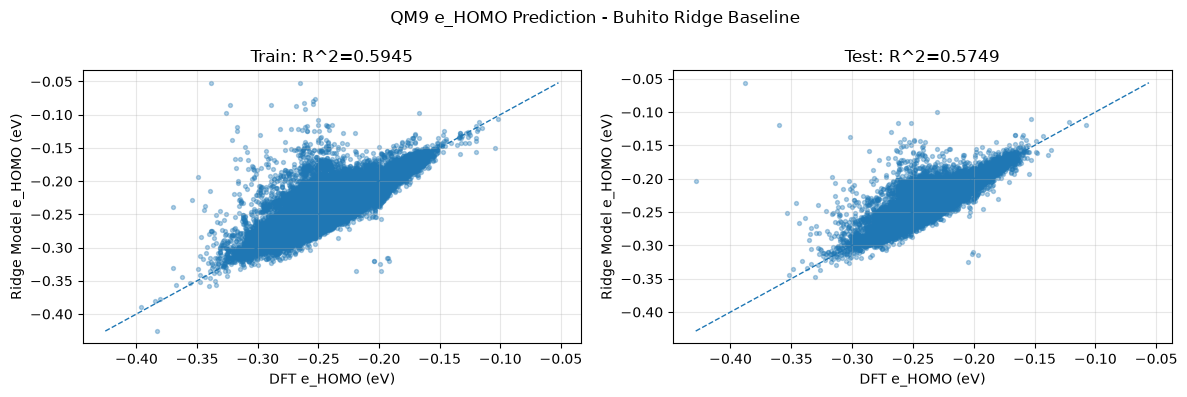


Existing hierarchical model found. Loading:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\models\buhito_hierarchical_model.pkl
X_train shape: (104664, 5370)
hmodel.coef_ shape: (5370,)

Existing prediction CSV found. Loading:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\csv\buhito_e_homo_predictions.csv

Existing coefficient CSV found. Loading:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\csv\buhito_e_homo_coefficients.csv
BUHITO HIERARCHICAL MODEL PERFORMANCE
R^2 Score:
  Train: 0.5977
  Test:  0.5703

Mean Absolute Error (MAE):
  Train: 0.01 eV
  Test:  0.01 eV

Root Mean Squared Error (RMSE):
  Train: 0.01 eV
  Test:  0.01 eV


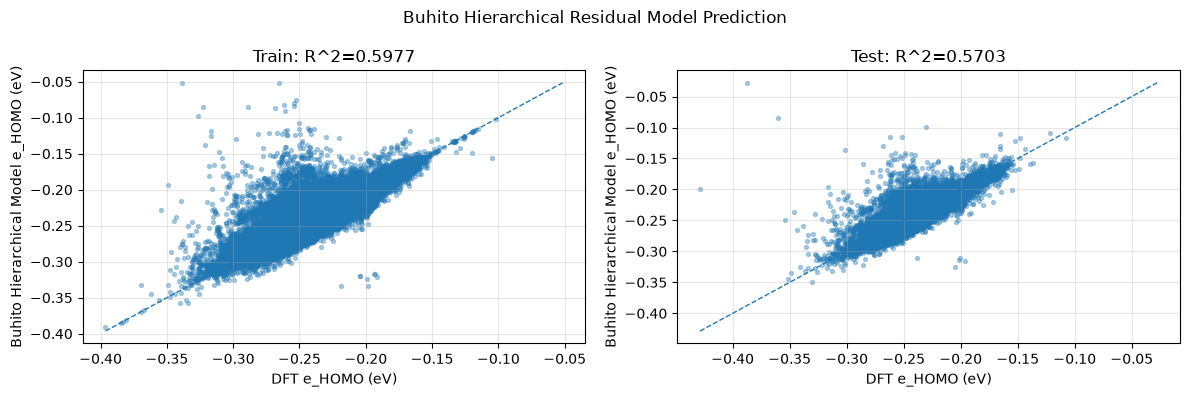

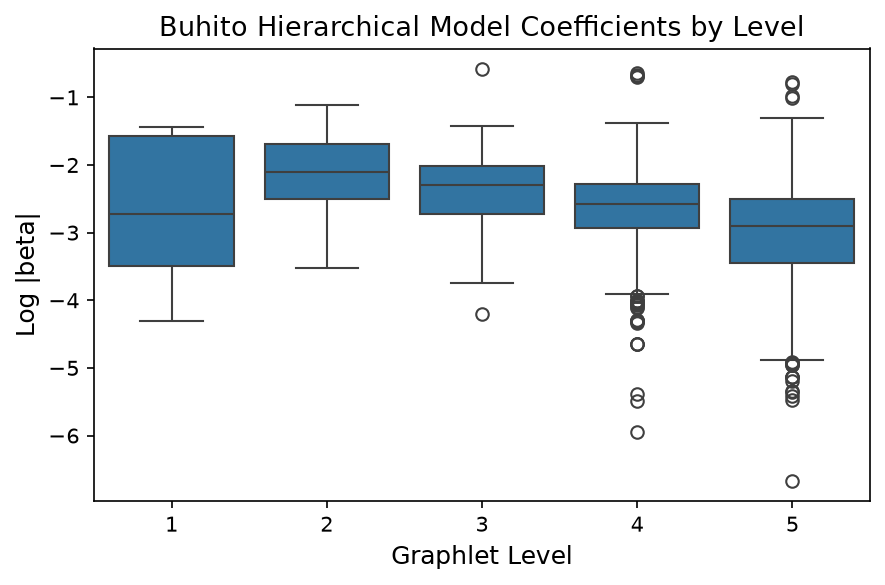


Existing model metadata found. Keeping:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\models\buhito_e_homo_metadata.pkl
Created Buhito DAG for CC: 8 atoms, 7 bonds
Created Buhito DAG for C=C: 6 atoms, 5 bonds
Created Buhito DAG for C#C: 4 atoms, 3 bonds


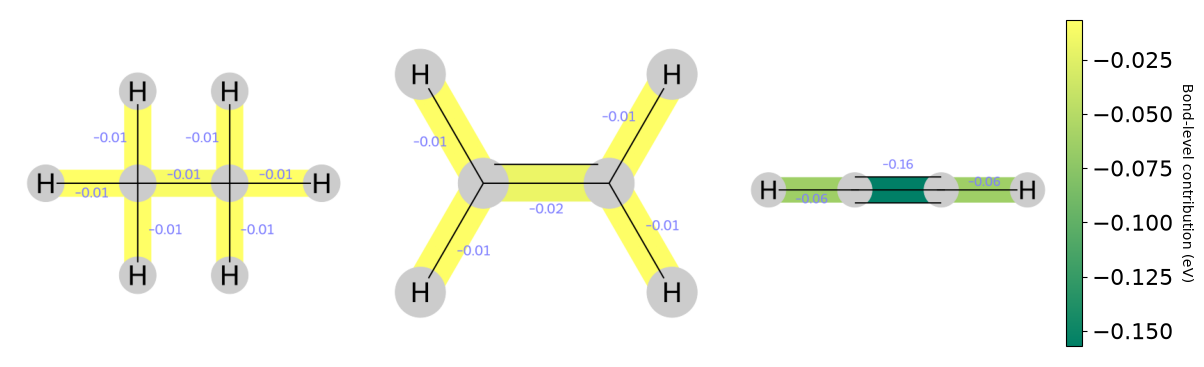

Verification that Buhito DAG projections match model predictions:
  CC    : Model=  -0.052, DAG=  -0.052, Diff=0.000000
  C=C   : Model=  -0.050, DAG=  -0.050, Diff=0.000000
  C#C   : Model=  -0.284, DAG=  -0.284, Diff=0.000000

TRAINING COMPLETE

CSV files:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\csv\buhito_e_homo_predictions.csv
  C:\Users\statl\Documents\GitHub\buhito-interpretability\csv\buhito_e_homo_coefficients.csv
  C:\Users\statl\Documents\GitHub\buhito-interpretability\csv\buhito_e_homo_train_test_split.csv

Model files:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\models\buhito_featurizer.pkl
  C:\Users\statl\Documents\GitHub\buhito-interpretability\models\buhito_ridge_model.pkl
  C:\Users\statl\Documents\GitHub\buhito-interpretability\models\buhito_hierarchical_model.pkl
  C:\Users\statl\Documents\GitHub\buhito-interpretability\models\buhito_e_homo_metadata.pkl

Feature files:
  C:\Users\statl\Documents\GitHub\buhito-interpretability\features\

In [9]:

# =============================================================================
# BUHITO QM9 e_HOMO WORKFLOW
# Train once, save models/features/results, and reuse later
# =============================================================================

import sys
from pathlib import Path
import io
import re
import time
import contextlib
import warnings
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy import sparse

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error,
)

from rdkit import Chem

from buhito.featurizers.bfs_graphlet_featurizer import BFSGraphletFeaturizer
from buhito.transformers import GraphletTransformer
from buhito.converters import smiles_to_nx
from buhito.regressors import HierarchicalResidualModel
from buhito.graphlet_dags import GraphletDAG, draw_projected_coefs


# =============================================================================
# OUTPUT DIRECTORIES
# =============================================================================
# Existing saved artifacts are reused automatically. Missing artifacts are
# generated and saved. Delete an artifact manually if you want to rebuild it.

# Assumes this notebook/script is located in:
#
# buhito-interpretability/
#     interpretability/
#
# Therefore, the repository root is one level above the current directory.

repo_root = Path.cwd().resolve().parent

# Output folders
images_dir = repo_root / "images"
csv_dir = repo_root / "csv"
models_dir = repo_root / "models"
features_dir = repo_root / "features"

# Create folders if they do not already exist
images_dir.mkdir(parents=True, exist_ok=True)
csv_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)
features_dir.mkdir(parents=True, exist_ok=True)

print("Repository root:", repo_root)
print("Images folder:", images_dir)
print("CSV folder:", csv_dir)
print("Models folder:", models_dir)
print("Features folder:", features_dir)


# =============================================================================
# CACHE / REUSE HELPERS
# =============================================================================
# This script is safe to rerun. Existing artifacts are loaded instead of
# regenerated. Delete an artifact if you intentionally want to rebuild it.

def load_sparse_or_dense(path):
    """Load a feature matrix saved by this workflow."""
    if sparse.issparse(path):
        return path
    return sparse.load_npz(path)


def save_feature_matrix(X, path):
    """Save sparse or dense feature matrices."""
    if sparse.issparse(X):
        sparse.save_npz(path, X)
    else:
        np.savez_compressed(path, X_train=np.asarray(X))


def load_feature_matrix(path, key="X_train"):
    """Load either a sparse .npz or dense npz feature matrix."""
    try:
        return sparse.load_npz(path)
    except Exception:
        return np.load(path)[key]


BUHITO_MAX_LEN = 5


# =============================================================================
# HELPER FUNCTIONS
# =============================================================================

def parity_plot_train_test(
    X_sets,
    y_sets,
    fitted_model,
    figsize=(12, 4),
    xlab="Observed",
    ylab="Predicted",
    title="Parity plot",
    bins=None,
):
    """Local replacement for minervachem.plotting.parity_plot_train_test."""

    fig, axes = plt.subplots(
        1,
        len(X_sets),
        figsize=figsize,
        squeeze=False,
    )

    axes = axes.ravel()

    split_names = (
        ["Train", "Test"]
        if len(X_sets) == 2
        else [f"Split {i+1}" for i in range(len(X_sets))]
    )

    for ax, X, y, split_name in zip(
        axes,
        X_sets,
        y_sets,
        split_names,
    ):
        pred = fitted_model.predict(X)

        lo = float(min(np.min(y), np.min(pred)))
        hi = float(max(np.max(y), np.max(pred)))

        ax.scatter(
            y,
            pred,
            s=8,
            alpha=0.35,
        )

        ax.plot(
            [lo, hi],
            [lo, hi],
            "--",
            linewidth=1,
        )

        ax.set_xlabel(xlab)
        ax.set_ylabel(ylab)

        ax.set_title(
            f"{split_name}: R^2={r2_score(y, pred):.4f}"
        )

        ax.grid(alpha=0.3)

    fig.suptitle(title)
    plt.tight_layout()

    return fig, axes


def smiles_to_buhito_graph(
    smiles,
    add_hs=True,
    output_2d_pos=False,
):
    result = smiles_to_nx(
        smiles,
        add_hs=add_hs,
        output_2d_pos=output_2d_pos,
    )

    return (
        result[0]
        if isinstance(result, (tuple, list))
        else result
    )


# =============================================================================
# 1. PREPROCESSING THE DATA
# =============================================================================

csv_path = Path(
    "../examples/qm9/qm9data/qm9_processed.csv"
)

print("QM9 CSV:", csv_path.resolve())

if not csv_path.exists():
    raise FileNotFoundError(
        f"Could not find QM9 CSV at:\n{csv_path.resolve()}"
    )

df = pd.read_csv(csv_path)

print("Data frame shape:", df.shape)
print("Data frame columns:", df.columns.tolist())

print("\nExample molecule:")
print(df.iloc[0])


start = time.time()

df["mol"] = df["smiles"].map(
    lambda s: Chem.AddHs(
        Chem.MolFromSmiles(s)
    )
)

df["graph"] = df["smiles"].map(
    lambda s: smiles_to_buhito_graph(
        s,
        add_hs=True,
        output_2d_pos=False,
    )
)

print(
    f"Time to create {len(df)} RDKit molecules "
    f"+ Buhito graphs: "
    f"{time.time() - start:.2f} seconds"
)


for idx in range(min(10, len(df))):

    mol = df.iloc[idx]["mol"]
    graph = df.iloc[idx]["graph"]

    assert set(map(int, graph.nodes)) == set(
        range(mol.GetNumAtoms())
    )


print(
    "Buhito graph node IDs match "
    "RDKit atom indices"
)


# Display first molecule in notebook
df["mol"].iloc[0]


# =============================================================================
# 2. FEATURE ENGINEERING WITH BUHITO GRAPHLET FINGERPRINTS
# =============================================================================

base_graphlet_featurizer = BFSGraphletFeaturizer(
    return_nodewise=False,
    max_len=BUHITO_MAX_LEN,
)

featurizer = GraphletTransformer(
    featurizer=base_graphlet_featurizer,
    verbose=0,
    n_jobs=-1,
    chunk_size="auto",
)

print("Buhito featurizer initialized")
print("Max graphlet length:", BUHITO_MAX_LEN)


# -------------------------------------------------------------------------
# Train/test split
# -------------------------------------------------------------------------

split_path = csv_dir / "buhito_e_homo_train_test_split.csv"

if split_path.exists():
    print("\nExisting train/test split found. Loading:")
    print(" ", split_path)

    split_df = pd.read_csv(split_path)

    train_smiles = split_df.loc[
        split_df["split"] == "train", "smiles"
    ].tolist()
    test_smiles = split_df.loc[
        split_df["split"] == "test", "smiles"
    ].tolist()

    df_by_smiles = df.set_index("smiles", drop=False)

    train = df_by_smiles.loc[train_smiles].reset_index(drop=True)
    test = df_by_smiles.loc[test_smiles].reset_index(drop=True)

else:
    print("\nNo saved train/test split found. Creating it...")

    train, test = train_test_split(
        df,
        train_size=0.8,
        random_state=42,
    )

    split_df = pd.concat(
        [
            train[["smiles"]].assign(split="train"),
            test[["smiles"]].assign(split="test"),
        ],
        ignore_index=True,
    )

    split_df.to_csv(split_path, index=False)

    print("Saved train/test split:")
    print(" ", split_path)

print(f"Training set: {len(train)} molecules")
print(f"Test set:     {len(test)} molecules")


# -------------------------------------------------------------------------
# Buhito graphlet features + fitted featurizer
# -------------------------------------------------------------------------

X_train_path = features_dir / "X_train_buhito.npz"
X_test_path = features_dir / "X_test_buhito.npz"
featurizer_path = models_dir / "buhito_featurizer.pkl"

if (
    X_train_path.exists()
    and X_test_path.exists()
    and featurizer_path.exists()
):
    print("\nExisting Buhito features and featurizer found. Loading...")

    with featurizer_path.open("rb") as file:
        featurizer = joblib.load(file)
    X_train = load_feature_matrix(X_train_path, key="X_train")
    X_test = load_feature_matrix(X_test_path, key="X_test")

else:
    print("\nSaved features/featurizer not found. Generating...")

    start = time.time()

    X_train = featurizer.fit_transform(
        train["graph"].tolist()
    )

    X_test = featurizer.transform(
        test["graph"].tolist()
    )

    print(
        f"Time to generate graphlet features: "
        f"{time.time() - start:.2f} seconds"
    )

    save_feature_matrix(X_train, X_train_path)

    if sparse.issparse(X_test):
        sparse.save_npz(X_test_path, X_test)
    else:
        np.savez_compressed(
            X_test_path,
            X_test=np.asarray(X_test),
        )

    joblib.dump(featurizer, featurizer_path)

    print("Saved feature matrices:")
    print(" ", X_train_path)
    print(" ", X_test_path)

    print("Saved fitted Buhito featurizer:")
    print(" ", featurizer_path)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("Fitted graphlet bits:", len(featurizer.bit_ids_))
print(
    "Max fitted bit size:",
    int(np.max(featurizer.bit_sizes_)),
)


# =============================================================================
# STABLE GRAPH LOOKUP
# =============================================================================

def _mol_lookup_key(mol):

    return Chem.MolToSmiles(
        mol,
        canonical=True,
        isomericSmiles=True,
    )


_GRAPH_BY_MOL_KEY = {
    _mol_lookup_key(mol): graph
    for mol, graph in zip(
        df["mol"],
        df["graph"],
    )
}


def graph_for_rdkit_mol(mol):

    key = _mol_lookup_key(mol)

    if key not in _GRAPH_BY_MOL_KEY:

        smiles = Chem.MolToSmiles(
            Chem.RemoveHs(mol),
            canonical=False,
        )

        graph = smiles_to_buhito_graph(
            smiles,
            add_hs=True,
            output_2d_pos=False,
        )

        if set(map(int, graph.nodes)) != set(
            range(mol.GetNumAtoms())
        ):
            raise ValueError(
                "Generated Buhito graph node IDs "
                "do not align with RDKit atom indices"
            )

        _GRAPH_BY_MOL_KEY[key] = graph

    return _GRAPH_BY_MOL_KEY[key]


def transform_rdkit_mols(mols):

    return featurizer.transform(
        [
            graph_for_rdkit_mol(mol)
            for mol in mols
        ]
    )


def make_buhito_dag(
    mol,
    graph=None,
    coefficients=None,
    layerwise=True,
):
    """Build a Buhito GraphletDAG from Buhito GraphletTransformer bit-info."""

    if graph is None:
        graph = graph_for_rdkit_mol(mol)

    # Transform one graph so bi_transform_[0]
    # corresponds to this molecule.
    featurizer.transform([graph])

    if (
        not hasattr(featurizer, "bi_transform_")
        or len(featurizer.bi_transform_) != 1
    ):
        raise RuntimeError(
            "Buhito GraphletTransformer did not expose "
            "one bi_transform_ mapping"
        )

    bi = featurizer.bi_transform_[0]

    if coefficients is None:
        coefficients = partition_model.coef_

    return GraphletDAG(
        mol=mol,
        bi=bi,
        layerwise=layerwise,
        bit_ids=list(featurizer.bit_ids_),
        coef=np.asarray(
            coefficients,
            dtype=float,
        ).reshape(-1),
    )


# =============================================================================
# 3. RIDGE REGRESSION BASELINE
# =============================================================================

y_train = train["e_homo"].values
y_test = test["e_homo"].values

print(
    "Target variable: e_homo "
    "(Highest Occupied Molecular Orbital Energy)"
)

print(
    f"  Train range: "
    f"[{y_train.min():.2f}, {y_train.max():.2f}] eV"
)

print(
    f"  Test range:  "
    f"[{y_test.min():.2f}, {y_test.max():.2f}] eV"
)


model = Ridge(
    fit_intercept=False,
    alpha=1e-5,
    solver="sparse_cg",
    tol=1e-5,
)

ridge_model_path = models_dir / "buhito_ridge_model.pkl"

if ridge_model_path.exists():
    print("\nExisting Ridge model found. Loading:")
    print(" ", ridge_model_path)
    model = joblib.load(ridge_model_path)
else:
    print("\nNo saved Ridge model found. Training...")

    start = time.time()

    model.fit(
        X_train,
        y_train,
    )

    print(
        f"Training time: "
        f"{time.time() - start:.2f} seconds"
    )

    joblib.dump(model, ridge_model_path)

    print("Saved Ridge model:")
    print(" ", ridge_model_path)


y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)


train_r2 = r2_score(
    y_train,
    y_train_pred,
)

test_r2 = r2_score(
    y_test,
    y_test_pred,
)

train_mae = mean_absolute_error(
    y_train,
    y_train_pred,
)

test_mae = mean_absolute_error(
    y_test,
    y_test_pred,
)


print("\nPerformance Metrics:")

print(
    f"  Train R^2:  {train_r2:.4f}"
)

print(
    f"  Test R^2:   {test_r2:.4f}"
)

print(
    f"  Train MAE: {train_mae:.2f} eV"
)

print(
    f"  Test MAE:  {test_mae:.2f} eV"
)



# -------------------------------------------------------------------------
# Ridge parity plot
# -------------------------------------------------------------------------

parity_plot_train_test(
    [X_train, X_test],
    [y_train, y_test],
    model,
    figsize=(12, 4),
    xlab="DFT e_HOMO (eV)",
    ylab="Ridge Model e_HOMO (eV)",
    title="QM9 e_HOMO Prediction - Buhito Ridge Baseline",
    bins=75,
)

plt.savefig(
    images_dir / "ridge_perf_buhito_e_homo.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


# =============================================================================
# 4. BUHITO HIERARCHICAL RESIDUAL MODEL
# =============================================================================

base_model = Ridge(
    fit_intercept=False,
    alpha=1e-5,
    solver="sparse_cg",
)

hmodel = HierarchicalResidualModel(
    regressor=base_model,
    verbose=1,
)


hmodel_path = models_dir / "buhito_hierarchical_model.pkl"

if hmodel_path.exists():
    print("\nExisting hierarchical model found. Loading:")
    print(" ", hmodel_path)
    hmodel = joblib.load(hmodel_path)
else:
    print("\nNo saved hierarchical model found. Training...")

    start = time.time()

    hmodel.fit(
        X_train,
        y_train,
        levels=np.asarray(
            featurizer.bit_sizes_
        ),
    )

    print(
        f"Training time: "
        f"{time.time() - start:.2f} seconds"
    )

    joblib.dump(hmodel, hmodel_path)

    print("Saved hierarchical model:")
    print(" ", hmodel_path)

print(
    "X_train shape:",
    X_train.shape,
)

print(
    "hmodel.coef_ shape:",
    hmodel.coef_.shape,
)

assert len(
    np.asarray(
        hmodel.coef_
    ).reshape(-1)
) == len(
    featurizer.bit_ids_
)


# -------------------------------------------------------------------------
# Put hierarchical coefficients in feature order
# -------------------------------------------------------------------------

def hierarchical_coef_in_feature_order(
    fitted_hmodel,
    levels,
):

    levels = np.asarray(levels)

    coef = np.zeros(
        levels.shape[0],
        dtype=float,
    )

    for level in fitted_hmodel.unique_levels:

        level_coef = np.asarray(
            fitted_hmodel.regressors[level].coef_,
            dtype=float,
        ).reshape(-1)

        mask = levels == level

        if int(mask.sum()) != len(level_coef):

            raise ValueError(
                f"Level {level}: "
                f"{int(mask.sum())} feature columns but "
                f"{len(level_coef)} fitted coefficients"
            )

        coef[mask] = level_coef

    return coef


class HierarchicalModelFeatureOrderView:

    """Prediction-compatible view with coef_
    aligned to Buhito feature columns.
    """

    def __init__(
        self,
        fitted_hmodel,
        levels,
    ):

        self.fitted_hmodel = fitted_hmodel

        self.coef_ = (
            hierarchical_coef_in_feature_order(
                fitted_hmodel,
                levels,
            )
        )

    def predict(self, X):

        return self.fitted_hmodel.predict(X)


partition_model = (
    HierarchicalModelFeatureOrderView(
        hmodel,
        np.asarray(
            featurizer.bit_sizes_
        ),
    )
)


if np.array_equal(
    np.asarray(featurizer.bit_sizes_),
    np.sort(
        np.asarray(
            featurizer.bit_sizes_
        )
    ),
):

    assert np.allclose(
        partition_model.coef_,
        np.asarray(
            hmodel.coef_
        ).reshape(-1),
    )


# =============================================================================
# HIERARCHICAL MODEL PREDICTIONS
# =============================================================================

y_train_pred = hmodel.predict(X_train)
y_test_pred = hmodel.predict(X_test)


# -------------------------------------------------------------------------
# NEW: Save predictions to CSV
# -------------------------------------------------------------------------

prediction_df = pd.concat(
    [
        pd.DataFrame(
            {
                "smiles": train["smiles"].values,
                "split": "train",
                "e_homo": y_train,
                "prediction": y_train_pred,
                "residual": (
                    y_train - y_train_pred
                ),
            }
        ),

        pd.DataFrame(
            {
                "smiles": test["smiles"].values,
                "split": "test",
                "e_homo": y_test,
                "prediction": y_test_pred,
                "residual": (
                    y_test - y_test_pred
                ),
            }
        ),
    ],
    ignore_index=True,
)


prediction_path = (
    csv_dir / "buhito_e_homo_predictions.csv"
)

if prediction_path.exists():
    print("\nExisting prediction CSV found. Loading:")
    print(" ", prediction_path)
    prediction_df = pd.read_csv(prediction_path)
else:
    prediction_df.to_csv(
        prediction_path,
        index=False,
    )
    print("\nSaved predictions:")
    print(" ", prediction_path)


# =============================================================================
# SAVE HIERARCHICAL MODEL COEFFICIENTS
# =============================================================================

coef_df = pd.DataFrame(
    {
        "bit_id": featurizer.bit_ids_,
        "graphlet_level": featurizer.bit_sizes_,
        "coefficient": partition_model.coef_,
    }
)


coef_path = (
    csv_dir / "buhito_e_homo_coefficients.csv"
)

if coef_path.exists():
    print("\nExisting coefficient CSV found. Loading:")
    print(" ", coef_path)
    coef_df = pd.read_csv(coef_path)
else:
    coef_df.to_csv(
        coef_path,
        index=False,
    )
    print("\nSaved graphlet coefficients:")
    print(" ", coef_path)



# -------------------------------------------------------------------------
# Performance metrics
# -------------------------------------------------------------------------

train_r2 = r2_score(
    y_train,
    y_train_pred,
)

test_r2 = r2_score(
    y_test,
    y_test_pred,
)

train_mae = mean_absolute_error(
    y_train,
    y_train_pred,
)

test_mae = mean_absolute_error(
    y_test,
    y_test_pred,
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        y_train_pred,
    )
)

test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_test_pred,
    )
)


print("=" * 60)
print("BUHITO HIERARCHICAL MODEL PERFORMANCE")
print("=" * 60)

print(
    f"R^2 Score:\n"
    f"  Train: {train_r2:.4f}\n"
    f"  Test:  {test_r2:.4f}"
)

print(
    f"\nMean Absolute Error (MAE):\n"
    f"  Train: {train_mae:.2f} eV\n"
    f"  Test:  {test_mae:.2f} eV"
)

print(
    f"\nRoot Mean Squared Error (RMSE):\n"
    f"  Train: {train_rmse:.2f} eV\n"
    f"  Test:  {test_rmse:.2f} eV"
)


# =============================================================================
# HIERARCHICAL MODEL PARITY PLOT
# =============================================================================

parity_plot_train_test(
    [X_train, X_test],
    [y_train, y_test],
    hmodel,
    figsize=(12, 4),
    xlab="DFT e_HOMO (eV)",
    ylab="Buhito Hierarchical Model e_HOMO (eV)",
    title="Buhito Hierarchical Residual Model Prediction",
)

plt.savefig(
    images_dir / "hmodel_perf_buhito_e_homo.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


# =============================================================================
# HIERARCHICAL MODEL COEFFICIENT PLOT
# =============================================================================

fig, ax = plt.subplots(
    figsize=(6, 4),
    dpi=150,
)

hmodel.plot_coefs()

plt.ylabel(
    "Log |beta|",
    fontsize=12,
)

plt.xlabel(
    "Graphlet Level",
    fontsize=12,
)

plt.title(
    "Buhito Hierarchical Model Coefficients by Level",
    fontsize=13,
)

plt.tight_layout()

plt.savefig(
    images_dir / "hmodel_coefs_buhito_e_homo.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


# =============================================================================
# SAVE METADATA
# =============================================================================

# This records the settings used to produce the fitted model.

metadata = {
    "target": "e_homo",
    "target_description": (
        "Highest Occupied Molecular Orbital Energy"
    ),
    "target_units": "eV",

    "buhito_max_len": BUHITO_MAX_LEN,

    "train_size": len(train),
    "test_size": len(test),

    "train_fraction": 0.8,
    "random_state": 42,

    "ridge_alpha": 1e-5,
    "fit_intercept": False,

    "n_features": int(X_train.shape[1]),

    "train_r2": float(train_r2),
    "test_r2": float(test_r2),

    "train_mae": float(train_mae),
    "test_mae": float(test_mae),

    "train_rmse": float(train_rmse),
    "test_rmse": float(test_rmse),
}


metadata_path = (
    models_dir / "buhito_e_homo_metadata.pkl"
)

if metadata_path.exists():
    print("\nExisting model metadata found. Keeping:")
    print(" ", metadata_path)
else:
    joblib.dump(
        metadata,
        metadata_path,
    )
    print("\nSaved model metadata:")
    print(" ", metadata_path)


# =============================================================================
# 5. BOND-LEVEL PROJECTIONS WITH BUHITO GRAPHLETDAG
# =============================================================================

smiles_strings = [
    "CC",
    "C=C",
    "C#C",
]

mols = [
    Chem.AddHs(
        Chem.MolFromSmiles(s)
    )
    for s in smiles_strings
]

projection_graphs = [
    smiles_to_buhito_graph(
        s,
        add_hs=True,
        output_2d_pos=False,
    )
    for s in smiles_strings
]


dags = []

for mol, graph, smiles in zip(
    mols,
    projection_graphs,
    smiles_strings,
):

    dag = make_buhito_dag(
        mol,
        graph=graph,
        coefficients=partition_model.coef_,
    )

    dags.append(dag)

    print(
        f"Created Buhito DAG for {smiles}: "
        f"{mol.GetNumAtoms()} atoms, "
        f"{mol.GetNumBonds()} bonds"
    )


draw_projected_coefs(
    dags,
    level=2,
    figsize=(12, 12),
    ncol=len(dags),
    cbar_label="Bond-level contribution (eV)",
)

plt.tight_layout()

plt.savefig(
    images_dir / "hmodel_interp_buhito_e_homo.png",
    dpi=150,
    bbox_inches="tight",
)

plt.show()


# =============================================================================
# VERIFY DAG PROJECTIONS
# =============================================================================

featurizer.n_jobs = 1
featurizer.verbose = False

model_preds = hmodel.predict(
    featurizer.transform(
        projection_graphs
    )
)

dag_preds = [
    dag.project_to_layer(1).sum()
    for dag in dags
]


print(
    "Verification that Buhito DAG projections "
    "match model predictions:"
)

for smiles, model_pred, dag_pred in zip(
    smiles_strings,
    model_preds,
    dag_preds,
):

    print(
        f"  {smiles:6s}: "
        f"Model={model_pred:8.3f}, "
        f"DAG={dag_pred:8.3f}, "
        f"Diff={abs(model_pred - dag_pred):.6f}"
    )


# =============================================================================
# FINAL OUTPUT SUMMARY
# =============================================================================

print("\n" + "=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)

print("\nCSV files:")
print(" ", prediction_path)
print(" ", coef_path)
print(" ", split_path)

print("\nModel files:")
print(" ", featurizer_path)
print(" ", ridge_model_path)
print(" ", hmodel_path)
print(" ", metadata_path)

print("\nFeature files:")
print(" ", X_train_path)
print(" ", X_test_path)

print("\nImage files are saved to:")
print(" ", images_dir)

## Reading the partition-score plots

The score uses **absolute values of aggregated partition terms**:
W = Σ|F_p|, B = Σ|F_{p,q}|, and H = Σ|F_S| over terms spanning three or more partitions.
The fractions w, b, h use the denominator W + B + H + 1e-10.
Raw = clip((w − 0.5b − 2h + 2)/3, 0, 1).
Adjusted = clip(Raw − λP, 0, 1), where P penalizes disconnected components within partitions.
Signed totals reconstruct the molecular prediction; they do not determine the score by themselves.
Means average individual scores after clipping. SD annotations describe spread;
the multi-molecule lambda comparison uses SEM across molecules, as labeled.
MH plots report the best partition encountered during each run, as returned by the optimizer.

The two copies of the requested 100-random-initialization section are preserved unchanged.
Updated plot outputs were cleared; rerun their cells to render the new labels.


PARTITION-BASED INTERPRETABILITY FOR QM9 MOLECULES
Using Buhito Graphlets Directly
Registered all test-set Buhito graphs with both interpreters

✓ PartitionInterpreter initialized
  Backend: Buhito
  Graphlet types: 5370
  Model coefficients: 5370
  Max graphlet size: 5
Single-atom feature count: 9
No-atom coefficients are zero: True
SELECTED MOLECULES FOR DETAILED PARTITION ANALYSIS

[Small] FC(F)(F)F
  Atoms: 5, Bonds: 4
  Predicted ΔH_at: -0.20 eV
  Actual e_homo: -0.43 eV
  Error: 0.23 eV

[Medium] O=C1NN=CN=C1
  Atoms: 10, Bonds: 10
  Predicted ΔH_at: -0.24 eV
  Actual e_homo: -0.25 eV
  Error: 0.02 eV

[Large] COC12CC1OC2CO
  Atoms: 19, Bonds: 20
  Predicted ΔH_at: -0.24 eV
  Actual e_homo: -0.24 eV
  Error: 0.01 eV

════════════════════════════════════════════════════════════════════════════════
PARTITION COMPARISON: BASELINES vs GREEDY VARIANTS
════════════════════════════════════════════════════════════════════════════════

Strategies tested:
  1. Distance baseline (graph dist

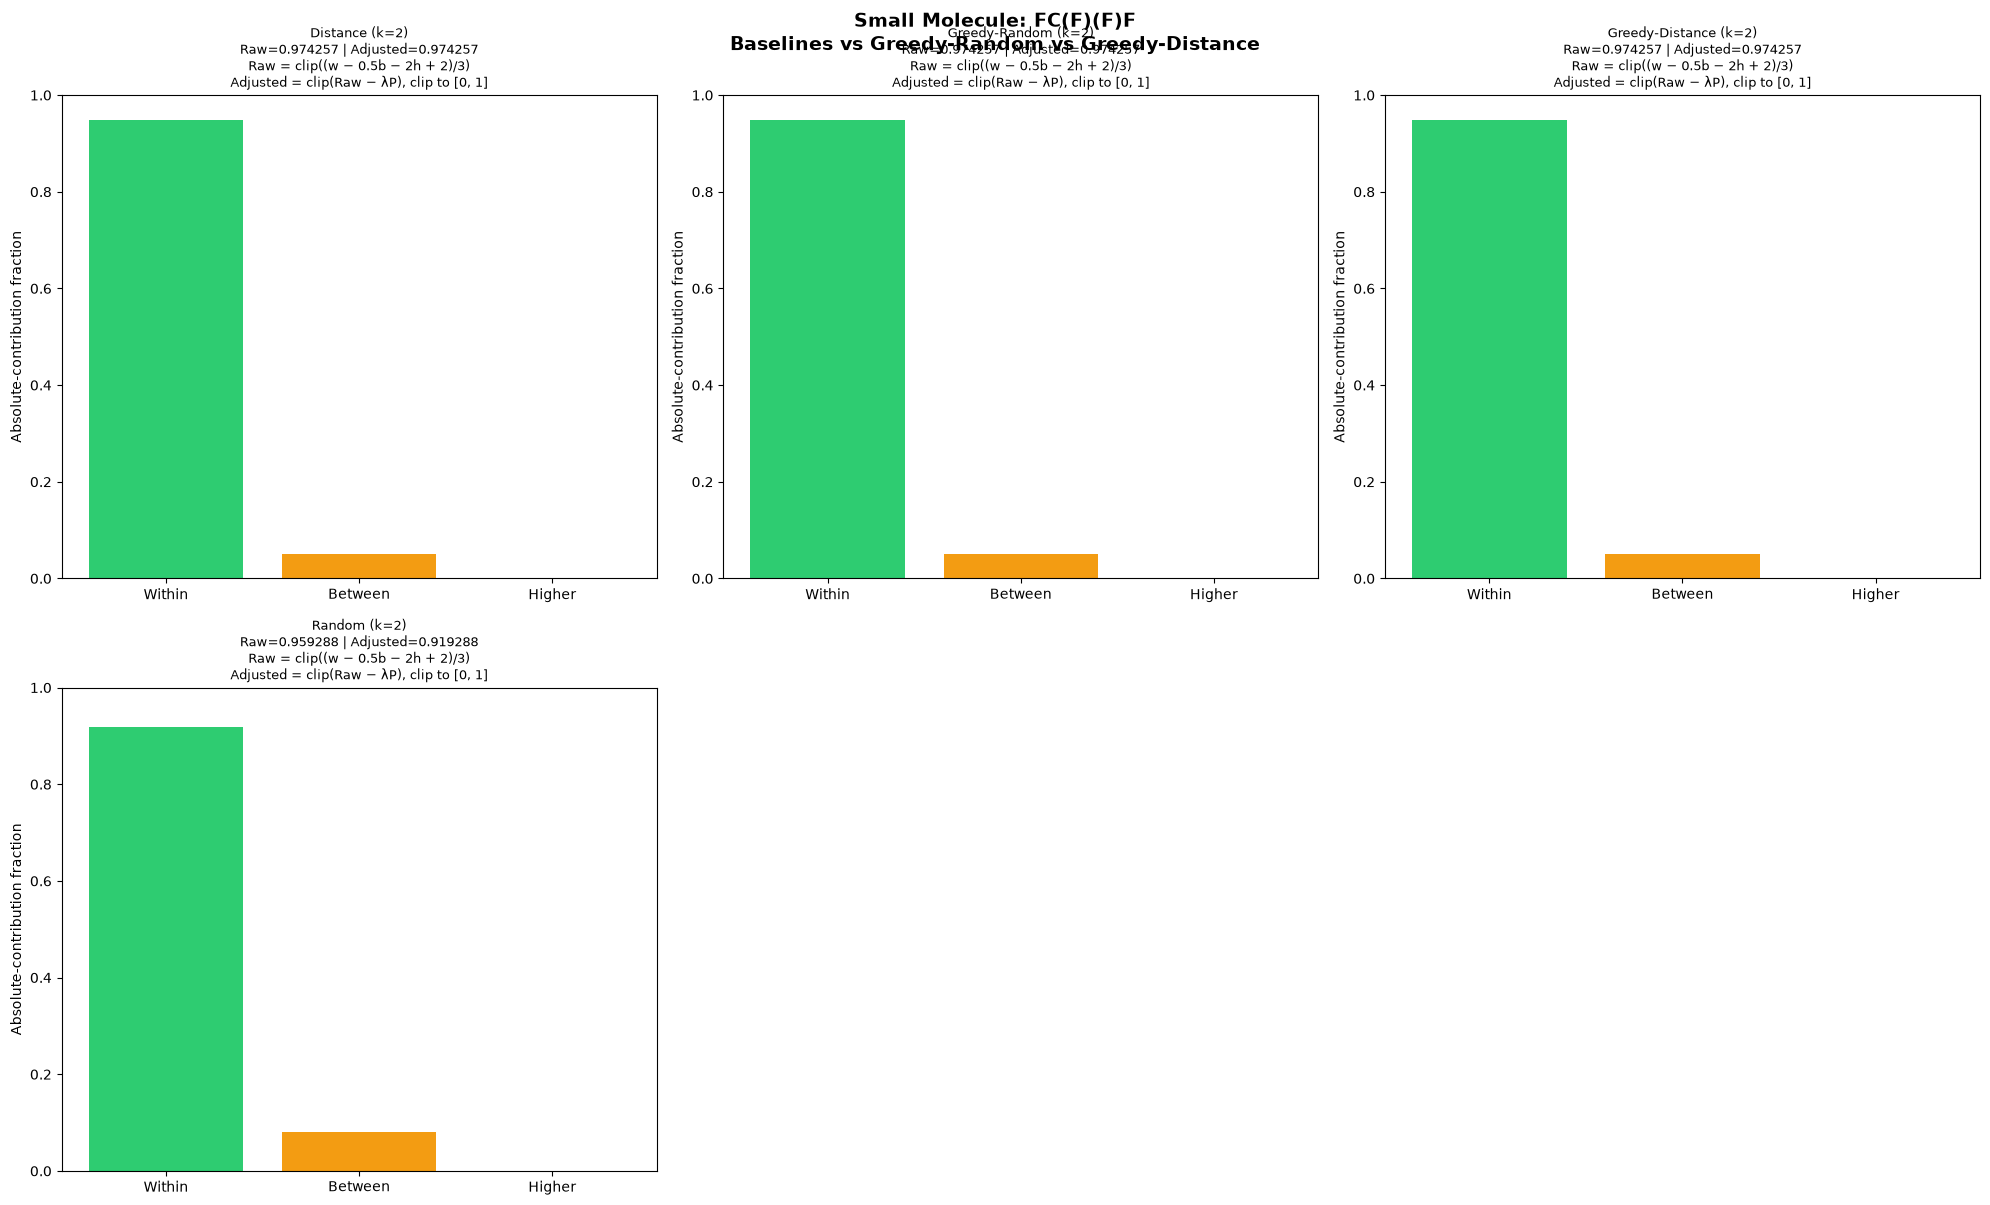


✓ Partition compariso displayed

ANALYZING Medium MOLECULE: O=C1NN=CN=C1

Comparing strategies for: O=C1NN=CN=C1
  Testing k values: [2]
  Greedy iterations: 100
  Connectivity weight: 0.100
  Distance (k=2): raw=0.9753, penalty=0.0000, adjusted=0.9753
  Random (k=2): raw=0.9435, penalty=0.4000, adjusted=0.9035
  Greedy-Random (k=2): raw=0.9784, penalty=0.0000, adjusted=0.9784
  Greedy-Distance (k=2): raw=0.9753, penalty=0.0000, adjusted=0.9753

  Top strategies by adjusted score:
    🏆 Greedy-Random (k=2)       raw=0.9784, penalty=0.0000, adjusted=0.9784
    2. Distance (k=2)            raw=0.9753, penalty=0.0000, adjusted=0.9753
    3. Greedy-Distance (k=2)     raw=0.9753, penalty=0.0000, adjusted=0.9753
    4. Random (k=2)              raw=0.9435, penalty=0.4000, adjusted=0.9035

  Greedy strategy comparison:
    Best Greedy-Random:   k=2, adjusted=0.9784
    Best Greedy-Distance: k=2, adjusted=0.9753


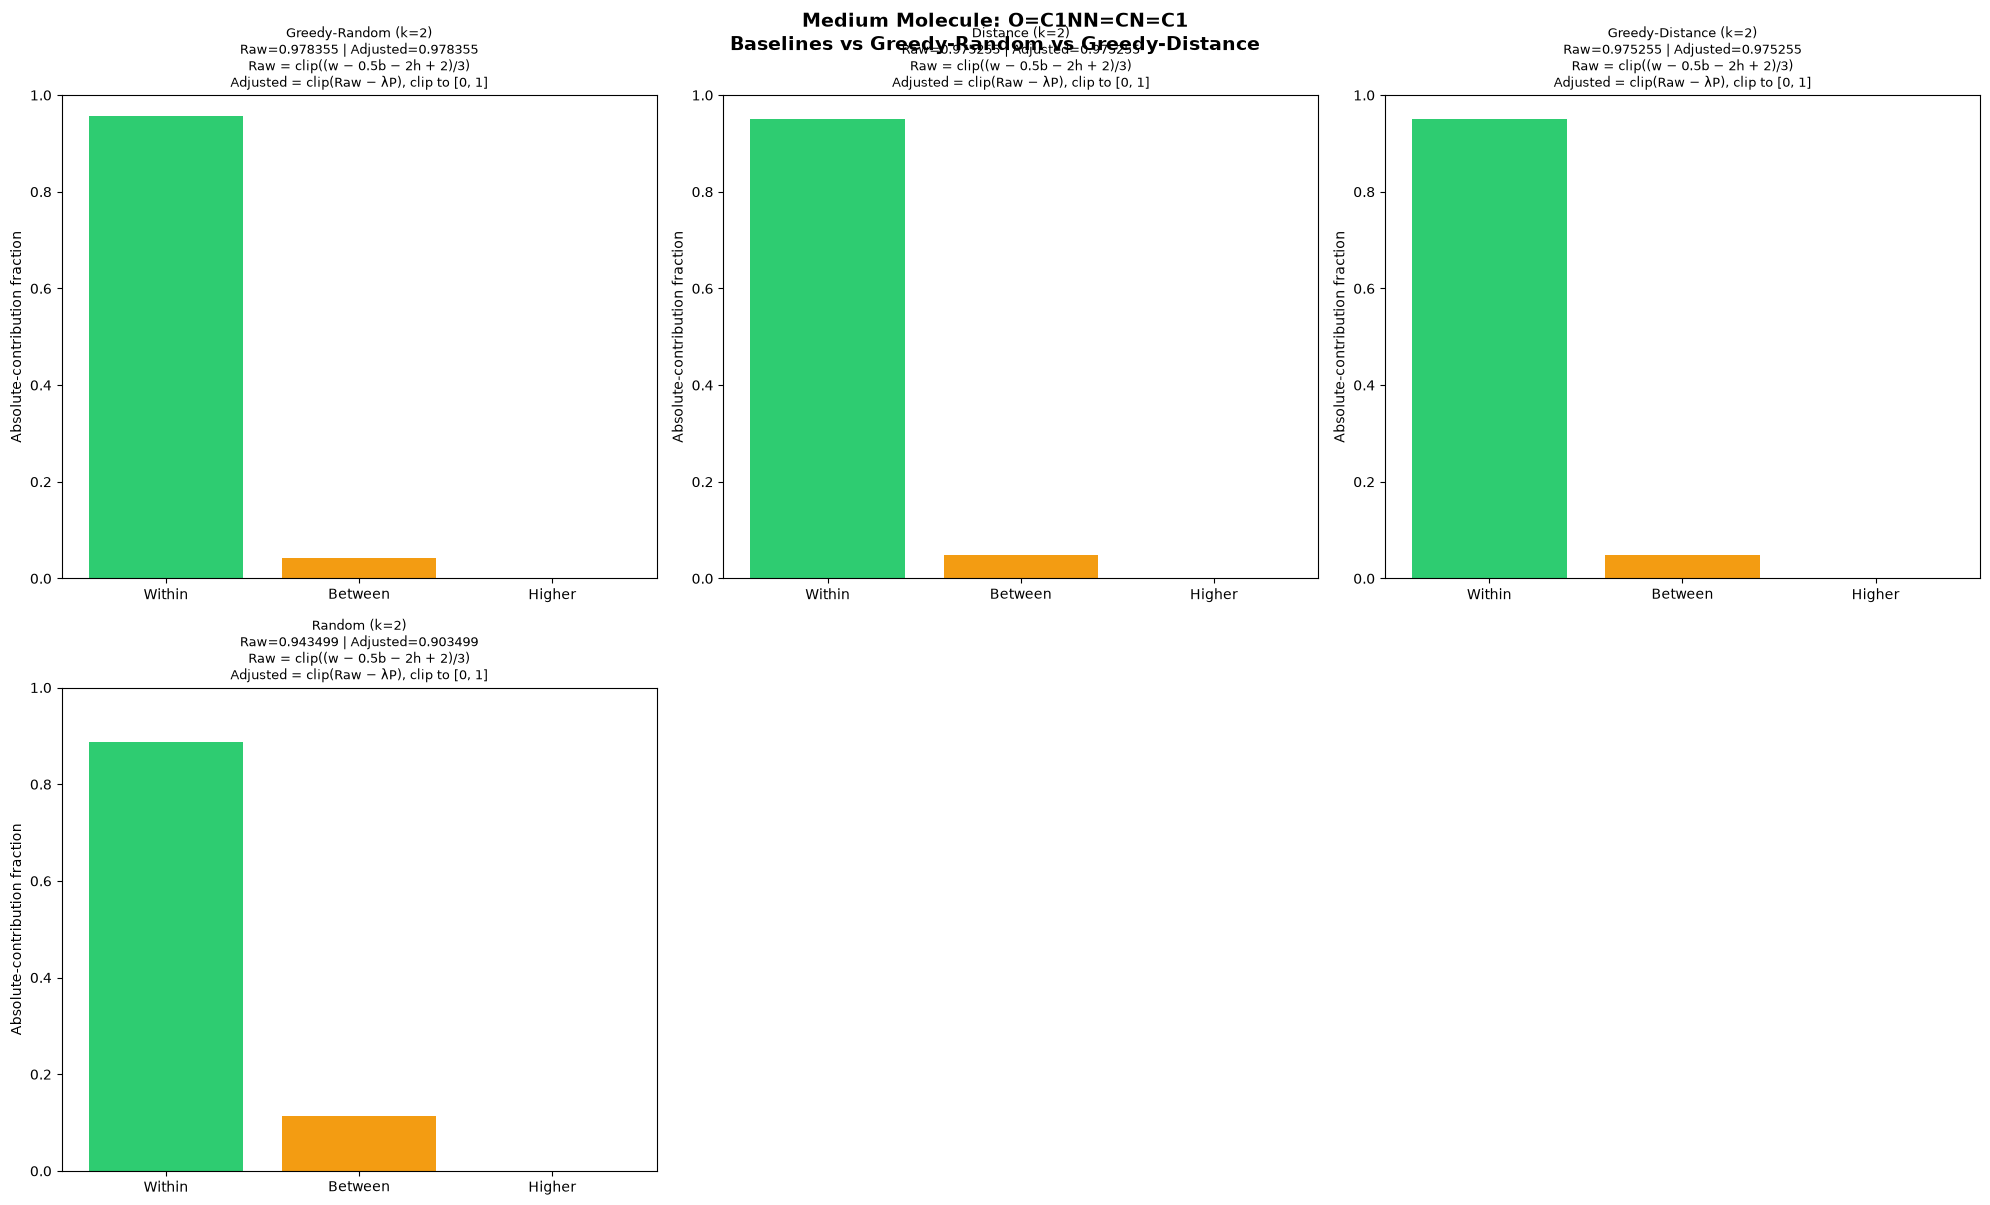


✓ Partition compariso displayed

ANALYZING Large MOLECULE: COC12CC1OC2CO

Comparing strategies for: COC12CC1OC2CO
  Testing k values: [2]
  Greedy iterations: 100
  Connectivity weight: 0.100
  Distance (k=2): raw=0.9887, penalty=0.0000, adjusted=0.9887
  Random (k=2): raw=0.9751, penalty=0.8947, adjusted=0.8856
  Greedy-Random (k=2): raw=0.9997, penalty=0.4737, adjusted=0.9524
  Greedy-Distance (k=2): raw=0.9887, penalty=0.0000, adjusted=0.9887

  Top strategies by adjusted score:
    🏆 Distance (k=2)            raw=0.9887, penalty=0.0000, adjusted=0.9887
    2. Greedy-Distance (k=2)     raw=0.9887, penalty=0.0000, adjusted=0.9887
    3. Greedy-Random (k=2)       raw=0.9997, penalty=0.4737, adjusted=0.9524
    4. Random (k=2)              raw=0.9751, penalty=0.8947, adjusted=0.8856

  Greedy strategy comparison:
    Best Greedy-Random:   k=2, adjusted=0.9524
    Best Greedy-Distance: k=2, adjusted=0.9887


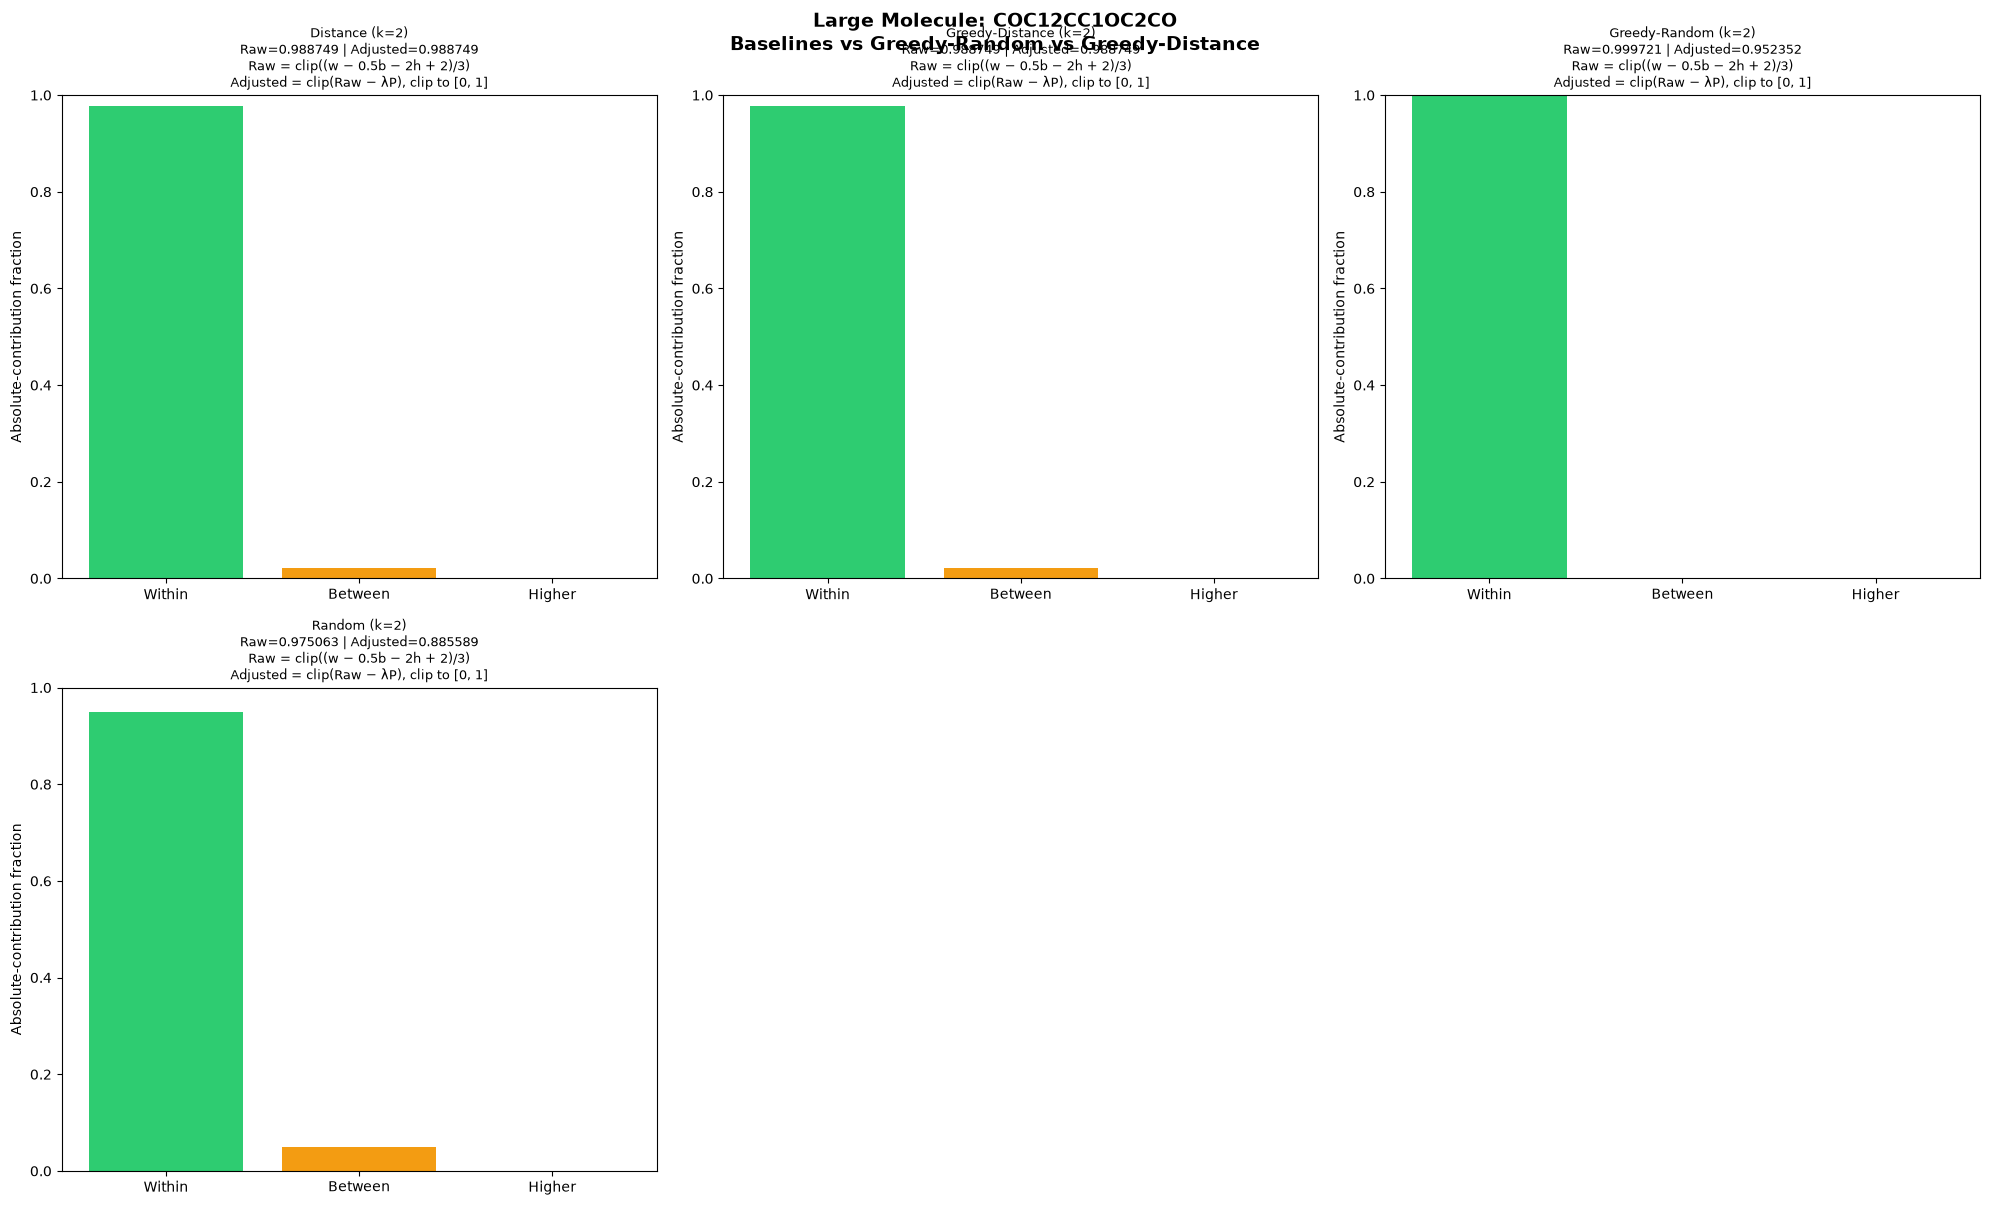


✓ Partition compariso displayed

════════════════════════════════════════════════════════════════════════════════
SUMMARY ACROSS ALL MOLECULES
════════════════════════════════════════════════════════════════════════════════

Molecule      Overall Winner  Best Raw Score  Best Adjusted Score  Connectivity Penalty
   Small      Distance (k=2)        0.974257             0.974257                   0.0
  Medium Greedy-Random (k=2)        0.978355             0.978355                   0.0
   Large      Distance (k=2)        0.988749             0.988749                   0.0

────────────────────────────────────────────────────────────────────────────────
KEY FINDINGS:
────────────────────────────────────────────────────────────────────────────────

Wins by Method:
  Distance            : 2/3 molecules
  Greedy-Random       : 1/3 molecules

Average Adjusted Scores by Method:
  Distance            : 0.9794
  Random              : 0.9028
  Greedy-Random       : 0.9683
  Greedy-Distance     :

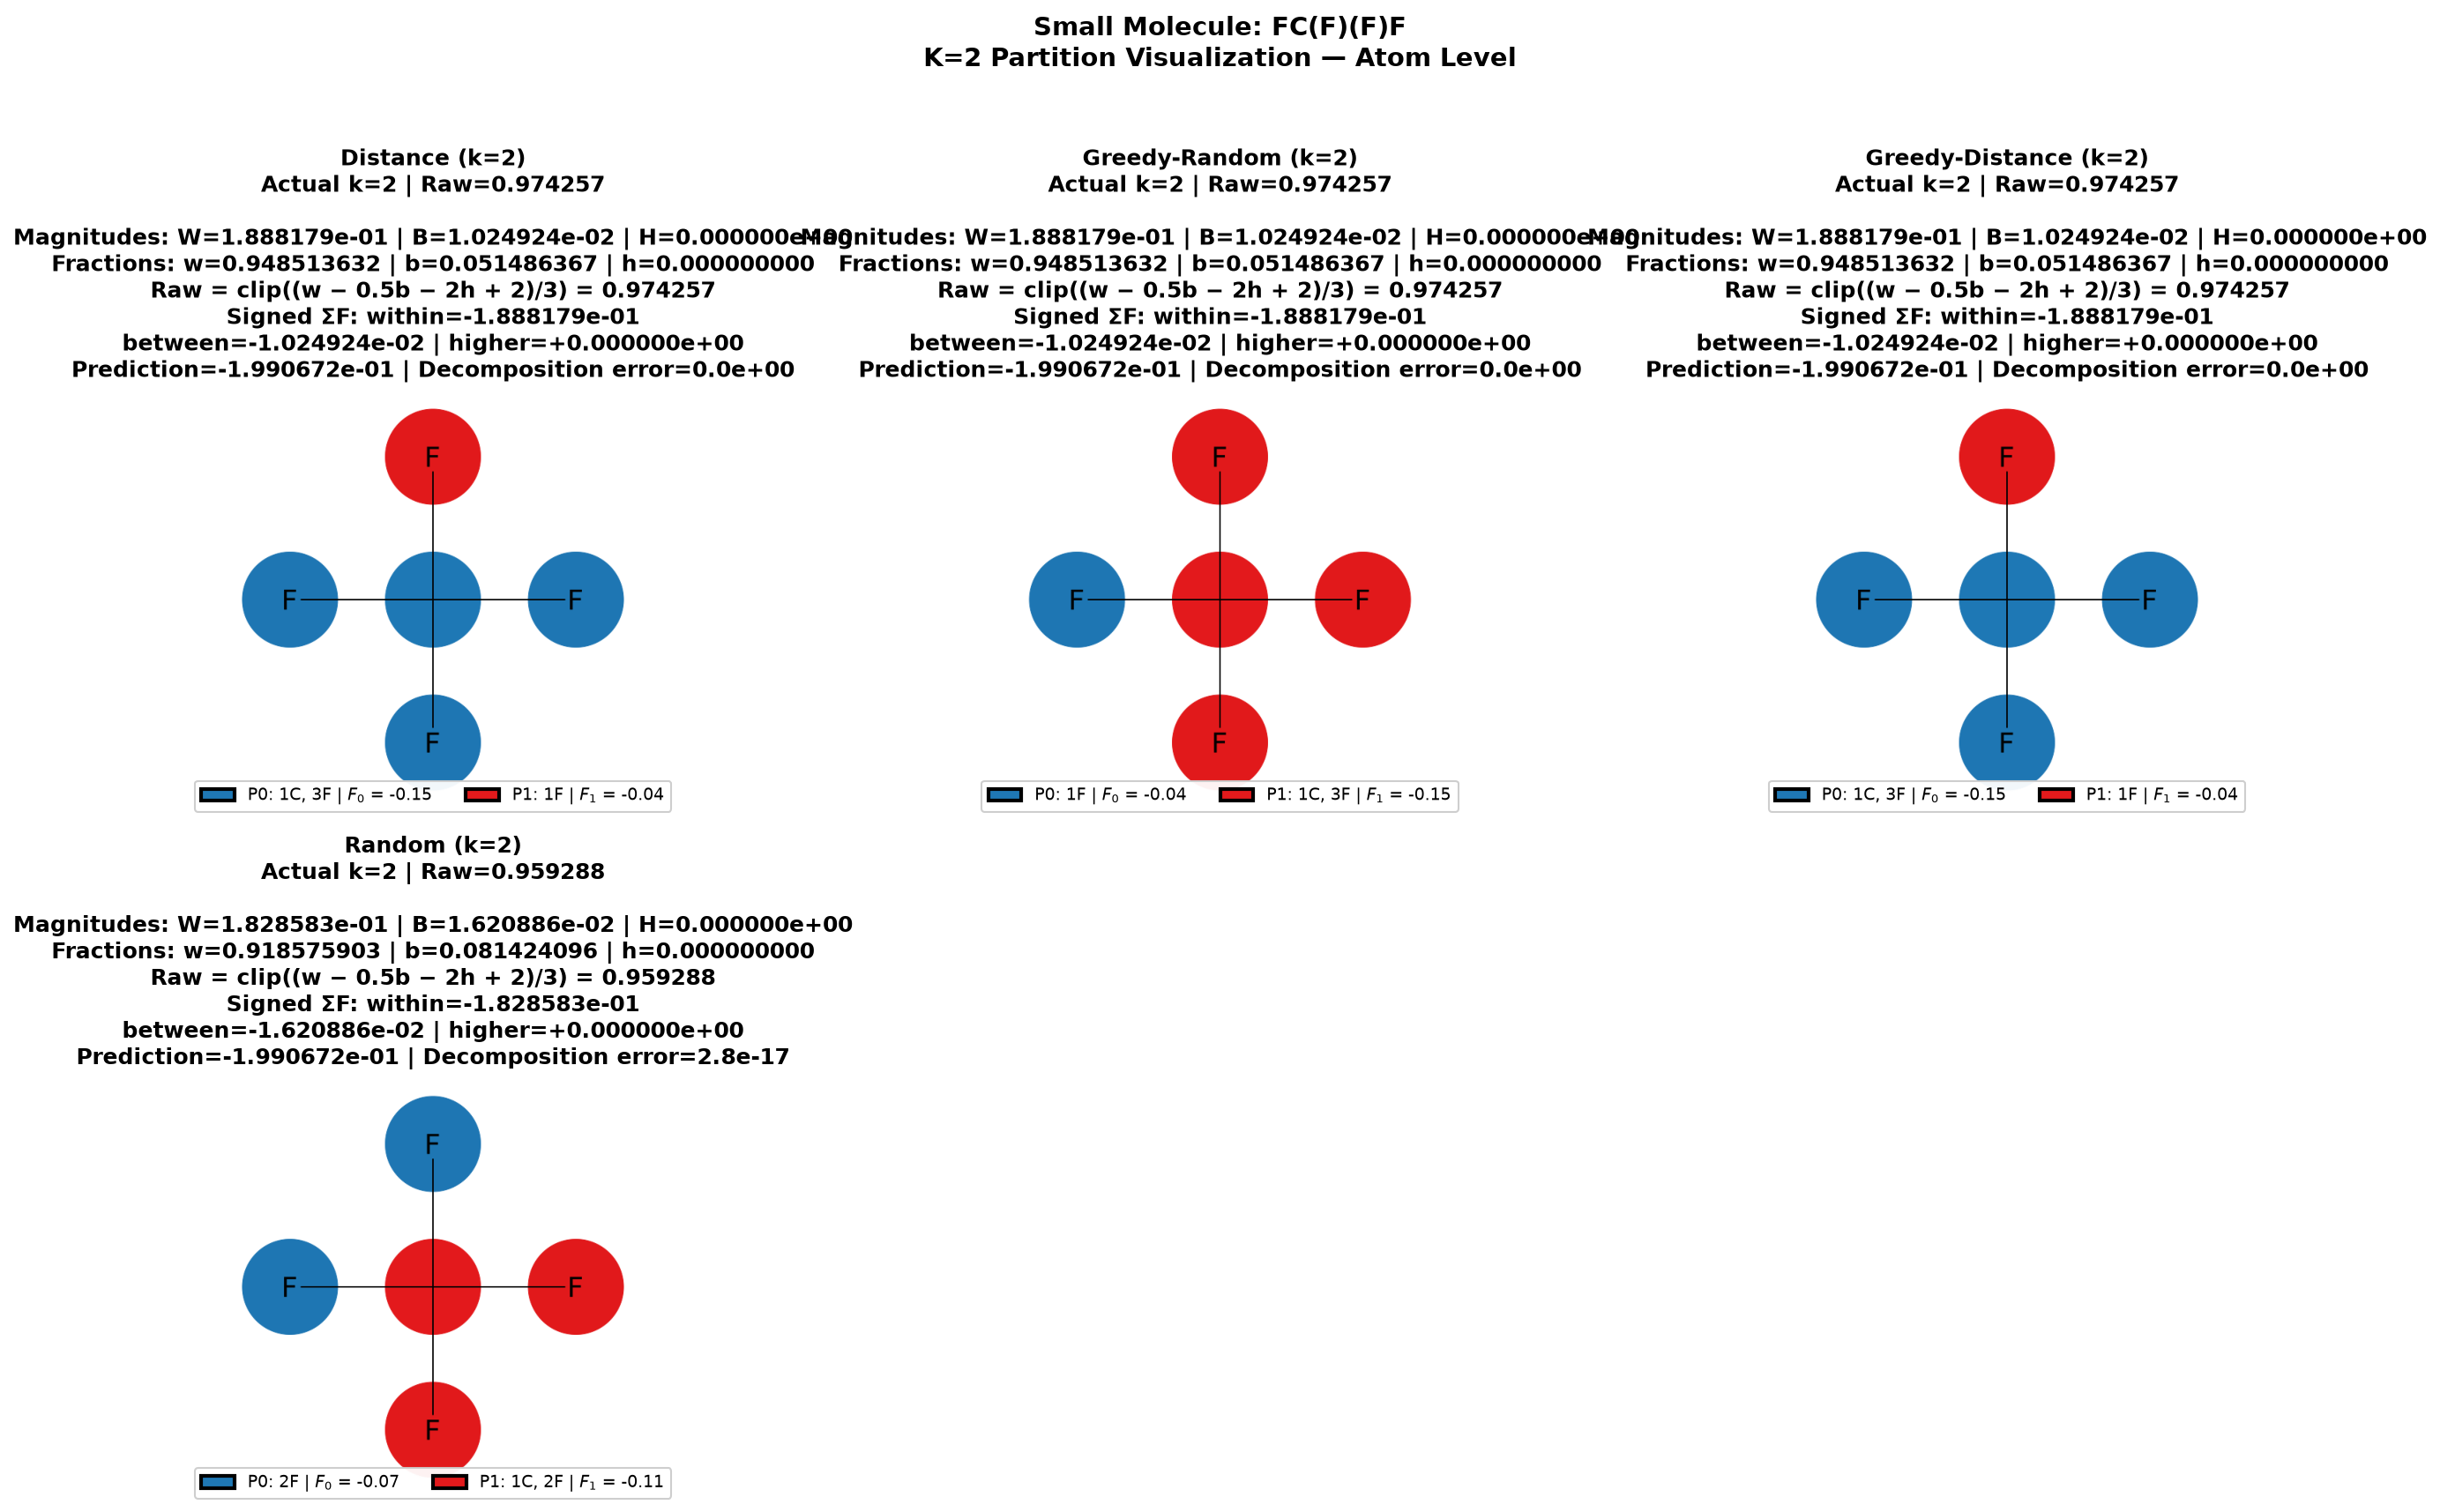

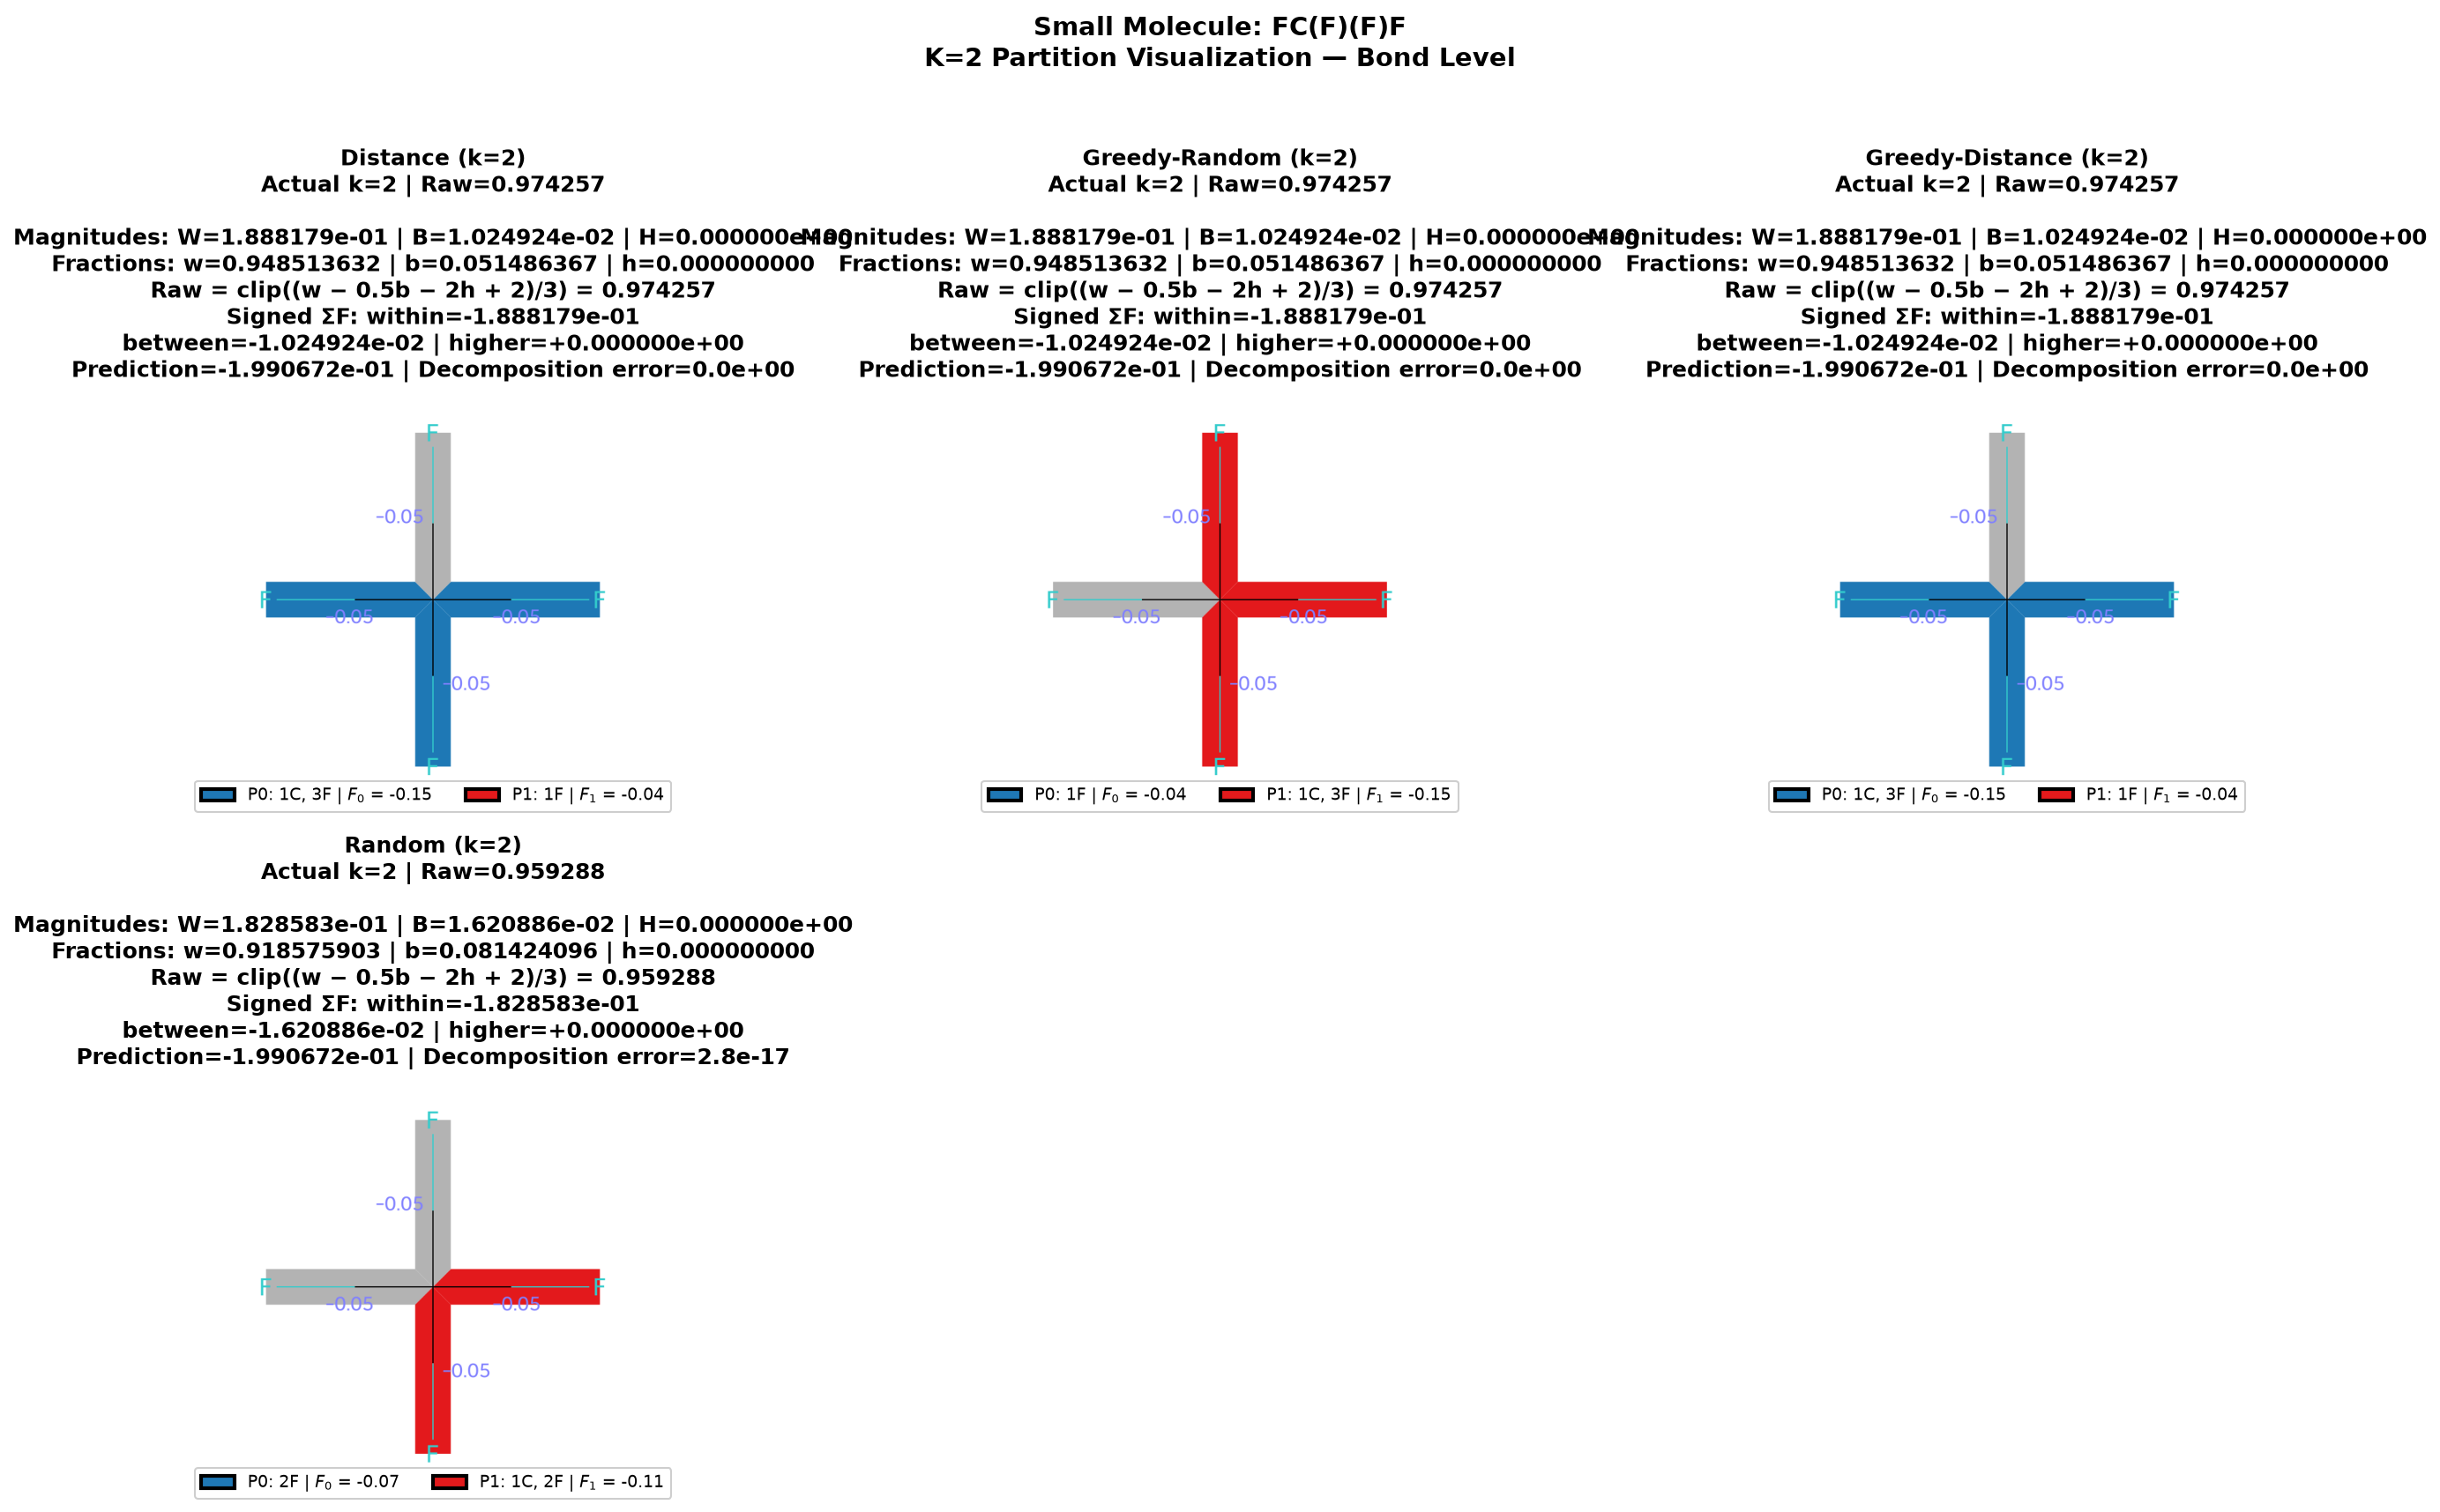


Partition details:

Distance (k=2)
Actual partitions: [0, 1]
  P0: atoms=[0, 1, 2, 4], symbols=['F', 'C', 'F', 'F'], F_0=-0.153
  P1: atoms=[3], symbols=['F'], F_1=-0.036
  Pair terms:
    F_(0, 1) = -0.010

Greedy-Random (k=2)
Actual partitions: [0, 1]
  P0: atoms=[2], symbols=['F'], F_0=-0.036
  P1: atoms=[0, 1, 3, 4], symbols=['F', 'C', 'F', 'F'], F_1=-0.153
  Pair terms:
    F_(0, 1) = -0.010

Greedy-Distance (k=2)
Actual partitions: [0, 1]
  P0: atoms=[0, 1, 2, 4], symbols=['F', 'C', 'F', 'F'], F_0=-0.153
  P1: atoms=[3], symbols=['F'], F_1=-0.036
  Pair terms:
    F_(0, 1) = -0.010

Random (k=2)
Actual partitions: [0, 1]
  P0: atoms=[2, 3], symbols=['F', 'F'], F_0=-0.072
  P1: atoms=[0, 1, 4], symbols=['F', 'C', 'F'], F_1=-0.110
  Pair terms:
    F_(0, 1) = -0.016

Medium MOLECULE: O=C1NN=CN=C1

Found 4 methods with exactly k=2 partitions


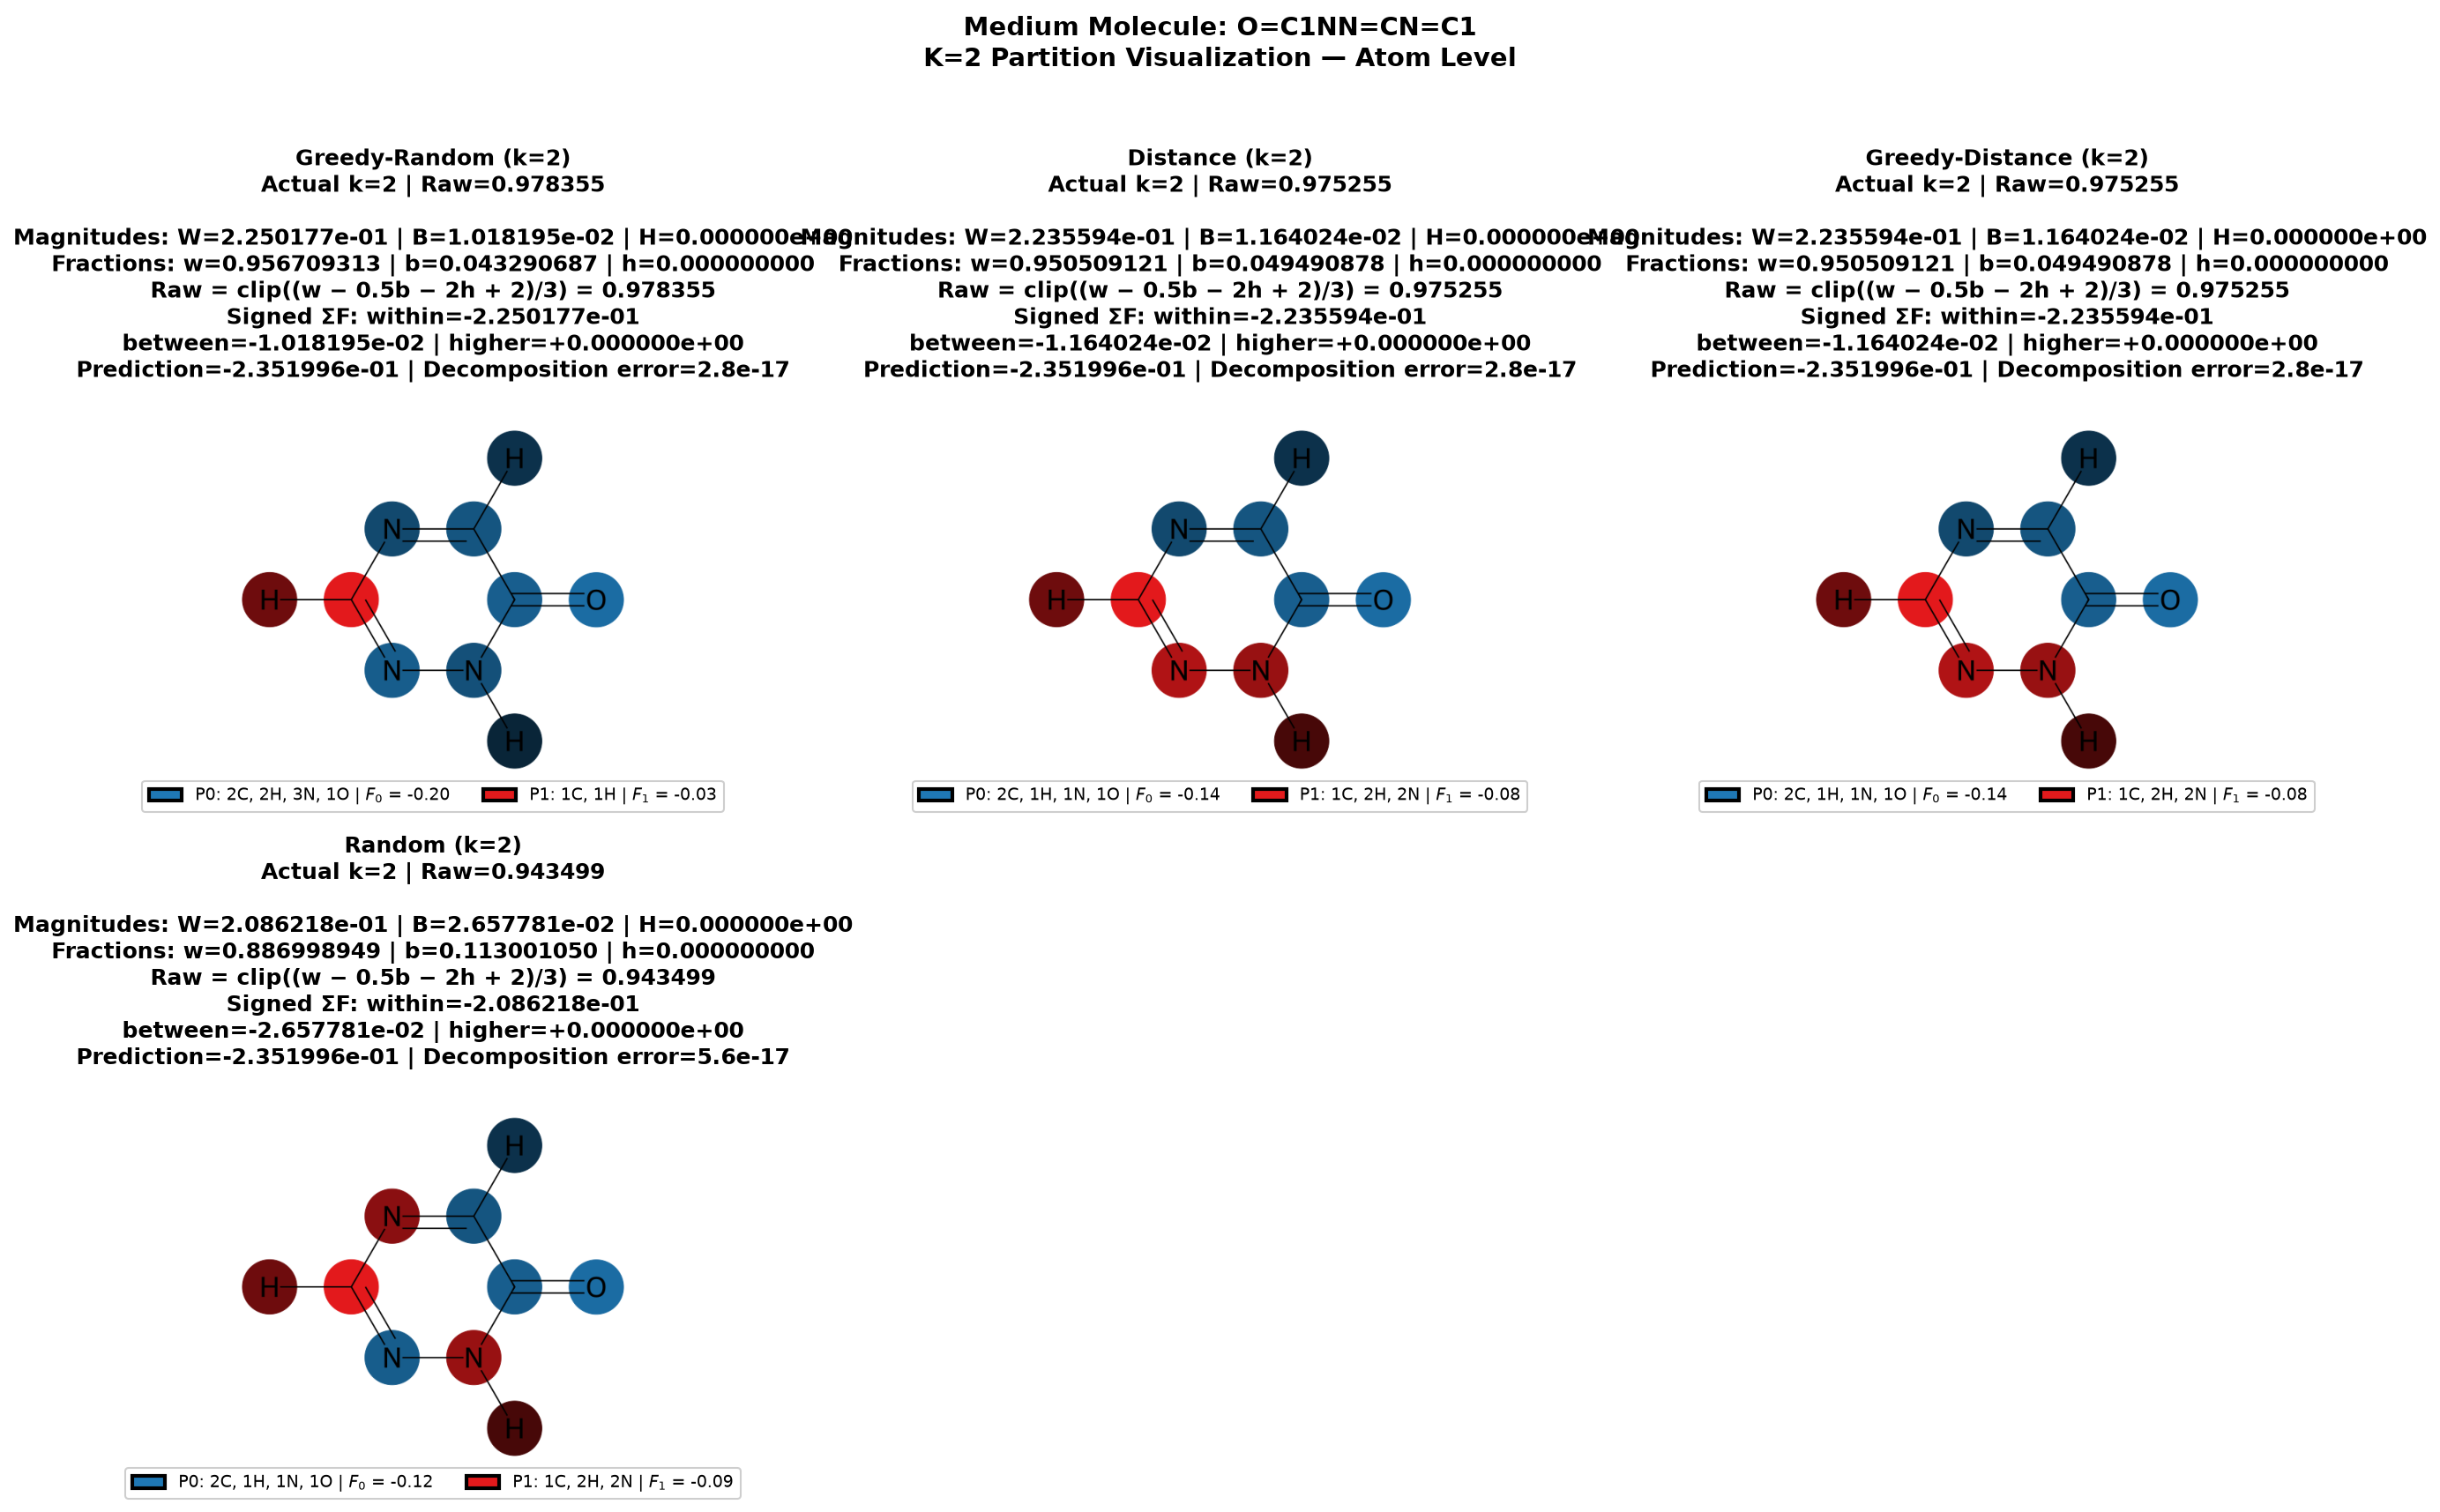

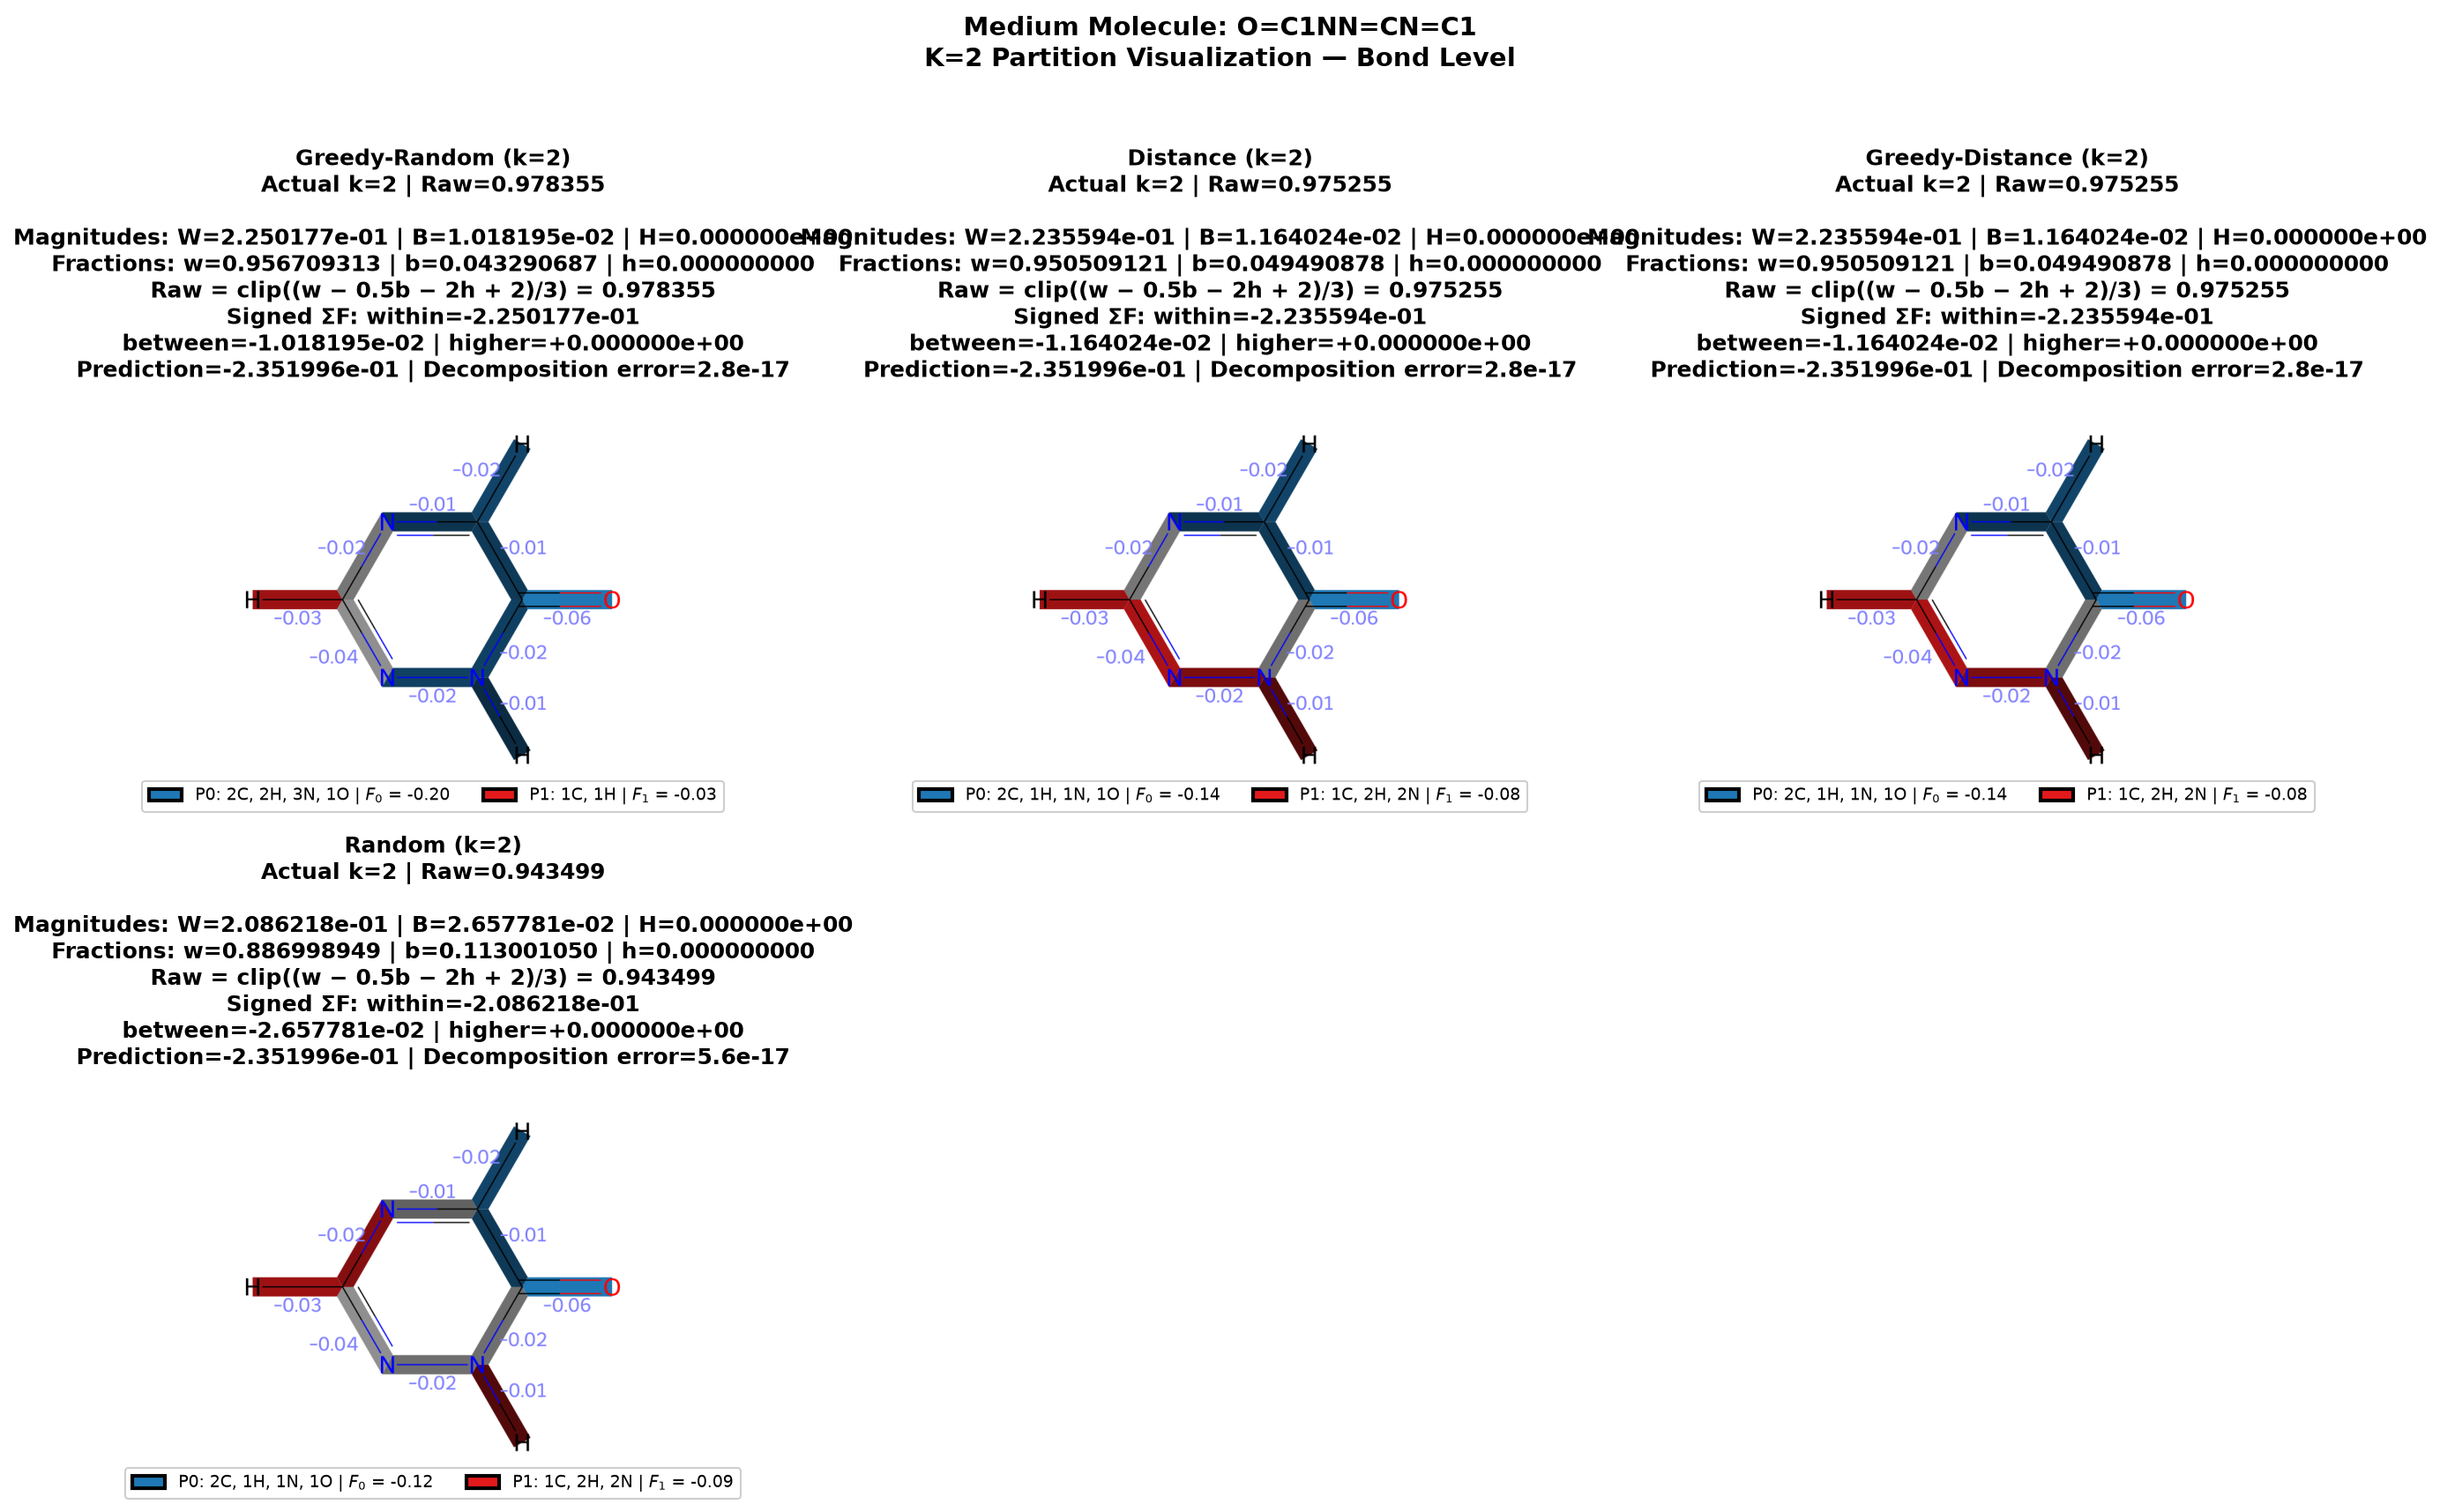


Partition details:

Greedy-Random (k=2)
Actual partitions: [0, 1]
  P0: atoms=[0, 1, 2, 3, 5, 6, 7, 9], symbols=['O', 'C', 'N', 'N', 'N', 'C', 'H', 'H'], F_0=-0.197
  P1: atoms=[4, 8], symbols=['C', 'H'], F_1=-0.028
  Pair terms:
    F_(0, 1) = -0.010

Distance (k=2)
Actual partitions: [0, 1]
  P0: atoms=[0, 1, 5, 6, 9], symbols=['O', 'C', 'N', 'C', 'H'], F_0=-0.140
  P1: atoms=[2, 3, 4, 7, 8], symbols=['N', 'N', 'C', 'H', 'H'], F_1=-0.084
  Pair terms:
    F_(0, 1) = -0.012

Greedy-Distance (k=2)
Actual partitions: [0, 1]
  P0: atoms=[0, 1, 5, 6, 9], symbols=['O', 'C', 'N', 'C', 'H'], F_0=-0.140
  P1: atoms=[2, 3, 4, 7, 8], symbols=['N', 'N', 'C', 'H', 'H'], F_1=-0.084
  Pair terms:
    F_(0, 1) = -0.012

Random (k=2)
Actual partitions: [0, 1]
  P0: atoms=[0, 1, 3, 6, 9], symbols=['O', 'C', 'N', 'C', 'H'], F_0=-0.118
  P1: atoms=[2, 4, 5, 7, 8], symbols=['N', 'C', 'N', 'H', 'H'], F_1=-0.091
  Pair terms:
    F_(0, 1) = -0.027

Large MOLECULE: COC12CC1OC2CO

Found 4 methods with exact

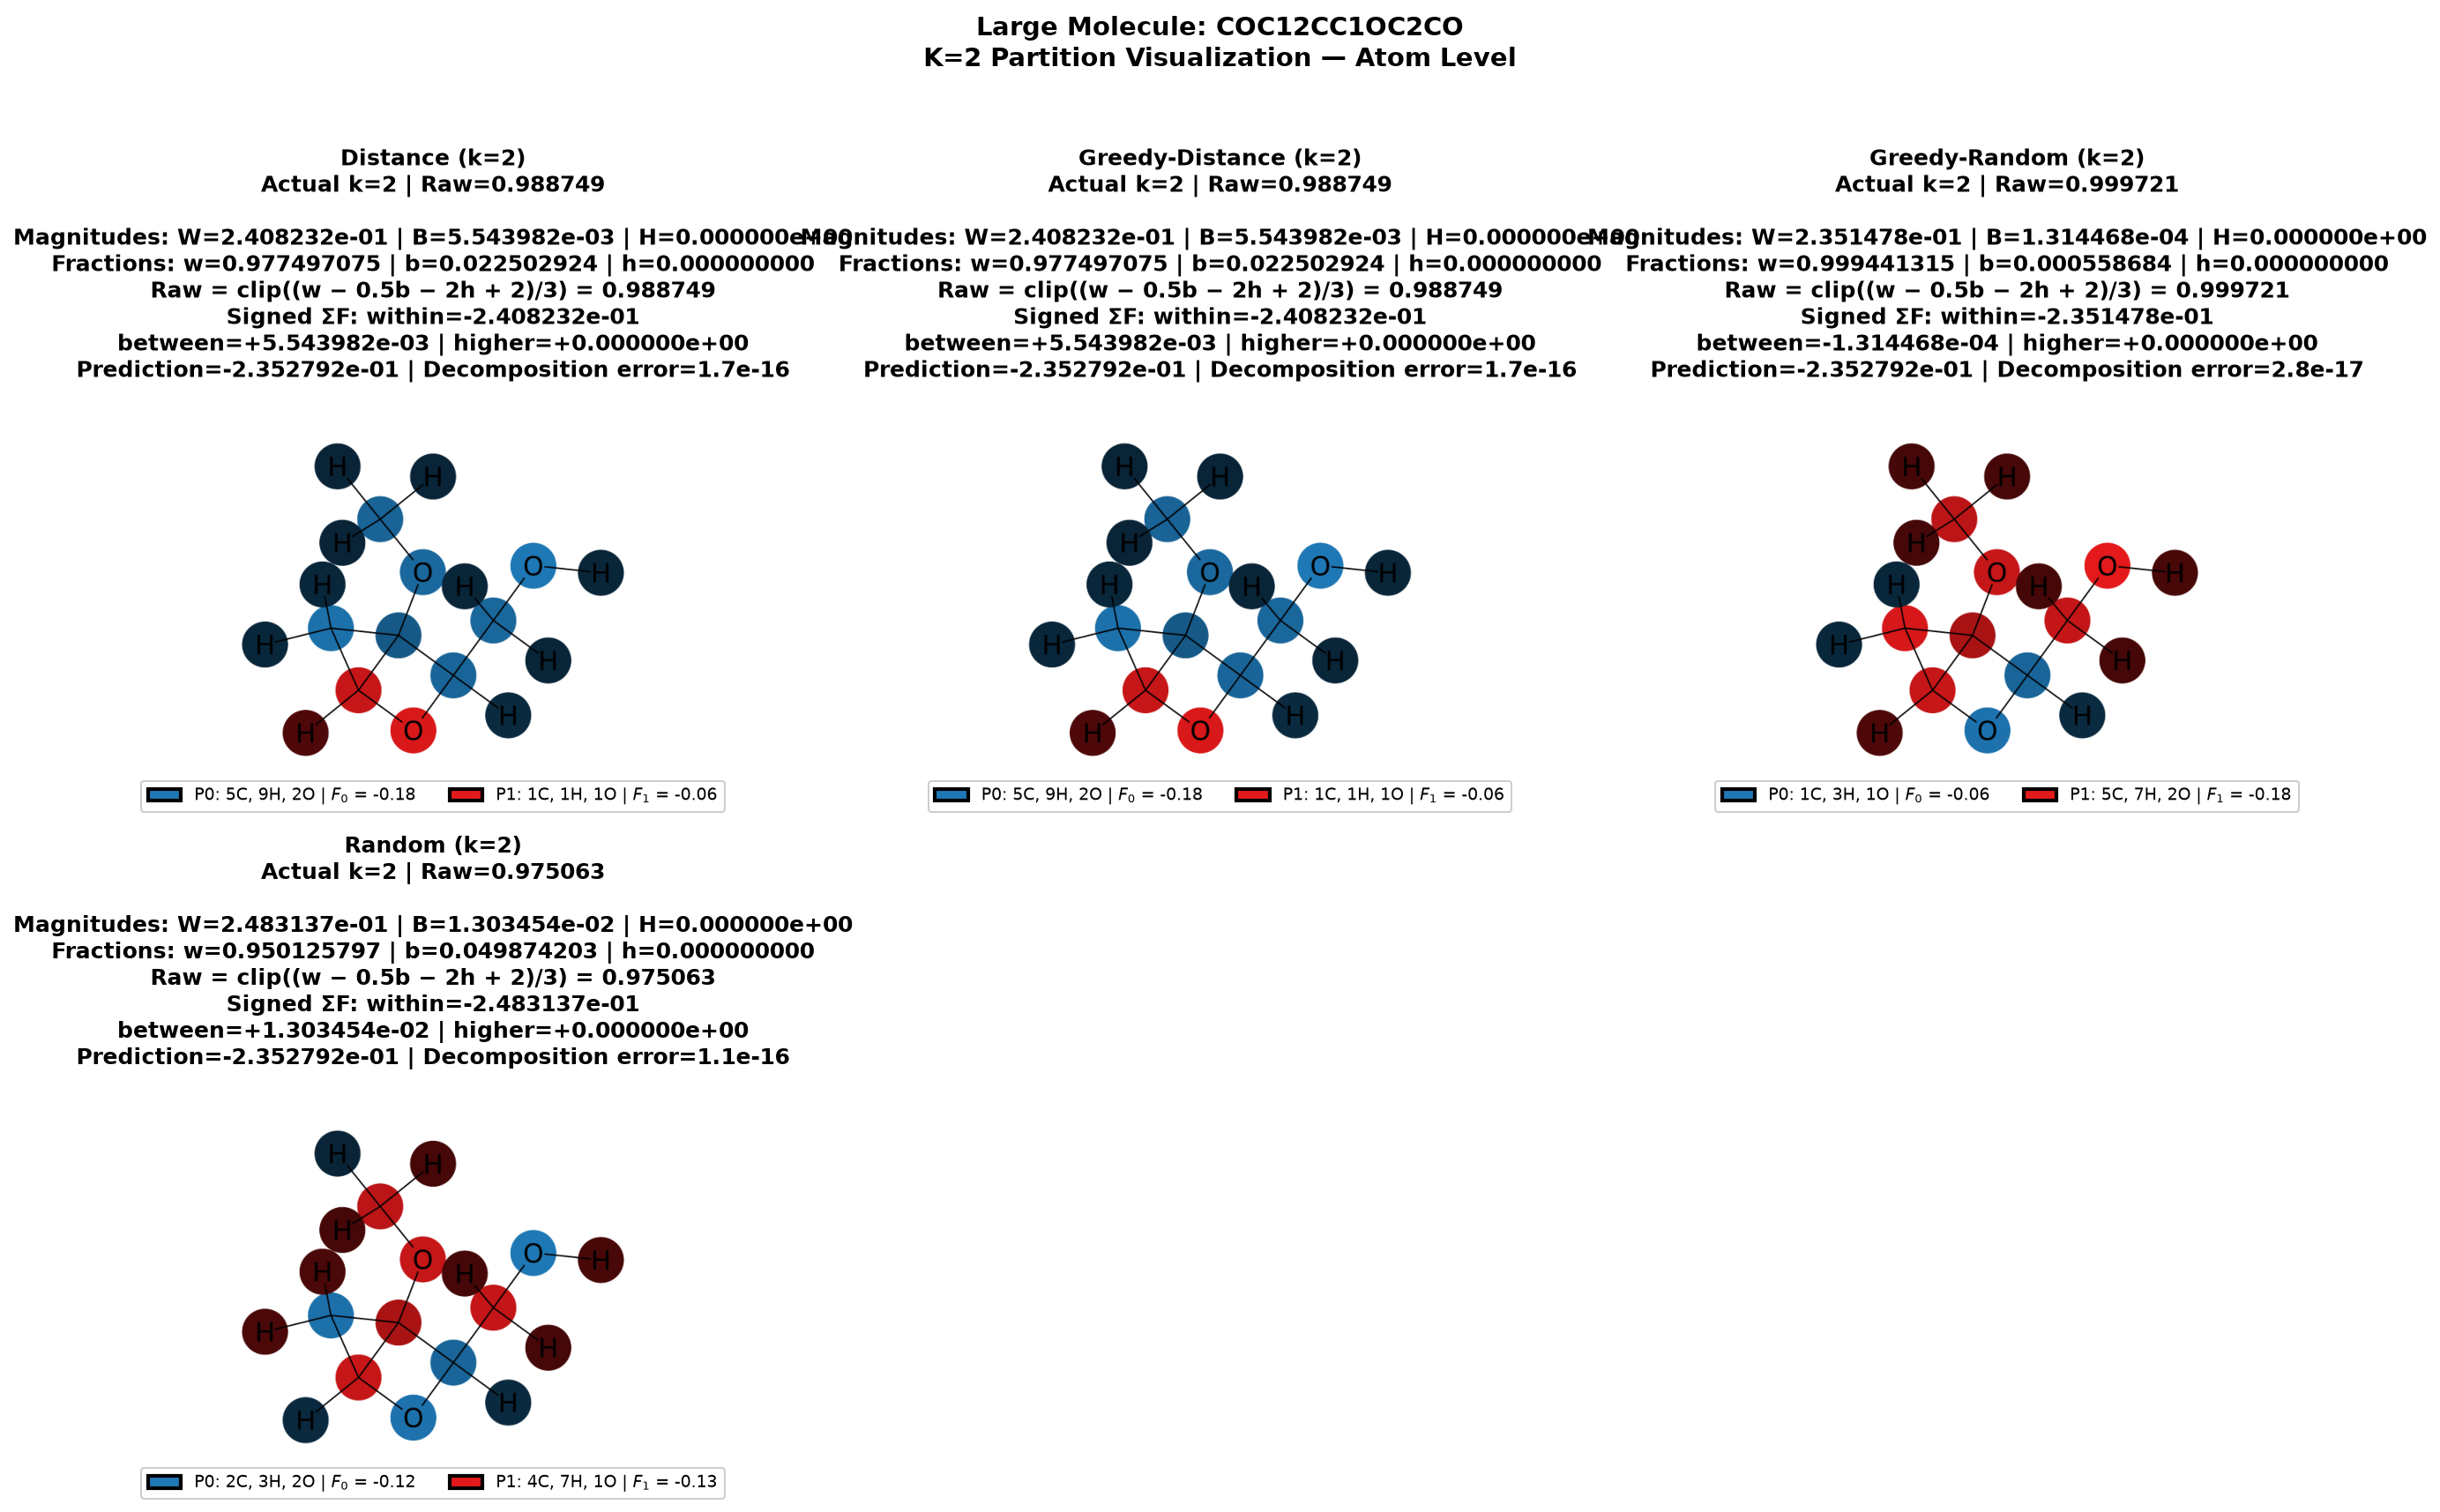

KeyboardInterrupt: 

In [10]:
# Plot annotations only: use the same aggregated terms as .score.
RAW_SCORE_SUBTITLE = "Raw = clip((w − 0.5b − 2h + 2)/3)"
ADJUSTED_SCORE_SUBTITLE = "Adjusted = clip(Raw − λP), clip to [0, 1]"
MAGNITUDE_SUBTITLE = "Fractions of Σ|F| after aggregation into partition terms"


def partition_score_title_details(interpretation):
    """Report score inputs separately from the signed prediction totals."""
    breakdown = interpretation.get_contribution_breakdown()
    W, B, H = (breakdown[key] for key in ("within", "between", "higher"))
    w, b, h = (breakdown[key] for key in
               ("within_frac", "between_frac", "higher_frac"))
    signed_within = sum(interpretation.within_partition.values())
    signed_between = sum(interpretation.between_partition.values())
    signed_higher = sum(interpretation.higher_order.values())
    reconstructed = signed_within + signed_between + signed_higher
    error = abs(reconstructed - interpretation.total_prediction)
    return (
        f"Magnitudes: W={W:.6e} | B={B:.6e} | H={H:.6e}\n"
        f"Fractions: w={w:.9f} | b={b:.9f} | h={h:.9f}\n"
        f"{RAW_SCORE_SUBTITLE} = {interpretation.score:.6f}\n"
        f"Signed ΣF: within={signed_within:+.6e}\n"
        f"between={signed_between:+.6e} | higher={signed_higher:+.6e}\n"
        f"Prediction={reconstructed:+.6e} | Decomposition error={error:.1e}"
    )


# =============================================================================
# 6. PARTITION-BASED INTERPRETABILITY
# =============================================================================

import importlib
import partition_interpretability as partition_interpretability

importlib.reload(partition_interpretability)

from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    ChemicalPartitioner,
    visualize_partition_comparison,
    partition_connectivity_penalty,
    connectivity_adjusted_score
)
print("=" * 80)
print("PARTITION-BASED INTERPRETABILITY FOR QM9 MOLECULES")
print("Using Buhito Graphlets Directly")
print("=" * 80)
interpreter_full = PartitionInterpreter(
    featurizer,
    partition_model,
    remove_single_atom_contributions=False
)

interpreter_no_atoms = PartitionInterpreter(
    featurizer,
    partition_model,
    remove_single_atom_contributions=True
)

# Main notebook mode:
interpreter = interpreter_full

# Buhito PartitionInterpreter requires each RDKit molecule to be paired with
# its already-generated NetworkX graph before decomposition.
def register_dataframe_graphs(interpreter_obj, frame):
    for mol, graph in zip(frame["mol"], frame["graph"]):
        interpreter_obj.register_graph(mol, graph)

register_dataframe_graphs(interpreter_full, test)
register_dataframe_graphs(interpreter_no_atoms, test)
print("Registered all test-set Buhito graphs with both interpreters")

print("\n✓ PartitionInterpreter initialized")
print("  Backend: Buhito")
print(f"  Graphlet types: {len(featurizer.bit_ids_)}")
print(f"  Model coefficients: {len(hmodel.coef_)}")
print(f"  Max graphlet size: {BUHITO_MAX_LEN}")
atom_indices = sorted(
    interpreter_no_atoms.atom_level_indices
)

print(
    "Single-atom feature count:",
    len(atom_indices)
)

print(
    "No-atom coefficients are zero:",
    np.allclose(
        interpreter_no_atoms.coefficients[
            atom_indices
        ],
        0.0
    )
)
test_reset = test.reset_index(drop=True)

# Select molecules of different sizes
small_idx = test_reset[test_reset['mol'].apply(lambda m: m.GetNumAtoms() < 8)].index[0]
medium_idx = test_reset[test_reset['mol'].apply(lambda m: 8 <= m.GetNumAtoms() < 12)].index[0]
large_idx = test_reset[test_reset['mol'].apply(lambda m: m.GetNumAtoms() >= 12)].index[0]

selected_mols = [
    (test_reset.loc[small_idx, 'mol'], test_reset.loc[small_idx, 'smiles'], 'Small'),
    (test_reset.loc[medium_idx, 'mol'], test_reset.loc[medium_idx, 'smiles'], 'Medium'),
    (test_reset.loc[large_idx, 'mol'], test_reset.loc[large_idx, 'smiles'], 'Large')
]

print("=" * 80)
print("SELECTED MOLECULES FOR DETAILED PARTITION ANALYSIS")
print("=" * 80)

for mol, smiles, size_label in selected_mols:
    print(f"\n[{size_label}] {smiles}")
    print(f"  Atoms: {mol.GetNumAtoms()}, Bonds: {mol.GetNumBonds()}")
    pred = hmodel.predict(transform_rdkit_mols([mol]))[0]
    print(f"  Predicted ΔH_at: {pred:.2f} eV")
    
    actual_idx = test_reset[test_reset['smiles'] == smiles].index
    if len(actual_idx) > 0:
        actual = test_reset.loc[actual_idx[0], 'e_homo']
        print(f"  Actual e_homo: {actual:.2f} eV")
        print(f"  Error: {abs(pred - actual):.2f} eV")
### Compare Partitioning Strategies

# Test different ways to partition molecules:
# 1. **Functional Groups** - Chemistry-aware (e.g., C=O, NH₂)
# 2. **Distance-based** - Clustering by graph distance
# 3. **Random** - Baseline control

# **Goal:** Find which strategy minimizes higher-order interactions (maximizes interpretability score)
from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    ChemicalPartitioner,
    visualize_partition_comparison
)

from typing import Dict
import matplotlib.pyplot as plt


def compare_with_greedy(
    mol,
    interpreter,
    smiles="",
    k_values=(2, 3, 4),
    greedy_iters=100,
    connectivity_weight=0.10,
    disconnected_singleton_weight=2.0,
    verbose=True
):
    """
    Compare baseline and optimized partition methods using both:

    1. Raw graphlet interpretability score
    2. Connectivity-adjusted score

    adjusted_score =
        raw_score
        - connectivity_weight * connectivity_penalty
    """
    
    if verbose and smiles:
        print(f"\nComparing strategies for: {smiles}")
        print(f"  Testing k values: {list(k_values)}")
        print(f"  Greedy iterations: {greedy_iters}")
        print(
            f"  Connectivity weight: "
            f"{connectivity_weight:.3f}"
        )

    results = []

    def store_result(
        strategy,
        method,
        k,
        interpretation
    ):
        """Compute and store all metrics for one partition result."""

        partition = interpretation.partition
        breakdown = interpretation.get_contribution_breakdown()

        connectivity_penalty = partition_connectivity_penalty(
            mol=mol,
            partition=partition,
            disconnected_singleton_weight=(
                disconnected_singleton_weight
            )
        )

        adjusted_score = connectivity_adjusted_score(
            mol=mol,
            interpretation=interpretation,
            connectivity_weight=connectivity_weight,
            disconnected_singleton_weight=(
                disconnected_singleton_weight
            )
        )
        result = {
            "Strategy": strategy,
            "Method": method,
            "k": k,
            "N_partitions": len(
                set(partition.values())
            ),

            # Original graphlet score
            "Score": interpretation.score,

            # Connectivity terms
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,

            "Within %": 100 * breakdown["within_frac"],
            "Between %": 100 * breakdown["between_frac"],
            "Higher %": 100 * breakdown["higher_frac"],
            "Interpretation": interpretation
        }

        results.append(result)

        if verbose:
            print(
                f"  {strategy}: "
                f"raw={interpretation.score:.4f}, "
                f"penalty={connectivity_penalty:.4f}, "
                f"adjusted={adjusted_score:.4f}"
            )

    
    # =========================================================================
    # 1. DISTANCE BASELINE
    # =========================================================================

    for k in k_values:
        partition = ChemicalPartitioner.distance_partition(
            mol,
            n_clusters=k,
            seed=42
        )

        interpretation = (
            interpreter.compute_partition_contributions(
                mol,
                partition
            )
        )

        store_result(
            strategy=f"Distance (k={k})",
            method="Distance",
            k=k,
            interpretation=interpretation
        )

    # =========================================================================
    # 2. RANDOM BASELINE
    # =========================================================================

    for k in k_values:
        partition = ChemicalPartitioner.random_partition(
            mol,
            n_clusters=k,
            seed=42
        )

        interpretation = (
            interpreter.compute_partition_contributions(
                mol,
                partition
            )
        )

        store_result(
            strategy=f"Random (k={k})",
            method="Random",
            k=k,
            interpretation=interpretation
        )

    # =========================================================================
    # 3. GREEDY-RANDOM
    # =========================================================================

    for k in k_values:
        optimizer_k = PartitionOptimizer(
            interpreter=interpreter,
            min_partitions=k,
            max_partitions=k,
            connectivity_weight=connectivity_weight,
            disconnected_singleton_weight=(
                disconnected_singleton_weight
            )
        )

        best_interpretation = (
            optimizer_k.optimize_partition_random(
                mol=mol,
                n_iterations=greedy_iters,
                seed=42,
                verbose=False
            )
        )

        store_result(
            strategy=f"Greedy-Random (k={k})",
            method="Greedy-Random",
            k=k,
            interpretation=best_interpretation
        )

    # =========================================================================
    # 4. GREEDY-DISTANCE
    # =========================================================================

    for k in k_values:
        optimizer_k = PartitionOptimizer(
            interpreter=interpreter,
            min_partitions=k,
            max_partitions=k,
            connectivity_weight=connectivity_weight,
            disconnected_singleton_weight=(
                disconnected_singleton_weight
            )
        )

        best_interpretation = (
            optimizer_k.optimize_partition_distance(
                mol=mol,
                n_clusters=k,
                n_iterations=greedy_iters,
                seed=42,
                verbose=False
            )
        )

        store_result(
            strategy=f"Greedy-Distance (k={k})",
            method="Greedy-Distance",
            k=k,
            interpretation=best_interpretation
        )

    # =========================================================================
    # SORT BY CONNECTIVITY-ADJUSTED SCORE
    # =========================================================================

    results.sort(
        key=lambda result: result["Adjusted Score"],
        reverse=True
    )

    if verbose:
        print("\n  Top strategies by adjusted score:")

        for rank, result in enumerate(
            results[:5],
            start=1
        ):
            marker = "🏆" if rank == 1 else f"{rank}."

            print(
                f"    {marker} "
                f"{result['Strategy']:25s} "
                f"raw={result['Score']:.4f}, "
                f"penalty="
                f"{result['Connectivity Penalty']:.4f}, "
                f"adjusted="
                f"{result['Adjusted Score']:.4f}"
            )

        greedy_random_results = [
            result
            for result in results
            if result["Method"] == "Greedy-Random"
        ]

        greedy_distance_results = [
            result
            for result in results
            if result["Method"] == "Greedy-Distance"
        ]

        if (
            greedy_random_results
            and greedy_distance_results
        ):
            best_greedy_random = max(
                greedy_random_results,
                key=lambda result:
                result["Adjusted Score"]
            )

            best_greedy_distance = max(
                greedy_distance_results,
                key=lambda result:
                result["Adjusted Score"]
            )

            print("\n  Greedy strategy comparison:")

            print(
                "    Best Greedy-Random:   "
                f"k={best_greedy_random['k']}, "
                f"adjusted="
                f"{best_greedy_random['Adjusted Score']:.4f}"
            )

            print(
                "    Best Greedy-Distance: "
                f"k={best_greedy_distance['k']}, "
                f"adjusted="
                f"{best_greedy_distance['Adjusted Score']:.4f}"
            )

    return results

def optimize_partition_random_wrapper(
    optimizer,
    mol,
    n_clusters: int,
    n_iterations: int = 100,
    seed: int = 42,
    verbose: bool = False,
) -> Dict[int, int]:
    """
    Run random-start greedy optimization with exactly n_clusters.
    """
    temp_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=optimizer.disconnected_singleton_weight
    )

    best_interp = temp_optimizer.optimize_partition_random(
        mol=mol,
        n_iterations=n_iterations,
        seed=seed,
        verbose=verbose,
    )

    return best_interp.partition


def optimize_partition_distance_wrapper(
    optimizer,
    mol,
    n_clusters: int,
    n_iterations: int = 100,
    seed: int = 42,
    verbose: bool = False,
) -> Dict[int, int]:
    """
    Run distance-start greedy optimization with exactly n_clusters.
    """
    temp_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=optimizer.disconnected_singleton_weight
    )

    best_interp = temp_optimizer.optimize_partition_distance(
        mol=mol,
        n_clusters=n_clusters,
        n_iterations=n_iterations,
        seed=seed,
        verbose=verbose,
    )

    return best_interp.partition

# ═══════════════════════════════════════════════════════════════════════════
# MAIN LOOP
# ═══════════════════════════════════════════════════════════════════════════

all_results = {}

# Define k values to test 
k_values = [2]  

print(f"\n{'═'*80}")
print(f"PARTITION COMPARISON: BASELINES vs GREEDY VARIANTS")
print(f"{'═'*80}")
print(f"\nStrategies tested:")
print(f"  1. Distance baseline (graph distance clustering)")
print(f"  2. Random baseline (random assignment)")
print(f"  3. Greedy-Random (random init + greedy optimization)")
print(f"  4. Greedy-Distance (distance init + greedy optimization)")
print(f"  'greedy algorithms that evolve a random starting partition'")
print(f"  'seeking a partition into regions with minimal interactions'")
print(f"{'═'*80}\n")

for mol, smiles, size_label in selected_mols:
    print(f"\n{'=' * 80}")
    print(f"ANALYZING {size_label} MOLECULE: {smiles}")
    print(f"{'=' * 80}")
    
    # All strategies (Distance, Random, Greedy-Random, Greedy-Distance) use k_values consistently
    results = compare_with_greedy(
        mol=mol,
        interpreter=interpreter,
        smiles=smiles,
        k_values=k_values,
        greedy_iters=100,
        connectivity_weight=0.10,
        disconnected_singleton_weight=2.0,
        verbose=True
    )
    
    all_results[size_label] = results
    
    # Visualize comparison (now includes both greedy strategies)
    fig = visualize_partition_comparison(mol, results, figsize=(20, 12))
    for score_ax, score_result in zip(fig.axes, results):
        score_interp = score_result["Interpretation"]
        score_ax.set_title(
            f"{score_result['Strategy']}\n"
            f"Raw={score_interp.score:.6f} | "
            f"Adjusted={score_result['Adjusted Score']:.6f}\n"
            + RAW_SCORE_SUBTITLE + "\n" + ADJUSTED_SCORE_SUBTITLE,
            fontsize=9,
        )
        score_ax.set_ylabel("Absolute-contribution fraction")
    fig.tight_layout()

    plt.suptitle(f'{size_label} Molecule: {smiles}\n'
                 f'Baselines vs Greedy-Random vs Greedy-Distance', 
                 fontsize=14, fontweight='bold', y=1.00)
    # plt.savefig(images_dir /f'partition_comparison_{size_label.lower()}_both_greedy_e_homo.png', 
    #             dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\n✓ Partition compariso displayed")


# ═══════════════════════════════════════════════════════════════════════════
# SUMMARY ACROSS ALL MOLECULES
# ═══════════════════════════════════════════════════════════════════════════
print(f"\n{'═'*80}")
print(f"SUMMARY ACROSS ALL MOLECULES")
print(f"{'═'*80}\n")

summary_table = []
for size_label, results in all_results.items():
    best_result = results[0]  # Already sorted by score
    
    # Find best of each type
    best_distance = max([r for r in results if r['Method'] == 'Distance'], 
                        key=lambda x: x['Adjusted Score'])
    best_random = max([r for r in results if r['Method'] == 'Random'], 
                      key=lambda x: x['Adjusted Score'])
    best_greedy_random = max([r for r in results if r['Method'] == 'Greedy-Random'], 
                             key=lambda x: x['Adjusted Score'])
    best_greedy_distance = max([r for r in results if r['Method'] == 'Greedy-Distance'], 
                               key=lambda x: x['Adjusted Score'])
    
    summary_table.append({
        "Molecule": size_label,
        "Overall Winner": best_result["Strategy"],
        "Best Raw Score": best_result["Score"],
        "Best Adjusted Score": best_result["Adjusted Score"],
        "Connectivity Penalty": (
            best_result["Connectivity Penalty"]
        )
    })

import pandas as pd
summary_df = pd.DataFrame(summary_table)
print(summary_df.to_string(index=False))

print(f"\n{'─'*80}")
print(f"KEY FINDINGS:")
print(f"{'─'*80}")

# Count wins by method
winners = [results[0]['Method'] for results in all_results.values()]
from collections import Counter
win_counts = Counter(winners)

print(f"\nWins by Method:")
for method, count in win_counts.most_common():
    print(f"  {method:20s}: {count}/{len(all_results)} molecules")

# Average improvement
print(f"\nAverage Adjusted Scores by Method:")
method_scores = {'Distance': [], 'Random': [], 'Greedy-Random': [], 'Greedy-Distance': []}
for results in all_results.values():
    for result in results:
        method_scores[result['Method']].append(result['Adjusted Score'])

for method in ['Distance', 'Random', 'Greedy-Random', 'Greedy-Distance']:
    scores = method_scores[method]
    if scores:
        mean_score = sum(scores) / len(scores)
        print(f"  {method:20s}: {mean_score:.4f}")

print(f"\n{'═'*80}\n")

from partition_visualization import draw_projected_coefs_with_partitions

# ═══════════════════════════════════════════════════════════════════════════
# GENERAL K-PARTITION VISUALIZATION
# ═══════════════════════════════════════════════════════════════════════════

K_TO_PLOT = 2

for mol, smiles, size_label in selected_mols:
    print(f"\n{'=' * 80}")
    print(f"{size_label} MOLECULE: {smiles}")
    print(f"{'=' * 80}")

    results = all_results[size_label]

    # Keep only results that actually have K_TO_PLOT partitions
    selected_results = [
        r for r in results
        if r["N_partitions"] == K_TO_PLOT
    ]

    if not selected_results:
        print(f"⚠️ No results found with exactly k={K_TO_PLOT} partitions")
        continue

    selected_results.sort(
        key=lambda x: x["Adjusted Score"],
        reverse=True
    )
    selected_results = selected_results[:6]

    print(f"\nFound {len(selected_results)} methods with exactly k={K_TO_PLOT} partitions")

    dags = []
    partitions = []
    within_contribs = []
    titles = []

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition
        partition_ids = sorted(set(partition.values()))

        dag = make_buhito_dag(mol, coefficients=interpreter.coefficients)

        dags.append(dag)
        partitions.append(partition)
        within_contribs.append(interp.within_partition)

        within_sum = sum(interp.within_partition.values())
        between_sum = sum(interp.between_partition.values())
        higher_sum = sum(interp.higher_order.values())
        f_G = within_sum + between_sum + higher_sum

        title = f"{result['Strategy']}\n"
        title += f"Actual k={len(partition_ids)} | Raw={result['Score']:.6f}\n"
        F0 = interp.within_partition.get(0, 0.0)
        F1 = interp.within_partition.get(1, 0.0)
        F01 = sum(interp.between_partition.values())
        F_higher = sum(interp.higher_order.values())
        f_G = F0 + F1 + F01 + F_higher

        title += ""  # Details supplied from all partition terms below.
        title += ""  # Details supplied from all partition terms below.

        model_pred = interp.total_prediction

        title += ""  # Details supplied from all partition terms below.

        titles.append(title + "\n" + partition_score_title_details(interp))

    # Atom-level visualization
    fig, axes = draw_projected_coefs_with_partitions(
        graphlet_dags=dags,
        partitions=partitions,
        within_partition_contribs=within_contribs,
        level=1,
        ncol=3,
        titles=titles,
        show_coefficients=True,
        show_bond_labels=False,
        cmap_name="distinct",
        figsize=(18, 6 * ((len(selected_results) + 2) // 3)),
        dpi=150,
        img_size=(600, 600),
        highlight_radius=0.5
    )

    plt.suptitle(
        f"{size_label} Molecule: {smiles}\n"
        f"K={K_TO_PLOT} Partition Visualization — Atom Level",
        fontsize=14,
        fontweight="bold",
        y=0.98
    )

    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.savefig(images_dir /
        f"k{K_TO_PLOT}_partition_viz_atom_{size_label.lower()}_e_homo.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    # Bond-level visualization
    dags_bond = [
        make_buhito_dag(mol, coefficients=interpreter.coefficients)
        for _ in selected_results
    ]

    fig, axes = draw_projected_coefs_with_partitions(
        graphlet_dags=dags_bond,
        partitions=partitions,
        within_partition_contribs=within_contribs,
        level=2,
        ncol=3,
        titles=titles,
        show_coefficients=True,
        show_bond_labels=True,
        label_precision=2,
        cmap_name="distinct",
        figsize=(18, 6 * ((len(selected_results) + 2) // 3)),
        dpi=150,
        img_size=(700, 700),
        highlight_radius=0.5
    )

    plt.suptitle(
        f"{size_label} Molecule: {smiles}\n"
        f"K={K_TO_PLOT} Partition Visualization — Bond Level",
        fontsize=14,
        fontweight="bold",
        y=0.98
    )

    plt.tight_layout(rect=[0, 0.03, 1, 0.96])
    plt.savefig(images_dir /
        f"k{K_TO_PLOT}_partition_viz_bond_{size_label.lower()}_e_homo.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

    print("\nPartition details:")
    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition
        partition_ids = sorted(set(partition.values()))

        print(f"\n{result['Strategy']}")
        print(f"Actual partitions: {partition_ids}")

        for p_id in partition_ids:
            atoms_in_p = [
                idx for idx, part in partition.items()
                if part == p_id
            ]
            symbols = [
                mol.GetAtomWithIdx(idx).GetSymbol()
                for idx in atoms_in_p
            ]

            print(
                f"  P{p_id}: atoms={atoms_in_p}, "
                f"symbols={symbols}, "
                f"F_{p_id}={interp.within_partition.get(p_id, 0.0):+.3f}"
            )

        if interp.between_partition:
            print("  Pair terms:")
            for pair, val in sorted(interp.between_partition.items()):
                print(f"    F_{pair} = {val:+.3f}")

        if interp.higher_order:
            print("  Higher-order terms:")
            for parts, val in sorted(interp.higher_order.items()):
                print(f"    F_{parts} = {val:+.3f}")
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import io

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),
    1: (1.00, 0.35, 0.35),
    2: (0.35, 0.80, 0.45),
    3: (0.80, 0.55, 1.00),
}

def mol_to_partition_image(mol, partition, img_size=(500, 500)):
    drawer = rdMolDraw2D.MolDraw2DCairo(img_size[0], img_size[1])

    opts = drawer.drawOptions()
    opts.useBWAtomPalette()
    opts.fillHighlights = True
    opts.highlightRadius = 0.35
    opts.bondLineWidth = 3

    atoms_to_highlight = []
    atom_colors = {}

    for atom_idx, pid in partition.items():
        atom_idx = int(atom_idx)
        atoms_to_highlight.append(atom_idx)
        atom_colors[atom_idx] = PARTITION_COLORS.get(pid, (0.75, 0.75, 0.75))

    bonds_to_highlight = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        a1 = bond.GetBeginAtomIdx()
        a2 = bond.GetEndAtomIdx()

        p1 = partition.get(a1)
        p2 = partition.get(a2)

        bonds_to_highlight.append(bond_idx)

        if p1 == p2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(p1, (0.75, 0.75, 0.75))
        else:
            bond_colors[bond_idx] = (0.60, 0.60, 0.60)

    drawer.DrawMolecule(
        mol,
        highlightAtoms=atoms_to_highlight,
        highlightAtomColors=atom_colors,
        highlightBonds=bonds_to_highlight,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()
    return Image.open(io.BytesIO(drawer.GetDrawingText()))


def draw_rdkit_partition_grid(
    mol,
    partitions,
    titles,
    mols_per_row=3,
    img_size=(500, 500),
    title_fontsize=10,
    figsize=None
):
    n = len(partitions)
    n_rows = (n + mols_per_row - 1) // mols_per_row

    if figsize is None:
        figsize = (18, 6 * n_rows)

    fig, axes = plt.subplots(
        n_rows,
        mols_per_row,
        figsize=figsize
    )

    axes = np.array(axes).reshape(-1)

    for ax, partition, title in zip(axes, partitions, titles):
        img = mol_to_partition_image(
            mol,
            partition,
            img_size=img_size
        )

        ax.imshow(img)
        ax.axis("off")
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=10
        )

    for ax in axes[n:]:
        ax.axis("off")

    return fig


K_TO_PLOT = 2

for mol, smiles, size_label in selected_mols:
    print(f"\n{'=' * 80}")
    print(f"{size_label} MOLECULE: {smiles}")
    print(f"{'=' * 80}")

    results = all_results[size_label]

    selected_results = [
        r for r in results
        if r["N_partitions"] == K_TO_PLOT
    ]

    if not selected_results:
        print(f"⚠️ No results found with exactly k={K_TO_PLOT} partitions")
        continue

    selected_results.sort(key=lambda x: x["Score"], reverse=True)
    selected_results = selected_results[:6]

    print(
        f"\nFound {len(selected_results)} methods "
        f"with exactly k={K_TO_PLOT} partitions"
    )

    partitions = []
    titles = []

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition
        partition_ids = sorted(set(partition.values()))

        partitions.append(partition)

        F0 = interp.within_partition.get(0, 0.0)
        F1 = interp.within_partition.get(1, 0.0)
        F01 = sum(interp.between_partition.values())
        F_higher = sum(interp.higher_order.values())
        f_G = F0 + F1 + F01 + F_higher

        title = f"{result['Strategy']}\n"
        title += f"Actual k={len(partition_ids)} | Raw={result['Score']:.6f}\n"
        title += ""  # Details supplied from all partition terms below.
        title += ""  # Details supplied from all partition terms below.

        model_pred = interp.total_prediction

        title += ""  # Details supplied from all partition terms below.

        titles.append(title + "\n" + partition_score_title_details(interp))

    fig = draw_rdkit_partition_grid(
        mol,
        partitions,
        titles,
        mols_per_row=3,
        img_size=(500, 500),
        title_fontsize=10,
        figsize=(18, 6 * ((len(selected_results) + 2) // 3))
    )

    plt.suptitle(
        f"{size_label} Molecule: {smiles}\n"
        f"K={K_TO_PLOT} Partition Visualization — All Contributions",
        fontsize=14,
        fontweight="bold",
        y=0.98
    )

    plt.tight_layout(rect=[0, 0.03, 1, 0.96])

    plt.savefig(images_dir /
        f"k{K_TO_PLOT}_partition_viz_rdkit_{size_label.lower()}_e_homo.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("\nPartition details:")

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition
        partition_ids = sorted(set(partition.values()))

        print(f"\n{result['Strategy']}")
        print(f"Actual partitions: {partition_ids}")

        for p_id in partition_ids:
            atoms_in_p = [
                idx for idx, part in partition.items()
                if part == p_id
            ]

            symbols = [
                mol.GetAtomWithIdx(idx).GetSymbol()
                for idx in atoms_in_p
            ]

            print(
                f"  P{p_id}: atoms={atoms_in_p}, "
                f"symbols={symbols}, "
                f"F_{p_id}={interp.within_partition.get(p_id, 0.0):+.3f}"
            )

        if interp.between_partition:
            print("  Pair terms:")
            for pair, val in sorted(interp.between_partition.items()):
                print(f"    F_{pair} = {val:+.3f}")

        if interp.higher_order:
            print("  Higher-order terms:")
            for parts, val in sorted(interp.higher_order.items()):
                print(f"    F_{parts} = {val:+.3f}")
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import io

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score
)

CONNECTIVITY_WEIGHT = 0.10

optimizer_k = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=K_TO_PLOT,
    max_partitions=K_TO_PLOT,
    connectivity_weight=CONNECTIVITY_WEIGHT
)

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),
    1: (1.00, 0.35, 0.35),
    2: (0.35, 0.80, 0.45),
    3: (0.80, 0.55, 1.00),
}

def mol_to_partition_image(mol, partition, img_size=(500, 500)):
    drawer = rdMolDraw2D.MolDraw2DCairo(img_size[0], img_size[1])

    opts = drawer.drawOptions()
    opts.useBWAtomPalette()
    opts.fillHighlights = True
    opts.highlightRadius = 0.35
    opts.bondLineWidth = 3

    atoms_to_highlight = []
    atom_colors = {}

    for atom_idx, pid in partition.items():
        atom_idx = int(atom_idx)
        atoms_to_highlight.append(atom_idx)
        atom_colors[atom_idx] = PARTITION_COLORS.get(pid, (0.75, 0.75, 0.75))

    bonds_to_highlight = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        a1 = bond.GetBeginAtomIdx()
        a2 = bond.GetEndAtomIdx()

        p1 = partition.get(a1)
        p2 = partition.get(a2)

        bonds_to_highlight.append(bond_idx)

        if p1 == p2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(p1, (0.75, 0.75, 0.75))
        else:
            bond_colors[bond_idx] = (0.60, 0.60, 0.60)

    drawer.DrawMolecule(
        mol,
        highlightAtoms=atoms_to_highlight,
        highlightAtomColors=atom_colors,
        highlightBonds=bonds_to_highlight,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()
    return Image.open(io.BytesIO(drawer.GetDrawingText()))


def draw_rdkit_partition_grid(
    mol,
    partitions,
    titles,
    mols_per_row=3,
    img_size=(500, 500),
    title_fontsize=10,
    figsize=None
):
    n = len(partitions)
    n_rows = (n + mols_per_row - 1) // mols_per_row

    if figsize is None:
        figsize = (18, 6 * n_rows)

    fig, axes = plt.subplots(
        n_rows,
        mols_per_row,
        figsize=figsize
    )

    axes = np.array(axes).reshape(-1)

    for ax, partition, title in zip(axes, partitions, titles):
        img = mol_to_partition_image(
            mol,
            partition,
            img_size=img_size
        )

        ax.imshow(img)
        ax.axis("off")
        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=10
        )

    for ax in axes[n:]:
        ax.axis("off")

    return fig


K_TO_PLOT = 2

CONNECTIVITY_WEIGHT = 0.10

MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

optimizer_k = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=K_TO_PLOT,
    max_partitions=K_TO_PLOT,
    connectivity_weight=CONNECTIVITY_WEIGHT
)

for mol, smiles, size_label in selected_mols:
    print(f"\n{'=' * 80}")
    print(f"{size_label} MOLECULE: {smiles}")
    print(f"{'=' * 80}")

    # Make a copy so rerunning this cell does not permanently append
    # duplicate Metropolis-Hastings results to all_results.
    results = list(all_results[size_label])

    for result in results:
        interp = result["Interpretation"]

        if "Connectivity Penalty" not in result:
            result["Connectivity Penalty"] = (
                partition_connectivity_penalty(
                    mol,
                    interp.partition
                )
            )

        if "Adjusted Score" not in result:
            result["Adjusted Score"] = (
                connectivity_adjusted_score(
                    mol=mol,
                    interpretation=interp,
                    connectivity_weight=CONNECTIVITY_WEIGHT
                )
            )

    # =====================================================================
    # ADD METROPOLIS-HASTINGS RESULT
    # =====================================================================
    print(
        f"\nRunning Metropolis-Hastings with "
        f"k={K_TO_PLOT}, beta={MH_BETA}, "
        f"iterations={MH_ITERATIONS}"
    )

    mh_interp = (
        optimizer_k.optimize_partition_metropolis_hastings(
            mol=mol,
            n_clusters=K_TO_PLOT,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    mh_connectivity_penalty = partition_connectivity_penalty(
        mol,
        mh_interp.partition
    )

    mh_adjusted_score = connectivity_adjusted_score(
        mol=mol,
        interpretation=mh_interp,
        connectivity_weight=CONNECTIVITY_WEIGHT
    )

    mh_result = {
        "Strategy": "Metropolis-Hastings",
        "Method": "Metropolis-Hastings",
        "k": K_TO_PLOT,
        "Score": mh_interp.score,
        "Connectivity Penalty": mh_connectivity_penalty,
        "Adjusted Score": mh_adjusted_score,
        "N_partitions": len(
            set(mh_interp.partition.values())
        ),
        "Interpretation": mh_interp
    }

    results.append(mh_result)

    print(
        f"Metropolis-Hastings result: "
        f"k={mh_result['N_partitions']}, "
        f"raw={mh_result['Score']:.4f}, "
        f"penalty={mh_result['Connectivity Penalty']:.4f}, "
        f"adjusted={mh_result['Adjusted Score']:.4f}"
    )

    # =====================================================================
    # KEEP ONLY RESULTS WITH THE REQUESTED NUMBER OF PARTITIONS
    # =====================================================================
    selected_results = [
        result
        for result in results
        if result["N_partitions"] == K_TO_PLOT
    ]

    if not selected_results:
        print(
            f"⚠️ No results found with exactly "
            f"k={K_TO_PLOT} partitions"
        )
        continue

    # =====================================================================
    # GUARANTEE THAT METROPOLIS-HASTINGS IS SHOWN
    #
    # Keep the five best non-MH methods and always include MH.
    # This produces at most six panels.
    # =====================================================================
    mh_results = [
        result
        for result in selected_results
        if result["Strategy"] == "Metropolis-Hastings"
    ]

    non_mh_results = [
        result
        for result in selected_results
        if result["Strategy"] != "Metropolis-Hastings"
    ]

    non_mh_results.sort(
        key=lambda result: result["Adjusted Score"],
        reverse=True
    )

    selected_results = non_mh_results[:5] + mh_results[:1]

    # Sort the final six methods by score while retaining MH.
    selected_results.sort(
        key=lambda result: result["Adjusted Score"],
        reverse=True
    )

    print(
        f"\nPlotting {len(selected_results)} methods "
        f"with exactly k={K_TO_PLOT} partitions"
    )

    for result in selected_results:
        print(
            f"  {result['Strategy']}: "
            f"raw={result['Score']:.4f}, "
            f"penalty={result['Connectivity Penalty']:.4f}, "
            f"adjusted={result['Adjusted Score']:.4f}"
        )

    partitions = []
    titles = []

    # =====================================================================
    # BUILD PANEL TITLES
    # =====================================================================
    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition
        partition_ids = sorted(
            set(partition.values())
        )

        partitions.append(partition)

        # For k=2, these correspond to the two within-partition terms.
        F0 = interp.within_partition.get(0, 0.0)
        F1 = interp.within_partition.get(1, 0.0)

        # Sum all graphlets spanning two partitions.
        F01 = sum(
            interp.between_partition.values()
        )

        # Sum graphlets spanning three or more partitions.
        F_higher = sum(
            interp.higher_order.values()
        )

        # Reconstructed model prediction.
        f_G = F0 + F1 + F01 + F_higher

        model_pred = interp.total_prediction
        decomposition_error = abs(
            f_G - model_pred
        )

        title = (
            f"{result['Strategy']}\n"
            f"Actual k={len(partition_ids)}\n"
            f"Raw={result['Score']:.6f} | "
            f"Adjusted={result['Adjusted Score']:.6f}\n"
            f"Connectivity penalty="
            f"{result['Connectivity Penalty']:.6f}\n"
        ) + partition_score_title_details(interp)

        titles.append(title)

    # =====================================================================
    # DRAW PARTITION GRID
    # =====================================================================
    n_rows = (
        len(selected_results) + 2
    ) // 3

    fig = draw_rdkit_partition_grid(
        mol=mol,
        partitions=partitions,
        titles=titles,
        mols_per_row=3,
        img_size=(500, 500),
        title_fontsize=10,
        figsize=(18, 6 * n_rows)
    )

    plt.suptitle(
        f"{size_label} Molecule: {smiles}\n"
        f"K={K_TO_PLOT} Partition Visualization — "
        f"All Contributions",
        fontsize=14,
        fontweight="bold",
        y=0.98
    )

    plt.tight_layout(
        rect=[0, 0.03, 1, 0.96]
    )

    plt.savefig(images_dir /
        (
            f"k{K_TO_PLOT}_partition_viz_rdkit_"
            f"{size_label.lower()}_mh_e_homo.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # =====================================================================
    # PRINT PARTITION DETAILS
    # =====================================================================
    print("\nPartition details:")

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition
        partition_ids = sorted(
            set(partition.values())
        )

        print(
            f"\n{result['Strategy']}"
        )
        print(
            f"Score: {result['Score']:.6f}"
        )
        print(
            f"Actual partitions: {partition_ids}"
        )

        for partition_id in partition_ids:
            atoms_in_partition = [
                atom_idx
                for atom_idx, assigned_partition
                in partition.items()
                if assigned_partition == partition_id
            ]

            symbols = [
                mol.GetAtomWithIdx(atom_idx).GetSymbol()
                for atom_idx in atoms_in_partition
            ]

            within_contribution = (
                interp.within_partition.get(
                    partition_id,
                    0.0
                )
            )

            print(
                f"  P{partition_id}: "
                f"atoms={atoms_in_partition}, "
                f"symbols={symbols}, "
                f"F_{partition_id}="
                f"{within_contribution:+.3f}"
            )

        if interp.between_partition:
            print("  Pair terms:")

            for pair, value in sorted(
                interp.between_partition.items()
            ):
                print(
                    f"    F_{pair} = {value:+.3f}"
                )

        if interp.higher_order:
            print("  Higher-order terms:")

            for parts, value in sorted(
                interp.higher_order.items()
            ):
                print(
                    f"    F_{parts} = {value:+.3f}"
                )
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import io
from matplotlib.patches import Patch

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4
CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

MH_BETA = 10.0
N_INITIALIZATIONS = 100
N_ITERATIONS = 1000
BASE_SEED = 2026
SCORE_TOLERANCE = 1e-4

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from collections import defaultdict

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)

# Experiment settings
K_TO_PLOT = 4
CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

optimizer = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=K_TO_PLOT,
    max_partitions=K_TO_PLOT,
    connectivity_weight=CONNECTIVITY_WEIGHT,
    disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT
)

In [ ]:
# =============================================================================
# PARTITION COLORS
# =============================================================================

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# DRAW ONE MOLECULE WITH PARTITION HIGHLIGHTING
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(500, 500)
):
    """
    Draw an RDKit molecule with atoms colored by partition.

    Bonds inside the same partition use that partition's color.
    Bonds crossing partitions are colored gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    opts = drawer.drawOptions()
    opts.useBWAtomPalette()
    opts.fillHighlights = True
    opts.highlightRadius = 0.35
    opts.bondLineWidth = 3

    atoms_to_highlight = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        atoms_to_highlight.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    bonds_to_highlight = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition.get(atom_1)
        partition_2 = partition.get(atom_2)

        bonds_to_highlight.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=atoms_to_highlight,
        highlightAtomColors=atom_colors,
        highlightBonds=bonds_to_highlight,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# DRAW A GRID OF PARTITION METHODS
# =============================================================================

def draw_rdkit_partition_grid(
    mol,
    partitions,
    titles,
    mols_per_row=3,
    img_size=(500, 500),
    title_fontsize=10,
    figsize=None
):
    """
    Draw several partitioning methods for the same molecule.
    """
    n_methods = len(partitions)

    n_rows = (
        n_methods + mols_per_row - 1
    ) // mols_per_row

    if figsize is None:
        figsize = (
            18,
            6 * n_rows
        )

    fig, axes = plt.subplots(
        n_rows,
        mols_per_row,
        figsize=figsize,
        squeeze=False
    )

    axes = axes.reshape(-1)

    for ax, partition, title in zip(
        axes,
        partitions,
        titles
    ):
        image = mol_to_partition_image(
            mol,
            partition,
            img_size=img_size
        )

        ax.imshow(image)
        ax.axis("off")

        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=10
        )

    # Hide unused subplot axes.
    for ax in axes[n_methods:]:
        ax.axis("off")

    return fig

In [ ]:
# =============================================================================
# ANALYSIS SETTINGS
# =============================================================================

K_TO_PLOT = 3


greedy_optimizer = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=K_TO_PLOT,
    max_partitions=K_TO_PLOT
)

# Process only these molecule-size categories.
TARGET_SIZE_LABELS = {
    "medium",
    "large"
}

# Metropolis-Hastings settings.
MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

# Maximum number of methods displayed per molecule.
MAX_METHODS = 6


# =============================================================================
# VISUALIZE MEDIUM AND LARGE MOLECULES WITH k=3
# =============================================================================

for mol, smiles, size_label in selected_mols:

    # -------------------------------------------------------------------------
    # Keep only medium and large molecules.
    # -------------------------------------------------------------------------
    normalized_size_label = str(
        size_label
    ).strip().lower()

    if normalized_size_label not in TARGET_SIZE_LABELS:
        continue

    print(f"\n{'=' * 80}")
    print(
        f"{size_label.upper()} MOLECULE: "
        f"{smiles}"
    )
    print(f"{'=' * 80}")

    # =========================================================================
    # COMPUTE ALL METHODS DIRECTLY WITH k=3
    # =========================================================================

    results = []

    # Use an optimizer constrained to exactly K_TO_PLOT partitions.
    optimizer_k = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=CONNECTIVITY_WEIGHT
    )


    def add_result(strategy_name, interpretation):
        """Store one result using the same format as the plotting code."""
        actual_k = len(
            set(interpretation.partition.values())
        )
        
        connectivity_penalty = partition_connectivity_penalty(
            mol,
            interpretation.partition
        )

        adjusted_score = connectivity_adjusted_score(
            mol=mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT
        )

        results.append({
            "Strategy": strategy_name,
            "Score": interpretation.score,
            "Adjusted Score": adjusted_score,
            "Connectivity Penalty": connectivity_penalty,
            "N_partitions": actual_k,
            "Interpretation": interpretation
        })

        print(
            f"{strategy_name}: "
            f"actual k={actual_k}, "
            f"score={interpretation.score:.4f}, "
            f"adjusted={adjusted_score:.4f}"
        )


    # -------------------------------------------------------------------------
    # 1. Distance baseline
    # -------------------------------------------------------------------------

    distance_partition = (
        ChemicalPartitioner.distance_partition(
            mol,
            n_clusters=K_TO_PLOT,
            seed=42
        )
    )

    distance_interp = (
        interpreter.compute_partition_contributions(
            mol,
            distance_partition
        )
    )

    add_result(
        f"Distance (k={K_TO_PLOT})",
        distance_interp
    )


    # -------------------------------------------------------------------------
    # 2. Random baseline
    # -------------------------------------------------------------------------

    random_partition = (
        ChemicalPartitioner.random_partition(
            mol,
            n_clusters=K_TO_PLOT,
            seed=42
        )
    )

    random_interp = (
        interpreter.compute_partition_contributions(
            mol,
            random_partition
        )
    )

    add_result(
        f"Random (k={K_TO_PLOT})",
        random_interp
    )


    # -------------------------------------------------------------------------
    # 3. Greedy-Random
    # -------------------------------------------------------------------------

    greedy_random_interp = (
        optimizer_k.optimize_partition_random(
            mol=mol,
            n_iterations=100,
            seed=42,
            verbose=False
        )
    )

    add_result(
        f"Greedy-Random (k={K_TO_PLOT})",
        greedy_random_interp
    )


    # -------------------------------------------------------------------------
    # 4. Greedy-Distance
    # -------------------------------------------------------------------------

    greedy_distance_interp = (
        optimizer_k.optimize_partition_distance(
            mol=mol,
            n_clusters=K_TO_PLOT,
            n_iterations=100,
            seed=42,
            verbose=False
        )
    )

    add_result(
        f"Greedy-Distance (k={K_TO_PLOT})",
        greedy_distance_interp
    )


    # -------------------------------------------------------------------------
    # 5. Metropolis-Hastings
    # -------------------------------------------------------------------------

    mh_interp = (
        optimizer_k.optimize_partition_metropolis_hastings(
            mol=mol,
            n_clusters=K_TO_PLOT,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    add_result(
        f"Metropolis-Hastings (k={K_TO_PLOT})",
        mh_interp
    )

    # =========================================================================
    # KEEP ONLY METHODS THAT ACTUALLY PRODUCED k=3
    # =========================================================================

    selected_results = [
        result
        for result in results
        if result["N_partitions"] == K_TO_PLOT
    ]

    if not selected_results:
        print(
            "⚠️ No results found with exactly "
            f"k={K_TO_PLOT} partitions"
        )
        continue

        # =========================================================================
        # GUARANTEE THAT METROPOLIS-HASTINGS IS INCLUDED
        # =========================================================================

        # Keep only methods that actually produced exactly k=3.
    selected_results = [
        result
        for result in results
        if result["N_partitions"] == K_TO_PLOT
    ]

    if not selected_results:
        print(
            f"⚠️ No methods produced exactly "
            f"k={K_TO_PLOT} partitions"
        )
        continue

    # Sort all methods by interpretability score.
    selected_results.sort(
        key=lambda result: result["Adjusted Score"],
        reverse=True
    )

    selected_results = selected_results[:MAX_METHODS]

    print(
        f"\nPlotting {len(selected_results)} methods "
        f"with exactly k={K_TO_PLOT} partitions"
    )

    for result in selected_results:
        print(
            f"  {result['Strategy']}: "
            f"score={result['Score']:.4f}"
        )

        # Sort all displayed methods by score.
        selected_results.sort(
            key=lambda result: result["Adjusted Score"],
            reverse=True
        )

        print(
            f"\nPlotting {len(selected_results)} methods "
            f"with exactly k={K_TO_PLOT} partitions"
        )

        for result in selected_results:
            print(
                f"  {result['Strategy']}: "
                f"score={result['Score']:.4f}"
            )

    # =========================================================================
    # BUILD PARTITIONS AND TITLES
    # =========================================================================

    partitions = []
    titles = []

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition

        partition_ids = sorted(
            set(
                partition.values()
            )
        )

        partitions.append(
            partition
        )

        # ---------------------------------------------------------------------
        # Within-partition contributions
        # ---------------------------------------------------------------------

        F0 = interp.within_partition.get(
            0,
            0.0
        )

        F1 = interp.within_partition.get(
            1,
            0.0
        )

        F2 = interp.within_partition.get(
            2,
            0.0
        )

        # ---------------------------------------------------------------------
        # Pairwise between-partition contributions
        # ---------------------------------------------------------------------

        F01 = interp.between_partition.get(
            (0, 1),
            0.0
        )

        F02 = interp.between_partition.get(
            (0, 2),
            0.0
        )

        F12 = interp.between_partition.get(
            (1, 2),
            0.0
        )

        # ---------------------------------------------------------------------
        # Graphlets spanning three or more partitions
        #
        # For exactly k=3, this will normally be F_(0,1,2).
        # ---------------------------------------------------------------------

        F012_plus = sum(
            interp.higher_order.values()
        )

        # Reconstruct the full graphlet-model prediction.
        f_G = (
            F0
            + F1
            + F2
            + F01
            + F02
            + F12
            + F012_plus
        )

        model_prediction = (
            interp.total_prediction
        )

        decomposition_error = abs(
            f_G - model_prediction
        )

        title = (
            f"{result['Strategy']}\n"
            f"Actual k={len(partition_ids)}\n"
            f"Raw={result['Score']:.6f} | "
            f"Adjusted={result['Adjusted Score']:.6f}\n"
            f"Connectivity penalty="
            f"{result['Connectivity Penalty']:.6f}\n"
        ) + partition_score_title_details(interp)

        titles.append(
            title
        )

    # =========================================================================
    # DRAW PARTITION GRID
    # =========================================================================

    n_rows = (
        len(selected_results) + 2
    ) // 3

    fig = draw_rdkit_partition_grid(
        mol=mol,
        partitions=partitions,
        titles=titles,
        mols_per_row=3,
        img_size=(500, 500),
        title_fontsize=9,
        figsize=(
            18,
            6.5 * n_rows
        )
    )

    legend_handles = []

    partition_ids = sorted(
        {
            pid
            for partition in partitions
            for pid in partition.values()
        }
    )

    for pid in partition_ids:
        legend_handles.append(
            Patch(
                facecolor=PARTITION_COLORS[pid],
                edgecolor="black",
                label=fr"$F_{{{pid}}}$"
            )
        )

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.93),
        ncol=len(legend_handles),
        fontsize=13,
        title="Partition Contributions",
        title_fontsize=14,
        frameon=True
    )

    fig.suptitle(
        f"{size_label} Molecule: {smiles}\n"
        f"K={K_TO_PLOT} Partition Visualization — "
        "All Contributions",
        fontsize=16,
        fontweight="bold",
        y=0.99
    )

    plt.tight_layout(
        rect=[
            0,
            0.02,
            1,
            0.90
        ]
    )

    safe_size_label = (
        normalized_size_label
        .replace(" ", "_")
    )

    output_filename = (
        f"k{K_TO_PLOT}_partition_viz_rdkit_"
        f"{safe_size_label}_mh_e_homo.png"
    )

    plt.savefig(images_dir /
        output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    print(
        f"\n✓ Saved figure to "
        f"'{output_filename}'"
    )

    plt.show()

    # =========================================================================
    # PRINT DETAILED PARTITION INFORMATION
    # =========================================================================

    print("\nPartition details:")

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition

        partition_ids = sorted(
            set(
                partition.values()
            )
        )

        print(
            f"\n{result['Strategy']}"
        )

        print(
            f"Score: "
            f"{result['Score']:.6f}"
        )

        print(
            f"Actual partitions: "
            f"{partition_ids}"
        )

        # ---------------------------------------------------------------------
        # Atoms assigned to each partition
        # ---------------------------------------------------------------------

        for partition_id in partition_ids:
            atoms_in_partition = [
                atom_idx
                for atom_idx, assigned_partition
                in partition.items()
                if assigned_partition == partition_id
            ]

            symbols = [
                mol.GetAtomWithIdx(
                    atom_idx
                ).GetSymbol()
                for atom_idx in atoms_in_partition
            ]

            within_contribution = (
                interp.within_partition.get(
                    partition_id,
                    0.0
                )
            )

            print(
                f"  P{partition_id}: "
                f"atoms={atoms_in_partition}, "
                f"symbols={symbols}, "
                f"F_{partition_id}="
                f"{within_contribution:+.3f}"
            )

        # ---------------------------------------------------------------------
        # Pairwise graphlet contributions
        # ---------------------------------------------------------------------

        if interp.between_partition:
            print(
                "  Pair terms:"
            )

            for pair, value in sorted(
                interp.between_partition.items()
            ):
                print(
                    f"    F_{pair} = "
                    f"{value:+.3f}"
                )

        # ---------------------------------------------------------------------
        # Three-partition or higher graphlet contributions
        # ---------------------------------------------------------------------

        if interp.higher_order:
            print(
                "  Higher-order terms:"
            )

            for partition_tuple, value in sorted(
                interp.higher_order.items()
            ):
                print(
                    f"    F_{partition_tuple} = "
                    f"{value:+.3f}"
                )
        else:
            print(
                "  Higher-order terms: none"
            )
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import io
from matplotlib.patches import Patch

In [ ]:
# =============================================================================
# PARTITION COLORS
# =============================================================================

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# DRAW ONE MOLECULE WITH PARTITION HIGHLIGHTING
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(500, 500)
):
    """
    Draw an RDKit molecule with atoms colored by partition.

    Bonds inside the same partition use that partition's color.
    Bonds crossing partitions are colored gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    opts = drawer.drawOptions()
    opts.useBWAtomPalette()
    opts.fillHighlights = True
    opts.highlightRadius = 0.35
    opts.bondLineWidth = 3

    atoms_to_highlight = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        atoms_to_highlight.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    bonds_to_highlight = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition.get(atom_1)
        partition_2 = partition.get(atom_2)

        bonds_to_highlight.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=atoms_to_highlight,
        highlightAtomColors=atom_colors,
        highlightBonds=bonds_to_highlight,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# DRAW A GRID OF PARTITION METHODS
# =============================================================================

def draw_rdkit_partition_grid(
    mol,
    partitions,
    titles,
    mols_per_row=3,
    img_size=(500, 500),
    title_fontsize=10,
    figsize=None
):
    """
    Draw several partitioning methods for the same molecule.
    """
    n_methods = len(partitions)

    n_rows = (
        n_methods + mols_per_row - 1
    ) // mols_per_row

    if figsize is None:
        figsize = (
            18,
            6 * n_rows
        )

    fig, axes = plt.subplots(
        n_rows,
        mols_per_row,
        figsize=figsize,
        squeeze=False
    )

    axes = axes.reshape(-1)

    for ax, partition, title in zip(
        axes,
        partitions,
        titles
    ):
        image = mol_to_partition_image(
            mol,
            partition,
            img_size=img_size
        )

        ax.imshow(image)
        ax.axis("off")

        ax.set_title(
            title,
            fontsize=title_fontsize,
            fontweight="bold",
            pad=10
        )

    for ax in axes[n_methods:]:
        ax.axis("off")

    return fig

In [ ]:
# =============================================================================
# ANALYSIS SETTINGS
# =============================================================================

K_TO_PLOT = 4

TARGET_SIZE_LABELS = {
    "medium",
    "large"
}

MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

MAX_METHODS = 6


# =============================================================================
# VISUALIZE MEDIUM AND LARGE MOLECULES WITH k=4
# =============================================================================

for mol, smiles, size_label in selected_mols:

    normalized_size_label = str(
        size_label
    ).strip().lower()

    if normalized_size_label not in TARGET_SIZE_LABELS:
        continue

    # Four nonempty partitions require at least four atoms.
    if mol.GetNumAtoms() < K_TO_PLOT:
        print(
            f"Skipping {smiles}: only "
            f"{mol.GetNumAtoms()} atoms, but "
            f"k={K_TO_PLOT} was requested."
        )
        continue

    print(f"\n{'=' * 80}")
    print(
        f"{size_label.upper()} MOLECULE: "
        f"{smiles}"
    )
    print(f"{'=' * 80}")

    results = []

    optimizer_k = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=CONNECTIVITY_WEIGHT
    )


    def add_result(strategy_name, interpretation):
        """Store one partition result."""
        actual_k = len(
            set(interpretation.partition.values())
        )

        connectivity_penalty = (
            partition_connectivity_penalty(
                mol=mol,
                partition=interpretation.partition
            )
        )

        adjusted_score = connectivity_adjusted_score(
            mol=mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT
        )

        results.append({
            "Strategy": strategy_name,
            "Score": interpretation.score,
            "Adjusted Score": adjusted_score,
            "Connectivity Penalty": connectivity_penalty,
            "N_partitions": actual_k,
            "Interpretation": interpretation
        })

        print(
            f"{strategy_name}: "
            f"actual k={actual_k}, "
            f"raw={interpretation.score:.4f}, "
            f"penalty={connectivity_penalty:.4f}, "
            f"adjusted={adjusted_score:.4f}"
        )


    # =========================================================================
    # 1. DISTANCE BASELINE
    # =========================================================================

    distance_partition = (
        ChemicalPartitioner.distance_partition(
            mol=mol,
            n_clusters=K_TO_PLOT,
            seed=42
        )
    )

    distance_interp = (
        interpreter.compute_partition_contributions(
            mol,
            distance_partition
        )
    )

    add_result(
        f"Distance (k={K_TO_PLOT})",
        distance_interp
    )


    # =========================================================================
    # 2. RANDOM BASELINE
    # =========================================================================

    random_partition = (
        ChemicalPartitioner.random_partition(
            mol=mol,
            n_clusters=K_TO_PLOT,
            seed=42
        )
    )

    random_interp = (
        interpreter.compute_partition_contributions(
            mol,
            random_partition
        )
    )

    add_result(
        f"Random (k={K_TO_PLOT})",
        random_interp
    )


    # =========================================================================
    # 3. GREEDY-RANDOM
    # =========================================================================

    greedy_random_interp = (
        optimizer_k.optimize_partition_random(
            mol=mol,
            n_iterations=100,
            seed=42,
            verbose=False
        )
    )

    add_result(
        f"Greedy-Random (k={K_TO_PLOT})",
        greedy_random_interp
    )


    # =========================================================================
    # 4. GREEDY-DISTANCE
    # =========================================================================

    greedy_distance_interp = (
        optimizer_k.optimize_partition_distance(
            mol=mol,
            n_clusters=K_TO_PLOT,
            n_iterations=100,
            seed=42,
            verbose=False
        )
    )

    add_result(
        f"Greedy-Distance (k={K_TO_PLOT})",
        greedy_distance_interp
    )


    # =========================================================================
    # 5. METROPOLIS-HASTINGS
    # =========================================================================

    mh_interp = (
        optimizer_k.optimize_partition_metropolis_hastings(
            mol=mol,
            n_clusters=K_TO_PLOT,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    add_result(
        f"Metropolis-Hastings (k={K_TO_PLOT})",
        mh_interp
    )


    # =========================================================================
    # KEEP ONLY METHODS WITH EXACTLY FOUR ACTIVE PARTITIONS
    # =========================================================================

    selected_results = [
        result
        for result in results
        if result["N_partitions"] == K_TO_PLOT
    ]

    if not selected_results:
        print(
            f"No methods produced exactly "
            f"k={K_TO_PLOT} partitions."
        )
        continue

    selected_results.sort(
        key=lambda result: result["Adjusted Score"],
        reverse=True
    )

    selected_results = selected_results[:MAX_METHODS]

    print(
        f"\nPlotting {len(selected_results)} methods "
        f"with exactly k={K_TO_PLOT} partitions"
    )

    for result in selected_results:
        print(
            f"  {result['Strategy']}: "
            f"raw={result['Score']:.4f}, "
            f"adjusted={result['Adjusted Score']:.4f}"
        )


    # =========================================================================
    # BUILD PARTITIONS AND TITLES
    # =========================================================================

    partitions = []
    titles = []

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition

        partition_ids = sorted(
            set(partition.values())
        )

        partitions.append(partition)

        # ---------------------------------------------------------------------
        # Within-partition contributions
        # ---------------------------------------------------------------------

        F0 = interp.within_partition.get(0, 0.0)
        F1 = interp.within_partition.get(1, 0.0)
        F2 = interp.within_partition.get(2, 0.0)
        F3 = interp.within_partition.get(3, 0.0)

        # ---------------------------------------------------------------------
        # Pairwise between-partition contributions
        # ---------------------------------------------------------------------

        F01 = interp.between_partition.get((0, 1), 0.0)
        F02 = interp.between_partition.get((0, 2), 0.0)
        F03 = interp.between_partition.get((0, 3), 0.0)
        F12 = interp.between_partition.get((1, 2), 0.0)
        F13 = interp.between_partition.get((1, 3), 0.0)
        F23 = interp.between_partition.get((2, 3), 0.0)

        # ---------------------------------------------------------------------
        # Graphlets spanning at least three partitions
        # ---------------------------------------------------------------------

        F3_plus = sum(
            interp.higher_order.values()
        )

        # ---------------------------------------------------------------------
        # Reconstruct prediction from all stored terms
        # ---------------------------------------------------------------------

        f_G = (
            sum(interp.within_partition.values())
            + sum(interp.between_partition.values())
            + sum(interp.higher_order.values())
        )

        model_prediction = interp.total_prediction

        decomposition_error = abs(
            f_G - model_prediction
        )

        title = (
            f"{result['Strategy']}\n"
            f"Actual k={len(partition_ids)}\n"
            f"Raw={result['Score']:.6f} | "
            f"Adjusted={result['Adjusted Score']:.6f}\n"
            f"Connectivity penalty="
            f"{result['Connectivity Penalty']:.6f}\n"

        ) + partition_score_title_details(interp)

        titles.append(title)


    # =========================================================================
    # DRAW PARTITION GRID
    # =========================================================================

    n_rows = (
        len(selected_results) + 2
    ) // 3

    fig = draw_rdkit_partition_grid(
        mol=mol,
        partitions=partitions,
        titles=titles,
        mols_per_row=3,
        img_size=(500, 500),
        title_fontsize=8.5,
        figsize=(
            18,
            7.2 * n_rows
        )
    )


    # =========================================================================
    # ADD PARTITION-COLOR LEGEND
    # =========================================================================

    legend_handles = [
        Patch(
            facecolor=PARTITION_COLORS[pid],
            edgecolor="black",
            label=fr"$F_{{{pid}}}$"
        )
        for pid in range(K_TO_PLOT)
    ]

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.925),
        ncol=K_TO_PLOT,
        fontsize=13,
        title="Within-partition contributions",
        title_fontsize=14,
        frameon=True
    )


    # =========================================================================
    # FIGURE TITLE AND LAYOUT
    # =========================================================================

    fig.suptitle(
        f"{size_label} Molecule: {smiles}\n"
        f"K={K_TO_PLOT} Partition Visualization — "
        "All Contributions",
        fontsize=16,
        fontweight="bold",
        y=0.99
    )

    plt.tight_layout(
        rect=[
            0,
            0.02,
            1,
            0.88
        ]
    )


    # =========================================================================
    # SAVE FIGURE
    # =========================================================================

    safe_size_label = (
        normalized_size_label
        .replace(" ", "_")
    )

    output_filename = (
        f"k{K_TO_PLOT}_partition_viz_rdkit_"
        f"{safe_size_label}_mh_e_homo.png"
    )

    plt.savefig(images_dir /
        output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    print(
        f"\nSaved figure to "
        f"'{output_filename}'"
    )

    plt.show()


    # =========================================================================
    # PRINT DETAILED PARTITION INFORMATION
    # =========================================================================

    print("\nPartition details:")

    for result in selected_results:
        interp = result["Interpretation"]
        partition = interp.partition

        partition_ids = sorted(
            set(partition.values())
        )

        print(f"\n{result['Strategy']}")

        print(
            f"Raw score: "
            f"{result['Score']:.6f}"
        )

        print(
            f"Adjusted score: "
            f"{result['Adjusted Score']:.6f}"
        )

        print(
            f"Connectivity penalty: "
            f"{result['Connectivity Penalty']:.6f}"
        )

        print(
            f"Actual partitions: "
            f"{partition_ids}"
        )

        # ---------------------------------------------------------------------
        # Atoms assigned to each partition
        # ---------------------------------------------------------------------

        for partition_id in partition_ids:
            atoms_in_partition = [
                atom_idx
                for atom_idx, assigned_partition
                in partition.items()
                if assigned_partition == partition_id
            ]

            symbols = [
                mol.GetAtomWithIdx(
                    atom_idx
                ).GetSymbol()
                for atom_idx in atoms_in_partition
            ]

            within_contribution = (
                interp.within_partition.get(
                    partition_id,
                    0.0
                )
            )

            print(
                f"  P{partition_id}: "
                f"atoms={atoms_in_partition}, "
                f"symbols={symbols}, "
                f"F_{partition_id}="
                f"{within_contribution:+.3f}"
            )

        # ---------------------------------------------------------------------
        # Pairwise contributions
        # ---------------------------------------------------------------------

        if interp.between_partition:
            print("  Pair terms:")

            for pair, value in sorted(
                interp.between_partition.items()
            ):
                pair_label = "".join(
                    str(pid)
                    for pid in pair
                )

                print(
                    f"    F_{pair_label} = "
                    f"{value:+.3f}"
                )
        else:
            print("  Pair terms: none")

        # ---------------------------------------------------------------------
        # Three-partition and four-partition contributions
        # ---------------------------------------------------------------------

        if interp.higher_order:
            print("  Higher-order terms:")

            for partition_tuple, value in sorted(
                interp.higher_order.items()
            ):
                tuple_label = "".join(
                    str(pid)
                    for pid in partition_tuple
                )

                print(
                    f"    F_{tuple_label} = "
                    f"{value:+.3f}"
                )
        else:
            print("  Higher-order terms: none")
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_VALUES_TO_PLOT = (2, 3, 4, 5)

MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0


# Five colors are needed because k=5 uses partition IDs 0 through 4.
PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
    4: (1.00, 0.70, 0.25),  # Orange
}

In [ ]:
# =============================================================================
# FIND THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule with size_label='Large' was found in selected_mols."
    )

# Use the first molecule labeled Large.
large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < max(K_VALUES_TO_PLOT):
    raise ValueError(
        f"The large molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot be divided into {max(K_VALUES_TO_PLOT)} "
        "nonempty partitions."
    )

print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Metropolis-Hastings k values: {list(K_VALUES_TO_PLOT)}")
print(f"Iterations per k: {MH_ITERATIONS}")
print(f"Initialization: {MH_INITIALIZATION}")
print(f"Seed: {MH_SEED}")
print("=" * 80)

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Metropolis-Hastings k values: [2, 3, 4, 5]
Iterations per k: 5000
Initialization: distance
Seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored according to partition membership.

    Bonds within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )


# =============================================================================
# RUN METROPOLIS-HASTINGS FOR k=2 THROUGH k=5
# =============================================================================

mh_results = []

for k in K_VALUES_TO_PLOT:

    print(f"\nRunning Metropolis-Hastings for k={k}...")

    # Construct a separate optimizer constrained to exactly this k.
    optimizer_k = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=k,
        max_partitions=k,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    interpretation = (
        optimizer_k.optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=k,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    partition = interpretation.partition

    actual_k = len(
        set(partition.values())
    )

    connectivity_penalty = (
        partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    adjusted_score = (
        connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    if actual_k != k:
        raise RuntimeError(
            f"Metropolis-Hastings requested k={k}, "
            f"but returned actual k={actual_k}."
        )

    mh_results.append({
        "k": k,
        "Actual k": actual_k,
        "Partition": partition,
        "Interpretation": interpretation,
        "Raw Score": interpretation.score,
        "Connectivity Penalty": connectivity_penalty,
        "Adjusted Score": adjusted_score,
    })

    print(
        f"  actual k={actual_k}, "
        f"raw={interpretation.score:.4f}, "
        f"penalty={connectivity_penalty:.4f}, "
        f"adjusted={adjusted_score:.4f}"
    )


# =============================================================================
# BUILD 2 x 2 VISUALIZATION
# =============================================================================

mh_k_partitions_smiles = large_smiles

mh_k_partitions_fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(20, 20),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(axes, mh_results):

    k = result["k"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    # Total signed contribution in each category.
    within_sum = sum(
        interpretation.within_partition.values()
    )

    between_sum = sum(
        interpretation.between_partition.values()
    )

    higher_sum = sum(
        interpretation.higher_order.values()
    )

    reconstructed_prediction = (
        within_sum
        + between_sum
        + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction
        - interpretation.total_prediction
    )

    title = (
        f"Metropolis-Hastings: k={k}\n"
        f"Raw={result['Raw Score']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f}\n"
        f"Connectivity penalty="
        f"{result['Connectivity Penalty']:.6f}\n"
    ) + partition_score_title_details(interpretation)

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

In [ ]:
# =============================================================================
# ADD A COMMON PARTITION-COLOR LEGEND
# =============================================================================

legend_handles = [
    Patch(
        facecolor=PARTITION_COLORS[partition_id],
        edgecolor="black",
        label=fr"$P_{{{partition_id}}}$"
    )
    for partition_id in range(
        max(K_VALUES_TO_PLOT)
    )
]

mh_k_partitions_fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=max(K_VALUES_TO_PLOT),
    fontsize=13,
    title="Partition ID",
    title_fontsize=14,
    frameon=True
)

mh_k_partitions_fig.suptitle(
    f"Large Molecule: {mh_k_partitions_smiles}\n"
    "Metropolis-Hastings Partitions from k=2 to k=5",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

mh_k_partitions_fig.subplots_adjust(
    left=0.04,
    right=0.96,
    bottom=0.04,
    top=0.88,
    hspace=0.28,
    wspace=0.10
)

output_filename = (
    "large_molecule_metropolis_hastings_"
    "partitions_k2_to_k5_e_homo.png"
)

mh_k_partitions_fig.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)

from IPython.display import display
display(mh_k_partitions_fig)

In [ ]:
# =============================================================================
# PRINT PARTITION DETAILS
# =============================================================================

print("\n" + "=" * 80)
print("METROPOLIS-HASTINGS PARTITION DETAILS")
print("=" * 80)

for result in mh_results:

    k = result["k"]
    interpretation = result["Interpretation"]
    partition = result["Partition"]

    print(f"\nMetropolis-Hastings, k={k}")

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    for partition_id in sorted(
        set(partition.values())
    ):
        atoms = [
            atom_idx
            for atom_idx, assigned_partition
            in partition.items()
            if assigned_partition == partition_id
        ]

        symbols = [
            large_mol
            .GetAtomWithIdx(atom_idx)
            .GetSymbol()
            for atom_idx in atoms
        ]

        within_contribution = (
            interpretation.within_partition.get(
                partition_id,
                0.0
            )
        )

        print(
            f"  P{partition_id}: "
            f"atoms={atoms}, "
            f"symbols={symbols}, "
            f"F_{partition_id}="
            f"{within_contribution:+.3f}"
        )

    if interpretation.between_partition:
        print("  Pair terms:")

        for pair, value in sorted(
            interpretation.between_partition.items()
        ):
            print(
                f"    F_{pair}={value:+.3f}"
            )

    if interpretation.higher_order:
        print("  Higher-order terms:")

        for partition_ids, value in sorted(
            interpretation.higher_order.items()
        ):
            print(
                f"    F_{partition_ids}="
                f"{value:+.3f}"
            )
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


METROPOLIS-HASTINGS PARTITION DETAILS

Metropolis-Hastings, k=2
  Raw score: 0.992814
  Connectivity penalty: 0.000000
  Adjusted score: 0.992814
  P0: atoms=[0, 1, 2, 3, 4, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18], symbols=['C', 'O', 'C', 'C', 'C', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_0=-0.206
  P1: atoms=[5], symbols=['O'], F_1=-0.033
  Pair terms:
    F_(0, 1)=+0.003

Metropolis-Hastings, k=3
  Raw score: 0.988114
  Connectivity penalty: 0.000000
  Adjusted score: 0.988114
  P0: atoms=[10], symbols=['H'], F_0=+0.000
  P1: atoms=[17], symbols=['H'], F_1=+0.000
  P2: atoms=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 11, 12, 13, 14, 15, 16, 18], symbols=['C', 'O', 'C', 'C', 'C', 'O', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_2=-0.239
  Pair terms:
    F_(0, 2)=+0.005
    F_(1, 2)=-0.001

Metropolis-Hastings, k=4
  Raw score: 0.973364
  Connectivity penalty: 0.000000
  Adjusted score: 0.973364
  P0: atoms=[11], symbols=['H'], F_0=+0.000
  P1: at

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_VALUES_TO_PLOT = (2, 3, 4, 5)

GREEDY_ITERATIONS = 100
GREEDY_SEED = 42

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0


# Five colors are needed because k=5 uses partition IDs 0 through 4.
PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
    4: (1.00, 0.70, 0.25),  # Orange
}

In [ ]:
# =============================================================================
# FIND THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule with size_label='Large' was found in selected_mols."
    )

# Use the first molecule labeled Large.
large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < max(K_VALUES_TO_PLOT):
    raise ValueError(
        f"The large molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot be divided into {max(K_VALUES_TO_PLOT)} "
        "nonempty partitions."
    )

print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Greedy-Distance k values: {list(K_VALUES_TO_PLOT)}")
print(f"Iterations per k: {GREEDY_ITERATIONS}")
print(f"Seed: {GREEDY_SEED}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print("=" * 80)

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Greedy-Distance k values: [2, 3, 4, 5]
Iterations per k: 100
Seed: 42
Connectivity weight: 0.1


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition membership.

    Bonds within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )


# =============================================================================
# RUN GREEDY-DISTANCE FOR k=2 THROUGH k=5
# =============================================================================

greedy_distance_results = []

for k in K_VALUES_TO_PLOT:

    print(
        f"\nRunning Greedy-Distance for k={k}..."
    )

    # Constrain the optimizer to exactly k nonempty partitions.
    optimizer_k = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=k,
        max_partitions=k,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    interpretation = (
        optimizer_k.optimize_partition_distance(
            mol=large_mol,
            n_clusters=k,
            n_iterations=GREEDY_ITERATIONS,
            seed=GREEDY_SEED,
            verbose=False
        )
    )

    partition = interpretation.partition

    actual_k = len(
        set(partition.values())
    )

    connectivity_penalty = (
        partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    adjusted_score = (
        connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    if actual_k != k:
        raise RuntimeError(
            f"Greedy-Distance requested k={k}, "
            f"but returned actual k={actual_k}."
        )

    cross_partition_bonds = [
        bond.GetIdx()
        for bond in large_mol.GetBonds()
        if (
            partition[bond.GetBeginAtomIdx()]
            != partition[bond.GetEndAtomIdx()]
        )
    ]

    greedy_distance_results.append({
        "k": k,
        "Actual k": actual_k,
        "Partition": partition,
        "Interpretation": interpretation,
        "Raw Score": interpretation.score,
        "Connectivity Penalty": connectivity_penalty,
        "Adjusted Score": adjusted_score,
        "Cross Bonds": cross_partition_bonds,
        "N Cross Bonds": len(cross_partition_bonds),
    })

    print(
        f"  actual k={actual_k}, "
        f"raw={interpretation.score:.4f}, "
        f"penalty={connectivity_penalty:.4f}, "
        f"adjusted={adjusted_score:.4f}, "
        f"cross bonds={len(cross_partition_bonds)}"
    )


# =============================================================================
# BUILD 2 x 2 VISUALIZATION
# =============================================================================

greedy_distance_fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(20, 20),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(
    axes,
    greedy_distance_results
):
    k = result["k"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    # Total signed contribution in each category.
    within_sum = sum(
        interpretation.within_partition.values()
    )

    between_sum = sum(
        interpretation.between_partition.values()
    )

    higher_sum = sum(
        interpretation.higher_order.values()
    )

    reconstructed_prediction = (
        within_sum
        + between_sum
        + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction
        - interpretation.total_prediction
    )

    title = (
        f"Greedy-Distance: k={k}\n"
        f"Raw={result['Raw Score']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f}\n"
        f"Connectivity penalty="
        f"{result['Connectivity Penalty']:.6f} | "
        f"Cross bonds={result['N Cross Bonds']}\n"
    ) + partition_score_title_details(interpretation)

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12
    )

In [ ]:
# =============================================================================
# ADD A COMMON PARTITION-COLOR LEGEND
# =============================================================================

legend_handles = [
    Patch(
        facecolor=PARTITION_COLORS[partition_id],
        edgecolor="black",
        label=fr"$P_{{{partition_id}}}$"
    )
    for partition_id in range(
        max(K_VALUES_TO_PLOT)
    )
]

legend_handles.append(
    Patch(
        facecolor=(0.60, 0.60, 0.60),
        edgecolor="black",
        label="Cross-partition bond"
    )
)

greedy_distance_fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=len(legend_handles),
    fontsize=12,
    title="Partition Assignment",
    title_fontsize=13,
    frameon=True
)

greedy_distance_fig.suptitle(
    f"Large Molecule: {large_smiles}\n"
    "Greedy-Distance Partitions from k=2 to k=5",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

greedy_distance_fig.subplots_adjust(
    left=0.04,
    right=0.96,
    bottom=0.04,
    top=0.87,
    hspace=0.28,
    wspace=0.10
)

output_filename = (
    "large_molecule_greedy_distance_"
    "partitions_k2_to_k5_e_homo.png"
)

greedy_distance_fig.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)

from IPython.display import display
display(greedy_distance_fig)

In [ ]:
# =============================================================================
# PRINT PARTITION DETAILS
# =============================================================================

print("\n" + "=" * 80)
print("GREEDY-DISTANCE PARTITION DETAILS")
print("=" * 80)

for result in greedy_distance_results:

    k = result["k"]
    interpretation = result["Interpretation"]
    partition = result["Partition"]

    print(f"\nGreedy-Distance, k={k}")

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Cross-partition bonds: "
        f"{result['Cross Bonds']}"
    )

    for partition_id in sorted(
        set(partition.values())
    ):
        atoms = [
            atom_idx
            for atom_idx, assigned_partition
            in partition.items()
            if assigned_partition == partition_id
        ]

        symbols = [
            large_mol
            .GetAtomWithIdx(atom_idx)
            .GetSymbol()
            for atom_idx in atoms
        ]

        within_contribution = (
            interpretation.within_partition.get(
                partition_id,
                0.0
            )
        )

        print(
            f"  P{partition_id}: "
            f"atoms={atoms}, "
            f"symbols={symbols}, "
            f"F_{partition_id}="
            f"{within_contribution:+.3f}"
        )

    if interpretation.between_partition:
        print("  Pair terms:")

        for pair, value in sorted(
            interpretation.between_partition.items()
        ):
            print(
                f"    F_{pair}={value:+.3f}"
            )

    if interpretation.higher_order:
        print("  Higher-order terms:")

        for partition_ids, value in sorted(
            interpretation.higher_order.items()
        ):
            print(
                f"    F_{partition_ids}="
                f"{value:+.3f}"
            )
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


GREEDY-DISTANCE PARTITION DETAILS

Greedy-Distance, k=2
  Raw score: 0.988749
  Connectivity penalty: 0.000000
  Adjusted score: 0.988749
  Cross-partition bonds: [3, 5, 8]
  P0: atoms=[0, 1, 2, 3, 6, 7, 8, 9, 10, 11, 12, 13, 15, 16, 17, 18], symbols=['C', 'O', 'C', 'C', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_0=-0.182
  P1: atoms=[4, 5, 14], symbols=['C', 'O', 'H'], F_1=-0.059
  Pair terms:
    F_(0, 1)=+0.006

Greedy-Distance, k=3
  Raw score: 0.978781
  Connectivity penalty: 0.000000
  Adjusted score: 0.978781
  Cross-partition bonds: [2, 3, 5, 8]
  P0: atoms=[4, 5, 14], symbols=['C', 'O', 'H'], F_0=-0.059
  P1: atoms=[0, 1, 2, 6, 7, 8, 9, 10, 11, 15, 16, 17, 18], symbols=['C', 'O', 'C', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_1=-0.157
  P2: atoms=[3, 12, 13], symbols=['C', 'H', 'H'], F_2=-0.028
  Pair terms:
    F_(0, 1)=+0.002
    F_(0, 2)=+0.002
    F_(1, 2)=+0.004
  Higher-order terms:
    F_(0, 1, 2)=+0.001

Greedy-Distance, k=4
  Raw score:

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_VALUES = (2, 3, 4, 5)

N_INITIALIZATIONS = 100

# Number of MH proposals within each independent run.
MH_ITERATIONS = 1000
MH_BETA = 20.0

BASE_SEED = 42

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

In [ ]:
# =============================================================================
# FIND THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule with size_label='Large' was found in selected_mols."
    )

large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < max(K_VALUES):
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot be divided into {max(K_VALUES)} nonempty partitions."
    )

print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Partition counts: {list(K_VALUES)}")
print(f"Independent initializations per k: {N_INITIALIZATIONS}")
print(f"MH iterations per initialization: {MH_ITERATIONS}")
print(f"MH beta: {MH_BETA}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print("=" * 80)


# =============================================================================
# RUN 100 METROPOLIS-HASTINGS INITIALIZATIONS FOR EACH k
# =============================================================================

mh_results = []

# Store the best interpretation found for each k.
best_interpretations = {}

for k in K_VALUES:

    print(f"\nRunning Metropolis-Hastings for k={k}...")

    optimizer_k = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=k,
        max_partitions=k,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    best_adjusted_score = -np.inf
    best_result = None

    for initialization_index in range(N_INITIALIZATIONS):

        # Different deterministic seed for every (k, initialization) pair.
        run_seed = (
            BASE_SEED
            + 10_000 * k
            + initialization_index
        )

        interpretation = (
            optimizer_k.optimize_partition_metropolis_hastings(
                mol=large_mol,
                n_clusters=k,
                n_iterations=MH_ITERATIONS,
                beta=MH_BETA,
                initialization="random",
                seed=run_seed,
                verbose=False,
            )
        )

        partition = interpretation.partition
        actual_k = len(set(partition.values()))

        if actual_k != k:
            raise RuntimeError(
                f"Requested k={k}, but initialization "
                f"{initialization_index + 1} returned actual k={actual_k}."
            )

        connectivity_penalty = partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            ),
        )

        adjusted_score = connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            ),
        )

        within_sum = sum(
            interpretation.within_partition.values()
        )

        between_sum = sum(
            interpretation.between_partition.values()
        )

        higher_sum = sum(
            interpretation.higher_order.values()
        )

        breakdown = interpretation.get_contribution_breakdown()

        result = {
            "k": k,
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Actual k": actual_k,
            "Raw Score": interpretation.score,
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,
            "Within Fraction": breakdown["within_frac"],
            "Between Fraction": breakdown["between_frac"],
            "Higher Fraction": breakdown["higher_frac"],
            "Within Sum": within_sum,
            "Between Sum": between_sum,
            "Higher Sum": higher_sum,
            "Partition": partition.copy(),
            "Interpretation": interpretation,
        }

        mh_results.append(result)

        if adjusted_score > best_adjusted_score:
            best_adjusted_score = adjusted_score
            best_result = result

        if (
            initialization_index == 0
            or (initialization_index + 1) % 10 == 0
        ):
            print(
                f"  Completed {initialization_index + 1:3d}/"
                f"{N_INITIALIZATIONS}: "
                f"current adjusted={adjusted_score:.4f}, "
                f"best adjusted={best_adjusted_score:.4f}"
            )

    best_interpretations[k] = best_result

    print(
        f"  Best for k={k}: "
        f"raw={best_result['Raw Score']:.4f}, "
        f"penalty={best_result['Connectivity Penalty']:.4f}, "
        f"adjusted={best_result['Adjusted Score']:.4f}, "
        f"initialization={best_result['Initialization']}"
    )

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Partition counts: [2, 3, 4, 5]
Independent initializations per k: 100
MH iterations per initialization: 1000
MH beta: 20.0
Connectivity weight: 0.1

Running Metropolis-Hastings for k=2...
  Completed   1/100: current adjusted=0.9907, best adjusted=0.9907
  Completed  10/100: current adjusted=0.9923, best adjusted=0.9973
  Completed  20/100: current adjusted=0.9893, best adjusted=0.9973
  Completed  30/100: current adjusted=0.9923, best adjusted=0.9973
  Completed  40/100: current adjusted=0.9907, best adjusted=0.9973
  Completed  50/100: current adjusted=0.9907, best adjusted=0.9973
  Completed  60/100: current adjusted=0.9907, best adjusted=0.9973
  Completed  70/100: current adjusted=0.9973, best adjusted=0.9973
  Completed  80/100: current adjusted=0.9973, best adjusted=0.9973
  Completed  90/100: current adjusted=0.9872, best adjusted=0.9973
  Completed 100/100: current adjusted=0.9907, best adjusted=0.9973
  Best for k=2: raw=0.9973, penalty

In [ ]:
# =============================================================================
# CONVERT RESULTS TO A DATAFRAME
# =============================================================================

mh_score_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in {
            "Partition",
            "Interpretation",
        }
    }
    for result in mh_results
])

print("\nResult shape:")
print(mh_score_df.shape)

print("\nFirst rows:")
display(mh_score_df.head())


Result shape:
(400, 13)

First rows:


,k,Initialization,Seed,Actual k,Raw Score,Connectivity Penalty,Adjusted Score,Within Fraction,Between Fraction,Higher Fraction,Within Sum,Between Sum,Higher Sum
0,2,1,20042,2,0.990661,0.0,0.990661,0.981322,0.018678,0.0,-0.239855,0.004575,0.0
1,2,2,20043,2,0.990661,0.0,0.990661,0.981322,0.018678,0.0,-0.239855,0.004575,0.0
2,2,3,20044,2,0.990661,0.0,0.990661,0.981322,0.018678,0.0,-0.239855,0.004575,0.0
3,2,4,20045,2,0.997328,0.0,0.997328,0.994655,0.005345,0.0,-0.234019,-0.001260,0.0
4,2,5,20046,2,0.985437,0.0,0.985437,0.970874,0.029126,0.0,-0.242556,0.007277,0.0


In [ ]:
# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

mh_summary_df = (
    mh_score_df
    .groupby("k")
    .agg(
        N=("Adjusted Score", "size"),
        Raw_Mean=("Raw Score", "mean"),
        Raw_Std=("Raw Score", "std"),
        Raw_Min=("Raw Score", "min"),
        Raw_Max=("Raw Score", "max"),
        Adjusted_Mean=("Adjusted Score", "mean"),
        Adjusted_Std=("Adjusted Score", "std"),
        Adjusted_Min=("Adjusted Score", "min"),
        Adjusted_Max=("Adjusted Score", "max"),
        Penalty_Mean=("Connectivity Penalty", "mean"),
        Penalty_Std=("Connectivity Penalty", "std"),
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("METROPOLIS-HASTINGS SCORE SUMMARY")
print("=" * 80)

display(mh_summary_df.round(6))


METROPOLIS-HASTINGS SCORE SUMMARY


,k,N,Raw_Mean,Raw_Std,Raw_Min,Raw_Max,Adjusted_Mean,Adjusted_Std,Adjusted_Min,Adjusted_Max,Penalty_Mean,Penalty_Std
0,2,100,0.992675,0.003408,0.985437,0.999408,0.991939,0.003504,0.981963,0.997328,0.007368,0.026993
1,3,100,0.981744,0.005219,0.965322,0.994218,0.980691,0.005512,0.957606,0.988114,0.010526,0.031738
2,4,100,0.969967,0.005617,0.952790,0.984256,0.968283,0.006455,0.946499,0.979344,0.016842,0.044181
3,5,100,0.954029,0.008640,0.926738,0.972568,0.950871,0.010408,0.914219,0.968939,0.031579,0.056972


In [ ]:
# =============================================================================
# PLOT RAW AND ADJUSTED SCORE DISTRIBUTIONS
# =============================================================================

raw_scores_by_k = [
    mh_score_df.loc[
        mh_score_df["k"] == k,
        "Raw Score"
    ].to_numpy()
    for k in K_VALUES
]

adjusted_scores_by_k = [
    mh_score_df.loc[
        mh_score_df["k"] == k,
        "Adjusted Score"
    ].to_numpy()
    for k in K_VALUES
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6),
    sharey=True,
)

# -----------------------------------------------------------------------------
# Raw score distributions
# -----------------------------------------------------------------------------

raw_boxplot = axes[0].boxplot(
    raw_scores_by_k,
    tick_labels=[f"k={k}" for k in K_VALUES],
    showmeans=True,
    meanline=False,
    patch_artist=True,
)

axes[0].set_title(
    ("Raw Interpretability Score") + "\n" + RAW_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold",
)

axes[0].set_xlabel(
    "Number of Partitions",
    fontsize=12,
)

axes[0].set_ylabel(
    "Score",
    fontsize=12,
)

axes[0].set_ylim(0.0, 1.0)
axes[0].grid(axis="y", alpha=0.3)

# Add individual initialization scores with horizontal jitter.
jitter_rng = np.random.default_rng(BASE_SEED)

for position, scores in enumerate(
    raw_scores_by_k,
    start=1,
):
    x_values = jitter_rng.normal(
        loc=position,
        scale=0.035,
        size=len(scores),
    )

    axes[0].scatter(
        x_values,
        scores,
        alpha=0.30,
        s=18,
    )


# -----------------------------------------------------------------------------
# Adjusted score distributions
# -----------------------------------------------------------------------------

adjusted_boxplot = axes[1].boxplot(
    adjusted_scores_by_k,
    tick_labels=[f"k={k}" for k in K_VALUES],
    showmeans=True,
    meanline=False,
    patch_artist=True,
)

axes[1].set_title(
    ("Connectivity-Adjusted Score") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold",
)

axes[1].set_xlabel(
    "Number of Partitions",
    fontsize=12,
)

axes[1].set_ylim(0.0, 1.0)
axes[1].grid(axis="y", alpha=0.3)

for position, scores in enumerate(
    adjusted_scores_by_k,
    start=1,
):
    x_values = jitter_rng.normal(
        loc=position,
        scale=0.035,
        size=len(scores),
    )

    axes[1].scatter(
        x_values,
        scores,
        alpha=0.30,
        s=18,
    )

fig.suptitle(
    f"Metropolis-Hastings Score Distributions for {large_smiles}\n"
    f"{N_INITIALIZATIONS} Random Initializations per k, "
    f"{MH_ITERATIONS} MH Iterations per Initialization",
    fontsize=17,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

score_distribution_filename = (
    "large_molecule_metropolis_hastings_"
    "100_initializations_score_distributions_e_homo.png"
)

plt.savefig(images_dir /
    score_distribution_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved score-distribution plot to "
    f"'{score_distribution_filename}'"
)

plt.show()


# =============================================================================
# PLOT MEAN SCORE VERSUS k
# =============================================================================

raw_mean = (
    mh_score_df
    .groupby("k")["Raw Score"]
    .mean()
    .reindex(K_VALUES)
)

raw_std = (
    mh_score_df
    .groupby("k")["Raw Score"]
    .std()
    .reindex(K_VALUES)
)

adjusted_mean = (
    mh_score_df
    .groupby("k")["Adjusted Score"]
    .mean()
    .reindex(K_VALUES)
)

adjusted_std = (
    mh_score_df
    .groupby("k")["Adjusted Score"]
    .std()
    .reindex(K_VALUES)
)

k_array = np.asarray(K_VALUES)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.errorbar(
    k_array,
    raw_mean.to_numpy(),
    yerr=raw_std.to_numpy(),
    marker="o",
    linewidth=2,
    capsize=5,
    label="Raw score",
)

ax.errorbar(
    k_array,
    adjusted_mean.to_numpy(),
    yerr=adjusted_std.to_numpy(),
    marker="s",
    linewidth=2,
    capsize=5,
    label="Adjusted score",
)

# Plot the best adjusted score found at each k.
best_adjusted_scores = np.asarray([
    best_interpretations[k]["Adjusted Score"]
    for k in K_VALUES
])

ax.plot(
    k_array,
    best_adjusted_scores,
    marker="^",
    linestyle="--",
    linewidth=2,
    label="Best adjusted score",
)

ax.set_title(
    ("Metropolis-Hastings Score Versus Number of Partitions") + "\n" + "Raw and adjusted means ±1 SD; best = maximum adjusted score",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel(
    "Number of Partitions, k",
    fontsize=12,
)

ax.set_ylabel(
    "Score",
    fontsize=12,
)

ax.set_xticks(K_VALUES)
ax.set_ylim(0.0, 1.0)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

score_vs_k_filename = (
    "large_molecule_metropolis_hastings_"
    "100_initializations_score_vs_k_e_homo.png"
)

plt.savefig(images_dir /
    score_vs_k_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved score-versus-k plot to "
    f"'{score_vs_k_filename}'"
)

plt.show()


# =============================================================================
# PRINT BEST RESULT FOR EACH k
# =============================================================================

print("\n" + "=" * 80)
print("BEST METROPOLIS-HASTINGS RESULT FOR EACH k")
print("=" * 80)

for k in K_VALUES:
    result = best_interpretations[k]
    interpretation = result["Interpretation"]

    print(f"\nk={k}")
    print(
        f"  Best initialization: "
        f"{result['Initialization']}"
    )
    print(
        f"  Seed: "
        f"{result['Seed']}"
    )
    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )
    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )
    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )
    print(
        f"  Within fraction: "
        f"{result['Within Fraction']:.6f}"
    )
    print(
        f"  Between fraction: "
        f"{result['Between Fraction']:.6f}"
    )
    print(
        f"  Higher fraction: "
        f"{result['Higher Fraction']:.6f}"
    )
    print(
        f"  Partition: "
        f"{result['Partition']}"
    )

In [ ]:
# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

mh_score_path = (
    "large_molecule_metropolis_hastings_"
    "100_initializations_scores_e_homo.csv"
)

mh_summary_path = (
    "large_molecule_metropolis_hastings_"
    "100_initializations_summary_e_homo.csv"
)

mh_score_df.to_csv(csv_dir /
    mh_score_path,
    index=False,
)

mh_summary_df.to_csv(csv_dir /
    mh_summary_path,
    index=False,
)

print("\nSaved numerical results to:")
print(f"  {mh_score_path}")
print(f"  {mh_summary_path}")


Saved numerical results to:
  large_molecule_metropolis_hastings_100_initializations_scores_e_homo.csv
  large_molecule_metropolis_hastings_100_initializations_summary_e_homo.csv


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_VALUES = (2, 3, 4, 5)

# Number of independent distance-based starting partitions for each k.
N_INITIALIZATIONS = 100

# Maximum number of systematic best-neighbor greedy iterations per run.
GREEDY_ITERATIONS = 100

BASE_SEED = 42

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

In [ ]:
# =============================================================================
# FIND THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule with size_label='Large' was found in selected_mols."
    )

large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < max(K_VALUES):
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot be divided into {max(K_VALUES)} nonempty partitions."
    )

print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Partition counts: {list(K_VALUES)}")
print(f"Independent initializations per k: {N_INITIALIZATIONS}")
print(f"Greedy iterations per initialization: {GREEDY_ITERATIONS}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print("=" * 80)


# =============================================================================
# RUN 100 GREEDY-DISTANCE INITIALIZATIONS FOR EACH k
# =============================================================================

greedy_distance_results = []

# Store the best interpretation found for each k.
best_interpretations = {}

for k in K_VALUES:

    print(f"\nRunning Greedy-Distance for k={k}...")

    optimizer_k = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=k,
        max_partitions=k,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    best_adjusted_score = -np.inf
    best_result = None

    for initialization_index in range(N_INITIALIZATIONS):

        # A different seed produces a different set of distance seed atoms.
        run_seed = (
            BASE_SEED
            + 10_000 * k
            + initialization_index
        )

        interpretation = optimizer_k.optimize_partition_distance(
            mol=large_mol,
            n_clusters=k,
            n_iterations=GREEDY_ITERATIONS,
            seed=run_seed,
            verbose=False,
        )

        partition = interpretation.partition
        actual_k = len(set(partition.values()))

        if actual_k != k:
            raise RuntimeError(
                f"Requested k={k}, but initialization "
                f"{initialization_index + 1} returned actual k={actual_k}."
            )

        connectivity_penalty = partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            ),
        )

        adjusted_score = connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            ),
        )

        within_sum = sum(
            interpretation.within_partition.values()
        )

        between_sum = sum(
            interpretation.between_partition.values()
        )

        higher_sum = sum(
            interpretation.higher_order.values()
        )

        breakdown = interpretation.get_contribution_breakdown()

        cross_partition_bonds = [
            bond.GetIdx()
            for bond in large_mol.GetBonds()
            if (
                partition[bond.GetBeginAtomIdx()]
                != partition[bond.GetEndAtomIdx()]
            )
        ]

        result = {
            "k": k,
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Actual k": actual_k,
            "Raw Score": interpretation.score,
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,
            "Within Fraction": breakdown["within_frac"],
            "Between Fraction": breakdown["between_frac"],
            "Higher Fraction": breakdown["higher_frac"],
            "Within Sum": within_sum,
            "Between Sum": between_sum,
            "Higher Sum": higher_sum,
            "N Cross Bonds": len(cross_partition_bonds),
            "Cross Bonds": cross_partition_bonds,
            "Partition": partition.copy(),
            "Interpretation": interpretation,
        }

        greedy_distance_results.append(result)

        if adjusted_score > best_adjusted_score:
            best_adjusted_score = adjusted_score
            best_result = result

        if (
            initialization_index == 0
            or (initialization_index + 1) % 10 == 0
        ):
            print(
                f"  Completed {initialization_index + 1:3d}/"
                f"{N_INITIALIZATIONS}: "
                f"current adjusted={adjusted_score:.4f}, "
                f"best adjusted={best_adjusted_score:.4f}"
            )

    best_interpretations[k] = best_result

    print(
        f"  Best for k={k}: "
        f"raw={best_result['Raw Score']:.4f}, "
        f"penalty={best_result['Connectivity Penalty']:.4f}, "
        f"adjusted={best_result['Adjusted Score']:.4f}, "
        f"initialization={best_result['Initialization']}"
    )

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Partition counts: [2, 3, 4, 5]
Independent initializations per k: 100
Greedy iterations per initialization: 100
Connectivity weight: 0.1

Running Greedy-Distance for k=2...
  Completed   1/100: current adjusted=0.9854, best adjusted=0.9854
  Completed  10/100: current adjusted=0.9854, best adjusted=0.9923
  Completed  20/100: current adjusted=0.9777, best adjusted=0.9923
  Completed  30/100: current adjusted=0.9893, best adjusted=0.9923
  Completed  40/100: current adjusted=0.9893, best adjusted=0.9973
  Completed  50/100: current adjusted=0.9893, best adjusted=0.9973
  Completed  60/100: current adjusted=0.9923, best adjusted=0.9973
  Completed  70/100: current adjusted=0.9893, best adjusted=0.9973
  Completed  80/100: current adjusted=0.9777, best adjusted=0.9973
  Completed  90/100: current adjusted=0.9923, best adjusted=0.9973
  Completed 100/100: current adjusted=0.9893, best adjusted=0.9973
  Best for k=2: raw=0.9973, penalty=0.0000, adjust

In [ ]:
# =============================================================================
# CONVERT RESULTS TO A DATAFRAME
# =============================================================================

greedy_distance_score_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in {
            "Partition",
            "Interpretation",
            "Cross Bonds",
        }
    }
    for result in greedy_distance_results
])

print("\nResult shape:")
print(greedy_distance_score_df.shape)

print("\nFirst rows:")
display(greedy_distance_score_df.head())


Result shape:
(400, 14)

First rows:


,k,Initialization,Seed,Actual k,Raw Score,Connectivity Penalty,Adjusted Score,Within Fraction,Between Fraction,Higher Fraction,Within Sum,Between Sum,Higher Sum,N Cross Bonds
0,2,1,20042,2,0.985437,0.0,0.985437,0.970874,0.029126,0.0,-0.242556,0.007277,0.0,3
1,2,2,20043,2,0.977745,0.0,0.977745,0.955489,0.044511,0.0,-0.246775,0.011496,0.0,3
2,2,3,20044,2,0.990661,0.0,0.990661,0.981322,0.018678,0.0,-0.239855,0.004575,0.0,1
3,2,4,20045,2,0.989278,0.0,0.989278,0.978556,0.021444,0.0,-0.240551,0.005271,0.0,2
4,2,5,20046,2,0.977745,0.0,0.977745,0.955489,0.044511,0.0,-0.246775,0.011496,0.0,3


In [ ]:
# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

greedy_distance_summary_df = (
    greedy_distance_score_df
    .groupby("k")
    .agg(
        N=("Adjusted Score", "size"),
        Raw_Mean=("Raw Score", "mean"),
        Raw_Std=("Raw Score", "std"),
        Raw_Min=("Raw Score", "min"),
        Raw_Max=("Raw Score", "max"),
        Adjusted_Mean=("Adjusted Score", "mean"),
        Adjusted_Std=("Adjusted Score", "std"),
        Adjusted_Min=("Adjusted Score", "min"),
        Adjusted_Max=("Adjusted Score", "max"),
        Penalty_Mean=("Connectivity Penalty", "mean"),
        Penalty_Std=("Connectivity Penalty", "std"),
        Cross_Bonds_Mean=("N Cross Bonds", "mean"),
        Cross_Bonds_Std=("N Cross Bonds", "std"),
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("GREEDY-DISTANCE SCORE SUMMARY")
print("=" * 80)

display(greedy_distance_summary_df.round(6))


GREEDY-DISTANCE SCORE SUMMARY


,k,N,Raw_Mean,Raw_Std,Raw_Min,Raw_Max,Adjusted_Mean,Adjusted_Std,Adjusted_Min,Adjusted_Max,Penalty_Mean,Penalty_Std,Cross_Bonds_Mean,Cross_Bonds_Std
0,2,100,0.986494,0.005526,0.977745,0.997328,0.986494,0.005526,0.977745,0.997328,0.000000,0.000000,2.17,0.725509
1,3,100,0.969698,0.008421,0.940504,0.981890,0.969593,0.008544,0.940504,0.981890,0.001053,0.010526,3.22,0.690191
2,4,100,0.949980,0.015916,0.899090,0.974595,0.949243,0.015818,0.899090,0.974595,0.007368,0.030862,4.38,0.801262
3,5,100,0.928719,0.019045,0.872168,0.963568,0.928034,0.019018,0.872168,0.963568,0.006842,0.031432,5.54,0.673000


In [ ]:
# =============================================================================
# PLOT RAW AND ADJUSTED SCORE DISTRIBUTIONS
# =============================================================================

raw_scores_by_k = [
    greedy_distance_score_df.loc[
        greedy_distance_score_df["k"] == k,
        "Raw Score"
    ].to_numpy()
    for k in K_VALUES
]

adjusted_scores_by_k = [
    greedy_distance_score_df.loc[
        greedy_distance_score_df["k"] == k,
        "Adjusted Score"
    ].to_numpy()
    for k in K_VALUES
]

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(15, 6),
    sharey=True,
)


# -----------------------------------------------------------------------------
# Raw score distributions
# -----------------------------------------------------------------------------

axes[0].boxplot(
    raw_scores_by_k,
    tick_labels=[f"k={k}" for k in K_VALUES],
    showmeans=True,
    meanline=False,
    patch_artist=True,
)

axes[0].set_title(
    ("Raw Interpretability Score") + "\n" + RAW_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold",
)

axes[0].set_xlabel(
    "Number of Partitions",
    fontsize=12,
)

axes[0].set_ylabel(
    "Score",
    fontsize=12,
)

axes[0].set_ylim(0.0, 1.0)
axes[0].grid(axis="y", alpha=0.3)


# Add individual initialization scores with horizontal jitter.
jitter_rng = np.random.default_rng(BASE_SEED)

for position, scores in enumerate(
    raw_scores_by_k,
    start=1,
):
    x_values = jitter_rng.normal(
        loc=position,
        scale=0.035,
        size=len(scores),
    )

    axes[0].scatter(
        x_values,
        scores,
        alpha=0.30,
        s=18,
    )


# -----------------------------------------------------------------------------
# Adjusted score distributions
# -----------------------------------------------------------------------------

axes[1].boxplot(
    adjusted_scores_by_k,
    tick_labels=[f"k={k}" for k in K_VALUES],
    showmeans=True,
    meanline=False,
    patch_artist=True,
)

axes[1].set_title(
    ("Connectivity-Adjusted Score") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold",
)

axes[1].set_xlabel(
    "Number of Partitions",
    fontsize=12,
)

axes[1].set_ylim(0.0, 1.0)
axes[1].grid(axis="y", alpha=0.3)

for position, scores in enumerate(
    adjusted_scores_by_k,
    start=1,
):
    x_values = jitter_rng.normal(
        loc=position,
        scale=0.035,
        size=len(scores),
    )

    axes[1].scatter(
        x_values,
        scores,
        alpha=0.30,
        s=18,
    )

fig.suptitle(
    f"Greedy-Distance Score Distributions for {large_smiles}\n"
    f"{N_INITIALIZATIONS} Distance Initializations per k, "
    f"Up to {GREEDY_ITERATIONS} Greedy Iterations per Initialization",
    fontsize=17,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

score_distribution_filename = (
    "large_molecule_greedy_distance_"
    "100_initializations_score_distributions_e_homo.png"
)

plt.savefig(images_dir /
    score_distribution_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved score-distribution plot to "
    f"'{score_distribution_filename}'"
)

plt.show()


# =============================================================================
# PLOT MEAN SCORE VERSUS k
# =============================================================================

raw_mean = (
    greedy_distance_score_df
    .groupby("k")["Raw Score"]
    .mean()
    .reindex(K_VALUES)
)

raw_std = (
    greedy_distance_score_df
    .groupby("k")["Raw Score"]
    .std()
    .reindex(K_VALUES)
)

adjusted_mean = (
    greedy_distance_score_df
    .groupby("k")["Adjusted Score"]
    .mean()
    .reindex(K_VALUES)
)

adjusted_std = (
    greedy_distance_score_df
    .groupby("k")["Adjusted Score"]
    .std()
    .reindex(K_VALUES)
)

k_array = np.asarray(K_VALUES)

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.errorbar(
    k_array,
    raw_mean.to_numpy(),
    yerr=raw_std.to_numpy(),
    marker="o",
    linewidth=2,
    capsize=5,
    label="Mean raw score",
)

ax.errorbar(
    k_array,
    adjusted_mean.to_numpy(),
    yerr=adjusted_std.to_numpy(),
    marker="s",
    linewidth=2,
    capsize=5,
    label="Mean adjusted score",
)

# Best adjusted score found among the 100 initializations.
best_adjusted_scores = np.asarray([
    best_interpretations[k]["Adjusted Score"]
    for k in K_VALUES
])

ax.plot(
    k_array,
    best_adjusted_scores,
    marker="^",
    linestyle="--",
    linewidth=2,
    label="Best adjusted score",
)

ax.set_title(
    ("Greedy-Distance Score Versus Number of Partitions") + "\n" + "Raw and adjusted means ±1 SD; best = maximum adjusted score",
    fontsize=15,
    fontweight="bold",
)

ax.set_xlabel(
    "Number of Partitions, k",
    fontsize=12,
)

ax.set_ylabel(
    "Score",
    fontsize=12,
)

ax.set_xticks(K_VALUES)
ax.set_ylim(0.0, 1.0)
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()

score_vs_k_filename = (
    "large_molecule_greedy_distance_"
    "100_initializations_score_vs_k_e_homo.png"
)

plt.savefig(images_dir /
    score_vs_k_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved score-versus-k plot to "
    f"'{score_vs_k_filename}'"
)

plt.show()


# =============================================================================
# PRINT BEST RESULT FOR EACH k
# =============================================================================

print("\n" + "=" * 80)
print("BEST GREEDY-DISTANCE RESULT FOR EACH k")
print("=" * 80)

for k in K_VALUES:
    result = best_interpretations[k]

    print(f"\nk={k}")

    print(
        f"  Best initialization: "
        f"{result['Initialization']}"
    )

    print(
        f"  Seed: "
        f"{result['Seed']}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Within fraction: "
        f"{result['Within Fraction']:.6f}"
    )

    print(
        f"  Between fraction: "
        f"{result['Between Fraction']:.6f}"
    )

    print(
        f"  Higher fraction: "
        f"{result['Higher Fraction']:.6f}"
    )

    print(
        f"  Cross-partition bonds: "
        f"{result['Cross Bonds']}"
    )

    print(
        f"  Partition: "
        f"{result['Partition']}"
    )

In [ ]:
# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

greedy_distance_score_df.to_csv(csv_dir /
    "large_molecule_greedy_distance_"
    "100_initializations_scores_e_homo.csv",
    index=False,
)

greedy_distance_summary_df.to_csv(csv_dir /
    "large_molecule_greedy_distance_"
    "100_initializations_summary_e_homo.csv",
    index=False,
)

print("\nSaved numerical results to:")

print(
    "  large_molecule_greedy_distance_"
    "100_initializations_scores_e_homo.csv"
)

print(
    "  large_molecule_greedy_distance_"
    "100_initializations_summary_e_homo.csv"
)
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved numerical results to:
  large_molecule_greedy_distance_100_initializations_scores_e_homo.csv
  large_molecule_greedy_distance_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

SCORE_LAMBDAS = (
    0.01,
    0.10,
    0.50,
    1.00,
    1.50,
)

DISCONNECTED_SINGLETON_WEIGHT = 2.0

MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42


PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# SELECT THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule labeled 'Large' was found in selected_mols."
    )

large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The large molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_PLOT} nonempty partitions."
    )


print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Score lambda values: {list(SCORE_LAMBDAS)}")
print(f"MH iterations per lambda: {MH_ITERATIONS}")
print(f"MH beta: {MH_BETA}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"MH seed: {MH_SEED}")
print("=" * 80)

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Requested partitions: k=4
Score lambda values: [0.01, 0.1, 0.5, 1.0, 1.5]
MH iterations per lambda: 5000
MH beta: 20.0
MH initialization: distance
MH seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition.

    Bonds contained within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# RUN METROPOLIS-HASTINGS FOR EACH SCORE LAMBDA
# =============================================================================

lambda_results = []

for score_lambda in SCORE_LAMBDAS:

    print(
        f"\nRunning Metropolis-Hastings with "
        f"k={K_TO_PLOT}, lambda={score_lambda:.2f}..."
    )

    # Each lambda must have its own optimizer because lambda is part
    # of the objective used during optimization.
    optimizer_lambda = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=score_lambda,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    interpretation = (
        optimizer_lambda
        .optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=K_TO_PLOT,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    partition = interpretation.partition

    actual_k = len(
        set(partition.values())
    )

    if actual_k != K_TO_PLOT:
        raise RuntimeError(
            f"Lambda={score_lambda} requested k={K_TO_PLOT}, "
            f"but Metropolis-Hastings returned k={actual_k}."
        )

    connectivity_penalty = (
        partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    adjusted_score = (
        connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=score_lambda,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    # Count graph bonds that cross partition boundaries.
    cross_partition_bonds = [
        bond.GetIdx()
        for bond in large_mol.GetBonds()
        if (
            partition[bond.GetBeginAtomIdx()]
            != partition[bond.GetEndAtomIdx()]
        )
    ]

    lambda_results.append({
        "Lambda": score_lambda,
        "Partition": partition,
        "Interpretation": interpretation,
        "Actual k": actual_k,
        "Raw Score": interpretation.score,
        "Connectivity Penalty": connectivity_penalty,
        "Adjusted Score": adjusted_score,
        "Cross Bonds": cross_partition_bonds,
        "N Cross Bonds": len(cross_partition_bonds),
    })

    print(
        f"  actual k={actual_k}, "
        f"raw={interpretation.score:.4f}, "
        f"penalty={connectivity_penalty:.4f}, "
        f"adjusted={adjusted_score:.4f}, "
        f"cross bonds={len(cross_partition_bonds)}"
    )


Running Metropolis-Hastings with k=4, lambda=0.01...
  actual k=4, raw=0.9793, penalty=0.0000, adjusted=0.9793, cross bonds=3

Running Metropolis-Hastings with k=4, lambda=0.10...
  actual k=4, raw=0.9734, penalty=0.0000, adjusted=0.9734, cross bonds=4

Running Metropolis-Hastings with k=4, lambda=0.50...
  actual k=4, raw=0.9646, penalty=0.0000, adjusted=0.9646, cross bonds=4

Running Metropolis-Hastings with k=4, lambda=1.00...
  actual k=4, raw=0.9678, penalty=0.0000, adjusted=0.9678, cross bonds=4

Running Metropolis-Hastings with k=4, lambda=1.50...
  actual k=4, raw=0.9717, penalty=0.0000, adjusted=0.9717, cross bonds=4


In [ ]:
# =============================================================================
# DRAW THE FIVE LAMBDA RESULTS
# =============================================================================

# Five panels: three on the first row and two on the second row.
mh_lambda_selected_smiles = large_smiles

mh_lambda_selected_fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(24, 20),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(
    axes,
    lambda_results
):
    score_lambda = result["Lambda"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    within_sum = sum(
        interpretation.within_partition.values()
    )

    between_sum = sum(
        interpretation.between_partition.values()
    )

    higher_sum = sum(
        interpretation.higher_order.values()
    )

    reconstructed_prediction = (
        within_sum
        + between_sum
        + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction
        - interpretation.total_prediction
    )

    title = (
        f"Metropolis-Hastings: λ={score_lambda:g}\n"
        f"k={result['Actual k']} | "
        f"Raw={result['Raw Score']:.6f}\n"
        f"Penalty={result['Connectivity Penalty']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f}\n"
        f"Cross bonds={result['N Cross Bonds']}\n"
    ) + partition_score_title_details(interpretation)

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=12
    )


# Hide the sixth unused subplot.
for ax in axes[len(lambda_results):]:
    ax.axis("off")

In [ ]:
# =============================================================================
# ADD COMMON LEGEND
# =============================================================================

legend_handles = [
    Patch(
        facecolor=PARTITION_COLORS[partition_id],
        edgecolor="black",
        label=fr"$P_{{{partition_id}}}$"
    )
    for partition_id in range(K_TO_PLOT)
]

# Add a gray legend item for boundary-crossing bonds.
legend_handles.append(
    Patch(
        facecolor=(0.60, 0.60, 0.60),
        edgecolor="black",
        label="Cross-partition bond"
    )
)

mh_lambda_selected_fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=len(legend_handles),
    fontsize=12,
    title="Partition Assignment",
    title_fontsize=13,
    frameon=True
)

mh_lambda_selected_fig.suptitle(
    f"Large Molecule: {mh_lambda_selected_smiles}\n"
    f"Metropolis-Hastings k={K_TO_PLOT}: "
    "Effect of Connectivity Score Lambda",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

mh_lambda_selected_fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.04,
    top=0.87,
    hspace=0.32,
    wspace=0.10
)

output_filename = (
    "large_molecule_metropolis_hastings_"
    "k4_lambda_comparison_selected_large_e_homo.png"
)

mh_lambda_selected_fig.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)

from IPython.display import display
display(mh_lambda_selected_fig)

In [ ]:
# =============================================================================
# PRINT COMPARISON TABLE
# =============================================================================

comparison_rows = []

for result in lambda_results:
    comparison_rows.append({
        "Lambda": result["Lambda"],
        "Raw Score": result["Raw Score"],
        "Connectivity Penalty": (
            result["Connectivity Penalty"]
        ),
        "Adjusted Score": result["Adjusted Score"],
        "Cross-Partition Bonds": result["N Cross Bonds"],
        "Actual k": result["Actual k"],
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 80)
print("LAMBDA COMPARISON")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)


LAMBDA COMPARISON
  Lambda  Raw Score  Connectivity Penalty  Adjusted Score  Cross-Partition Bonds  Actual k
0.010000   0.979344              0.000000        0.979344                      3         4
0.100000   0.973364              0.000000        0.973364                      4         4
0.500000   0.964649              0.000000        0.964649                      4         4
1.000000   0.967834              0.000000        0.967834                      4         4
1.500000   0.971692              0.000000        0.971692                      4         4


In [ ]:
# =============================================================================
# PRINT PARTITION DETAILS
# =============================================================================

print("\n" + "=" * 80)
print("PARTITION DETAILS BY LAMBDA")
print("=" * 80)

for result in lambda_results:

    score_lambda = result["Lambda"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    print(
        f"\nLambda={score_lambda:g}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Cross-partition bonds: "
        f"{result['Cross Bonds']}"
    )

    for partition_id in sorted(
        set(partition.values())
    ):
        atoms = [
            atom_idx
            for atom_idx, assigned_partition
            in partition.items()
            if assigned_partition == partition_id
        ]

        symbols = [
            large_mol
            .GetAtomWithIdx(atom_idx)
            .GetSymbol()
            for atom_idx in atoms
        ]

        within_contribution = (
            interpretation.within_partition.get(
                partition_id,
                0.0
            )
        )

        print(
            f"  P{partition_id}: "
            f"atoms={atoms}, "
            f"symbols={symbols}, "
            f"F_{partition_id}="
            f"{within_contribution:+.3f}"
        )
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


PARTITION DETAILS BY LAMBDA

Lambda=0.01
  Raw score: 0.979344
  Connectivity penalty: 0.000000
  Adjusted score: 0.979344
  Cross-partition bonds: [10, 12, 17]
  P0: atoms=[9], symbols=['H'], F_0=+0.000
  P1: atoms=[16], symbols=['H'], F_1=+0.000
  P2: atoms=[0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 12, 13, 14, 15, 17, 18], symbols=['C', 'O', 'C', 'C', 'C', 'O', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_2=-0.242
  P3: atoms=[11], symbols=['H'], F_3=+0.000

Lambda=0.1
  Raw score: 0.973364
  Connectivity penalty: 0.000000
  Adjusted score: 0.973364
  Cross-partition bonds: [5, 9, 12, 19]
  P0: atoms=[11], symbols=['H'], F_0=+0.000
  P1: atoms=[0, 1, 2, 3, 4, 5, 9, 10, 12, 13, 14], symbols=['C', 'O', 'C', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H'], F_1=-0.159
  P2: atoms=[6, 7, 8, 15, 16, 17], symbols=['C', 'C', 'O', 'H', 'H', 'H'], F_2=-0.086
  P3: atoms=[18], symbols=['H'], F_3=+0.000

Lambda=0.5
  Raw score: 0.964649
  Connectivity penalty: 0.000000
  Adjusted score: 0.964649
  Cross-

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

SCORE_LAMBDAS = (
    0.01,
    0.10,
    0.50,
    1.00,
    1.50,
)

DISCONNECTED_SINGLETON_WEIGHT = 2.0

MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42


PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# SELECT THE SPECIFIC TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142
EXPECTED_SMILES = "CC1C2C(CCN12)C=O"

test_reset = test.reset_index(drop=True)

if TARGET_TEST_INDEX >= len(test_reset):
    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} is out of range. "
        f"The reset test set contains {len(test_reset)} molecules."
    )

selected_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]
large_size_label = "Selected Large Molecule"

if large_mol is None:
    raise ValueError(
        f"The molecule at test index {TARGET_TEST_INDEX} is None."
    )

# Confirm that the selected row is the intended molecule.
if large_smiles != EXPECTED_SMILES:
    raise ValueError(
        f"Unexpected molecule at test index {TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_PLOT} nonempty partitions."
    )


print("=" * 80)
print("SELECTED TEST MOLECULE")
print("=" * 80)
print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {large_smiles}")
print(f"Total atoms: {large_mol.GetNumAtoms()}")
print(f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Score lambda values: {list(SCORE_LAMBDAS)}")
print(f"MH iterations per lambda: {MH_ITERATIONS}")
print(f"MH beta: {MH_BETA}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"MH seed: {MH_SEED}")
print("=" * 80)

SELECTED TEST MOLECULE
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
Requested partitions: k=4
Score lambda values: [0.01, 0.1, 0.5, 1.0, 1.5]
MH iterations per lambda: 5000
MH beta: 20.0
MH initialization: distance
MH seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition.

    Bonds contained within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# RUN METROPOLIS-HASTINGS FOR EACH SCORE LAMBDA
# =============================================================================

lambda_results = []

for score_lambda in SCORE_LAMBDAS:

    print(
        f"\nRunning Metropolis-Hastings with "
        f"k={K_TO_PLOT}, lambda={score_lambda:.2f}..."
    )

    # Each lambda must have its own optimizer because lambda is part
    # of the objective used during optimization.
    optimizer_lambda = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=score_lambda,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    interpretation = (
        optimizer_lambda
        .optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=K_TO_PLOT,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    partition = interpretation.partition

    actual_k = len(
        set(partition.values())
    )

    if actual_k != K_TO_PLOT:
        raise RuntimeError(
            f"Lambda={score_lambda} requested k={K_TO_PLOT}, "
            f"but Metropolis-Hastings returned k={actual_k}."
        )

    connectivity_penalty = (
        partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    adjusted_score = (
        connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=score_lambda,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    # Count graph bonds that cross partition boundaries.
    cross_partition_bonds = [
        bond.GetIdx()
        for bond in large_mol.GetBonds()
        if (
            partition[bond.GetBeginAtomIdx()]
            != partition[bond.GetEndAtomIdx()]
        )
    ]

    lambda_results.append({
        "Lambda": score_lambda,
        "Partition": partition,
        "Interpretation": interpretation,
        "Actual k": actual_k,
        "Raw Score": interpretation.score,
        "Connectivity Penalty": connectivity_penalty,
        "Adjusted Score": adjusted_score,
        "Cross Bonds": cross_partition_bonds,
        "N Cross Bonds": len(cross_partition_bonds),
    })

    print(
        f"  actual k={actual_k}, "
        f"raw={interpretation.score:.4f}, "
        f"penalty={connectivity_penalty:.4f}, "
        f"adjusted={adjusted_score:.4f}, "
        f"cross bonds={len(cross_partition_bonds)}"
    )


Running Metropolis-Hastings with k=4, lambda=0.01...
  actual k=4, raw=0.9829, penalty=0.2000, adjusted=0.9809, cross bonds=7

Running Metropolis-Hastings with k=4, lambda=0.10...
  actual k=4, raw=0.9812, penalty=0.0000, adjusted=0.9812, cross bonds=3

Running Metropolis-Hastings with k=4, lambda=0.50...
  actual k=4, raw=0.9608, penalty=0.0000, adjusted=0.9608, cross bonds=3

Running Metropolis-Hastings with k=4, lambda=1.00...
  actual k=4, raw=0.9587, penalty=0.0000, adjusted=0.9587, cross bonds=4

Running Metropolis-Hastings with k=4, lambda=1.50...
  actual k=4, raw=0.9139, penalty=0.0000, adjusted=0.9139, cross bonds=5


In [ ]:
# =============================================================================
# DRAW THE FIVE LAMBDA RESULTS
# =============================================================================

# Five panels: three on the first row and two on the second row.
mh_lambda_test_smiles = large_smiles
mh_lambda_test_index = TARGET_TEST_INDEX

mh_lambda_test_fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(24, 20),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(
    axes,
    lambda_results
):
    score_lambda = result["Lambda"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    within_sum = sum(
        interpretation.within_partition.values()
    )

    between_sum = sum(
        interpretation.between_partition.values()
    )

    higher_sum = sum(
        interpretation.higher_order.values()
    )

    reconstructed_prediction = (
        within_sum
        + between_sum
        + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction
        - interpretation.total_prediction
    )

    title = (
        f"Metropolis-Hastings: λ={score_lambda:g}\n"
        f"k={result['Actual k']} | "
        f"Raw={result['Raw Score']:.6f}\n"
        f"Penalty={result['Connectivity Penalty']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f}\n"
        f"Cross bonds={result['N Cross Bonds']}\n"
    ) + partition_score_title_details(interpretation)

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=12
    )


# Hide the sixth unused subplot.
for ax in axes[len(lambda_results):]:
    ax.axis("off")

In [ ]:
# =============================================================================
# ADD COMMON LEGEND
# =============================================================================

legend_handles = [
    Patch(
        facecolor=PARTITION_COLORS[partition_id],
        edgecolor="black",
        label=fr"$P_{{{partition_id}}}$"
    )
    for partition_id in range(K_TO_PLOT)
]

# Add a gray legend item for boundary-crossing bonds.
legend_handles.append(
    Patch(
        facecolor=(0.60, 0.60, 0.60),
        edgecolor="black",
        label="Cross-partition bond"
    )
)

mh_lambda_test_fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=len(legend_handles),
    fontsize=12,
    title="Partition Assignment",
    title_fontsize=13,
    frameon=True
)

mh_lambda_test_fig.suptitle(
    f"Large Molecule: {mh_lambda_test_smiles}\n"
    f"Metropolis-Hastings k={K_TO_PLOT}: "
    "Effect of Connectivity Score Lambda",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

mh_lambda_test_fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.04,
    top=0.87,
    hspace=0.32,
    wspace=0.10
)

output_filename = (
    "large_molecule_metropolis_hastings_"
    f"k4_lambda_comparison_test_index_{mh_lambda_test_index}_e_homo.png"
)

mh_lambda_test_fig.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)

from IPython.display import display
display(mh_lambda_test_fig)

In [ ]:
# =============================================================================
# PRINT COMPARISON TABLE
# =============================================================================

comparison_rows = []

for result in lambda_results:
    comparison_rows.append({
        "Lambda": result["Lambda"],
        "Raw Score": result["Raw Score"],
        "Connectivity Penalty": (
            result["Connectivity Penalty"]
        ),
        "Adjusted Score": result["Adjusted Score"],
        "Cross-Partition Bonds": result["N Cross Bonds"],
        "Actual k": result["Actual k"],
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 80)
print("LAMBDA COMPARISON")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)


LAMBDA COMPARISON
  Lambda  Raw Score  Connectivity Penalty  Adjusted Score  Cross-Partition Bonds  Actual k
0.010000   0.982899              0.200000        0.980899                      7         4
0.100000   0.981208              0.000000        0.981208                      3         4
0.500000   0.960790              0.000000        0.960790                      3         4
1.000000   0.958673              0.000000        0.958673                      4         4
1.500000   0.913882              0.000000        0.913882                      5         4


In [ ]:
# =============================================================================
# PRINT PARTITION DETAILS
# =============================================================================

print("\n" + "=" * 80)
print("PARTITION DETAILS BY LAMBDA")
print("=" * 80)

for result in lambda_results:

    score_lambda = result["Lambda"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    print(
        f"\nLambda={score_lambda:g}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Cross-partition bonds: "
        f"{result['Cross Bonds']}"
    )

    for partition_id in sorted(
        set(partition.values())
    ):
        atoms = [
            atom_idx
            for atom_idx, assigned_partition
            in partition.items()
            if assigned_partition == partition_id
        ]

        symbols = [
            large_mol
            .GetAtomWithIdx(atom_idx)
            .GetSymbol()
            for atom_idx in atoms
        ]

        within_contribution = (
            interpretation.within_partition.get(
                partition_id,
                0.0
            )
        )

        print(
            f"  P{partition_id}: "
            f"atoms={atoms}, "
            f"symbols={symbols}, "
            f"F_{partition_id}="
            f"{within_contribution:+.3f}"
        )
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


PARTITION DETAILS BY LAMBDA

Lambda=0.01
  Raw score: 0.982899
  Connectivity penalty: 0.200000
  Adjusted score: 0.980899
  Cross-partition bonds: [1, 4, 9, 10, 13, 17, 18]
  P0: atoms=[16], symbols=['H'], F_0=+0.000
  P1: atoms=[2, 3, 4, 7, 8, 12, 13, 14, 15, 17, 19], symbols=['C', 'C', 'C', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H'], F_1=-0.145
  P2: atoms=[9], symbols=['H'], F_2=+0.000
  P3: atoms=[0, 1, 5, 6, 10, 11, 18], symbols=['C', 'C', 'C', 'N', 'H', 'H', 'H'], F_3=-0.090

Lambda=0.1
  Raw score: 0.981208
  Connectivity penalty: 0.000000
  Adjusted score: 0.981208
  Cross-partition bonds: [11, 12, 18]
  P0: atoms=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 12, 13, 14, 15, 16, 18, 19], symbols=['C', 'C', 'C', 'C', 'C', 'C', 'N', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_0=-0.235
  P1: atoms=[10], symbols=['H'], F_1=+0.000
  P2: atoms=[11], symbols=['H'], F_2=+0.000
  P3: atoms=[17], symbols=['H'], F_3=+0.000

Lambda=0.5
  Raw score: 0.960790
  Connectivity penalty: 0.000000
  Adju

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

# Keep lambda / connectivity weight FIXED.
CONNECTIVITY_WEIGHT = 0.10

DISCONNECTED_SINGLETON_WEIGHT = 2.0

# Vary the Metropolis-Hastings acceptance parameter beta.
MH_BETAS = (
    0.1,
    1.0,
    5.0,
    20.0,
    50.0,
    100.0
)

MH_ITERATIONS = 5000
MH_INITIALIZATION = "distance"
MH_SEED = 42

In [ ]:
# =============================================================================
# PARTITION COLORS
# =============================================================================

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# SELECT THE SPECIFIC TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142
EXPECTED_SMILES = "CC1C2C(CCN12)C=O"

test_reset = test.reset_index(drop=True)

if TARGET_TEST_INDEX >= len(test_reset):
    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} is out of range. "
        f"The reset test set contains {len(test_reset)} molecules."
    )

selected_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]
large_size_label = "Selected Large Molecule"

if large_mol is None:
    raise ValueError(
        f"The molecule at test index {TARGET_TEST_INDEX} is None."
    )

# Confirm that the selected row is the intended molecule.
if large_smiles != EXPECTED_SMILES:
    raise ValueError(
        f"Unexpected molecule at test index {TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_PLOT} nonempty partitions."
    )


print("=" * 80)
print("SELECTED TEST MOLECULE")
print("=" * 80)
print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {large_smiles}")
print(f"Total atoms: {large_mol.GetNumAtoms()}")
print(f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print(f"MH beta values: {list(MH_BETAS)}")
print(f"MH iterations per beta: {MH_ITERATIONS}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"MH seed: {MH_SEED}")
print("=" * 80)

SELECTED TEST MOLECULE
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
Requested partitions: k=4
Connectivity weight: 0.1
MH beta values: [0.1, 1.0, 5.0, 20.0, 50.0, 100.0]
MH iterations per beta: 5000
MH initialization: distance
MH seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition.

    Bonds contained within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

Completed  10/100 initializations
Completed  20/100 initializations
Completed  30/100 initializations
Completed  40/100 initializations
Completed  50/100 initializations
Completed  60/100 initializations
Completed  70/100 initializations
Completed  80/100 initializations
Completed  90/100 initializations
Completed 100/100 initializations

METROPOLIS-HASTINGS REPRODUCIBILITY RESULTS
Initializations:          100
Iterations per run:       1000
Beta:                     10
Unique final partitions:  91
Best adjusted score:      0.982082
Best partition:           P1
Best partition recovered: 1/100 times
Near-best partitions:     1
Score tolerance:          0.0001

Conclusion: one partition has the uniquely best adjusted score under the selected tolerance.
The result depends noticeably on initialization; inspect the alternative near-best partitions.

Top partitions:
Partition ID  Frequency  Actual_k  Best_Adjusted_Score  Mean_Adjusted_Score  Difference From Best  Statistically Tied  Mean_Cro

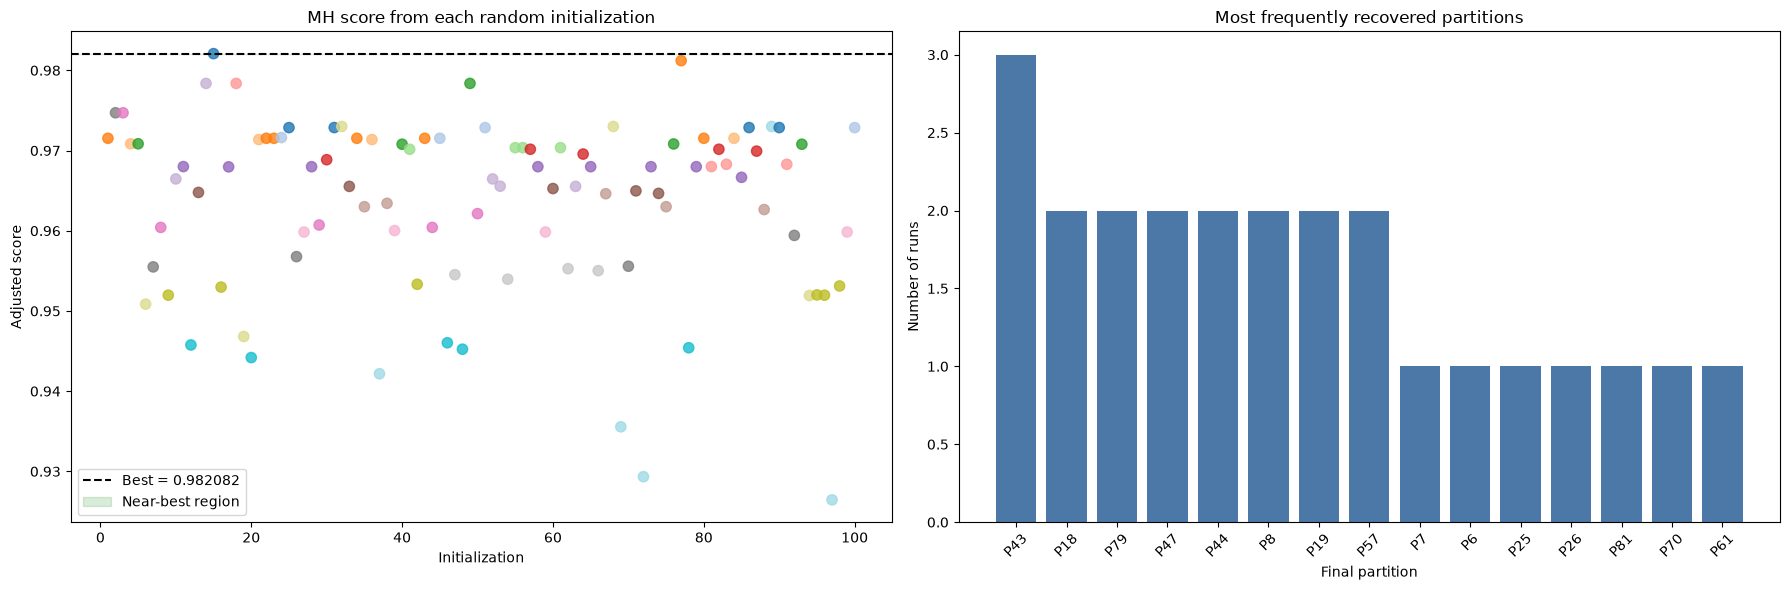

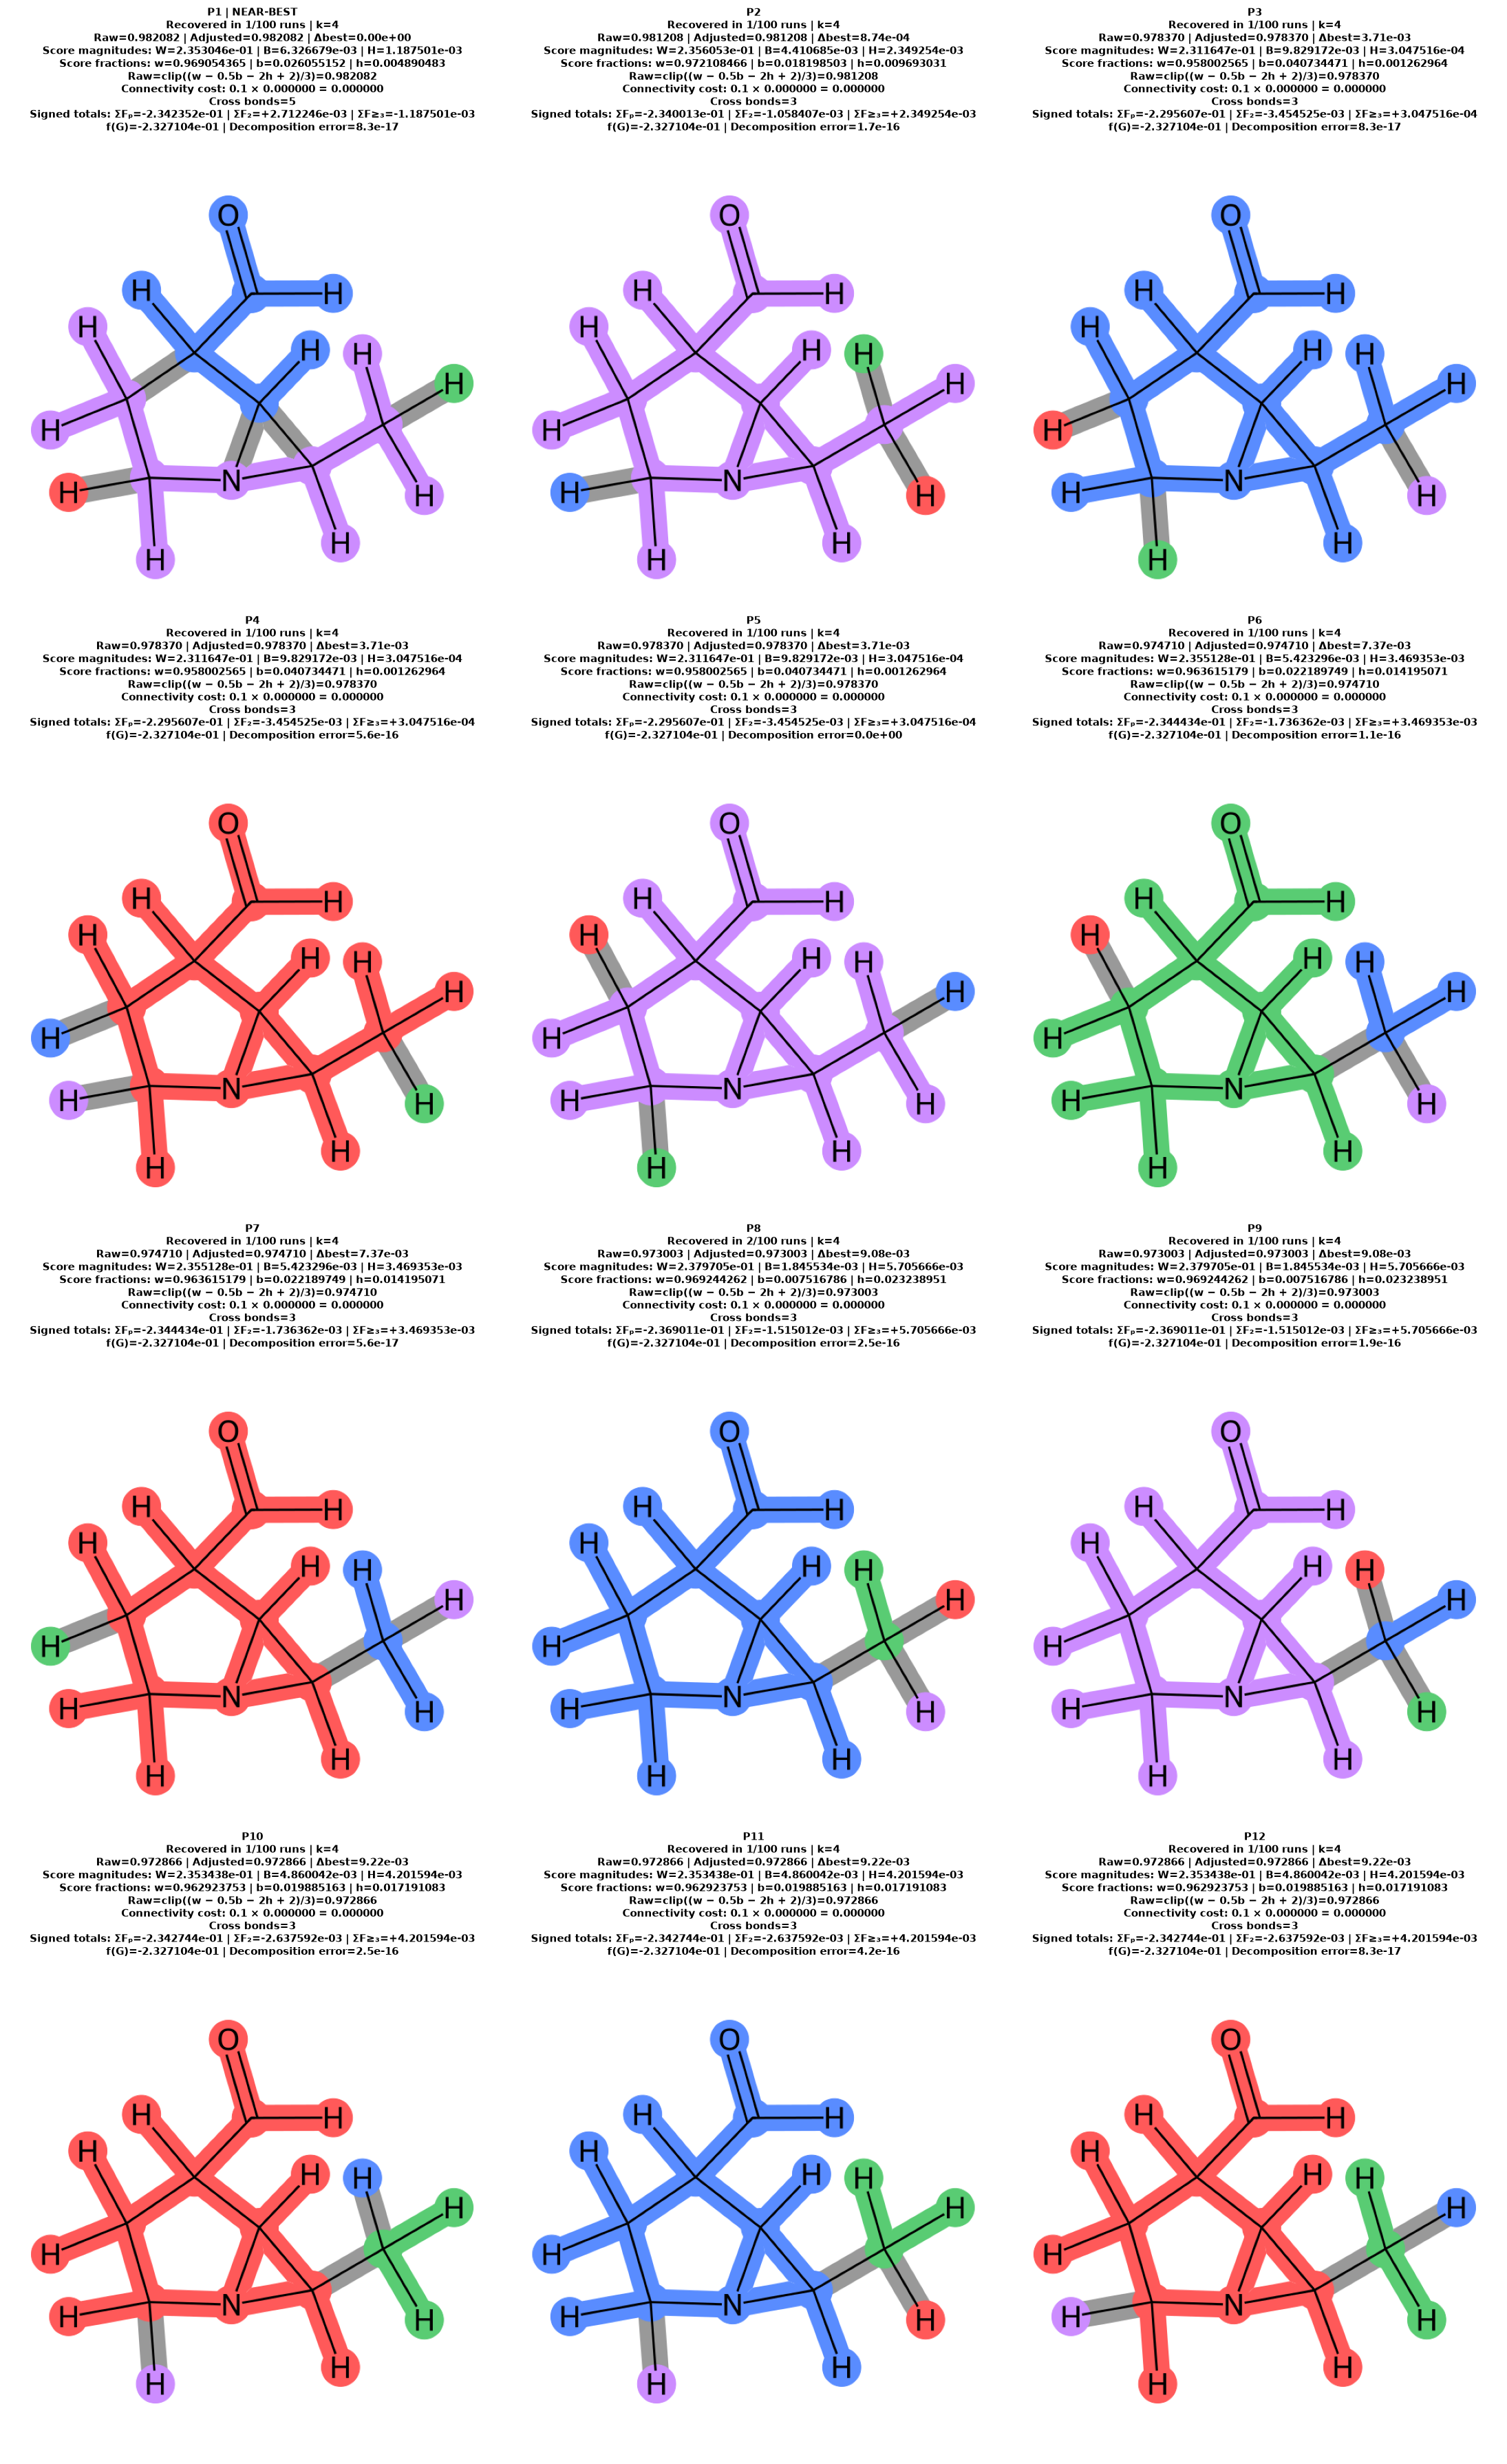

In [ ]:
# =============================================================================
# RUN METROPOLIS-HASTINGS FROM 100 RANDOM INITIALIZATIONS
# =============================================================================

N_INITIALIZATIONS = 100
N_ITERATIONS = 1000
N_CLUSTERS = K_TO_PLOT
MH_BETA = 10.0
BASE_SEED = 2026

# Scores within this absolute difference of the best score are considered tied.
SCORE_TOLERANCE = 1e-4


def canonicalize_partition(partition):
    """
    Create a label-invariant representation of an atom-to-partition mapping.

    For example:
        {0: 0, 1: 0, 2: 1}
        {0: 4, 1: 4, 2: 2}

    represent the same molecular partition.
    """
    atoms_by_partition = defaultdict(list)

    for atom_idx, partition_id in partition.items():
        atoms_by_partition[int(partition_id)].append(int(atom_idx))

    return tuple(
        sorted(
            tuple(sorted(atom_indices))
            for atom_indices in atoms_by_partition.values()
        )
    )


def count_cross_partition_bonds(mol, partition):
    """Count molecular bonds connecting different partitions."""
    return sum(
        partition[bond.GetBeginAtomIdx()]
        != partition[bond.GetEndAtomIdx()]
        for bond in mol.GetBonds()
    )


mh_results = []

for run_idx in range(N_INITIALIZATIONS):
    seed = BASE_SEED + run_idx

    # Each seed produces a different random initial partition.
    initial_partition = ChemicalPartitioner.random_partition(
        mol=large_mol,
        n_clusters=N_CLUSTERS,
        seed=seed
    )

    initial_interpretation = (
        optimizer.interpreter.compute_partition_contributions(
            large_mol,
            initial_partition
        )
    )

    initial_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=initial_interpretation,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=(
            optimizer.disconnected_singleton_weight
        )
    )

    # Run MH using the explicitly generated initialization.
    interpretation = (
        optimizer.optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=N_CLUSTERS,
            n_iterations=N_ITERATIONS,
            beta=MH_BETA,
            initial_partition=initial_partition,
            seed=seed,
            verbose=False
        )
    )

    partition = interpretation.partition

    connectivity_penalty = partition_connectivity_penalty(
        mol=large_mol,
        partition=partition,
        disconnected_singleton_weight=(
            optimizer.disconnected_singleton_weight
        )
    )

    adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=interpretation,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=(
            optimizer.disconnected_singleton_weight
        )
    )

    mh_results.append(
        {
            "Run": run_idx + 1,
            "Seed": seed,
            "Beta": MH_BETA,
            "Initial Partition": initial_partition,
            "Initial Adjusted Score": initial_adjusted_score,
            "Partition": partition,
            "Canonical Partition": canonicalize_partition(
                partition
            ),
            "Interpretation": interpretation,
            "Actual k": len(set(partition.values())),
            "Raw Score": interpretation.score,
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,
            "N Cross Bonds": count_cross_partition_bonds(
                large_mol,
                partition
            )
        }
    )

    if (run_idx + 1) % 10 == 0:
        print(
            f"Completed {run_idx + 1:3d}/{N_INITIALIZATIONS} "
            "initializations"
        )


# =============================================================================
# CREATE ONE ROW PER INITIALIZATION
# =============================================================================

runs_df = pd.DataFrame(
    {
        "Run": result["Run"],
        "Seed": result["Seed"],
        "Partition": result["Canonical Partition"],
        "Actual k": result["Actual k"],
        "Initial Adjusted Score": result[
            "Initial Adjusted Score"
        ],
        "Raw Score": result["Raw Score"],
        "Connectivity Penalty": result[
            "Connectivity Penalty"
        ],
        "Adjusted Score": result["Adjusted Score"],
        "N Cross Bonds": result["N Cross Bonds"]
    }
    for result in mh_results
)


# =============================================================================
# SUMMARIZE EACH UNIQUE FINAL PARTITION
# =============================================================================

partition_summary = (
    runs_df
    .groupby("Partition", as_index=False)
    .agg(
        Frequency=("Run", "size"),
        Actual_k=("Actual k", "first"),
        Best_Raw_Score=("Raw Score", "max"),
        Mean_Raw_Score=("Raw Score", "mean"),
        Best_Adjusted_Score=("Adjusted Score", "max"),
        Mean_Adjusted_Score=("Adjusted Score", "mean"),
        SD_Adjusted_Score=("Adjusted Score", "std"),
        Min_Adjusted_Score=("Adjusted Score", "min"),
        Max_Adjusted_Score=("Adjusted Score", "max"),
        Mean_Cross_Bonds=("N Cross Bonds", "mean")
    )
    .sort_values(
        [
            "Best_Adjusted_Score",
            "Frequency"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

partition_summary["Partition ID"] = [
    f"P{idx}"
    for idx in range(1, len(partition_summary) + 1)
]

partition_to_id = dict(
    zip(
        partition_summary["Partition"],
        partition_summary["Partition ID"]
    )
)

runs_df["Partition ID"] = runs_df["Partition"].map(
    partition_to_id
)


# =============================================================================
# CHECK WHETHER ONE PARTITION IS BEST
# =============================================================================

best_score = partition_summary.loc[
    0,
    "Best_Adjusted_Score"
]

partition_summary["Difference From Best"] = (
    best_score
    - partition_summary["Best_Adjusted_Score"]
)

partition_summary["Statistically Tied"] = (
    partition_summary["Difference From Best"]
    <= SCORE_TOLERANCE
)

best_partition_id = partition_summary.loc[
    0,
    "Partition ID"
]

best_partition_frequency = int(
    partition_summary.loc[0, "Frequency"]
)

n_unique_partitions = len(partition_summary)

n_tied_partitions = int(
    partition_summary["Statistically Tied"].sum()
)

print("\n" + "=" * 72)
print("METROPOLIS-HASTINGS REPRODUCIBILITY RESULTS")
print("=" * 72)

print(
    f"Initializations:          {N_INITIALIZATIONS}"
)
print(
    f"Iterations per run:       {N_ITERATIONS}"
)
print(
    f"Beta:                     {MH_BETA:g}"
)
print(
    f"Unique final partitions:  {n_unique_partitions}"
)
print(
    f"Best adjusted score:      {best_score:.6f}"
)
print(
    f"Best partition:           {best_partition_id}"
)
print(
    "Best partition recovered:"
    f" {best_partition_frequency}/{N_INITIALIZATIONS} times"
)
print(
    f"Near-best partitions:     {n_tied_partitions}"
)
print(
    f"Score tolerance:          {SCORE_TOLERANCE:g}"
)

if n_tied_partitions == 1:
    print(
        "\nConclusion: one partition has the uniquely best adjusted "
        "score under the selected tolerance."
    )
elif n_tied_partitions > 1:
    print(
        "\nConclusion: several structurally different partitions "
        "produce essentially the same best score."
    )

if best_partition_frequency == N_INITIALIZATIONS:
    print(
        "All initializations converged to the same best partition."
    )
elif best_partition_frequency >= 0.8 * N_INITIALIZATIONS:
    print(
        "The best partition is highly reproducible across "
        "initializations."
    )
else:
    print(
        "The result depends noticeably on initialization; inspect "
        "the alternative near-best partitions."
    )

display_columns = [
    "Partition ID",
    "Frequency",
    "Actual_k",
    "Best_Adjusted_Score",
    "Mean_Adjusted_Score",
    "Difference From Best",
    "Statistically Tied",
    "Mean_Cross_Bonds"
]

print(
    "\nTop partitions:\n"
    + partition_summary[
        display_columns
    ].head(20).to_string(index=False)
)


# =============================================================================
# PLOT ALL 100 RESULTS
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 6)
)

# Adjusted score from each initialization.
axes[0].scatter(
    runs_df["Run"],
    runs_df["Adjusted Score"],
    c=pd.Categorical(runs_df["Partition ID"]).codes,
    cmap="tab20",
    s=55,
    alpha=0.8
)

axes[0].axhline(
    best_score,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Best = {best_score:.6f}"
)

axes[0].axhspan(
    best_score - SCORE_TOLERANCE,
    best_score,
    color="green",
    alpha=0.15,
    label="Near-best region"
)

axes[0].set_xlabel("Initialization")
axes[0].set_ylabel("Adjusted score")
axes[0].set_title(
    "MH score from each random initialization"
)
axes[0].legend()

# Frequencies of the most common final partitions.
frequency_table = (
    runs_df["Partition ID"]
    .value_counts()
    .head(15)
)

axes[1].bar(
    frequency_table.index,
    frequency_table.values,
    color="#4C78A8"
)

axes[1].set_xlabel("Final partition")
axes[1].set_ylabel("Number of runs")
axes[1].set_title(
    "Most frequently recovered partitions"
)
axes[1].tick_params(
    axis="x",
    rotation=45
)

plt.tight_layout()
plt.show()


# =============================================================================
# DRAW REPRESENTATIVE UNIQUE PARTITIONS
# =============================================================================

N_PARTITIONS_TO_DRAW = min(
    12,
    n_unique_partitions
)

representative_results = []

for _, summary_row in partition_summary.head(
    N_PARTITIONS_TO_DRAW
).iterrows():

    canonical_partition = summary_row["Partition"]

    matching_results = [
        result
        for result in mh_results
        if result["Canonical Partition"] == canonical_partition
    ]

    # Scores should be deterministic for the same partition, but max()
    # also handles small floating-point differences.
    representative_result = max(
        matching_results,
        key=lambda result: result["Adjusted Score"]
    )

    representative_results.append(
        representative_result
    )


n_cols = 3
n_rows = (
    len(representative_results) + n_cols - 1
) // n_cols

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(22, 9 * n_rows),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(
    axes,
    representative_results
):
    partition = result["Partition"]
    canonical_partition = result["Canonical Partition"]
    partition_id = partition_to_id[canonical_partition]
    interpretation = result["Interpretation"]

    summary_row = partition_summary.loc[
        partition_summary["Partition"].map(
            lambda value: value == canonical_partition
        )
    ].iloc[0]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    # Signed totals reconstruct the molecular prediction.
    within_sum = sum(interpretation.within_partition.values())
    between_sum = sum(interpretation.between_partition.values())
    higher_sum = sum(interpretation.higher_order.values())

    reconstructed_prediction = (
        within_sum + between_sum + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction - interpretation.total_prediction
    )

    # Absolute magnitudes and fractions used by interpretation.score.
    # Absolute values are taken AFTER aggregating graphlets into each term.
    breakdown = interpretation.get_contribution_breakdown()

    W = breakdown["within"]
    B = breakdown["between"]
    H = breakdown["higher"]

    w = breakdown["within_frac"]
    b = breakdown["between_frac"]
    h = breakdown["higher_frac"]

    # Reproduce the exact raw-score calculation, including clipping.
    score_from_breakdown = max(
        0.0,
        min(1.0, (w - 0.5 * b - 2.0 * h + 2.0) / 3.0)
    )

    # Amount subtracted from the raw score before clipping to [0, 1].
    connectivity_cost = (
        optimizer.connectivity_weight
        * result["Connectivity Penalty"]
    )

    tied_text = (
        " | NEAR-BEST"
        if summary_row["Statistically Tied"]
        else ""
    )

    title = (
        f"{partition_id}{tied_text}\n"
        f"Recovered in {int(summary_row['Frequency'])}/"
        f"{N_INITIALIZATIONS} runs | k={result['Actual k']}\n"
        f"Raw={result['Raw Score']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f} | "
        f"Δbest={summary_row['Difference From Best']:.2e}\n"
        f"Score magnitudes: "
        f"W={W:.6e} | B={B:.6e} | H={H:.6e}\n"
        f"Score fractions: "
        f"w={w:.9f} | b={b:.9f} | h={h:.9f}\n"
        f"Raw=clip((w − 0.5b − 2h + 2)/3)"
        f"={score_from_breakdown:.6f}\n"
        f"Connectivity cost: "
        f"{optimizer.connectivity_weight:.4g} × "
        f"{result['Connectivity Penalty']:.6f}"
        f" = {connectivity_cost:.6f}\n"
        f"Cross bonds={result['N Cross Bonds']}\n"
        f"Signed totals: "
        f"ΣFₚ={within_sum:+.6e} | "
        f"ΣF₂={between_sum:+.6e} | "
        f"ΣF≥₃={higher_sum:+.6e}\n"
        f"f(G)={reconstructed_prediction:+.6e} | "
        f"Decomposition error={decomposition_error:.1e}"
    )

    ax.imshow(image)
    ax.axis("off")
    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold",
        pad=12
    )

for ax in axes[len(representative_results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Completed  10/100 initializations
Completed  20/100 initializations
Completed  30/100 initializations
Completed  40/100 initializations
Completed  50/100 initializations
Completed  60/100 initializations
Completed  70/100 initializations
Completed  80/100 initializations
Completed  90/100 initializations
Completed 100/100 initializations

METROPOLIS-HASTINGS REPRODUCIBILITY RESULTS
Initializations:          100
Iterations per run:       5000
Beta:                     10
Unique final partitions:  65
Best adjusted score:      0.982082
Best partition:           P1
Best partition recovered: 2/100 times
Near-best partitions:     5
Score tolerance:          0.0001

Conclusion: several structurally different partitions produce essentially the same best score.
The result depends noticeably on initialization; inspect the alternative near-best partitions.

Top partitions:
Partition ID  Frequency  Actual_k  Best_Adjusted_Score  Mean_Adjusted_Score  Difference From Best  Statistically Tied  Mean_C

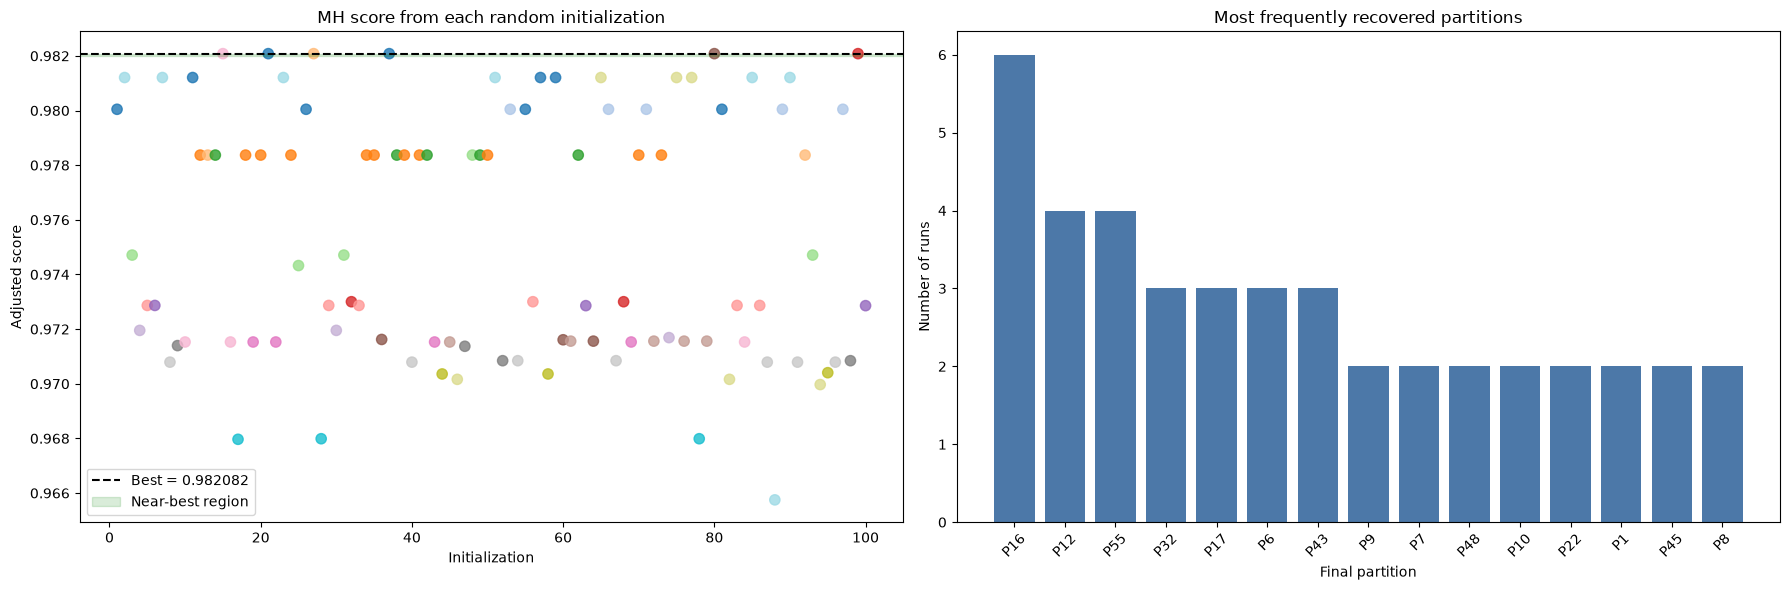

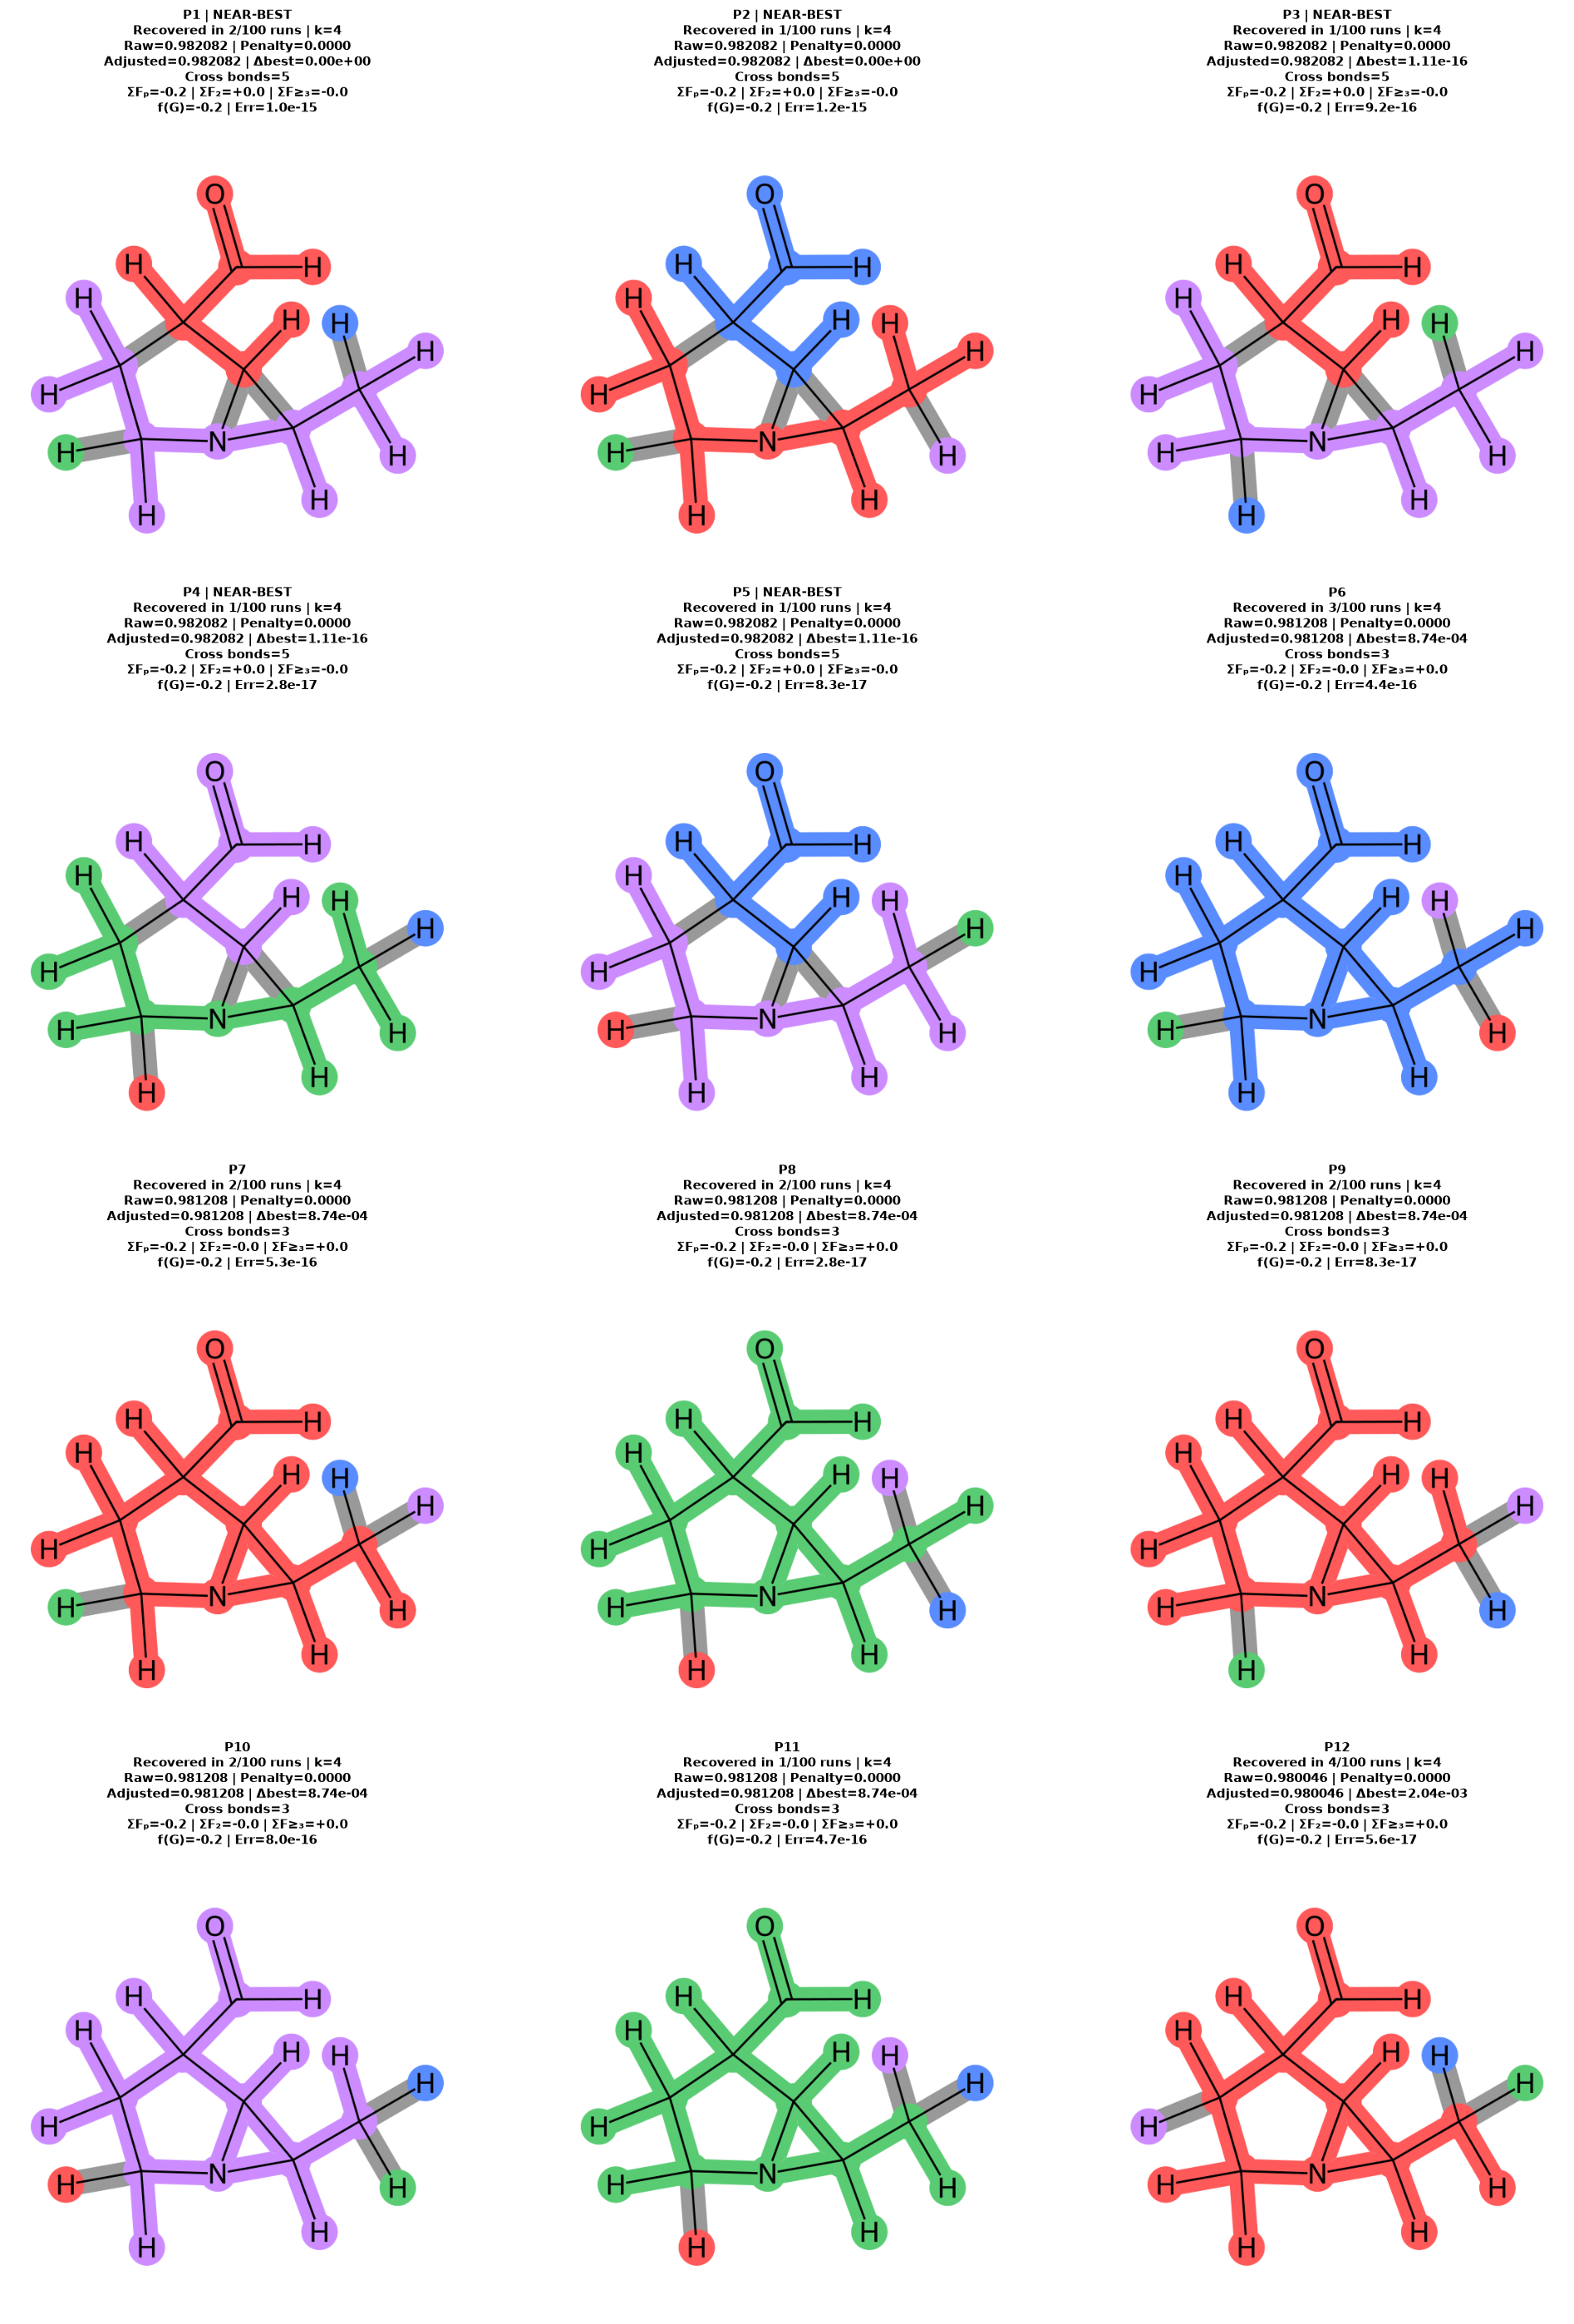

In [ ]:
# =============================================================================
# RUN METROPOLIS-HASTINGS FROM 100 RANDOM INITIALIZATIONS + 5000 ITERATIONS
# =============================================================================

N_INITIALIZATIONS = 100
N_ITERATIONS = 5000
N_CLUSTERS = K_TO_PLOT
MH_BETA = 10.0
BASE_SEED = 2026

# Scores within this absolute difference of the best score are considered tied.
SCORE_TOLERANCE = 1e-4


def canonicalize_partition(partition):
    """
    Create a label-invariant representation of an atom-to-partition mapping.

    For example:
        {0: 0, 1: 0, 2: 1}
        {0: 4, 1: 4, 2: 2}

    represent the same molecular partition.
    """
    atoms_by_partition = defaultdict(list)

    for atom_idx, partition_id in partition.items():
        atoms_by_partition[int(partition_id)].append(int(atom_idx))

    return tuple(
        sorted(
            tuple(sorted(atom_indices))
            for atom_indices in atoms_by_partition.values()
        )
    )


def count_cross_partition_bonds(mol, partition):
    """Count molecular bonds connecting different partitions."""
    return sum(
        partition[bond.GetBeginAtomIdx()]
        != partition[bond.GetEndAtomIdx()]
        for bond in mol.GetBonds()
    )


mh_results = []

for run_idx in range(N_INITIALIZATIONS):
    seed = BASE_SEED + run_idx

    # Each seed produces a different random initial partition.
    initial_partition = ChemicalPartitioner.random_partition(
        mol=large_mol,
        n_clusters=N_CLUSTERS,
        seed=seed
    )

    initial_interpretation = (
        optimizer.interpreter.compute_partition_contributions(
            large_mol,
            initial_partition
        )
    )

    initial_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=initial_interpretation,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=(
            optimizer.disconnected_singleton_weight
        )
    )

    # Run MH using the explicitly generated initialization.
    interpretation = (
        optimizer.optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=N_CLUSTERS,
            n_iterations=N_ITERATIONS,
            beta=MH_BETA,
            initial_partition=initial_partition,
            seed=seed,
            verbose=False
        )
    )

    partition = interpretation.partition

    connectivity_penalty = partition_connectivity_penalty(
        mol=large_mol,
        partition=partition,
        disconnected_singleton_weight=(
            optimizer.disconnected_singleton_weight
        )
    )

    adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=interpretation,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=(
            optimizer.disconnected_singleton_weight
        )
    )

    mh_results.append(
        {
            "Run": run_idx + 1,
            "Seed": seed,
            "Beta": MH_BETA,
            "Initial Partition": initial_partition,
            "Initial Adjusted Score": initial_adjusted_score,
            "Partition": partition,
            "Canonical Partition": canonicalize_partition(
                partition
            ),
            "Interpretation": interpretation,
            "Actual k": len(set(partition.values())),
            "Raw Score": interpretation.score,
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,
            "N Cross Bonds": count_cross_partition_bonds(
                large_mol,
                partition
            )
        }
    )

    if (run_idx + 1) % 10 == 0:
        print(
            f"Completed {run_idx + 1:3d}/{N_INITIALIZATIONS} "
            "initializations"
        )


# =============================================================================
# CREATE ONE ROW PER INITIALIZATION
# =============================================================================

runs_df = pd.DataFrame(
    {
        "Run": result["Run"],
        "Seed": result["Seed"],
        "Partition": result["Canonical Partition"],
        "Actual k": result["Actual k"],
        "Initial Adjusted Score": result[
            "Initial Adjusted Score"
        ],
        "Raw Score": result["Raw Score"],
        "Connectivity Penalty": result[
            "Connectivity Penalty"
        ],
        "Adjusted Score": result["Adjusted Score"],
        "N Cross Bonds": result["N Cross Bonds"]
    }
    for result in mh_results
)


# =============================================================================
# SUMMARIZE EACH UNIQUE FINAL PARTITION
# =============================================================================

partition_summary = (
    runs_df
    .groupby("Partition", as_index=False)
    .agg(
        Frequency=("Run", "size"),
        Actual_k=("Actual k", "first"),
        Best_Raw_Score=("Raw Score", "max"),
        Mean_Raw_Score=("Raw Score", "mean"),
        Best_Adjusted_Score=("Adjusted Score", "max"),
        Mean_Adjusted_Score=("Adjusted Score", "mean"),
        SD_Adjusted_Score=("Adjusted Score", "std"),
        Min_Adjusted_Score=("Adjusted Score", "min"),
        Max_Adjusted_Score=("Adjusted Score", "max"),
        Mean_Cross_Bonds=("N Cross Bonds", "mean")
    )
    .sort_values(
        [
            "Best_Adjusted_Score",
            "Frequency"
        ],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)

partition_summary["Partition ID"] = [
    f"P{idx}"
    for idx in range(1, len(partition_summary) + 1)
]

partition_to_id = dict(
    zip(
        partition_summary["Partition"],
        partition_summary["Partition ID"]
    )
)

runs_df["Partition ID"] = runs_df["Partition"].map(
    partition_to_id
)


# =============================================================================
# CHECK WHETHER ONE PARTITION IS BEST
# =============================================================================

best_score = partition_summary.loc[
    0,
    "Best_Adjusted_Score"
]

partition_summary["Difference From Best"] = (
    best_score
    - partition_summary["Best_Adjusted_Score"]
)

partition_summary["Statistically Tied"] = (
    partition_summary["Difference From Best"]
    <= SCORE_TOLERANCE
)

best_partition_id = partition_summary.loc[
    0,
    "Partition ID"
]

best_partition_frequency = int(
    partition_summary.loc[0, "Frequency"]
)

n_unique_partitions = len(partition_summary)

n_tied_partitions = int(
    partition_summary["Statistically Tied"].sum()
)

print("\n" + "=" * 72)
print("METROPOLIS-HASTINGS REPRODUCIBILITY RESULTS")
print("=" * 72)

print(
    f"Initializations:          {N_INITIALIZATIONS}"
)
print(
    f"Iterations per run:       {N_ITERATIONS}"
)
print(
    f"Beta:                     {MH_BETA:g}"
)
print(
    f"Unique final partitions:  {n_unique_partitions}"
)
print(
    f"Best adjusted score:      {best_score:.6f}"
)
print(
    f"Best partition:           {best_partition_id}"
)
print(
    "Best partition recovered:"
    f" {best_partition_frequency}/{N_INITIALIZATIONS} times"
)
print(
    f"Near-best partitions:     {n_tied_partitions}"
)
print(
    f"Score tolerance:          {SCORE_TOLERANCE:g}"
)

if n_tied_partitions == 1:
    print(
        "\nConclusion: one partition has the uniquely best adjusted "
        "score under the selected tolerance."
    )
elif n_tied_partitions > 1:
    print(
        "\nConclusion: several structurally different partitions "
        "produce essentially the same best score."
    )

if best_partition_frequency == N_INITIALIZATIONS:
    print(
        "All initializations converged to the same best partition."
    )
elif best_partition_frequency >= 0.8 * N_INITIALIZATIONS:
    print(
        "The best partition is highly reproducible across "
        "initializations."
    )
else:
    print(
        "The result depends noticeably on initialization; inspect "
        "the alternative near-best partitions."
    )

display_columns = [
    "Partition ID",
    "Frequency",
    "Actual_k",
    "Best_Adjusted_Score",
    "Mean_Adjusted_Score",
    "Difference From Best",
    "Statistically Tied",
    "Mean_Cross_Bonds"
]

print(
    "\nTop partitions:\n"
    + partition_summary[
        display_columns
    ].head(20).to_string(index=False)
)


# =============================================================================
# PLOT ALL 100 RESULTS
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(18, 6)
)

# Adjusted score from each initialization.
axes[0].scatter(
    runs_df["Run"],
    runs_df["Adjusted Score"],
    c=pd.Categorical(runs_df["Partition ID"]).codes,
    cmap="tab20",
    s=55,
    alpha=0.8
)

axes[0].axhline(
    best_score,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Best = {best_score:.6f}"
)

axes[0].axhspan(
    best_score - SCORE_TOLERANCE,
    best_score,
    color="green",
    alpha=0.15,
    label="Near-best region"
)

axes[0].set_xlabel("Initialization")
axes[0].set_ylabel("Adjusted score")
axes[0].set_title(
    "MH score from each random initialization"
)
axes[0].legend()

# Frequencies of the most common final partitions.
frequency_table = (
    runs_df["Partition ID"]
    .value_counts()
    .head(15)
)

axes[1].bar(
    frequency_table.index,
    frequency_table.values,
    color="#4C78A8"
)

axes[1].set_xlabel("Final partition")
axes[1].set_ylabel("Number of runs")
axes[1].set_title(
    "Most frequently recovered partitions"
)
axes[1].tick_params(
    axis="x",
    rotation=45
)

plt.tight_layout()
plt.show()


# =============================================================================
# DRAW REPRESENTATIVE UNIQUE PARTITIONS
# =============================================================================

N_PARTITIONS_TO_DRAW = min(
    12,
    n_unique_partitions
)

representative_results = []

for _, summary_row in partition_summary.head(
    N_PARTITIONS_TO_DRAW
).iterrows():

    canonical_partition = summary_row["Partition"]

    matching_results = [
        result
        for result in mh_results
        if result["Canonical Partition"] == canonical_partition
    ]

    # Scores should be deterministic for the same partition, but max()
    # also handles small floating-point differences.
    representative_result = max(
        matching_results,
        key=lambda result: result["Adjusted Score"]
    )

    representative_results.append(
        representative_result
    )


n_cols = 3
n_rows = (
    len(representative_results) + n_cols - 1
) // n_cols

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(20, 7 * n_rows),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(
    axes,
    representative_results
):
    partition = result["Partition"]
    canonical_partition = result["Canonical Partition"]
    partition_id = partition_to_id[canonical_partition]
    interpretation = result["Interpretation"]

    summary_row = partition_summary.loc[
        partition_summary["Partition"].map(
            lambda value: value == canonical_partition
        )
    ].iloc[0]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    within_sum = sum(
        interpretation.within_partition.values()
    )

    between_sum = sum(
        interpretation.between_partition.values()
    )

    higher_sum = sum(
        interpretation.higher_order.values()
    )

    reconstructed_prediction = (
        within_sum
        + between_sum
        + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction
        - interpretation.total_prediction
    )

    tied_text = (
        " | NEAR-BEST"
        if summary_row["Statistically Tied"]
        else ""
    )

    title = (
        f"{partition_id}{tied_text}\n"
        f"Recovered in {int(summary_row['Frequency'])}/"
        f"{N_INITIALIZATIONS} runs | "
        f"k={result['Actual k']}\n"
        f"Raw={result['Raw Score']:.6f} | "
        f"Penalty={result['Connectivity Penalty']:.4f}\n"
        f"Adjusted={result['Adjusted Score']:.6f} | "
        f"Δbest={summary_row['Difference From Best']:.2e}\n"
        f"Cross bonds={result['N Cross Bonds']}\n"
        f"ΣFₚ={within_sum:+.1f} | "
        f"ΣF₂={between_sum:+.1f} | "
        f"ΣF≥₃={higher_sum:+.1f}\n"
        f"f(G)={reconstructed_prediction:+.1f} | "
        f"Err={decomposition_error:.1e}"
    )

    ax.imshow(image)
    ax.axis("off")
    ax.set_title(
        title,
        fontsize=11,
        fontweight="bold",
        pad=12
    )

for ax in axes[len(representative_results):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# RUN METROPOLIS-HASTINGS FOR EACH BETA
# =============================================================================

beta_results = []

for mh_beta in MH_BETAS:

    print(
        f"\nRunning Metropolis-Hastings with "
        f"k={K_TO_PLOT}, beta={mh_beta:g}..."
    )

    # Lambda / connectivity weight stays fixed.
    optimizer_beta = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    interpretation = (
        optimizer_beta
        .optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=K_TO_PLOT,
            n_iterations=MH_ITERATIONS,
            beta=mh_beta,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False
        )
    )

    partition = interpretation.partition

    actual_k = len(
        set(partition.values())
    )

    if actual_k != K_TO_PLOT:
        raise RuntimeError(
            f"Beta={mh_beta:g} requested k={K_TO_PLOT}, "
            f"but Metropolis-Hastings returned k={actual_k}."
        )

    connectivity_penalty = (
        partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    # IMPORTANT:
    # beta does NOT enter the score formula.
    # It only changes MH acceptance/rejection behavior.
    adjusted_score = (
        connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            )
        )
    )

    cross_partition_bonds = [
        bond.GetIdx()
        for bond in large_mol.GetBonds()
        if (
            partition[bond.GetBeginAtomIdx()]
            != partition[bond.GetEndAtomIdx()]
        )
    ]

    beta_results.append({
        "Beta": mh_beta,
        "Partition": partition,
        "Interpretation": interpretation,
        "Actual k": actual_k,
        "Raw Score": interpretation.score,
        "Connectivity Penalty": connectivity_penalty,
        "Adjusted Score": adjusted_score,
        "Cross Bonds": cross_partition_bonds,
        "N Cross Bonds": len(cross_partition_bonds),
    })

    print(
        f"  actual k={actual_k}, "
        f"raw={interpretation.score:.4f}, "
        f"penalty={connectivity_penalty:.4f}, "
        f"adjusted={adjusted_score:.4f}, "
        f"cross bonds={len(cross_partition_bonds)}"
    )


Running Metropolis-Hastings with k=4, beta=0.1...
  actual k=4, raw=0.9680, penalty=0.0000, adjusted=0.9680, cross bonds=3

Running Metropolis-Hastings with k=4, beta=1...
  actual k=4, raw=0.9704, penalty=0.0000, adjusted=0.9704, cross bonds=3

Running Metropolis-Hastings with k=4, beta=5...
  actual k=4, raw=0.9784, penalty=0.0000, adjusted=0.9784, cross bonds=3

Running Metropolis-Hastings with k=4, beta=20...
  actual k=4, raw=0.9812, penalty=0.0000, adjusted=0.9812, cross bonds=3

Running Metropolis-Hastings with k=4, beta=50...
  actual k=4, raw=0.9821, penalty=0.0000, adjusted=0.9821, cross bonds=5

Running Metropolis-Hastings with k=4, beta=100...
  actual k=4, raw=0.9598, penalty=0.0000, adjusted=0.9598, cross bonds=3


In [ ]:
# =============================================================================
# DRAW THE BETA RESULTS
# =============================================================================

n_results = len(beta_results)
n_cols = 3
n_rows = (n_results + n_cols - 1) // n_cols

fig, axes = plt.subplots(
    nrows=n_rows,
    ncols=n_cols,
    figsize=(24, 10 * n_rows),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, result in zip(
    axes,
    beta_results
):
    mh_beta = result["Beta"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    within_sum = sum(
        interpretation.within_partition.values()
    )

    between_sum = sum(
        interpretation.between_partition.values()
    )

    higher_sum = sum(
        interpretation.higher_order.values()
    )

    reconstructed_prediction = (
        within_sum
        + between_sum
        + higher_sum
    )

    decomposition_error = abs(
        reconstructed_prediction
        - interpretation.total_prediction
    )

    title = (
        f"Metropolis-Hastings: "
        rf"$\beta={mh_beta:g}$"
        "\n"
        f"k={result['Actual k']} | "
        f"Raw={result['Raw Score']:.6f}\n"
        f"Penalty={result['Connectivity Penalty']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f}\n"
        f"Cross bonds={result['N Cross Bonds']}\n"
    ) + partition_score_title_details(interpretation)

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=12
    )

for ax in axes[len(beta_results):]:
    ax.axis("off")

In [ ]:
# =============================================================================
# ADD COMMON LEGEND
# =============================================================================

legend_handles = [
    Patch(
        facecolor=PARTITION_COLORS[partition_id],
        edgecolor="black",
        label=fr"$P_{{{partition_id}}}$"
    )
    for partition_id in range(K_TO_PLOT)
]

# Add a gray legend item for boundary-crossing bonds.
legend_handles.append(
    Patch(
        facecolor=(0.60, 0.60, 0.60),
        edgecolor="black",
        label="Cross-partition bond"
    )
)

fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=len(legend_handles),
    fontsize=12,
    title="Partition Assignment",
    title_fontsize=13,
    frameon=True
)

fig.suptitle(
    f"Large Molecule: {large_smiles}\n"
    f"Metropolis-Hastings k={K_TO_PLOT}: "
    rf"Effect of Acceptance Parameter $\beta$ "
    f"(lambda={CONNECTIVITY_WEIGHT:g})",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

output_filename = (
    "large_molecule_metropolis_hastings_"
    "k4_beta_comparison_e_homo.png"
)

fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.04,
    top=0.87,
    hspace=0.32,
    wspace=0.10
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PRINT BETA COMPARISON TABLE
# =============================================================================

comparison_rows = []

for result in beta_results:
    comparison_rows.append({
        "Beta": result["Beta"],
        "Raw Score": result["Raw Score"],
        "Connectivity Penalty": (
            result["Connectivity Penalty"]
        ),
        "Adjusted Score": result["Adjusted Score"],
        "Cross-Partition Bonds": result["N Cross Bonds"],
        "Actual k": result["Actual k"],
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print("\n" + "=" * 80)
print("METROPOLIS-HASTINGS BETA COMPARISON")
print("=" * 80)

print(
    comparison_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}"
    )
)


METROPOLIS-HASTINGS BETA COMPARISON
      Beta  Raw Score  Connectivity Penalty  Adjusted Score  Cross-Partition Bonds  Actual k
  0.100000   0.968000              0.000000        0.968000                      3         4
  1.000000   0.970359              0.000000        0.970359                      3         4
  5.000000   0.978370              0.000000        0.978370                      3         4
 20.000000   0.981208              0.000000        0.981208                      3         4
 50.000000   0.982082              0.000000        0.982082                      5         4
100.000000   0.959846              0.000000        0.959846                      3         4


In [ ]:
# =============================================================================
# PRINT PARTITION DETAILS
# =============================================================================

print("\n" + "=" * 80)
print("PARTITION DETAILS BY BETA")
print("=" * 80)

for result in beta_results:

    mh_beta = result["Beta"]
    partition = result["Partition"]
    interpretation = result["Interpretation"]

    print(
        f"\nBeta={mh_beta:g}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Cross-partition bonds: "
        f"{result['Cross Bonds']}"
    )

    for partition_id in sorted(
        set(partition.values())
    ):
        atoms = [
            atom_idx
            for atom_idx, assigned_partition
            in partition.items()
            if assigned_partition == partition_id
        ]

        symbols = [
            large_mol
            .GetAtomWithIdx(atom_idx)
            .GetSymbol()
            for atom_idx in atoms
        ]

        within_contribution = (
            interpretation.within_partition.get(
                partition_id,
                0.0
            )
        )

        print(
            f"  P{partition_id}: "
            f"atoms={atoms}, "
            f"symbols={symbols}, "
            f"F_{partition_id}="
            f"{within_contribution:+.3f}"
        )
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


PARTITION DETAILS BY BETA

Beta=0.1
  Raw score: 0.968000
  Connectivity penalty: 0.000000
  Adjusted score: 0.968000
  Cross-partition bonds: [16, 18, 20]
  P0: atoms=[17], symbols=['H'], F_0=+0.000
  P1: atoms=[15], symbols=['H'], F_1=+0.000
  P2: atoms=[19], symbols=['H'], F_2=+0.000
  P3: atoms=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 16, 18], symbols=['C', 'C', 'C', 'C', 'C', 'C', 'N', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_3=-0.220

Beta=1
  Raw score: 0.970359
  Connectivity penalty: 0.000000
  Adjusted score: 0.970359
  Cross-partition bonds: [10, 16, 20]
  P0: atoms=[19], symbols=['H'], F_0=+0.000
  P1: atoms=[15], symbols=['H'], F_1=+0.000
  P2: atoms=[9], symbols=['H'], F_2=+0.000
  P3: atoms=[0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 16, 17, 18], symbols=['C', 'C', 'C', 'C', 'C', 'C', 'N', 'C', 'O', 'H', 'H', 'H', 'H', 'H', 'H', 'H', 'H'], F_3=-0.226

Beta=5
  Raw score: 0.978370
  Connectivity penalty: 0.000000
  Adjusted score: 0.978370
  Cro

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

# Keep lambda / connectivity weight FIXED.
CONNECTIVITY_WEIGHT = 0.10

DISCONNECTED_SINGLETON_WEIGHT = 2.0

# Vary the Metropolis-Hastings acceptance parameter beta.
MH_BETAS = (
    0.1,
    1.0,
    5.0,
    20.0,
    50.0,
)

MH_ITERATIONS = 5000
MH_INITIALIZATION = "distance"
MH_SEED = 42

In [ ]:
# =============================================================================
# PARTITION COLORS
# =============================================================================

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# SELECT THE SPECIFIC TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142
EXPECTED_SMILES = "CC1C2C(CCN12)C=O"

test_reset = test.reset_index(drop=True)

if TARGET_TEST_INDEX >= len(test_reset):
    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} is out of range. "
        f"The reset test set contains {len(test_reset)} molecules."
    )

selected_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]
large_size_label = "Selected Large Molecule"

if large_mol is None:
    raise ValueError(
        f"The molecule at test index {TARGET_TEST_INDEX} is None."
    )

# Confirm that the selected row is the intended molecule.
if large_smiles != EXPECTED_SMILES:
    raise ValueError(
        f"Unexpected molecule at test index {TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_PLOT} nonempty partitions."
    )


print("=" * 80)
print("SELECTED TEST MOLECULE")
print("=" * 80)
print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {large_smiles}")
print(f"Total atoms: {large_mol.GetNumAtoms()}")
print(f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print(f"MH beta values: {list(MH_BETAS)}")
print(f"MH iterations per beta: {MH_ITERATIONS}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"MH seed: {MH_SEED}")
print("=" * 80)

SELECTED TEST MOLECULE
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
Requested partitions: k=4
Connectivity weight: 0.1
MH beta values: [0.1, 1.0, 5.0, 20.0, 50.0]
MH iterations per beta: 5000
MH initialization: distance
MH seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition.

    Bonds contained within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# RUN 100 INDEPENDENT METROPOLIS-HASTINGS INITIALIZATIONS FOR EACH BETA
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# -----------------------------------------------------------------------------
# SETTINGS
# -----------------------------------------------------------------------------

N_INITIALIZATIONS = 100

# Starting seed used to generate the 100 independent runs.
BASE_SEED = 42

# Generate 100 different reproducible seeds.
INITIALIZATION_SEEDS = [
    BASE_SEED + initialization_index
    for initialization_index in range(N_INITIALIZATIONS)
]


print("=" * 80)
print("METROPOLIS-HASTINGS BETA DISTRIBUTION EXPERIMENT")
print("=" * 80)

print(
    f"Number of beta values: "
    f"{len(MH_BETAS)}"
)

print(
    f"Independent initializations per beta: "
    f"{N_INITIALIZATIONS}"
)

print(
    f"MH iterations per initialization: "
    f"{MH_ITERATIONS}"
)

print(
    f"Total MH runs: "
    f"{len(MH_BETAS) * N_INITIALIZATIONS}"
)

print(
    f"k = {K_TO_PLOT}"
)

print(
    f"Connectivity weight lambda = "
    f"{CONNECTIVITY_WEIGHT}"
)

print("=" * 80)

METROPOLIS-HASTINGS BETA DISTRIBUTION EXPERIMENT
Number of beta values: 5
Independent initializations per beta: 100
MH iterations per initialization: 5000
Total MH runs: 500
k = 4
Connectivity weight lambda = 0.1


In [ ]:
# =============================================================================
# STORE RESULTS
# =============================================================================

beta_run_results = []

In [ ]:
# =============================================================================
# RUN EXPERIMENT
# =============================================================================

for beta_index, mh_beta in enumerate(MH_BETAS):

    print(
        f"\n{'=' * 80}"
    )

    print(
        f"Beta = {mh_beta:g}"
    )

    print(
        f"{'=' * 80}"
    )

    beta_scores = []

    # -------------------------------------------------------------------------
    # Optimizer settings remain identical for all 100 runs.
    # -------------------------------------------------------------------------

    optimizer_beta = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    # -------------------------------------------------------------------------
    # independent initializations
    # -------------------------------------------------------------------------

    for initialization_index, seed in enumerate(
        INITIALIZATION_SEEDS,
        start=1
    ):

        # ---------------------------------------------------------------------
        # Run Metropolis-Hastings.
        #
        # Because the seed changes on every run:
        #
        #   1. distance initialization can select different seed atoms;
        #   2. the MH proposal sequence changes;
        #   3. the MH random accept/reject draws change.
        #
        # Thus each run is an independent stochastic search.
        # ---------------------------------------------------------------------

        interpretation = (
            optimizer_beta
            .optimize_partition_metropolis_hastings(
                mol=large_mol,
                n_clusters=K_TO_PLOT,
                n_iterations=MH_ITERATIONS,
                beta=mh_beta,
                initialization=MH_INITIALIZATION,
                seed=seed,
                verbose=False
            )
        )

        partition = (
            interpretation.partition
        )

        actual_k = len(
            set(
                partition.values()
            )
        )

        # ---------------------------------------------------------------------
        # Verify that exactly four partitions remain.
        # ---------------------------------------------------------------------

        if actual_k != K_TO_PLOT:

            raise RuntimeError(
                f"Beta={mh_beta:g}, "
                f"initialization={initialization_index}, "
                f"seed={seed}: "
                f"requested k={K_TO_PLOT}, "
                f"but MH returned k={actual_k}."
            )

        # ---------------------------------------------------------------------
        # Connectivity penalty
        # ---------------------------------------------------------------------

        connectivity_penalty = (
            partition_connectivity_penalty(
                mol=large_mol,
                partition=partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # ---------------------------------------------------------------------
        # Connectivity-adjusted score
        #
        # beta does NOT appear in this formula.
        #
        # beta affects which partitions MH explores and accepts.
        # lambda remains fixed at CONNECTIVITY_WEIGHT.
        # ---------------------------------------------------------------------

        adjusted_score = (
            connectivity_adjusted_score(
                mol=large_mol,
                interpretation=interpretation,
                connectivity_weight=(
                    CONNECTIVITY_WEIGHT
                ),
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # ---------------------------------------------------------------------
        # Count partition-boundary bonds.
        # ---------------------------------------------------------------------

        cross_partition_bonds = [
            bond.GetIdx()
            for bond in large_mol.GetBonds()
            if (
                partition[
                    bond.GetBeginAtomIdx()
                ]
                !=
                partition[
                    bond.GetEndAtomIdx()
                ]
            )
        ]

        # ---------------------------------------------------------------------
        # Store this independent run.
        # ---------------------------------------------------------------------

        beta_run_results.append({
            "Beta": mh_beta,
            "Initialization": initialization_index,
            "Seed": seed,
            "Raw Score": interpretation.score,
            "Connectivity Penalty": (
                connectivity_penalty
            ),
            "Adjusted Score": (
                adjusted_score
            ),
            "Cross-Partition Bonds": (
                len(cross_partition_bonds)
            ),
            "Actual k": actual_k,
            "Partition": partition,
            "Interpretation": interpretation,
        })

        beta_scores.append(
            adjusted_score
        )

        # ---------------------------------------------------------------------
        # Progress output every 20 runs.
        # ---------------------------------------------------------------------

        if (
            initialization_index % 20 == 0
            or initialization_index
            == N_INITIALIZATIONS
        ):

            print(
                f"  Completed "
                f"{initialization_index:3d}/"
                f"{N_INITIALIZATIONS} "
                f"initializations"
            )

    # -------------------------------------------------------------------------
    # Summary for this beta.
    # -------------------------------------------------------------------------

    beta_scores = np.asarray(
        beta_scores
    )

    print(
        f"\n  Beta={mh_beta:g} summary:"
    )

    print(
        f"    Mean adjusted score: "
        f"{beta_scores.mean():.6f}"
    )

    print(
        f"    Std:                 "
        f"{beta_scores.std(ddof=1):.6f}"
    )

    print(
        f"    Median:              "
        f"{np.median(beta_scores):.6f}"
    )

    print(
        f"    Min:                 "
        f"{beta_scores.min():.6f}"
    )

    print(
        f"    Max:                 "
        f"{beta_scores.max():.6f}"
    )


Beta = 0.1
  Completed  20/100 initializations
  Completed  40/100 initializations
  Completed  60/100 initializations
  Completed  80/100 initializations
  Completed 100/100 initializations

  Beta=0.1 summary:
    Mean adjusted score: 0.974238
    Std:                 0.005395
    Median:              0.972863
    Min:                 0.958673
    Max:                 0.982082

Beta = 1
  Completed  20/100 initializations
  Completed  40/100 initializations
  Completed  60/100 initializations
  Completed  80/100 initializations
  Completed 100/100 initializations

  Beta=1 summary:
    Mean adjusted score: 0.975552
    Std:                 0.005044
    Median:              0.974710
    Min:                 0.960606
    Max:                 0.982082

Beta = 5
  Completed  20/100 initializations
  Completed  40/100 initializations
  Completed  60/100 initializations
  Completed  80/100 initializations
  Completed 100/100 initializations

  Beta=5 summary:
    Mean adjusted score: 0.97

In [ ]:
# =============================================================================
# CONVERT RESULTS TO DATAFRAME
# =============================================================================

beta_results_df = pd.DataFrame(
    beta_run_results
)

In [ ]:
# =============================================================================
# CREATE SUMMARY TABLE
# =============================================================================

beta_summary_df = (
    beta_results_df
    .groupby(
        "Beta",
        as_index=False
    )
    .agg(
        N=(
            "Adjusted Score",
            "count"
        ),
        Mean_Adjusted_Score=(
            "Adjusted Score",
            "mean"
        ),
        Std_Adjusted_Score=(
            "Adjusted Score",
            "std"
        ),
        Median_Adjusted_Score=(
            "Adjusted Score",
            "median"
        ),
        Min_Adjusted_Score=(
            "Adjusted Score",
            "min"
        ),
        Max_Adjusted_Score=(
            "Adjusted Score",
            "max"
        ),
        Mean_Raw_Score=(
            "Raw Score",
            "mean"
        ),
        Mean_Connectivity_Penalty=(
            "Connectivity Penalty",
            "mean"
        )
    )
)


print(
    "\n"
    + "=" * 100
)

print(
    "METROPOLIS-HASTINGS SCORE DISTRIBUTION BY BETA"
)

print(
    "=" * 100
)

print(
    beta_summary_df.to_string(
        index=False,
        float_format=(
            lambda value:
            f"{value:.6f}"
        )
    )
)


METROPOLIS-HASTINGS SCORE DISTRIBUTION BY BETA
     Beta   N  Mean_Adjusted_Score  Std_Adjusted_Score  Median_Adjusted_Score  Min_Adjusted_Score  Max_Adjusted_Score  Mean_Raw_Score  Mean_Connectivity_Penalty
 0.100000 100             0.974238            0.005395               0.972863            0.958673            0.982082        0.974838                   0.006000
 1.000000 100             0.975552            0.005044               0.974710            0.960606            0.982082        0.975652                   0.001000
 5.000000 100             0.975639            0.004829               0.976540            0.963501            0.982082        0.976039                   0.004000
20.000000 100             0.976489            0.004896               0.978370            0.964402            0.982082        0.977089                   0.006000
50.000000 100             0.976529            0.005479               0.978370            0.959440            0.982082        0.977129              

In [ ]:
# =============================================================================
# PREPARE SCORE DISTRIBUTIONS
# =============================================================================

score_distributions = []

for mh_beta in MH_BETAS:

    scores = (
        beta_results_df.loc[
            beta_results_df["Beta"]
            == mh_beta,
            "Adjusted Score"
        ]
        .to_numpy()
    )

    score_distributions.append(
        scores
    )

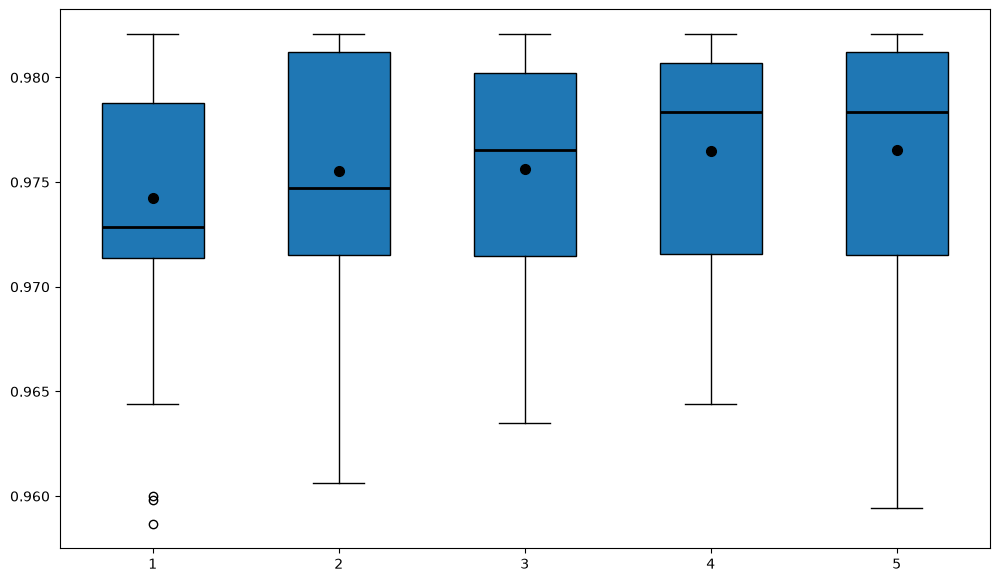

In [ ]:
# =============================================================================
# PLOT 1: BOX PLOT OF ADJUSTED SCORE DISTRIBUTIONS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(12, 7)
)

positions = np.arange(
    1,
    len(MH_BETAS) + 1
)


boxplot = ax.boxplot(
    score_distributions,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 2,
    }
)

In [ ]:
# =============================================================================
# ADD ALL 100 INDIVIDUAL RESULTS
# =============================================================================
#
# A small horizontal jitter is added only for visualization.
# It does not change any data values.
# =============================================================================

jitter_rng = np.random.default_rng(
    12345
)

for position, scores in zip(
    positions,
    score_distributions
):

    horizontal_jitter = (
        jitter_rng.normal(
            loc=0.0,
            scale=0.045,
            size=len(scores)
        )
    )

    ax.scatter(
        position
        + horizontal_jitter,
        scores,
        s=18,
        alpha=0.35
    )

In [ ]:
# =============================================================================
# FORMAT BOX PLOT
# =============================================================================

ax.set_xticks(
    positions
)

ax.set_xticklabels([
    rf"$\beta={beta:g}$"
    for beta in MH_BETAS
])

ax.set_xlabel(
    r"Metropolis-Hastings Acceptance Parameter $\beta$",
    fontsize=16
)

ax.set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Metropolis-Hastings Score Distribution\n"
    f"{N_INITIALIZATIONS} Independent Initializations per "
    r"$\beta$") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    axis="y",
    alpha=0.3
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y AXIS
# =============================================================================
#
# Zoom the y-axis to make differences between beta values easier to see.
# =============================================================================

all_adjusted_scores = (
    beta_results_df[
        "Adjusted Score"
    ]
    .to_numpy()
)

score_min = (
    all_adjusted_scores.min()
)

score_max = (
    all_adjusted_scores.max()
)

score_range = (
    score_max - score_min
)

if score_range < 1e-12:

    score_padding = 0.01

else:

    score_padding = (
        0.08 * score_range
    )

ax.set_ylim(
    max(
        0.0,
        score_min
        - score_padding
    ),
    min(
        1.0,
        score_max
        + score_padding
    )
)


plt.tight_layout()

output_filename = (
    "mh_beta_adjusted_score_"
    "distribution_100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved score distribution plot to "
    f"'{output_filename}'"
)

plt.show()


# =============================================================================
# PLOT 2: MEAN SCORE +/- STANDARD DEVIATION
# =============================================================================

beta_means = np.asarray([
    scores.mean()
    for scores in score_distributions
])

beta_stds = np.asarray([
    scores.std(
        ddof=1
    )
    for scores in score_distributions
])


fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.errorbar(
    MH_BETAS,
    beta_means,
    yerr=beta_stds,
    marker="o",
    markersize=9,
    linewidth=2,
    capsize=6
)

ax.set_xscale(
    "log"
)

ax.set_xlabel(
    r"Metropolis-Hastings Acceptance Parameter $\beta$",
    fontsize=16
)

ax.set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Mean Metropolis-Hastings Score vs "
    r"$\beta$"
    "\n"
    f"{N_INITIALIZATIONS} Independent Initializations") + "\n" + "Mean adjusted score; error bars = ±1 SD across runs",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    alpha=0.3
)


mean_min = min(
    beta_means
    - beta_stds
)

mean_max = max(
    beta_means
    + beta_stds
)

mean_range = (
    mean_max
    - mean_min
)

mean_padding = (
    0.01
    if mean_range < 1e-12
    else 0.08 * mean_range
)

ax.set_ylim(
    max(
        0.0,
        mean_min
        - mean_padding
    ),
    min(
        1.0,
        mean_max
        + mean_padding
    )
)


plt.tight_layout()

mean_output_filename = (
    "mh_beta_mean_adjusted_score_"
    "100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    mean_output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved mean-score plot to "
    f"'{mean_output_filename}'"
)

plt.show()

In [ ]:
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image

import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

MH_BETAS = (
    0.1,
    1.0,
    5.0,
    20.0,
    50.0,
)

MH_ITERATIONS = 5000
MH_INITIALIZATION = "distance"

N_INITIALIZATIONS = 100
BASE_SEED = 42

INITIALIZATION_SEEDS = [
    BASE_SEED + i
    for i in range(N_INITIALIZATIONS)
]


# =============================================================================
# PARTITION COLORS
# =============================================================================

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),
    1: (1.00, 0.35, 0.35),
    2: (0.35, 0.80, 0.45),
    3: (0.80, 0.55, 1.00),
}


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False):
    result = smiles_to_nx(
        smiles,
        add_hs=add_hs,
        output_2d_pos=output_2d_pos,
    )
    return result[0] if isinstance(result, (tuple, list)) else result


def register_buhito_graph(interpreter, mol, smiles, graph=None):
    if graph is None:
        graph = smiles_to_buhito_graph(
            smiles,
            add_hs=True,
            output_2d_pos=False,
        )

    expected = set(range(mol.GetNumAtoms()))
    actual = set(map(int, graph.nodes))

    if actual != expected:
        raise ValueError(
            f"Buhito/RDKit atom mismatch for {smiles}: "
            f"missing={sorted(expected - actual)}, "
            f"extra={sorted(actual - expected)}"
        )

    interpreter.register_graph(mol, graph)
    return graph


# =============================================================================
# SELECT TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142
EXPECTED_SMILES = "CC1C2C(CCN12)C=O"

test_reset = test.reset_index(drop=True)

if TARGET_TEST_INDEX >= len(test_reset):
    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} is out of range. "
        f"The reset test set contains {len(test_reset)} molecules."
    )

selected_row = test_reset.iloc[TARGET_TEST_INDEX]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]

if large_mol is None:
    raise ValueError(
        f"The molecule at test index {TARGET_TEST_INDEX} is None."
    )

if large_smiles != EXPECTED_SMILES:
    raise ValueError(
        f"Unexpected molecule at test index {TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot contain {K_TO_PLOT} nonempty partitions."
    )


# =============================================================================
# REGISTER MOLECULE WITH BUHITO
# =============================================================================

# Prefer the already-built Buhito graph if your dataframe contains one.
large_graph = (
    selected_row["graph"]
    if "graph" in test_reset.columns
    else None
)

large_graph = register_buhito_graph(
    interpreter=interpreter,
    mol=large_mol,
    smiles=large_smiles,
    graph=large_graph,
)


print("=" * 80)
print("SELECTED TEST MOLECULE")
print("=" * 80)

print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {large_smiles}")
print(f"Total atoms: {large_mol.GetNumAtoms()}")
print(f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}")
print(f"Buhito graph nodes: {large_graph.number_of_nodes()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print(f"MH beta values: {list(MH_BETAS)}")
print(f"MH iterations per beta: {MH_ITERATIONS}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"Independent runs per beta: {N_INITIALIZATIONS}")

print("=" * 80)


# =============================================================================
# DRAW PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(mol, partition, img_size=(650, 650)):
    drawer = rdMolDraw2D.MolDraw2DCairo(*img_size)

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    atoms = [int(i) for i in partition]
    atom_colors = {
        int(i): PARTITION_COLORS.get(
            int(p),
            (0.75, 0.75, 0.75),
        )
        for i, p in partition.items()
    }

    bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        a1 = bond.GetBeginAtomIdx()
        a2 = bond.GetEndAtomIdx()

        bonds.append(bond_idx)

        if partition[a1] == partition[a2]:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                int(partition[a1]),
                (0.75, 0.75, 0.75),
            )
        else:
            bond_colors[bond_idx] = (0.60, 0.60, 0.60)

    drawer.DrawMolecule(
        mol,
        highlightAtoms=atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=bonds,
        highlightBondColors=bond_colors,
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )


# =============================================================================
# METROPOLIS-HASTINGS BETA EXPERIMENT
# =============================================================================

print("\n" + "=" * 80)
print("METROPOLIS-HASTINGS BETA DISTRIBUTION EXPERIMENT")
print("=" * 80)

print(f"Number of beta values: {len(MH_BETAS)}")
print(f"Independent runs per beta: {N_INITIALIZATIONS}")
print(f"MH iterations per run: {MH_ITERATIONS}")
print(f"Total MH runs: {len(MH_BETAS) * N_INITIALIZATIONS}")
print(f"k = {K_TO_PLOT}")
print(f"Connectivity weight lambda = {CONNECTIVITY_WEIGHT}")
print("=" * 80)


beta_run_results = []


for mh_beta in MH_BETAS:

    print("\n" + "=" * 80)
    print(f"Beta = {mh_beta:g}")
    print("=" * 80)

    beta_scores = []

    optimizer_beta = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
    )

    for initialization_index, seed in enumerate(
        INITIALIZATION_SEEDS,
        start=1,
    ):

        interpretation = (
            optimizer_beta
            .optimize_partition_metropolis_hastings(
                mol=large_mol,
                n_clusters=K_TO_PLOT,
                n_iterations=MH_ITERATIONS,
                beta=mh_beta,
                initialization=MH_INITIALIZATION,
                seed=seed,
                verbose=False,
            )
        )

        partition = interpretation.partition
        actual_k = len(set(partition.values()))

        if actual_k != K_TO_PLOT:
            raise RuntimeError(
                f"Beta={mh_beta:g}, "
                f"run={initialization_index}, "
                f"seed={seed}: "
                f"requested k={K_TO_PLOT}, "
                f"returned k={actual_k}."
            )

        connectivity_penalty = partition_connectivity_penalty(
            mol=large_mol,
            partition=partition,
            disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
        )

        adjusted_score = connectivity_adjusted_score(
            mol=large_mol,
            interpretation=interpretation,
            connectivity_weight=CONNECTIVITY_WEIGHT,
            disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
        )

        cross_partition_bonds = [
            bond.GetIdx()
            for bond in large_mol.GetBonds()
            if (
                partition[bond.GetBeginAtomIdx()]
                != partition[bond.GetEndAtomIdx()]
            )
        ]

        beta_run_results.append({
            "Beta": mh_beta,
            "Initialization": initialization_index,
            "Seed": seed,
            "Raw Score": interpretation.score,
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,
            "Cross-Partition Bonds": len(cross_partition_bonds),
            "Actual k": actual_k,
            "Partition": partition,
            "Interpretation": interpretation,
        })

        beta_scores.append(adjusted_score)

        if (
            initialization_index % 20 == 0
            or initialization_index == N_INITIALIZATIONS
        ):
            print(
                f"  Completed "
                f"{initialization_index:3d}/"
                f"{N_INITIALIZATIONS} runs"
            )

    beta_scores = np.asarray(beta_scores)

    print(f"\nBeta={mh_beta:g} summary:")
    print(f"  Mean adjusted score: {beta_scores.mean():.6f}")
    print(f"  Std:                 {beta_scores.std(ddof=1):.6f}")
    print(f"  Median:              {np.median(beta_scores):.6f}")
    print(f"  Min:                 {beta_scores.min():.6f}")
    print(f"  Max:                 {beta_scores.max():.6f}")


# =============================================================================
# RESULTS DATAFRAME
# =============================================================================

beta_results_df = pd.DataFrame(beta_run_results)


# =============================================================================
# SUMMARY BY BETA
# =============================================================================

beta_summary_df = (
    beta_results_df
    .groupby("Beta", as_index=False)
    .agg(
        N=("Adjusted Score", "count"),
        Mean_Adjusted_Score=("Adjusted Score", "mean"),
        Std_Adjusted_Score=("Adjusted Score", "std"),
        Median_Adjusted_Score=("Adjusted Score", "median"),
        Min_Adjusted_Score=("Adjusted Score", "min"),
        Max_Adjusted_Score=("Adjusted Score", "max"),
        Mean_Raw_Score=("Raw Score", "mean"),
        Mean_Connectivity_Penalty=("Connectivity Penalty", "mean"),
        Mean_Cross_Partition_Bonds=("Cross-Partition Bonds", "mean"),
    )
)


print("\n" + "=" * 100)
print("METROPOLIS-HASTINGS SCORE DISTRIBUTION BY BETA")
print("=" * 100)

print(
    beta_summary_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)


# =============================================================================
# SCORE DISTRIBUTIONS
# =============================================================================

score_distributions = [
    beta_results_df.loc[
        beta_results_df["Beta"] == beta,
        "Adjusted Score",
    ].to_numpy()
    for beta in MH_BETAS
]


# =============================================================================
# PLOT 1: ADJUSTED-SCORE DISTRIBUTIONS
# =============================================================================

fig, ax = plt.subplots(figsize=(12, 7))

positions = np.arange(
    1,
    len(MH_BETAS) + 1,
)

boxplot = ax.boxplot(
    score_distributions,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 2,
    },
)


# Add every individual run with visual jitter.
jitter_rng = np.random.default_rng(12345)

for position, scores in zip(
    positions,
    score_distributions,
):

    jitter = jitter_rng.normal(
        loc=0.0,
        scale=0.045,
        size=len(scores),
    )

    ax.scatter(
        position + jitter,
        scores,
        s=18,
        alpha=0.35,
    )


ax.set_xticks(positions)

ax.set_xticklabels([
    rf"$\beta={beta:g}$"
    for beta in MH_BETAS
])

ax.set_xlabel(
    r"Metropolis-Hastings Acceptance Parameter $\beta$",
    fontsize=16,
)

ax.set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=16,
)

ax.set_title(
    ("Metropolis-Hastings Score Distribution\n"
    f"{N_INITIALIZATIONS} Independent Runs per "
    r"$\beta$") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=18,
    fontweight="bold",
)

ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.grid(
    axis="y",
    alpha=0.3,
)


# Data-driven y limits
all_adjusted_scores = beta_results_df[
    "Adjusted Score"
].to_numpy()

score_min = all_adjusted_scores.min()
score_max = all_adjusted_scores.max()
score_range = score_max - score_min

score_padding = (
    0.01
    if score_range < 1e-12
    else 0.08 * score_range
)

ax.set_ylim(
    score_min - score_padding,
    score_max + score_padding,
)


plt.tight_layout()

output_filename = (
    "mh_beta_adjusted_score_"
    "distribution_100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved score distribution plot to "
    f"'{output_filename}'"
)

plt.show()


# =============================================================================
# PLOT 2: MEAN +/- STANDARD DEVIATION
# =============================================================================

beta_means = np.asarray([
    scores.mean()
    for scores in score_distributions
])

beta_stds = np.asarray([
    scores.std(ddof=1)
    for scores in score_distributions
])


fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.errorbar(
    MH_BETAS,
    beta_means,
    yerr=beta_stds,
    marker="o",
    markersize=9,
    linewidth=2,
    capsize=6,
)

ax.set_xscale("log")

ax.set_xlabel(
    r"Metropolis-Hastings Acceptance Parameter $\beta$",
    fontsize=16,
)

ax.set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=16,
)

ax.set_title(
    ("Mean Metropolis-Hastings Score vs "
    r"$\beta$"
    "\n"
    f"{N_INITIALIZATIONS} Independent Runs") + "\n" + "Mean adjusted score; error bars = ±1 SD across runs",
    fontsize=18,
    fontweight="bold",
)

ax.tick_params(
    axis="both",
    labelsize=13,
)

ax.grid(
    alpha=0.3,
)


mean_min = np.min(
    beta_means - beta_stds
)

mean_max = np.max(
    beta_means + beta_stds
)

mean_range = mean_max - mean_min

mean_padding = (
    0.01
    if mean_range < 1e-12
    else 0.08 * mean_range
)

ax.set_ylim(
    mean_min - mean_padding,
    mean_max + mean_padding,
)


plt.tight_layout()

mean_output_filename = (
    "mh_beta_mean_adjusted_score_"
    "100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    mean_output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved mean-score plot to "
    f"'{mean_output_filename}'"
)

plt.show()


# =============================================================================
# BEST BETA
# =============================================================================

best_beta_row = beta_summary_df.loc[
    beta_summary_df[
        "Mean_Adjusted_Score"
    ].idxmax()
]

best_beta = best_beta_row["Beta"]


print("\n" + "=" * 80)
print("BEST BETA BASED ON MEAN ADJUSTED SCORE")
print("=" * 80)

print(f"Beta: {best_beta:g}")

print(
    f"Mean adjusted score: "
    f"{best_beta_row['Mean_Adjusted_Score']:.6f}"
)

print(
    f"Standard deviation: "
    f"{best_beta_row['Std_Adjusted_Score']:.6f}"
)

print(
    f"Best observed score: "
    f"{best_beta_row['Max_Adjusted_Score']:.6f}"
)


# =============================================================================
# BEST INDIVIDUAL PARTITION
# =============================================================================

best_run = beta_results_df.loc[
    beta_results_df[
        "Adjusted Score"
    ].idxmax()
]

best_partition = best_run["Partition"]

print("\nBEST INDIVIDUAL MH RUN")

print(
    f"  Beta: "
    f"{best_run['Beta']:g}"
)

print(
    f"  Seed: "
    f"{int(best_run['Seed'])}"
)

print(
    f"  Raw score: "
    f"{best_run['Raw Score']:.6f}"
)

print(
    f"  Adjusted score: "
    f"{best_run['Adjusted Score']:.6f}"
)

print(
    f"  Connectivity penalty: "
    f"{best_run['Connectivity Penalty']:.6f}"
)

print(
    f"  Cross-partition bonds: "
    f"{int(best_run['Cross-Partition Bonds'])}"
)


best_partition_image = mol_to_partition_image(
    large_mol,
    best_partition,
)

display(
    best_partition_image
)


# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

beta_results_export = beta_results_df.drop(
    columns=[
        "Partition",
        "Interpretation",
    ]
)

beta_results_export.to_csv(csv_dir /
    "mh_beta_100_initializations_detailed_e_homo.csv",
    index=False,
)

beta_summary_df.to_csv(csv_dir /
    "mh_beta_100_initializations_summary_e_homo.csv",
    index=False,
)

print("\nSaved:")
print("  mh_beta_100_initializations_detailed_e_homo.csv")
print("  mh_beta_100_initializations_summary_e_homo.csv")

In [ ]:
# =============================================================================
# IDENTIFY BEST BETA
# =============================================================================

best_beta_row = (
    beta_summary_df.loc[
        beta_summary_df[
            "Mean_Adjusted_Score"
        ].idxmax()
    ]
)

best_beta = (
    best_beta_row["Beta"]
)

print(
    "\n"
    + "=" * 80
)

print(
    "BEST BETA BASED ON MEAN ADJUSTED SCORE"
)

print(
    "=" * 80
)

print(
    f"Beta: "
    f"{best_beta:g}"
)

print(
    f"Mean adjusted score: "
    f"{best_beta_row['Mean_Adjusted_Score']:.6f}"
)

print(
    f"Standard deviation: "
    f"{best_beta_row['Std_Adjusted_Score']:.6f}"
)

print(
    f"Best observed score: "
    f"{best_beta_row['Max_Adjusted_Score']:.6f}"
)


BEST BETA BASED ON MEAN ADJUSTED SCORE
Beta: 50
Mean adjusted score: 0.976529
Standard deviation: 0.005479
Best observed score: 0.982082


In [ ]:
# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

# Remove the object-heavy columns before exporting the detailed CSV.
beta_results_export = (
    beta_results_df.drop(
        columns=[
            "Partition",
            "Interpretation",
        ]
    )
)

beta_results_export.to_csv(csv_dir /
    "mh_beta_100_initializations_detailed_e_homo.csv",
    index=False
)

beta_summary_df.to_csv(csv_dir /
    "mh_beta_100_initializations_summary_e_homo.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "  mh_beta_100_initializations_detailed_e_homo.csv"
)

print(
    "  mh_beta_100_initializations_summary_e_homo.csv"
)
import io
import re
import contextlib

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved:
  mh_beta_100_initializations_detailed_e_homo.csv
  mh_beta_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

# Keep lambda / connectivity weight fixed.
CONNECTIVITY_WEIGHT = 0.10

DISCONNECTED_SINGLETON_WEIGHT = 2.0

# Beta is still varied internally.
# Beta is NOT the x-axis in the final plot.
MH_BETAS = (
    0.1,
    1.0,
    5.0,
    20.0,
    50.0,
    100.0
)

MH_ITERATIONS = 5000
MH_INITIALIZATION = "distance"

# Number of independent runs for every beta.
N_INITIALIZATIONS = 100

# Seeds 42, 43, ..., 141.
BASE_SEED = 42

INITIALIZATION_SEEDS = [
    BASE_SEED + initialization_index
    for initialization_index
    in range(N_INITIALIZATIONS)
]

In [ ]:
# =============================================================================
# SELECT THE SPECIFIC TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142

EXPECTED_SMILES = (
    "CC1C2C(CCN12)C=O"
)

test_reset = test.reset_index(
    drop=True
)

if TARGET_TEST_INDEX >= len(test_reset):

    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} "
        "is out of range. "
        f"The reset test set contains "
        f"{len(test_reset)} molecules."
    )


selected_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]


if large_mol is None:

    raise ValueError(
        f"The molecule at test index "
        f"{TARGET_TEST_INDEX} is None."
    )


if large_smiles != EXPECTED_SMILES:

    raise ValueError(
        "Unexpected molecule at test index "
        f"{TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )


if large_mol.GetNumAtoms() < K_TO_PLOT:

    raise ValueError(
        f"The selected molecule has only "
        f"{large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have "
        f"{K_TO_PLOT} nonempty partitions."
    )

In [ ]:
# =============================================================================
# EXPERIMENT INFORMATION
# =============================================================================

print("=" * 90)

print(
    "METROPOLIS-HASTINGS "
    "SCORE VS OBSERVED ACCEPTANCE RATE"
)

print("=" * 90)

print(
    f"Test index: "
    f"{TARGET_TEST_INDEX}"
)

print(
    f"SMILES: "
    f"{large_smiles}"
)

print(
    f"Total atoms: "
    f"{large_mol.GetNumAtoms()}"
)

print(
    f"Heavy atoms: "
    f"{large_mol.GetNumHeavyAtoms()}"
)

print(
    f"k: "
    f"{K_TO_PLOT}"
)

print(
    f"Connectivity weight lambda: "
    f"{CONNECTIVITY_WEIGHT}"
)

print(
    f"Beta values: "
    f"{list(MH_BETAS)}"
)

print(
    f"Independent initializations "
    f"per beta: "
    f"{N_INITIALIZATIONS}"
)

print(
    f"Iterations per run: "
    f"{MH_ITERATIONS}"
)

print(
    f"Initialization method: "
    f"{MH_INITIALIZATION}"
)

print(
    f"Total MH runs: "
    f"{len(MH_BETAS) * N_INITIALIZATIONS}"
)

print("=" * 90)

METROPOLIS-HASTINGS SCORE VS OBSERVED ACCEPTANCE RATE
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
k: 4
Connectivity weight lambda: 0.1
Beta values: [0.1, 1.0, 5.0, 20.0, 50.0, 100.0]
Independent initializations per beta: 100
Iterations per run: 5000
Initialization method: distance
Total MH runs: 600


In [ ]:
# =============================================================================
# HELPER: EXTRACT FINAL ACCEPTANCE RATE FROM EXISTING MH OUTPUT
# =============================================================================

def extract_final_acceptance_rate(
    output_text
):
    """
    Extract the final acceptance rate printed by the existing
    optimize_partition_metropolis_hastings() method.

    This does NOT modify the MH implementation.
    """

    matches = re.findall(
        r"Acceptance rate:\s*"
        r"([0-9]*\.?[0-9]+)",
        output_text,
        flags=re.IGNORECASE
    )

    if not matches:

        raise RuntimeError(
            "Could not find the final MH "
            "acceptance rate in verbose output."
        )

    return float(
        matches[-1]
    )

In [ ]:
# =============================================================================
# RUN EXPERIMENT
# =============================================================================

mh_run_results = []


for mh_beta in MH_BETAS:

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"Beta = {mh_beta:g}"
    )

    print(
        "=" * 80
    )

    beta_scores = []
    beta_acceptance_rates = []

    # -------------------------------------------------------------------------
    # Same optimizer configuration for all runs at this beta.
    # -------------------------------------------------------------------------

    optimizer_beta = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=(
            CONNECTIVITY_WEIGHT
        ),
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    # -------------------------------------------------------------------------
    # 100 independent runs.
    # -------------------------------------------------------------------------

    for initialization_index, seed in enumerate(
        INITIALIZATION_SEEDS,
        start=1
    ):

        # =====================================================================
        # CAPTURE VERBOSE OUTPUT
        # =====================================================================
        #
        # We set verbose=True because the existing MH method already prints:
        #
        #     Acceptance rate: ...
        #
        # stdout is redirected to a string so the notebook is not flooded
        # with thousands of progress messages.
        #
        # The MH method itself is NOT changed.
        # =====================================================================

        output_buffer = io.StringIO()

        with contextlib.redirect_stdout(
            output_buffer
        ):

            interpretation = (
                optimizer_beta
                .optimize_partition_metropolis_hastings(
                    mol=large_mol,
                    n_clusters=K_TO_PLOT,
                    n_iterations=(
                        MH_ITERATIONS
                    ),
                    beta=mh_beta,
                    initialization=(
                        MH_INITIALIZATION
                    ),
                    seed=seed,
                    verbose=True
                )
            )

        mh_output = (
            output_buffer.getvalue()
        )

        # =====================================================================
        # EXTRACT OBSERVED ACCEPTANCE RATE
        # =====================================================================

        observed_acceptance_rate = (
            extract_final_acceptance_rate(
                mh_output
            )
        )

        # =====================================================================
        # CHECK PARTITION COUNT
        # =====================================================================

        partition = (
            interpretation.partition
        )

        actual_k = len(
            set(
                partition.values()
            )
        )

        if actual_k != K_TO_PLOT:

            raise RuntimeError(
                f"Beta={mh_beta:g}, "
                f"initialization="
                f"{initialization_index}, "
                f"seed={seed}: "
                f"requested k={K_TO_PLOT}, "
                f"but MH returned "
                f"k={actual_k}."
            )

        # =====================================================================
        # CONNECTIVITY PENALTY
        # =====================================================================

        connectivity_penalty = (
            partition_connectivity_penalty(
                mol=large_mol,
                partition=partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # =====================================================================
        # CONNECTIVITY-ADJUSTED SCORE
        # =====================================================================
        #
        # beta is NOT part of this score.
        #
        # beta influences which candidates are accepted and therefore
        # indirectly changes the search trajectory.
        # =====================================================================

        adjusted_score = (
            connectivity_adjusted_score(
                mol=large_mol,
                interpretation=(
                    interpretation
                ),
                connectivity_weight=(
                    CONNECTIVITY_WEIGHT
                ),
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # =====================================================================
        # COUNT CROSS-PARTITION BONDS
        # =====================================================================

        cross_partition_bonds = [
            bond.GetIdx()
            for bond
            in large_mol.GetBonds()
            if (
                partition[
                    bond.GetBeginAtomIdx()
                ]
                !=
                partition[
                    bond.GetEndAtomIdx()
                ]
            )
        ]

        # =====================================================================
        # STORE RESULT
        # =====================================================================

        mh_run_results.append({
            "Beta": mh_beta,
            "Initialization": (
                initialization_index
            ),
            "Seed": seed,
            "Acceptance Rate": (
                observed_acceptance_rate
            ),
            "Raw Score": (
                interpretation.score
            ),
            "Connectivity Penalty": (
                connectivity_penalty
            ),
            "Adjusted Score": (
                adjusted_score
            ),
            "Cross-Partition Bonds": (
                len(
                    cross_partition_bonds
                )
            ),
            "Actual k": actual_k,
            "Partition": partition,
            "Interpretation": (
                interpretation
            ),
        })

        beta_scores.append(
            adjusted_score
        )

        beta_acceptance_rates.append(
            observed_acceptance_rate
        )

        # ---------------------------------------------------------------------
        # Progress output.
        # ---------------------------------------------------------------------

        if (
            initialization_index % 20 == 0
            or
            initialization_index
            == N_INITIALIZATIONS
        ):

            print(
                f"  Completed "
                f"{initialization_index:3d}/"
                f"{N_INITIALIZATIONS} runs"
            )

    # =========================================================================
    # BETA SUMMARY
    # =========================================================================

    beta_scores = np.asarray(
        beta_scores,
        dtype=float
    )

    beta_acceptance_rates = (
        np.asarray(
            beta_acceptance_rates,
            dtype=float
        )
    )

    print(
        f"\n  Beta={mh_beta:g} summary:"
    )

    print(
        f"    Mean acceptance rate: "
        f"{beta_acceptance_rates.mean():.4f}"
    )

    print(
        f"    Std acceptance rate:  "
        f"{beta_acceptance_rates.std(ddof=1):.4f}"
    )

    print(
        f"    Mean adjusted score:  "
        f"{beta_scores.mean():.6f}"
    )

    print(
        f"    Std adjusted score:   "
        f"{beta_scores.std(ddof=1):.6f}"
    )

    print(
        f"    Min adjusted score:   "
        f"{beta_scores.min():.6f}"
    )

    print(
        f"    Max adjusted score:   "
        f"{beta_scores.max():.6f}"
    )


Beta = 0.1
  Completed  20/100 runs
  Completed  40/100 runs
  Completed  60/100 runs
  Completed  80/100 runs
  Completed 100/100 runs

  Beta=0.1 summary:
    Mean acceptance rate: 0.9989
    Std acceptance rate:  0.0009
    Mean adjusted score:  0.974238
    Std adjusted score:   0.005395
    Min adjusted score:   0.958673
    Max adjusted score:   0.982082

Beta = 1
  Completed  20/100 runs
  Completed  40/100 runs
  Completed  60/100 runs
  Completed  80/100 runs
  Completed 100/100 runs

  Beta=1 summary:
    Mean acceptance rate: 0.9893
    Std acceptance rate:  0.0030
    Mean adjusted score:  0.975552
    Std adjusted score:   0.005044
    Min adjusted score:   0.960606
    Max adjusted score:   0.982082

Beta = 5
  Completed  20/100 runs
  Completed  40/100 runs
  Completed  60/100 runs
  Completed  80/100 runs
  Completed 100/100 runs

  Beta=5 summary:
    Mean acceptance rate: 0.9481
    Std acceptance rate:  0.0068
    Mean adjusted score:  0.975639
    Std adjusted scor

In [ ]:
# =============================================================================
# CONVERT TO DATAFRAME
# =============================================================================

mh_results_df = pd.DataFrame(
    mh_run_results
)

In [ ]:
# =============================================================================
# SUMMARY BY BETA
# =============================================================================

beta_summary_df = (
    mh_results_df
    .groupby(
        "Beta",
        as_index=False
    )
    .agg(
        N=(
            "Adjusted Score",
            "count"
        ),
        Mean_Acceptance_Rate=(
            "Acceptance Rate",
            "mean"
        ),
        Std_Acceptance_Rate=(
            "Acceptance Rate",
            "std"
        ),
        Min_Acceptance_Rate=(
            "Acceptance Rate",
            "min"
        ),
        Max_Acceptance_Rate=(
            "Acceptance Rate",
            "max"
        ),
        Mean_Adjusted_Score=(
            "Adjusted Score",
            "mean"
        ),
        Std_Adjusted_Score=(
            "Adjusted Score",
            "std"
        ),
        Median_Adjusted_Score=(
            "Adjusted Score",
            "median"
        ),
        Min_Adjusted_Score=(
            "Adjusted Score",
            "min"
        ),
        Max_Adjusted_Score=(
            "Adjusted Score",
            "max"
        ),
        Mean_Raw_Score=(
            "Raw Score",
            "mean"
        ),
        Mean_Connectivity_Penalty=(
            "Connectivity Penalty",
            "mean"
        )
    )
)


print(
    "\n"
    + "=" * 120
)

print(
    "SUMMARY BY BETA"
)

print(
    "=" * 120
)

print(
    beta_summary_df.to_string(
        index=False,
        float_format=(
            lambda value:
            f"{value:.6f}"
        )
    )
)


SUMMARY BY BETA
      Beta   N  Mean_Acceptance_Rate  Std_Acceptance_Rate  Min_Acceptance_Rate  Max_Acceptance_Rate  Mean_Adjusted_Score  Std_Adjusted_Score  Median_Adjusted_Score  Min_Adjusted_Score  Max_Adjusted_Score  Mean_Raw_Score  Mean_Connectivity_Penalty
  0.100000 100              0.998908             0.000910             0.996600             1.000000             0.974238            0.005395               0.972863            0.958673            0.982082        0.974838                   0.006000
  1.000000 100              0.989300             0.003021             0.981000             0.996300             0.975552            0.005044               0.974710            0.960606            0.982082        0.975652                   0.001000
  5.000000 100              0.948057             0.006783             0.929100             0.961400             0.975639            0.004829               0.976540            0.963501            0.982082        0.976039                   0.00

In [ ]:
# =============================================================================
# PLOT 1
# ALL 500 RUNS:
# ADJUSTED SCORE VS OBSERVED ACCEPTANCE RATE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(11, 7)
)


for mh_beta in MH_BETAS:

    beta_data = (
        mh_results_df[
            mh_results_df["Beta"]
            == mh_beta
        ]
    )

    ax.scatter(
        beta_data[
            "Acceptance Rate"
        ],
        beta_data[
            "Adjusted Score"
        ],
        s=35,
        alpha=0.55,
        label=rf"$\beta={mh_beta:g}$"
    )


ax.set_xlabel(
    "Observed M-H Acceptance Rate",
    fontsize=16
)

ax.set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Metropolis-Hastings Score "
    "vs Observed Acceptance Rate\n"
    f"{N_INITIALIZATIONS} Independent "
    "Initializations per "
    r"$\beta$") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    alpha=0.3
)

ax.legend(
    title=r"$\beta$",
    fontsize=11,
    title_fontsize=12
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y AXIS
# =============================================================================

all_adjusted_scores = (
    mh_results_df[
        "Adjusted Score"
    ]
    .to_numpy()
)

score_min = (
    all_adjusted_scores.min()
)

score_max = (
    all_adjusted_scores.max()
)

score_range = (
    score_max
    - score_min
)

if score_range < 1e-12:

    score_padding = 0.01

else:

    score_padding = (
        0.08
        * score_range
    )


ax.set_ylim(
    max(
        0.0,
        score_min
        - score_padding
    ),
    min(
        1.0,
        score_max
        + score_padding
    )
)


plt.tight_layout()

output_filename = (
    "mh_adjusted_score_vs_"
    "observed_acceptance_rate_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved scatter plot to "
    f"'{output_filename}'"
)

plt.show()

<ErrorbarContainer object of 3 artists>

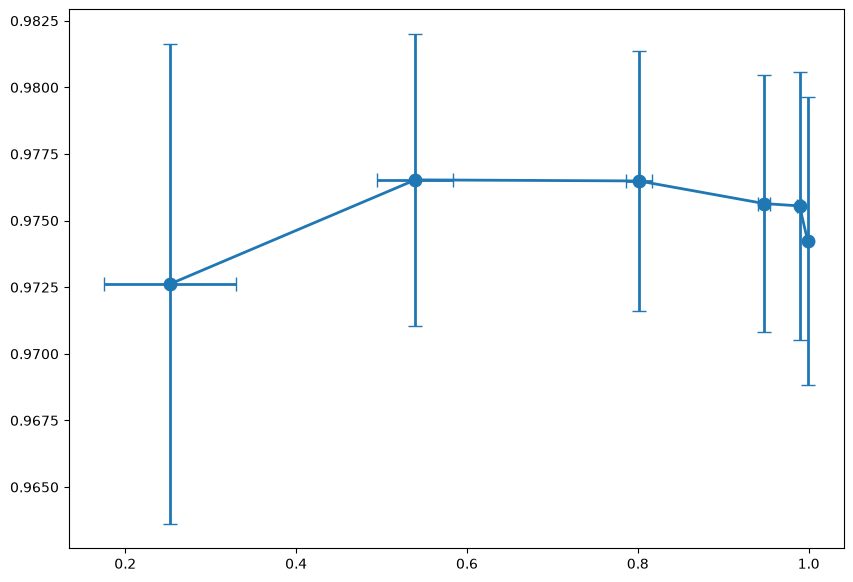

In [ ]:
# =============================================================================
# PLOT 2
# MEAN SCORE VS MEAN ACCEPTANCE RATE FOR EACH BETA
# =============================================================================

fig, ax = plt.subplots(
    figsize=(10, 7)
)


ax.errorbar(
    beta_summary_df[
        "Mean_Acceptance_Rate"
    ],
    beta_summary_df[
        "Mean_Adjusted_Score"
    ],
    xerr=(
        beta_summary_df[
            "Std_Acceptance_Rate"
        ]
    ),
    yerr=(
        beta_summary_df[
            "Std_Adjusted_Score"
        ]
    ),
    marker="o",
    markersize=9,
    linewidth=2,
    capsize=5
)

In [ ]:
# =============================================================================
# LABEL EACH POINT WITH ITS BETA
# =============================================================================

for _, row in (
    beta_summary_df.iterrows()
):

    ax.annotate(
        rf"$\beta={row['Beta']:g}$",
        (
            row[
                "Mean_Acceptance_Rate"
            ],
            row[
                "Mean_Adjusted_Score"
            ]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=11
    )


ax.set_xlabel(
    "Mean Observed M-H Acceptance Rate",
    fontsize=16
)

ax.set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Mean Metropolis-Hastings Score "
    "vs Mean Acceptance Rate\n"
    f"{N_INITIALIZATIONS} Independent "
    "Initializations per "
    r"$\beta$") + "\n" + "Mean of per-run adjusted scores",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    alpha=0.3
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y AXIS
# =============================================================================

mean_lower = (
    beta_summary_df[
        "Mean_Adjusted_Score"
    ]
    -
    beta_summary_df[
        "Std_Adjusted_Score"
    ]
)

mean_upper = (
    beta_summary_df[
        "Mean_Adjusted_Score"
    ]
    +
    beta_summary_df[
        "Std_Adjusted_Score"
    ]
)

mean_min = (
    mean_lower.min()
)

mean_max = (
    mean_upper.max()
)

mean_range = (
    mean_max
    - mean_min
)

mean_padding = (
    0.01
    if mean_range < 1e-12
    else
    0.08 * mean_range
)

ax.set_ylim(
    max(
        0.0,
        mean_min
        - mean_padding
    ),
    min(
        1.0,
        mean_max
        + mean_padding
    )
)


plt.tight_layout()

mean_output_filename = (
    "mh_mean_adjusted_score_vs_"
    "mean_acceptance_rate_e_homo.png"
)

plt.savefig(images_dir /
    mean_output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved mean plot to "
    f"'{mean_output_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PLOT 3
# OPTIONAL: ACCEPTANCE RATE DISTRIBUTION BY BETA
# =============================================================================
#
# This helps you understand how beta maps onto the actually observed
# acceptance behavior.
# =============================================================================

acceptance_distributions = [
    mh_results_df.loc[
        mh_results_df["Beta"]
        == mh_beta,
        "Acceptance Rate"
    ].to_numpy()
    for mh_beta in MH_BETAS
]


fig, ax = plt.subplots(
    figsize=(12, 7)
)

positions = np.arange(
    1,
    len(MH_BETAS) + 1
)

ax.boxplot(
    acceptance_distributions,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 2,
    }
)


jitter_rng = (
    np.random.default_rng(
        12345
    )
)


for position, rates in zip(
    positions,
    acceptance_distributions
):

    horizontal_jitter = (
        jitter_rng.normal(
            loc=0.0,
            scale=0.045,
            size=len(rates)
        )
    )

    ax.scatter(
        position
        + horizontal_jitter,
        rates,
        s=18,
        alpha=0.35
    )


ax.set_xticks(
    positions
)

ax.set_xticklabels([
    rf"$\beta={beta:g}$"
    for beta in MH_BETAS
])

ax.set_xlabel(
    r"Metropolis-Hastings $\beta$",
    fontsize=16
)

ax.set_ylabel(
    "Observed Acceptance Rate",
    fontsize=16
)

ax.set_title(
    "Observed M-H Acceptance "
    "Rate Distribution by "
    r"$\beta$"
    "\n"
    f"{N_INITIALIZATIONS} "
    "Independent Initializations",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

acceptance_output_filename = (
    "mh_acceptance_rate_"
    "distribution_by_beta_e_homo.png"
)

plt.savefig(images_dir /
    acceptance_output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved acceptance-rate plot to "
    f"'{acceptance_output_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# CORRELATION BETWEEN ACCEPTANCE RATE AND SCORE
# =============================================================================

acceptance_score_correlation = (
    mh_results_df[
        [
            "Acceptance Rate",
            "Adjusted Score",
        ]
    ]
    .corr()
    .loc[
        "Acceptance Rate",
        "Adjusted Score"
    ]
)


print(
    "\n"
    + "=" * 90
)

print(
    "ACCEPTANCE RATE / SCORE RELATIONSHIP"
)

print(
    "=" * 90
)

print(
    f"Pearson correlation between "
    f"observed acceptance rate and "
    f"adjusted score: "
    f"{acceptance_score_correlation:.6f}"
)


ACCEPTANCE RATE / SCORE RELATIONSHIP
Pearson correlation between observed acceptance rate and adjusted score: 0.114079


In [ ]:
# =============================================================================
# IDENTIFY BEST MEAN SCORE
# =============================================================================

best_beta_row = (
    beta_summary_df.loc[
        beta_summary_df[
            "Mean_Adjusted_Score"
        ].idxmax()
    ]
)


print(
    "\n"
    + "=" * 90
)

print(
    "BEST BETA BASED ON "
    "MEAN ADJUSTED SCORE"
)

print(
    "=" * 90
)

print(
    f"Beta: "
    f"{best_beta_row['Beta']:g}"
)

print(
    f"Mean acceptance rate: "
    f"{best_beta_row['Mean_Acceptance_Rate']:.6f}"
)

print(
    f"Mean adjusted score: "
    f"{best_beta_row['Mean_Adjusted_Score']:.6f}"
)

print(
    f"Standard deviation: "
    f"{best_beta_row['Std_Adjusted_Score']:.6f}"
)

print(
    f"Best observed score: "
    f"{best_beta_row['Max_Adjusted_Score']:.6f}"
)


BEST BETA BASED ON MEAN ADJUSTED SCORE
Beta: 50
Mean acceptance rate: 0.539503
Mean adjusted score: 0.976529
Standard deviation: 0.005479
Best observed score: 0.982082


In [ ]:
# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

mh_results_export = (
    mh_results_df.drop(
        columns=[
            "Partition",
            "Interpretation",
        ]
    )
)


mh_results_export.to_csv(csv_dir /
    "mh_score_vs_acceptance_rate_"
    "100_initializations_detailed_e_homo.csv",
    index=False
)


beta_summary_df.to_csv(csv_dir /
    "mh_score_vs_acceptance_rate_"
    "100_initializations_summary_e_homo.csv",
    index=False
)


print(
    "\nSaved:"
)

print(
    "  mh_score_vs_acceptance_rate_"
    "100_initializations_detailed_e_homo.csv"
)

print(
    "  mh_score_vs_acceptance_rate_"
    "100_initializations_summary_e_homo.csv"
)
import io
import re
import contextlib

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved:
  mh_score_vs_acceptance_rate_100_initializations_detailed_e_homo.csv
  mh_score_vs_acceptance_rate_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

# Beta is varied internally.
# Observed acceptance rate will be used as the x-axis.
MH_BETAS = (
    0.1,
    1.0,
    5.0,
    20.0,
    50.0,
    100.0,
)

MH_ITERATIONS = 5000
MH_INITIALIZATION = "distance"

N_INITIALIZATIONS = 100

BASE_SEED = 42

INITIALIZATION_SEEDS = [
    BASE_SEED + initialization_index
    for initialization_index
    in range(N_INITIALIZATIONS)
]

In [ ]:
# =============================================================================
# INTERPRETER WITHOUT SINGLE-ATOM CONTRIBUTIONS

In [ ]:
# =============================================================================
#
# IMPORTANT:
#
# This uses the same fitted featurizer and model, but sets the coefficients
# of all graphlet features with bit_size == 1 to zero.
#
# Therefore:
#
#     - single-atom graphlets are still enumerated,
#     - but they contribute 0 to the partition decomposition,
#     - and they do not contribute to the active prediction used here.
#
# =============================================================================

interpreter_no_atoms = PartitionInterpreter(
    featurizer=featurizer,
    model=partition_model,
    remove_single_atom_contributions=True
)

In [ ]:
# =============================================================================
# SELECT MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142

EXPECTED_SMILES = (
    "CC1C2C(CCN12)C=O"
)

test_reset = test.reset_index(
    drop=True
)

if TARGET_TEST_INDEX >= len(test_reset):

    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} "
        "is out of range. "
        f"The reset test set contains "
        f"{len(test_reset)} molecules."
    )


selected_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]


if large_mol is None:

    raise ValueError(
        f"The molecule at test index "
        f"{TARGET_TEST_INDEX} is None."
    )


if large_smiles != EXPECTED_SMILES:

    raise ValueError(
        "Unexpected molecule at test index "
        f"{TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )


if large_mol.GetNumAtoms() < K_TO_PLOT:

    raise ValueError(
        f"The selected molecule has only "
        f"{large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have "
        f"{K_TO_PLOT} nonempty partitions."
    )

In [ ]:
# =============================================================================
# EXPERIMENT INFORMATION
# =============================================================================

print("=" * 90)

print(
    "METROPOLIS-HASTINGS SCORE VS OBSERVED ACCEPTANCE RATE\n"
    "WITHOUT SINGLE-ATOM CONTRIBUTIONS"
)

print("=" * 90)

print(
    f"Test index: {TARGET_TEST_INDEX}"
)

print(
    f"SMILES: {large_smiles}"
)

print(
    f"Total atoms: {large_mol.GetNumAtoms()}"
)

print(
    f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}"
)

print(
    f"k: {K_TO_PLOT}"
)

print(
    f"Connectivity weight lambda: "
    f"{CONNECTIVITY_WEIGHT}"
)

print(
    "Single-atom contributions: REMOVED"
)

print(
    f"Beta values: {list(MH_BETAS)}"
)

print(
    f"Independent initializations per beta: "
    f"{N_INITIALIZATIONS}"
)

print(
    f"Iterations per run: "
    f"{MH_ITERATIONS}"
)

print(
    f"Initialization method: "
    f"{MH_INITIALIZATION}"
)

print(
    f"Total MH runs: "
    f"{len(MH_BETAS) * N_INITIALIZATIONS}"
)

print("=" * 90)

METROPOLIS-HASTINGS SCORE VS OBSERVED ACCEPTANCE RATE
WITHOUT SINGLE-ATOM CONTRIBUTIONS
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
k: 4
Connectivity weight lambda: 0.1
Single-atom contributions: REMOVED
Beta values: [0.1, 1.0, 5.0, 20.0, 50.0, 100.0]
Independent initializations per beta: 100
Iterations per run: 5000
Initialization method: distance
Total MH runs: 600


In [ ]:
# =============================================================================
# EXTRACT ACCEPTANCE RATE FROM EXISTING MH VERBOSE OUTPUT
# =============================================================================

def extract_final_acceptance_rate(
    output_text
):
    """
    Extract the final observed acceptance rate printed by the existing
    optimize_partition_metropolis_hastings() method.

    The MH implementation itself is not modified.
    """

    matches = re.findall(
        r"Acceptance rate:\s*([0-9]*\.?[0-9]+)",
        output_text,
        flags=re.IGNORECASE
    )

    if not matches:

        raise RuntimeError(
            "Could not find the final MH acceptance rate "
            "in verbose output."
        )

    return float(
        matches[-1]
    )

In [ ]:
# =============================================================================
# REGISTER LARGE MOLECULE WITH BUHITO INTERPRETERS
# =============================================================================

# Build the Buhito graph corresponding to large_mol.
#
# Use add_hs=True if large_mol was created with:
#     Chem.MolFromSmiles(...)
#
# Use add_hs=True if large_mol was created with:
#     Chem.AddHs(Chem.MolFromSmiles(...))

large_graph_result = smiles_to_nx(
    large_smiles,
    add_hs=True,
    output_2d_pos=False,
)

large_graph = (
    large_graph_result[0]
    if isinstance(
        large_graph_result,
        (tuple, list)
    )
    else large_graph_result
)


# -----------------------------------------------------------------------------
# Verify RDKit/Buhito atom-index alignment
# -----------------------------------------------------------------------------

expected_nodes = set(
    range(
        large_mol.GetNumAtoms()
    )
)

actual_nodes = {
    int(node)
    for node in large_graph.nodes
}

if actual_nodes != expected_nodes:
    raise RuntimeError(
        "RDKit/Buhito atom-index mismatch for large_mol. "
        f"RDKit atoms={sorted(expected_nodes)}, "
        f"Buhito nodes={sorted(actual_nodes)}"
    )


# -----------------------------------------------------------------------------
# Register with both interpreters
# -----------------------------------------------------------------------------

interpreter_full.register_graph(
    large_mol,
    large_graph
)

interpreter_no_atoms.register_graph(
    large_mol,
    large_graph
)


print(
    "✓ large_mol registered with both Buhito interpreters"
)

# =============================================================================
# RUN EXPERIMENT
# =============================================================================

mh_run_results = []


for mh_beta in MH_BETAS:

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"Beta = {mh_beta:g}"
    )

    print(
        "=" * 80
    )

    beta_scores = []
    beta_acceptance_rates = []

    # =========================================================================
    # IMPORTANT CHANGE:
    #
    # Use interpreter_no_atoms instead of interpreter.
    # =========================================================================

    optimizer_beta = PartitionOptimizer(
        interpreter=interpreter_no_atoms,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=(
            CONNECTIVITY_WEIGHT
        ),
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    # =========================================================================
    # 100 INDEPENDENT INITIALIZATIONS
    # =========================================================================

    for initialization_index, seed in enumerate(
        INITIALIZATION_SEEDS,
        start=1
    ):

        output_buffer = io.StringIO()

        # Capture verbose output so we can extract the final acceptance rate
        # without printing thousands of lines.
        with contextlib.redirect_stdout(
            output_buffer
        ):

            interpretation = (
                optimizer_beta
                .optimize_partition_metropolis_hastings(
                    mol=large_mol,
                    n_clusters=K_TO_PLOT,
                    n_iterations=MH_ITERATIONS,
                    beta=mh_beta,
                    initialization=(
                        MH_INITIALIZATION
                    ),
                    seed=seed,
                    verbose=True
                )
            )

        mh_output = (
            output_buffer.getvalue()
        )

        # =====================================================================
        # OBSERVED ACCEPTANCE RATE
        # =====================================================================

        observed_acceptance_rate = (
            extract_final_acceptance_rate(
                mh_output
            )
        )

        # =====================================================================
        # CHECK PARTITION COUNT
        # =====================================================================

        partition = (
            interpretation.partition
        )

        actual_k = len(
            set(
                partition.values()
            )
        )

        if actual_k != K_TO_PLOT:

            raise RuntimeError(
                f"Beta={mh_beta:g}, "
                f"initialization={initialization_index}, "
                f"seed={seed}: "
                f"requested k={K_TO_PLOT}, "
                f"but MH returned k={actual_k}."
            )

        # =====================================================================
        # CONNECTIVITY PENALTY
        # =====================================================================

        connectivity_penalty = (
            partition_connectivity_penalty(
                mol=large_mol,
                partition=partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # =====================================================================
        # CONNECTIVITY-ADJUSTED SCORE
        # =====================================================================

        adjusted_score = (
            connectivity_adjusted_score(
                mol=large_mol,
                interpretation=(
                    interpretation
                ),
                connectivity_weight=(
                    CONNECTIVITY_WEIGHT
                ),
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # =====================================================================
        # CROSS-PARTITION BONDS
        # =====================================================================

        cross_partition_bonds = [
            bond.GetIdx()
            for bond
            in large_mol.GetBonds()
            if (
                partition[
                    bond.GetBeginAtomIdx()
                ]
                !=
                partition[
                    bond.GetEndAtomIdx()
                ]
            )
        ]

        # =====================================================================
        # STORE RESULT
        # =====================================================================

        mh_run_results.append({
            "Beta": mh_beta,
            "Initialization": (
                initialization_index
            ),
            "Seed": seed,
            "Acceptance Rate": (
                observed_acceptance_rate
            ),
            "Raw Score": (
                interpretation.score
            ),
            "Connectivity Penalty": (
                connectivity_penalty
            ),
            "Adjusted Score": (
                adjusted_score
            ),
            "Cross-Partition Bonds": (
                len(
                    cross_partition_bonds
                )
            ),
            "Actual k": actual_k,
            "Partition": partition,
            "Interpretation": (
                interpretation
            ),
        })

        beta_scores.append(
            adjusted_score
        )

        beta_acceptance_rates.append(
            observed_acceptance_rate
        )

        if (
            initialization_index % 20 == 0
            or
            initialization_index
            == N_INITIALIZATIONS
        ):

            print(
                f"  Completed "
                f"{initialization_index:3d}/"
                f"{N_INITIALIZATIONS} runs"
            )

    # =========================================================================
    # BETA SUMMARY
    # =========================================================================

    beta_scores = np.asarray(
        beta_scores,
        dtype=float
    )

    beta_acceptance_rates = (
        np.asarray(
            beta_acceptance_rates,
            dtype=float
        )
    )

    print(
        f"\n  Beta={mh_beta:g} summary:"
    )

    print(
        f"    Mean acceptance rate: "
        f"{beta_acceptance_rates.mean():.4f}"
    )

    print(
        f"    Std acceptance rate:  "
        f"{beta_acceptance_rates.std(ddof=1):.4f}"
    )

    print(
        f"    Mean adjusted score:  "
        f"{beta_scores.mean():.6f}"
    )

    print(
        f"    Std adjusted score:   "
        f"{beta_scores.std(ddof=1):.6f}"
    )

    print(
        f"    Min adjusted score:   "
        f"{beta_scores.min():.6f}"
    )

    print(
        f"    Max adjusted score:   "
        f"{beta_scores.max():.6f}"
    )

✓ large_mol registered with both Buhito interpreters

Beta = 0.1
  Completed  20/100 runs
  Completed  40/100 runs
  Completed  60/100 runs
  Completed  80/100 runs
  Completed 100/100 runs

  Beta=0.1 summary:
    Mean acceptance rate: 0.9962
    Std acceptance rate:  0.0017
    Mean adjusted score:  0.810157
    Std adjusted score:   0.026950
    Min adjusted score:   0.753141
    Max adjusted score:   0.871956

Beta = 1
  Completed  20/100 runs
  Completed  40/100 runs
  Completed  60/100 runs
  Completed  80/100 runs
  Completed 100/100 runs

  Beta=1 summary:
    Mean acceptance rate: 0.9617
    Std acceptance rate:  0.0058
    Mean adjusted score:  0.812521
    Std adjusted score:   0.027586
    Min adjusted score:   0.756151
    Max adjusted score:   0.876986

Beta = 5
  Completed  20/100 runs
  Completed  40/100 runs
  Completed  60/100 runs
  Completed  80/100 runs
  Completed 100/100 runs

  Beta=5 summary:
    Mean acceptance rate: 0.8013
    Std acceptance rate:  0.0209
   

In [ ]:
# =============================================================================
# CONVERT TO DATAFRAME
# =============================================================================

mh_results_df = pd.DataFrame(
    mh_run_results
)

In [ ]:
# =============================================================================
# SUMMARY BY BETA
# =============================================================================

beta_summary_df = (
    mh_results_df
    .groupby(
        "Beta",
        as_index=False
    )
    .agg(
        N=(
            "Adjusted Score",
            "count"
        ),
        Mean_Acceptance_Rate=(
            "Acceptance Rate",
            "mean"
        ),
        Std_Acceptance_Rate=(
            "Acceptance Rate",
            "std"
        ),
        Min_Acceptance_Rate=(
            "Acceptance Rate",
            "min"
        ),
        Max_Acceptance_Rate=(
            "Acceptance Rate",
            "max"
        ),
        Mean_Adjusted_Score=(
            "Adjusted Score",
            "mean"
        ),
        Std_Adjusted_Score=(
            "Adjusted Score",
            "std"
        ),
        Median_Adjusted_Score=(
            "Adjusted Score",
            "median"
        ),
        Min_Adjusted_Score=(
            "Adjusted Score",
            "min"
        ),
        Max_Adjusted_Score=(
            "Adjusted Score",
            "max"
        ),
        Mean_Raw_Score=(
            "Raw Score",
            "mean"
        ),
        Mean_Connectivity_Penalty=(
            "Connectivity Penalty",
            "mean"
        )
    )
)


print(
    "\n"
    + "=" * 120
)

print(
    "SUMMARY BY BETA — "
    "WITHOUT SINGLE-ATOM CONTRIBUTIONS"
)

print(
    "=" * 120
)

print(
    beta_summary_df.to_string(
        index=False,
        float_format=(
            lambda value:
            f"{value:.6f}"
        )
    )
)


SUMMARY BY BETA — WITHOUT SINGLE-ATOM CONTRIBUTIONS
      Beta   N  Mean_Acceptance_Rate  Std_Acceptance_Rate  Min_Acceptance_Rate  Max_Acceptance_Rate  Mean_Adjusted_Score  Std_Adjusted_Score  Median_Adjusted_Score  Min_Adjusted_Score  Max_Adjusted_Score  Mean_Raw_Score  Mean_Connectivity_Penalty
  0.100000 100              0.996250             0.001654             0.992400             0.999300             0.810157            0.026950               0.810009            0.753141            0.871956        0.828757                   0.186000
  1.000000 100              0.961722             0.005825             0.943400             0.975600             0.812521            0.027586               0.806754            0.756151            0.876986        0.830271                   0.177500
  5.000000 100              0.801294             0.020854             0.723400             0.840000             0.821926            0.025719               0.819974            0.772572            0.876986   

In [ ]:
# =============================================================================
# PLOT 1
# ALL RUNS: SCORE VS OBSERVED ACCEPTANCE RATE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(11, 7)
)


for mh_beta in MH_BETAS:

    beta_data = (
        mh_results_df[
            mh_results_df["Beta"]
            == mh_beta
        ]
    )

    ax.scatter(
        beta_data[
            "Acceptance Rate"
        ],
        beta_data[
            "Adjusted Score"
        ],
        s=35,
        alpha=0.55,
        label=rf"$\beta={mh_beta:g}$"
    )


ax.set_xlabel(
    "Observed M-H Acceptance Rate",
    fontsize=16
)

ax.set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Metropolis-Hastings Score vs Observed Acceptance Rate\n"
    "Without Single-Atom Contributions | "
    f"{N_INITIALIZATIONS} Initializations per "
    r"$\beta$") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    alpha=0.3
)

ax.legend(
    title=r"$\beta$",
    fontsize=11,
    title_fontsize=12
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y AXIS
# =============================================================================

all_adjusted_scores = (
    mh_results_df[
        "Adjusted Score"
    ].to_numpy()
)

score_min = (
    all_adjusted_scores.min()
)

score_max = (
    all_adjusted_scores.max()
)

score_range = (
    score_max
    - score_min
)

if score_range < 1e-12:

    score_padding = 0.01

else:

    score_padding = (
        0.08
        * score_range
    )


ax.set_ylim(
    max(
        0.0,
        score_min
        - score_padding
    ),
    min(
        1.0,
        score_max
        + score_padding
    )
)


plt.tight_layout()

output_filename = (
    "mh_no_single_atoms_"
    "adjusted_score_vs_"
    "observed_acceptance_rate_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved scatter plot to "
    f"'{output_filename}'"
)

plt.show()

<ErrorbarContainer object of 3 artists>

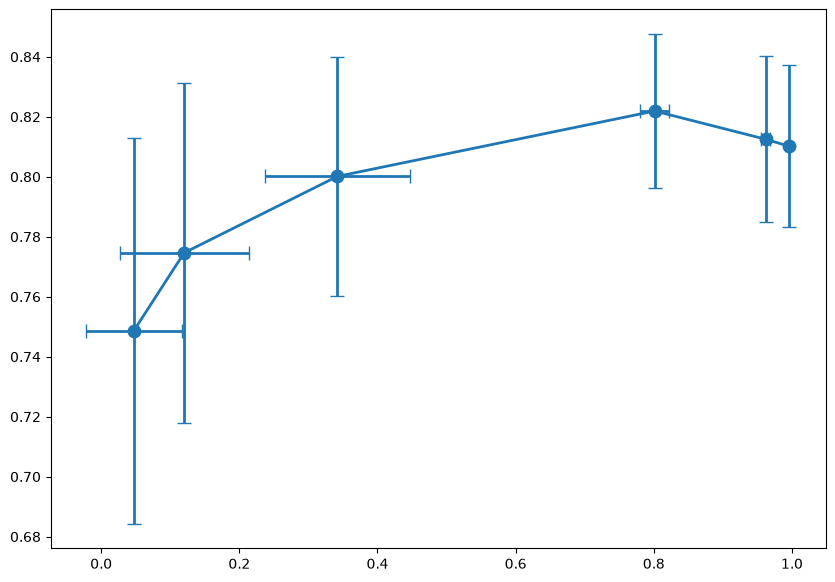

In [ ]:
# =============================================================================
# PLOT 2
# MEAN SCORE VS MEAN ACCEPTANCE RATE
# =============================================================================

fig, ax = plt.subplots(
    figsize=(10, 7)
)


ax.errorbar(
    beta_summary_df[
        "Mean_Acceptance_Rate"
    ],
    beta_summary_df[
        "Mean_Adjusted_Score"
    ],
    xerr=(
        beta_summary_df[
            "Std_Acceptance_Rate"
        ]
    ),
    yerr=(
        beta_summary_df[
            "Std_Adjusted_Score"
        ]
    ),
    marker="o",
    markersize=9,
    linewidth=2,
    capsize=5
)

In [ ]:
# =============================================================================
# LABEL EACH POINT WITH BETA
# =============================================================================

for _, row in (
    beta_summary_df.iterrows()
):

    ax.annotate(
        rf"$\beta={row['Beta']:g}$",
        (
            row[
                "Mean_Acceptance_Rate"
            ],
            row[
                "Mean_Adjusted_Score"
            ]
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=11
    )


ax.set_xlabel(
    "Mean Observed M-H Acceptance Rate",
    fontsize=16
)

ax.set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Mean M-H Score vs Mean Acceptance Rate\n"
    "Without Single-Atom Contributions | "
    f"{N_INITIALIZATIONS} Initializations per "
    r"$\beta$") + "\n" + "Mean of per-run adjusted scores",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    alpha=0.3
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y AXIS
# =============================================================================

mean_lower = (
    beta_summary_df[
        "Mean_Adjusted_Score"
    ]
    -
    beta_summary_df[
        "Std_Adjusted_Score"
    ]
)

mean_upper = (
    beta_summary_df[
        "Mean_Adjusted_Score"
    ]
    +
    beta_summary_df[
        "Std_Adjusted_Score"
    ]
)

mean_min = (
    mean_lower.min()
)

mean_max = (
    mean_upper.max()
)

mean_range = (
    mean_max
    - mean_min
)

mean_padding = (
    0.01
    if mean_range < 1e-12
    else
    0.08 * mean_range
)

ax.set_ylim(
    max(
        0.0,
        mean_min
        - mean_padding
    ),
    min(
        1.0,
        mean_max
        + mean_padding
    )
)


plt.tight_layout()

mean_output_filename = (
    "mh_no_single_atoms_"
    "mean_adjusted_score_vs_"
    "mean_acceptance_rate_e_homo.png"
)

plt.savefig(images_dir /
    mean_output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved mean plot to "
    f"'{mean_output_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PLOT 3
# ACCEPTANCE-RATE DISTRIBUTION BY BETA
# =============================================================================

acceptance_distributions = [
    mh_results_df.loc[
        mh_results_df["Beta"]
        == mh_beta,
        "Acceptance Rate"
    ].to_numpy()
    for mh_beta in MH_BETAS
]


fig, ax = plt.subplots(
    figsize=(13, 7)
)

positions = np.arange(
    1,
    len(MH_BETAS) + 1
)

ax.boxplot(
    acceptance_distributions,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 2,
    }
)


jitter_rng = np.random.default_rng(
    12345
)


for position, rates in zip(
    positions,
    acceptance_distributions
):

    horizontal_jitter = (
        jitter_rng.normal(
            loc=0.0,
            scale=0.045,
            size=len(rates)
        )
    )

    ax.scatter(
        position
        + horizontal_jitter,
        rates,
        s=18,
        alpha=0.35
    )


ax.set_xticks(
    positions
)

ax.set_xticklabels([
    rf"$\beta={beta:g}$"
    for beta in MH_BETAS
])

ax.set_xlabel(
    r"Metropolis-Hastings $\beta$",
    fontsize=16
)

ax.set_ylabel(
    "Observed Acceptance Rate",
    fontsize=16
)

ax.set_title(
    "Observed M-H Acceptance Rate Distribution by "
    r"$\beta$"
    "\nWithout Single-Atom Contributions | "
    f"{N_INITIALIZATIONS} Independent Initializations",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

acceptance_output_filename = (
    "mh_no_single_atoms_"
    "acceptance_rate_distribution_by_beta_e_homo.png"
)

plt.savefig(images_dir /
    acceptance_output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved acceptance-rate plot to "
    f"'{acceptance_output_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# CORRELATION
# =============================================================================

acceptance_score_correlation = (
    mh_results_df[
        [
            "Acceptance Rate",
            "Adjusted Score",
        ]
    ]
    .corr()
    .loc[
        "Acceptance Rate",
        "Adjusted Score"
    ]
)


print(
    "\n"
    + "=" * 90
)

print(
    "ACCEPTANCE RATE / SCORE RELATIONSHIP"
)

print(
    "WITHOUT SINGLE-ATOM CONTRIBUTIONS"
)

print(
    "=" * 90
)

print(
    f"Pearson correlation between "
    f"observed acceptance rate and "
    f"adjusted score: "
    f"{acceptance_score_correlation:.6f}"
)


ACCEPTANCE RATE / SCORE RELATIONSHIP
WITHOUT SINGLE-ATOM CONTRIBUTIONS
Pearson correlation between observed acceptance rate and adjusted score: 0.447642


In [ ]:
# =============================================================================
# BEST BETA
# =============================================================================

best_beta_row = (
    beta_summary_df.loc[
        beta_summary_df[
            "Mean_Adjusted_Score"
        ].idxmax()
    ]
)


print(
    "\n"
    + "=" * 90
)

print(
    "BEST BETA BASED ON MEAN ADJUSTED SCORE"
)

print(
    "WITHOUT SINGLE-ATOM CONTRIBUTIONS"
)

print(
    "=" * 90
)

print(
    f"Beta: "
    f"{best_beta_row['Beta']:g}"
)

print(
    f"Mean acceptance rate: "
    f"{best_beta_row['Mean_Acceptance_Rate']:.6f}"
)

print(
    f"Mean adjusted score: "
    f"{best_beta_row['Mean_Adjusted_Score']:.6f}"
)

print(
    f"Standard deviation: "
    f"{best_beta_row['Std_Adjusted_Score']:.6f}"
)

print(
    f"Best observed score: "
    f"{best_beta_row['Max_Adjusted_Score']:.6f}"
)


BEST BETA BASED ON MEAN ADJUSTED SCORE
WITHOUT SINGLE-ATOM CONTRIBUTIONS
Beta: 5
Mean acceptance rate: 0.801294
Mean adjusted score: 0.821926
Standard deviation: 0.025719
Best observed score: 0.876986


In [ ]:
# =============================================================================
# SAVE RESULTS
# =============================================================================

mh_results_export = (
    mh_results_df.drop(
        columns=[
            "Partition",
            "Interpretation",
        ]
    )
)


mh_results_export.to_csv(csv_dir /
    "mh_no_single_atoms_"
    "score_vs_acceptance_rate_"
    "100_initializations_detailed_e_homo.csv",
    index=False
)


beta_summary_df.to_csv(csv_dir /
    "mh_no_single_atoms_"
    "score_vs_acceptance_rate_"
    "100_initializations_summary_e_homo.csv",
    index=False
)


print(
    "\nSaved:"
)

print(
    "  mh_no_single_atoms_"
    "score_vs_acceptance_rate_"
    "100_initializations_detailed_e_homo.csv"
)

print(
    "  mh_no_single_atoms_"
    "score_vs_acceptance_rate_"
    "100_initializations_summary_e_homo.csv"
)
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved:
  mh_no_single_atoms_score_vs_acceptance_rate_100_initializations_detailed_e_homo.csv
  mh_no_single_atoms_score_vs_acceptance_rate_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

# Keep lambda / connectivity weight FIXED.
CONNECTIVITY_WEIGHT = 0.10

DISCONNECTED_SINGLETON_WEIGHT = 2.0

# Vary the Metropolis-Hastings acceptance parameter beta.
MH_BETAS = (
    0.1,
    1.0,
    5.0,
    20.0,
    50.0,
)

MH_ITERATIONS = 5000
MH_INITIALIZATION = "distance"
MH_SEED = 42

In [ ]:
# =============================================================================
# PARTITION COLORS
# =============================================================================

PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# SELECT THE SPECIFIC TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142
EXPECTED_SMILES = "CC1C2C(CCN12)C=O"

test_reset = test.reset_index(drop=True)

if TARGET_TEST_INDEX >= len(test_reset):
    raise IndexError(
        f"Test index {TARGET_TEST_INDEX} is out of range. "
        f"The reset test set contains {len(test_reset)} molecules."
    )

selected_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

large_mol = selected_row["mol"]
large_smiles = selected_row["smiles"]
large_size_label = "Selected Large Molecule"

if large_mol is None:
    raise ValueError(
        f"The molecule at test index {TARGET_TEST_INDEX} is None."
    )

# Confirm that the selected row is the intended molecule.
if large_smiles != EXPECTED_SMILES:
    raise ValueError(
        f"Unexpected molecule at test index {TARGET_TEST_INDEX}.\n"
        f"Expected SMILES: {EXPECTED_SMILES}\n"
        f"Found SMILES:    {large_smiles}"
    )

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_PLOT} nonempty partitions."
    )


print("=" * 80)
print("SELECTED TEST MOLECULE")
print("=" * 80)
print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {large_smiles}")
print(f"Total atoms: {large_mol.GetNumAtoms()}")
print(f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print(f"MH beta values: {list(MH_BETAS)}")
print(f"MH iterations per beta: {MH_ITERATIONS}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"MH seed: {MH_SEED}")
print("=" * 80)

SELECTED TEST MOLECULE
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
Requested partitions: k=4
Connectivity weight: 0.1
MH beta values: [0.1, 1.0, 5.0, 20.0, 50.0]
MH iterations per beta: 5000
MH initialization: distance
MH seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition.

    Bonds contained within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# RUN 100 INDEPENDENT METROPOLIS-HASTINGS INITIALIZATIONS FOR EACH BETA
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# -----------------------------------------------------------------------------
# SETTINGS
# -----------------------------------------------------------------------------

N_INITIALIZATIONS = 100

# Starting seed used to generate the 100 independent runs.
BASE_SEED = 42

# Generate 100 different reproducible seeds.
INITIALIZATION_SEEDS = [
    BASE_SEED + initialization_index
    for initialization_index in range(N_INITIALIZATIONS)
]


print("=" * 80)
print("METROPOLIS-HASTINGS BETA DISTRIBUTION EXPERIMENT")
print("=" * 80)

print(
    f"Number of beta values: "
    f"{len(MH_BETAS)}"
)

print(
    f"Independent initializations per beta: "
    f"{N_INITIALIZATIONS}"
)

print(
    f"MH iterations per initialization: "
    f"{MH_ITERATIONS}"
)

print(
    f"Total MH runs: "
    f"{len(MH_BETAS) * N_INITIALIZATIONS}"
)

print(
    f"k = {K_TO_PLOT}"
)

print(
    f"Connectivity weight lambda = "
    f"{CONNECTIVITY_WEIGHT}"
)

print("=" * 80)

METROPOLIS-HASTINGS BETA DISTRIBUTION EXPERIMENT
Number of beta values: 5
Independent initializations per beta: 100
MH iterations per initialization: 5000
Total MH runs: 500
k = 4
Connectivity weight lambda = 0.1


In [ ]:
# =============================================================================
# STORE RESULTS
# =============================================================================

beta_run_results = []

In [ ]:
# =============================================================================
# RUN EXPERIMENT
# =============================================================================

for beta_index, mh_beta in enumerate(MH_BETAS):

    print(
        f"\n{'=' * 80}"
    )

    print(
        f"Beta = {mh_beta:g}"
    )

    print(
        f"{'=' * 80}"
    )

    beta_scores = []

    # -------------------------------------------------------------------------
    # Optimizer settings remain identical for all 100 runs.
    # -------------------------------------------------------------------------

    optimizer_beta = PartitionOptimizer(
        interpreter=interpreter_no_atoms,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    # -------------------------------------------------------------------------
    # 100 independent initializations
    # -------------------------------------------------------------------------

    for initialization_index, seed in enumerate(
        INITIALIZATION_SEEDS,
        start=1
    ):

        # ---------------------------------------------------------------------
        # Run Metropolis-Hastings.
        #
        # Because the seed changes on every run:
        #
        #   1. distance initialization can select different seed atoms;
        #   2. the MH proposal sequence changes;
        #   3. the MH random accept/reject draws change.
        #
        # Thus each run is an independent stochastic search.
        # ---------------------------------------------------------------------

        interpretation = (
            optimizer_beta
            .optimize_partition_metropolis_hastings(
                mol=large_mol,
                n_clusters=K_TO_PLOT,
                n_iterations=MH_ITERATIONS,
                beta=mh_beta,
                initialization=MH_INITIALIZATION,
                seed=seed,
                verbose=False
            )
        )

        partition = (
            interpretation.partition
        )

        actual_k = len(
            set(
                partition.values()
            )
        )

        # ---------------------------------------------------------------------
        # Verify that exactly four partitions remain.
        # ---------------------------------------------------------------------

        if actual_k != K_TO_PLOT:

            raise RuntimeError(
                f"Beta={mh_beta:g}, "
                f"initialization={initialization_index}, "
                f"seed={seed}: "
                f"requested k={K_TO_PLOT}, "
                f"but MH returned k={actual_k}."
            )

        # ---------------------------------------------------------------------
        # Connectivity penalty
        # ---------------------------------------------------------------------

        connectivity_penalty = (
            partition_connectivity_penalty(
                mol=large_mol,
                partition=partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # ---------------------------------------------------------------------
        # Connectivity-adjusted score
        #
        # beta does NOT appear in this formula.
        #
        # beta affects which partitions MH explores and accepts.
        # lambda remains fixed at CONNECTIVITY_WEIGHT.
        # ---------------------------------------------------------------------

        adjusted_score = (
            connectivity_adjusted_score(
                mol=large_mol,
                interpretation=interpretation,
                connectivity_weight=(
                    CONNECTIVITY_WEIGHT
                ),
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        # ---------------------------------------------------------------------
        # Count partition-boundary bonds.
        # ---------------------------------------------------------------------

        cross_partition_bonds = [
            bond.GetIdx()
            for bond in large_mol.GetBonds()
            if (
                partition[
                    bond.GetBeginAtomIdx()
                ]
                !=
                partition[
                    bond.GetEndAtomIdx()
                ]
            )
        ]

        # ---------------------------------------------------------------------
        # Store this independent run.
        # ---------------------------------------------------------------------

        beta_run_results.append({
            "Beta": mh_beta,
            "Initialization": initialization_index,
            "Seed": seed,
            "Raw Score": interpretation.score,
            "Connectivity Penalty": (
                connectivity_penalty
            ),
            "Adjusted Score": (
                adjusted_score
            ),
            "Cross-Partition Bonds": (
                len(cross_partition_bonds)
            ),
            "Actual k": actual_k,
            "Partition": partition,
            "Interpretation": interpretation,
        })

        beta_scores.append(
            adjusted_score
        )

        # ---------------------------------------------------------------------
        # Progress output every 20 runs.
        # ---------------------------------------------------------------------

        if (
            initialization_index % 20 == 0
            or initialization_index
            == N_INITIALIZATIONS
        ):

            print(
                f"  Completed "
                f"{initialization_index:3d}/"
                f"{N_INITIALIZATIONS} "
                f"initializations"
            )

    # -------------------------------------------------------------------------
    # Summary for this beta.
    # -------------------------------------------------------------------------

    beta_scores = np.asarray(
        beta_scores
    )

    print(
        f"\n  Beta={mh_beta:g} summary:"
    )

    print(
        f"    Mean adjusted score: "
        f"{beta_scores.mean():.6f}"
    )

    print(
        f"    Std:                 "
        f"{beta_scores.std(ddof=1):.6f}"
    )

    print(
        f"    Median:              "
        f"{np.median(beta_scores):.6f}"
    )

    print(
        f"    Min:                 "
        f"{beta_scores.min():.6f}"
    )

    print(
        f"    Max:                 "
        f"{beta_scores.max():.6f}"
    )


Beta = 0.1
  Completed  20/100 initializations
  Completed  40/100 initializations
  Completed  60/100 initializations
  Completed  80/100 initializations
  Completed 100/100 initializations

  Beta=0.1 summary:
    Mean adjusted score: 0.810157
    Std:                 0.026950
    Median:              0.810009
    Min:                 0.753141
    Max:                 0.871956

Beta = 1
  Completed  20/100 initializations
  Completed  40/100 initializations
  Completed  60/100 initializations
  Completed  80/100 initializations
  Completed 100/100 initializations

  Beta=1 summary:
    Mean adjusted score: 0.812521
    Std:                 0.027586
    Median:              0.806754
    Min:                 0.756151
    Max:                 0.876986

Beta = 5
  Completed  20/100 initializations
  Completed  40/100 initializations
  Completed  60/100 initializations
  Completed  80/100 initializations
  Completed 100/100 initializations

  Beta=5 summary:
    Mean adjusted score: 0.82

In [ ]:
# =============================================================================
# CONVERT RESULTS TO DATAFRAME
# =============================================================================

beta_results_df = pd.DataFrame(
    beta_run_results
)

In [ ]:
# =============================================================================
# CREATE SUMMARY TABLE
# =============================================================================

beta_summary_df = (
    beta_results_df
    .groupby(
        "Beta",
        as_index=False
    )
    .agg(
        N=(
            "Adjusted Score",
            "count"
        ),
        Mean_Adjusted_Score=(
            "Adjusted Score",
            "mean"
        ),
        Std_Adjusted_Score=(
            "Adjusted Score",
            "std"
        ),
        Median_Adjusted_Score=(
            "Adjusted Score",
            "median"
        ),
        Min_Adjusted_Score=(
            "Adjusted Score",
            "min"
        ),
        Max_Adjusted_Score=(
            "Adjusted Score",
            "max"
        ),
        Mean_Raw_Score=(
            "Raw Score",
            "mean"
        ),
        Mean_Connectivity_Penalty=(
            "Connectivity Penalty",
            "mean"
        )
    )
)


print(
    "\n"
    + "=" * 100
)

print(
    "METROPOLIS-HASTINGS SCORE DISTRIBUTION BY BETA"
)

print(
    "=" * 100
)

print(
    beta_summary_df.to_string(
        index=False,
        float_format=(
            lambda value:
            f"{value:.6f}"
        )
    )
)


METROPOLIS-HASTINGS SCORE DISTRIBUTION BY BETA
     Beta   N  Mean_Adjusted_Score  Std_Adjusted_Score  Median_Adjusted_Score  Min_Adjusted_Score  Max_Adjusted_Score  Mean_Raw_Score  Mean_Connectivity_Penalty
 0.100000 100             0.810157            0.026950               0.810009            0.753141            0.871956        0.828757                   0.186000
 1.000000 100             0.812521            0.027586               0.806754            0.756151            0.876986        0.830271                   0.177500
 5.000000 100             0.821926            0.025719               0.819974            0.772572            0.876986        0.842226                   0.203000
20.000000 100             0.800129            0.039874               0.795105            0.713652            0.871956        0.811879                   0.117500
50.000000 100             0.774638            0.056644               0.771982            0.564583            0.871956        0.783538              

In [ ]:
# =============================================================================
# PREPARE SCORE DISTRIBUTIONS
# =============================================================================

score_distributions = []

for mh_beta in MH_BETAS:

    scores = (
        beta_results_df.loc[
            beta_results_df["Beta"]
            == mh_beta,
            "Adjusted Score"
        ]
        .to_numpy()
    )

    score_distributions.append(
        scores
    )

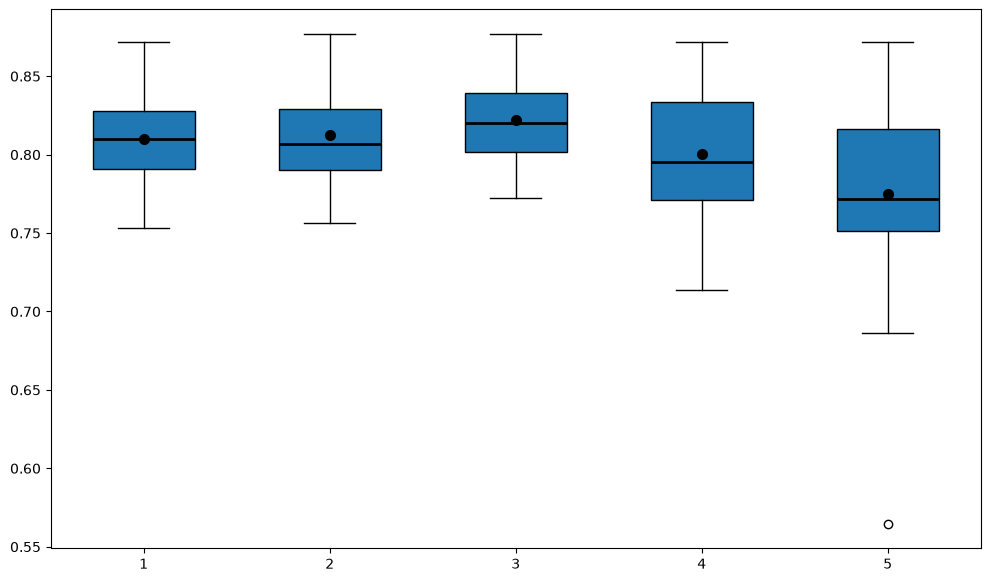

In [ ]:
# =============================================================================
# PLOT 1: BOX PLOT OF ADJUSTED SCORE DISTRIBUTIONS
# =============================================================================

fig, ax = plt.subplots(
    figsize=(12, 7)
)

positions = np.arange(
    1,
    len(MH_BETAS) + 1
)


boxplot = ax.boxplot(
    score_distributions,
    positions=positions,
    widths=0.55,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 2,
    }
)

In [ ]:
# =============================================================================
# ADD ALL 100 INDIVIDUAL RESULTS
# =============================================================================
#
# A small horizontal jitter is added only for visualization.
# It does not change any data values.
# =============================================================================

jitter_rng = np.random.default_rng(
    12345
)

for position, scores in zip(
    positions,
    score_distributions
):

    horizontal_jitter = (
        jitter_rng.normal(
            loc=0.0,
            scale=0.045,
            size=len(scores)
        )
    )

    ax.scatter(
        position
        + horizontal_jitter,
        scores,
        s=18,
        alpha=0.35
    )

In [ ]:
# =============================================================================
# FORMAT BOX PLOT
# =============================================================================

ax.set_xticks(
    positions
)

ax.set_xticklabels([
    rf"$\beta={beta:g}$"
    for beta in MH_BETAS
])

ax.set_xlabel(
    r"Metropolis-Hastings Acceptance Parameter $\beta$",
    fontsize=16
)

ax.set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Metropolis-Hastings Score Distribution\n"
    f"{N_INITIALIZATIONS} Independent Initializations per "
    r"$\beta$") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    axis="y",
    alpha=0.3
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y AXIS
# =============================================================================
#
# Zoom the y-axis to make differences between beta values easier to see.
# =============================================================================

all_adjusted_scores = (
    beta_results_df[
        "Adjusted Score"
    ]
    .to_numpy()
)

score_min = (
    all_adjusted_scores.min()
)

score_max = (
    all_adjusted_scores.max()
)

score_range = (
    score_max - score_min
)

if score_range < 1e-12:

    score_padding = 0.01

else:

    score_padding = (
        0.08 * score_range
    )

ax.set_ylim(
    max(
        0.0,
        score_min
        - score_padding
    ),
    min(
        1.0,
        score_max
        + score_padding
    )
)


plt.tight_layout()

output_filename = (
    "mh_beta_adjusted_score_"
    "distribution_100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved score distribution plot to "
    f"'{output_filename}'"
)

plt.show()


# =============================================================================
# PLOT 2: MEAN SCORE +/- STANDARD DEVIATION
# =============================================================================

beta_means = np.asarray([
    scores.mean()
    for scores in score_distributions
])

beta_stds = np.asarray([
    scores.std(
        ddof=1
    )
    for scores in score_distributions
])


fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.errorbar(
    MH_BETAS,
    beta_means,
    yerr=beta_stds,
    marker="o",
    markersize=9,
    linewidth=2,
    capsize=6
)

ax.set_xscale(
    "log"
)

ax.set_xlabel(
    r"Metropolis-Hastings Acceptance Parameter $\beta$",
    fontsize=16
)

ax.set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=16
)

ax.set_title(
    ("Mean Metropolis-Hastings Score vs "
    r"$\beta$"
    "\n"
    f"{N_INITIALIZATIONS} Independent Initializations") + "\n" + "Mean adjusted score; error bars = ±1 SD across runs",
    fontsize=18,
    fontweight="bold"
)

ax.tick_params(
    axis="both",
    labelsize=13
)

ax.grid(
    alpha=0.3
)


mean_min = min(
    beta_means
    - beta_stds
)

mean_max = max(
    beta_means
    + beta_stds
)

mean_range = (
    mean_max
    - mean_min
)

mean_padding = (
    0.01
    if mean_range < 1e-12
    else 0.08 * mean_range
)

ax.set_ylim(
    max(
        0.0,
        mean_min
        - mean_padding
    ),
    min(
        1.0,
        mean_max
        + mean_padding
    )
)


plt.tight_layout()

mean_output_filename = (
    "mh_beta_mean_adjusted_score_"
    "100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    mean_output_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved mean-score plot to "
    f"'{mean_output_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# IDENTIFY BEST BETA
# =============================================================================

best_beta_row = (
    beta_summary_df.loc[
        beta_summary_df[
            "Mean_Adjusted_Score"
        ].idxmax()
    ]
)

best_beta = (
    best_beta_row["Beta"]
)

print(
    "\n"
    + "=" * 80
)

print(
    "BEST BETA BASED ON MEAN ADJUSTED SCORE"
)

print(
    "=" * 80
)

print(
    f"Beta: "
    f"{best_beta:g}"
)

print(
    f"Mean adjusted score: "
    f"{best_beta_row['Mean_Adjusted_Score']:.6f}"
)

print(
    f"Standard deviation: "
    f"{best_beta_row['Std_Adjusted_Score']:.6f}"
)

print(
    f"Best observed score: "
    f"{best_beta_row['Max_Adjusted_Score']:.6f}"
)


BEST BETA BASED ON MEAN ADJUSTED SCORE
Beta: 5
Mean adjusted score: 0.821926
Standard deviation: 0.025719
Best observed score: 0.876986


In [ ]:
# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

# Remove the object-heavy columns before exporting the detailed CSV.
beta_results_export = (
    beta_results_df.drop(
        columns=[
            "Partition",
            "Interpretation",
        ]
    )
)

beta_results_export.to_csv(csv_dir /
    "mh_beta_100_initializations_detailed_e_homo.csv",
    index=False
)

beta_summary_df.to_csv(csv_dir /
    "mh_beta_100_initializations_summary_e_homo.csv",
    index=False
)

print(
    "\nSaved:"
)

print(
    "  mh_beta_100_initializations_detailed_e_homo.csv"
)

print(
    "  mh_beta_100_initializations_summary_e_homo.csv"
)
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image
from matplotlib.patches import Patch

import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from partition_interpretability import (
    PartitionOptimizer,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved:
  mh_beta_100_initializations_detailed_e_homo.csv
  mh_beta_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_PLOT = 4

SCORE_LAMBDAS = (
    0.01,
    0.10,
    0.50,
    1.00,
    1.50,
)

N_INITIALIZATIONS = 100

DISCONNECTED_SINGLETON_WEIGHT = 2.0

MH_ITERATIONS = 5000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"

BASE_SEED = 42


PARTITION_COLORS = {
    0: (0.35, 0.55, 1.00),  # Blue
    1: (1.00, 0.35, 0.35),  # Red
    2: (0.35, 0.80, 0.45),  # Green
    3: (0.80, 0.55, 1.00),  # Purple
}

In [ ]:
# =============================================================================
# SELECT THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule labeled 'Large' was found in selected_mols."
    )

large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < K_TO_PLOT:
    raise ValueError(
        f"The large molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_PLOT} nonempty partitions."
    )


print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Requested partitions: k={K_TO_PLOT}")
print(f"Lambda values: {list(SCORE_LAMBDAS)}")
print(f"Initializations per lambda: {N_INITIALIZATIONS}")
print(f"MH iterations per initialization: {MH_ITERATIONS}")
print(f"MH beta: {MH_BETA}")
print(f"MH initialization: {MH_INITIALIZATION}")
print(f"Base seed: {BASE_SEED}")
print("=" * 80)

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Requested partitions: k=4
Lambda values: [0.01, 0.1, 0.5, 1.0, 1.5]
Initializations per lambda: 100
MH iterations per initialization: 5000
MH beta: 20.0
MH initialization: distance
Base seed: 42


In [ ]:
# =============================================================================
# DRAW ONE PARTITIONED MOLECULE
# =============================================================================

def mol_to_partition_image(
    mol,
    partition,
    img_size=(650, 650)
):
    """
    Draw a molecule with atoms colored by partition membership.

    Bonds contained within one partition use that partition's color.
    Bonds crossing partition boundaries are gray.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1]
    )

    options = drawer.drawOptions()
    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    highlighted_atoms = []
    atom_colors = {}

    for atom_idx, partition_id in partition.items():
        atom_idx = int(atom_idx)
        partition_id = int(partition_id)

        highlighted_atoms.append(atom_idx)

        atom_colors[atom_idx] = PARTITION_COLORS.get(
            partition_id,
            (0.75, 0.75, 0.75)
        )

    highlighted_bonds = []
    bond_colors = {}

    for bond in mol.GetBonds():
        bond_idx = bond.GetIdx()
        atom_1 = bond.GetBeginAtomIdx()
        atom_2 = bond.GetEndAtomIdx()

        partition_1 = partition[atom_1]
        partition_2 = partition[atom_2]

        highlighted_bonds.append(bond_idx)

        if partition_1 == partition_2:
            bond_colors[bond_idx] = PARTITION_COLORS.get(
                partition_1,
                (0.75, 0.75, 0.75)
            )
        else:
            bond_colors[bond_idx] = (
                0.60,
                0.60,
                0.60
            )

    drawer.DrawMolecule(
        mol,
        highlightAtoms=highlighted_atoms,
        highlightAtomColors=atom_colors,
        highlightBonds=highlighted_bonds,
        highlightBondColors=bond_colors
    )

    drawer.FinishDrawing()

    return Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

In [ ]:
# =============================================================================
# RUN 100 METROPOLIS-HASTINGS INITIALIZATIONS FOR EACH LAMBDA
# =============================================================================

lambda_results = []

# Store the best result found for each lambda.
best_results_by_lambda = {}

for lambda_index, score_lambda in enumerate(SCORE_LAMBDAS):

    print(
        f"\nRunning Metropolis-Hastings with "
        f"k={K_TO_PLOT}, lambda={score_lambda:g}..."
    )

    # Lambda is part of the optimization objective, so every lambda
    # requires a separate optimizer.
    optimizer_lambda = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_PLOT,
        max_partitions=K_TO_PLOT,
        connectivity_weight=score_lambda,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        )
    )

    best_result = None
    best_adjusted_score = -np.inf

    for initialization_index in range(N_INITIALIZATIONS):

        # Use a distinct deterministic seed for each lambda/run pair.
        run_seed = (
            BASE_SEED
            + 100_000 * lambda_index
            + initialization_index
        )

        interpretation = (
            optimizer_lambda
            .optimize_partition_metropolis_hastings(
                mol=large_mol,
                n_clusters=K_TO_PLOT,
                n_iterations=MH_ITERATIONS,
                beta=MH_BETA,
                initialization=MH_INITIALIZATION,
                seed=run_seed,
                verbose=False
            )
        )

        partition = interpretation.partition

        actual_k = len(
            set(partition.values())
        )

        if actual_k != K_TO_PLOT:
            raise RuntimeError(
                f"Lambda={score_lambda:g}, initialization "
                f"{initialization_index + 1} requested "
                f"k={K_TO_PLOT}, but returned k={actual_k}."
            )

        connectivity_penalty = (
            partition_connectivity_penalty(
                mol=large_mol,
                partition=partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        adjusted_score = (
            connectivity_adjusted_score(
                mol=large_mol,
                interpretation=interpretation,
                connectivity_weight=score_lambda,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                )
            )
        )

        breakdown = (
            interpretation.get_contribution_breakdown()
        )

        within_sum = sum(
            interpretation.within_partition.values()
        )

        between_sum = sum(
            interpretation.between_partition.values()
        )

        higher_sum = sum(
            interpretation.higher_order.values()
        )

        reconstructed_prediction = (
            within_sum
            + between_sum
            + higher_sum
        )

        decomposition_error = abs(
            reconstructed_prediction
            - interpretation.total_prediction
        )

        cross_partition_bonds = [
            bond.GetIdx()
            for bond in large_mol.GetBonds()
            if (
                partition[bond.GetBeginAtomIdx()]
                != partition[bond.GetEndAtomIdx()]
            )
        ]

        result = {
            "Lambda": score_lambda,
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Actual k": actual_k,
            "Raw Score": interpretation.score,
            "Connectivity Penalty": connectivity_penalty,
            "Adjusted Score": adjusted_score,
            "Within Fraction": breakdown["within_frac"],
            "Between Fraction": breakdown["between_frac"],
            "Higher Fraction": breakdown["higher_frac"],
            "Within Sum": within_sum,
            "Between Sum": between_sum,
            "Higher Sum": higher_sum,
            "Prediction": reconstructed_prediction,
            "Decomposition Error": decomposition_error,
            "N Cross Bonds": len(cross_partition_bonds),
            "Cross Bonds": cross_partition_bonds,
            "Partition": partition.copy(),
            "Interpretation": interpretation,
        }

        lambda_results.append(result)

        if adjusted_score > best_adjusted_score:
            best_adjusted_score = adjusted_score
            best_result = result

        if (
            initialization_index == 0
            or (initialization_index + 1) % 10 == 0
        ):
            print(
                f"  Completed {initialization_index + 1:3d}/"
                f"{N_INITIALIZATIONS}: "
                f"current raw={interpretation.score:.4f}, "
                f"current adjusted={adjusted_score:.4f}, "
                f"best adjusted={best_adjusted_score:.4f}"
            )

    best_results_by_lambda[score_lambda] = best_result

    print(
        f"  Best lambda={score_lambda:g}: "
        f"raw={best_result['Raw Score']:.4f}, "
        f"penalty={best_result['Connectivity Penalty']:.4f}, "
        f"adjusted={best_result['Adjusted Score']:.4f}, "
        f"initialization={best_result['Initialization']}"
    )


Running Metropolis-Hastings with k=4, lambda=0.01...
  Completed   1/100: current raw=0.9793, current adjusted=0.9793, best adjusted=0.9793
  Completed  10/100: current raw=0.9794, current adjusted=0.9783, best adjusted=0.9822
  Completed  20/100: current raw=0.9795, current adjusted=0.9764, best adjusted=0.9822
  Completed  30/100: current raw=0.9779, current adjusted=0.9758, best adjusted=0.9822
  Completed  40/100: current raw=0.9786, current adjusted=0.9775, best adjusted=0.9832
  Completed  50/100: current raw=0.9809, current adjusted=0.9767, best adjusted=0.9832
  Completed  60/100: current raw=0.9793, current adjusted=0.9793, best adjusted=0.9832
  Completed  70/100: current raw=0.9736, current adjusted=0.9726, best adjusted=0.9832
  Completed  80/100: current raw=0.9770, current adjusted=0.9770, best adjusted=0.9832
  Completed  90/100: current raw=0.9819, current adjusted=0.9809, best adjusted=0.9832
  Completed 100/100: current raw=0.9784, current adjusted=0.9763, best adjus

In [ ]:
# =============================================================================
# CONVERT RESULTS TO A DATAFRAME
# =============================================================================

lambda_score_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in {
            "Partition",
            "Interpretation",
            "Cross Bonds",
        }
    }
    for result in lambda_results
])

print("\nResult shape:")
print(lambda_score_df.shape)

print("\nFirst rows:")
display(lambda_score_df.head())


Result shape:
(500, 16)

First rows:


,Lambda,Initialization,Seed,Actual k,Raw Score,Connectivity Penalty,Adjusted Score,Within Fraction,Between Fraction,Higher Fraction,Within Sum,Between Sum,Higher Sum,Prediction,Decomposition Error,N Cross Bonds
0,0.01,1,42,4,0.979344,0.000000,0.979344,0.964986,0.028714,0.006299,-0.241582,0.004716,0.001588,-0.235279,1.221245e-15,3
1,0.01,2,43,4,0.979344,0.000000,0.979344,0.964986,0.028714,0.006299,-0.241582,0.004716,0.001588,-0.235279,6.938894e-16,3
2,0.01,3,44,4,0.979713,0.210526,0.977608,0.966621,0.026184,0.007194,-0.243511,0.006411,0.001820,-0.235279,3.330669e-16,6
3,0.01,4,45,4,0.978600,0.105263,0.977548,0.964354,0.028493,0.007153,-0.244351,0.007251,0.001820,-0.235279,2.775558e-16,5
4,0.01,5,46,4,0.981868,0.315789,0.978710,0.965409,0.032918,0.001673,-0.241448,0.006589,-0.000420,-0.235279,2.775558e-16,6


In [ ]:
# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

lambda_summary_df = (
    lambda_score_df
    .groupby("Lambda")
    .agg(
        N=("Adjusted Score", "size"),
        Raw_Mean=("Raw Score", "mean"),
        Raw_Std=("Raw Score", "std"),
        Raw_Median=("Raw Score", "median"),
        Raw_Min=("Raw Score", "min"),
        Raw_Max=("Raw Score", "max"),
        Adjusted_Mean=("Adjusted Score", "mean"),
        Adjusted_Std=("Adjusted Score", "std"),
        Adjusted_Median=("Adjusted Score", "median"),
        Adjusted_Min=("Adjusted Score", "min"),
        Adjusted_Max=("Adjusted Score", "max"),
        Penalty_Mean=("Connectivity Penalty", "mean"),
        Penalty_Std=("Connectivity Penalty", "std"),
        Cross_Bonds_Mean=("N Cross Bonds", "mean"),
        Cross_Bonds_Std=("N Cross Bonds", "std"),
        Within_Fraction_Mean=("Within Fraction", "mean"),
        Between_Fraction_Mean=("Between Fraction", "mean"),
        Higher_Fraction_Mean=("Higher Fraction", "mean"),
    )
    .reset_index()
)

print("\n" + "=" * 80)
print("METROPOLIS-HASTINGS RESULTS BY LAMBDA")
print("=" * 80)

display(lambda_summary_df.round(6))


METROPOLIS-HASTINGS RESULTS BY LAMBDA


,Lambda,N,Raw_Mean,Raw_Std,Raw_Median,Raw_Min,Raw_Max,Adjusted_Mean,Adjusted_Std,Adjusted_Median,Adjusted_Min,Adjusted_Max,Penalty_Mean,Penalty_Std,Cross_Bonds_Mean,Cross_Bonds_Std,Within_Fraction_Mean,Between_Fraction_Mean,Higher_Fraction_Mean
0,0.01,100,0.979314,0.002641,0.979344,0.973364,0.984287,0.978030,0.002574,0.978315,0.972557,0.983203,0.128421,0.097629,4.79,1.257663,0.966535,0.025558,0.007907
1,0.10,100,0.974795,0.002930,0.975121,0.966703,0.984256,0.974690,0.002771,0.975121,0.966703,0.979344,0.001053,0.010526,3.59,0.697687,0.958467,0.032656,0.008877
2,0.50,100,0.970969,0.007301,0.972929,0.941568,0.979344,0.970969,0.007301,0.972929,0.941568,0.979344,0.000000,0.000000,3.85,0.715979,0.952903,0.036132,0.010965
3,1.00,100,0.957263,0.013796,0.960656,0.913002,0.979344,0.957263,0.013796,0.960656,0.913002,0.979344,0.000000,0.000000,4.26,0.733333,0.931861,0.050803,0.017336
4,1.50,100,0.949192,0.015241,0.949040,0.908749,0.973364,0.949192,0.015241,0.949040,0.908749,0.973364,0.000000,0.000000,4.33,0.667499,0.920345,0.057694,0.021961


In [ ]:
# =============================================================================
# PLOT RAW AND ADJUSTED SCORE DISTRIBUTIONS PER LAMBDA
# =============================================================================

lambda_labels = [
    rf"$\lambda={score_lambda:g}$"
    for score_lambda in SCORE_LAMBDAS
]

raw_scores_by_lambda = [
    lambda_score_df.loc[
        np.isclose(
            lambda_score_df["Lambda"],
            score_lambda
        ),
        "Raw Score"
    ].to_numpy()
    for score_lambda in SCORE_LAMBDAS
]

adjusted_scores_by_lambda = [
    lambda_score_df.loc[
        np.isclose(
            lambda_score_df["Lambda"],
            score_lambda
        ),
        "Adjusted Score"
    ].to_numpy()
    for score_lambda in SCORE_LAMBDAS
]


fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(16, 6),
    sharey=True
)


# -----------------------------------------------------------------------------
# Raw score distributions
# -----------------------------------------------------------------------------

axes[0].boxplot(
    raw_scores_by_lambda,
    tick_labels=lambda_labels,
    showmeans=True,
    meanline=False,
    patch_artist=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 6,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
)

jitter_rng = np.random.default_rng(BASE_SEED)

for position, scores in enumerate(
    raw_scores_by_lambda,
    start=1
):
    x_values = jitter_rng.normal(
        loc=position,
        scale=0.04,
        size=len(scores)
    )

    axes[0].scatter(
        x_values,
        scores,
        alpha=0.30,
        s=18
    )

axes[0].set_title(
    ("Raw Interpretability Score") + "\n" + RAW_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold"
)

axes[0].set_xlabel(
    "Connectivity Weight",
    fontsize=12
)

axes[0].set_ylabel(
    "Score",
    fontsize=12
)

axes[0].set_ylim(0.0, 1.0)

axes[0].grid(
    axis="y",
    alpha=0.3
)


# -----------------------------------------------------------------------------
# Adjusted score distributions
# -----------------------------------------------------------------------------

axes[1].boxplot(
    adjusted_scores_by_lambda,
    tick_labels=lambda_labels,
    showmeans=True,
    meanline=False,
    patch_artist=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 6,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
)

for position, scores in enumerate(
    adjusted_scores_by_lambda,
    start=1
):
    x_values = jitter_rng.normal(
        loc=position,
        scale=0.04,
        size=len(scores)
    )

    axes[1].scatter(
        x_values,
        scores,
        alpha=0.30,
        s=18
    )

axes[1].set_title(
    ("Connectivity-Adjusted Score") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold"
)

axes[1].set_xlabel(
    "Connectivity Weight",
    fontsize=12
)

axes[1].set_ylim(0.0, 1.0)

axes[1].grid(
    axis="y",
    alpha=0.3
)


fig.suptitle(
    f"Metropolis-Hastings Score Distributions for {large_smiles}\n"
    f"k={K_TO_PLOT}, "
    f"{N_INITIALIZATIONS} Initializations per Connectivity Weight",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

score_distribution_filename = (
    "large_molecule_metropolis_hastings_"
    "k4_100_initializations_scores_by_lambda_e_homo.png"
)

plt.savefig(images_dir /
    score_distribution_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved score-distribution plot to "
    f"'{score_distribution_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PLOT MEAN SCORE VERSUS LAMBDA
# =============================================================================

raw_mean = (
    lambda_score_df
    .groupby("Lambda")["Raw Score"]
    .mean()
    .reindex(SCORE_LAMBDAS)
)

raw_std = (
    lambda_score_df
    .groupby("Lambda")["Raw Score"]
    .std()
    .reindex(SCORE_LAMBDAS)
)

adjusted_mean = (
    lambda_score_df
    .groupby("Lambda")["Adjusted Score"]
    .mean()
    .reindex(SCORE_LAMBDAS)
)

adjusted_std = (
    lambda_score_df
    .groupby("Lambda")["Adjusted Score"]
    .std()
    .reindex(SCORE_LAMBDAS)
)

best_adjusted_scores = np.asarray([
    best_results_by_lambda[score_lambda]["Adjusted Score"]
    for score_lambda in SCORE_LAMBDAS
])

lambda_array = np.asarray(
    SCORE_LAMBDAS,
    dtype=float
)


fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.errorbar(
    lambda_array,
    raw_mean.to_numpy(),
    yerr=raw_std.to_numpy(),
    marker="o",
    linewidth=2,
    capsize=5,
    label="Mean raw score"
)

ax.errorbar(
    lambda_array,
    adjusted_mean.to_numpy(),
    yerr=adjusted_std.to_numpy(),
    marker="s",
    linewidth=2,
    capsize=5,
    label="Mean adjusted score"
)

ax.plot(
    lambda_array,
    best_adjusted_scores,
    marker="^",
    linestyle="--",
    linewidth=2,
    label="Best adjusted score"
)

ax.set_title(
    ("Metropolis-Hastings Score Versus Connectivity Weight") + "\n" + "Raw and adjusted means ±1 SD; best = maximum adjusted score",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=12
)

ax.set_ylabel(
    "Score",
    fontsize=12
)

ax.set_xticks(lambda_array)
ax.set_ylim(0.0, 1.0)

ax.grid(
    alpha=0.3
)

ax.legend()

plt.tight_layout()

score_vs_lambda_filename = (
    "large_molecule_metropolis_hastings_"
    "k4_100_initializations_score_vs_lambda_e_homo.png"
)

plt.savefig(images_dir /
    score_vs_lambda_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved score-versus-lambda plot to "
    f"'{score_vs_lambda_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# DRAW THE BEST PARTITION FOUND FOR EACH LAMBDA
# =============================================================================

mh_best_lambda_smiles = large_smiles

mh_best_lambda_fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(24, 20),
    squeeze=False
)

axes = axes.reshape(-1)

for ax, score_lambda in zip(
    axes,
    SCORE_LAMBDAS
):
    result = best_results_by_lambda[score_lambda]

    partition = result["Partition"]
    interpretation = result["Interpretation"]

    image = mol_to_partition_image(
        mol=large_mol,
        partition=partition,
        img_size=(650, 650)
    )

    title = (
        f"Best MH Partition: λ={score_lambda:g}\n"
        f"Initialization={result['Initialization']} | "
        f"Seed={result['Seed']}\n"
        f"k={result['Actual k']} | "
        f"Raw={result['Raw Score']:.6f}\n"
        f"Penalty={result['Connectivity Penalty']:.6f} | "
        f"Adjusted={result['Adjusted Score']:.6f}\n"
        f"Cross bonds={result['N Cross Bonds']}\n"
    ) + partition_score_title_details(interpretation)

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold",
        pad=12
    )


# Hide the sixth unused subplot.
for ax in axes[len(SCORE_LAMBDAS):]:
    ax.axis("off")

In [ ]:
# =============================================================================
# ADD COMMON LEGEND
# =============================================================================

legend_handles = [
    Patch(
        facecolor=PARTITION_COLORS[partition_id],
        edgecolor="black",
        label=fr"$P_{{{partition_id}}}$"
    )
    for partition_id in range(K_TO_PLOT)
]

legend_handles.append(
    Patch(
        facecolor=(0.60, 0.60, 0.60),
        edgecolor="black",
        label="Cross-partition bond"
    )
)

mh_best_lambda_fig.legend(
    handles=legend_handles,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.925),
    ncol=len(legend_handles),
    fontsize=12,
    title="Partition Assignment",
    title_fontsize=13,
    frameon=True
)

mh_best_lambda_fig.suptitle(
    f"Large Molecule: {mh_best_lambda_smiles}\n"
    f"Best Metropolis-Hastings Partition from "
    f"{N_INITIALIZATIONS} Initializations per Lambda",
    fontsize=18,
    fontweight="bold",
    y=0.985
)

mh_best_lambda_fig.subplots_adjust(
    left=0.03,
    right=0.97,
    bottom=0.04,
    top=0.87,
    hspace=0.32,
    wspace=0.10
)

best_partition_filename = (
    "large_molecule_metropolis_hastings_"
    "k4_best_partitions_100_initializations_by_lambda_e_homo.png"
)

mh_best_lambda_fig.savefig(images_dir /
    best_partition_filename,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"\nSaved best-partition visualization to "
    f"'{best_partition_filename}'"
)

from IPython.display import display
display(mh_best_lambda_fig)

In [ ]:
# =============================================================================
# PRINT BEST RESULT FOR EACH LAMBDA
# =============================================================================

print("\n" + "=" * 80)
print("BEST METROPOLIS-HASTINGS RESULT FOR EACH LAMBDA")
print("=" * 80)

for score_lambda in SCORE_LAMBDAS:

    result = best_results_by_lambda[score_lambda]

    print(f"\nLambda={score_lambda:g}")

    print(
        f"  Best initialization: "
        f"{result['Initialization']}"
    )

    print(
        f"  Seed: "
        f"{result['Seed']}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Within fraction: "
        f"{result['Within Fraction']:.6f}"
    )

    print(
        f"  Between fraction: "
        f"{result['Between Fraction']:.6f}"
    )

    print(
        f"  Higher fraction: "
        f"{result['Higher Fraction']:.6f}"
    )

    print(
        f"  Cross-partition bonds: "
        f"{result['Cross Bonds']}"
    )

    print(
        f"  Partition: "
        f"{result['Partition']}"
    )


BEST METROPOLIS-HASTINGS RESULT FOR EACH LAMBDA

Lambda=0.01
  Best initialization: 38
  Seed: 79
  Raw score: 0.984256
  Connectivity penalty: 0.105263
  Adjusted score: 0.983203
  Within fraction: 0.970751
  Between fraction: 0.027010
  Higher fraction: 0.002239
  Cross-partition bonds: [7, 12, 13, 17]
  Partition: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 3, 9: 0, 10: 0, 11: 1, 12: 3, 13: 0, 14: 0, 15: 0, 16: 2, 17: 0, 18: 3}

Lambda=0.1
  Best initialization: 11
  Seed: 100052
  Raw score: 0.979344
  Connectivity penalty: 0.000000
  Adjusted score: 0.979344
  Within fraction: 0.964986
  Between fraction: 0.028714
  Higher fraction: 0.006299
  Cross-partition bonds: [10, 12, 17]
  Partition: {0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 3, 6: 3, 7: 3, 8: 3, 9: 1, 10: 3, 11: 2, 12: 3, 13: 3, 14: 3, 15: 3, 16: 0, 17: 3, 18: 3}

Lambda=0.5
  Best initialization: 11
  Seed: 200052
  Raw score: 0.979344
  Connectivity penalty: 0.000000
  Adjusted score: 0.979344
  Within fraction: 0.96498

In [ ]:
# =============================================================================
# SAVE NUMERICAL RESULTS
# =============================================================================

lambda_score_df.to_csv(csv_dir /
    "large_molecule_metropolis_hastings_"
    "k4_100_initializations_scores_by_lambda_e_homo.csv",
    index=False
)

lambda_summary_df.to_csv(csv_dir /
    "large_molecule_metropolis_hastings_"
    "k4_100_initializations_summary_by_lambda_e_homo.csv",
    index=False
)

print("\nSaved numerical results to:")

print(
    "  large_molecule_metropolis_hastings_"
    "k4_100_initializations_scores_by_lambda_e_homo.csv"
)

print(
    "  large_molecule_metropolis_hastings_"
    "k4_100_initializations_summary_by_lambda_e_homo.csv"
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved numerical results to:
  large_molecule_metropolis_hastings_k4_100_initializations_scores_by_lambda_e_homo.csv
  large_molecule_metropolis_hastings_k4_100_initializations_summary_by_lambda_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_COMPARE = 4
CONNECTIVITY_WEIGHT = 0.10

N_INITIALIZATIONS = 100
BASE_SEED = 42

GREEDY_ITERATIONS = 100

MH_ITERATIONS = 5000
MH_BETA = 20.0

DISCONNECTED_SINGLETON_WEIGHT = 2.0

In [ ]:
# =============================================================================
# SELECT THE LARGE MOLECULE
# =============================================================================

large_molecules = [
    (mol, smiles, size_label)
    for mol, smiles, size_label in selected_mols
    if str(size_label).strip().lower() == "large"
]

if not large_molecules:
    raise ValueError(
        "No molecule labeled 'Large' was found in selected_mols."
    )

large_mol, large_smiles, large_size_label = large_molecules[0]

if large_mol.GetNumAtoms() < K_TO_COMPARE:
    raise ValueError(
        f"The selected molecule has only {large_mol.GetNumAtoms()} atoms, "
        f"so it cannot have {K_TO_COMPARE} nonempty partitions."
    )


print("=" * 80)
print(f"LARGE MOLECULE: {large_smiles}")
print(f"Atoms: {large_mol.GetNumAtoms()}")
print(f"Partitions: k={K_TO_COMPARE}")
print(f"Initializations per method: {N_INITIALIZATIONS}")
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")
print(f"Greedy iterations: {GREEDY_ITERATIONS}")
print(f"Metropolis-Hastings iterations: {MH_ITERATIONS}")
print(f"Metropolis-Hastings beta: {MH_BETA}")
print("=" * 80)

LARGE MOLECULE: COC12CC1OC2CO
Atoms: 19
Partitions: k=4
Initializations per method: 100
Connectivity weight: 0.1
Greedy iterations: 100
Metropolis-Hastings iterations: 5000
Metropolis-Hastings beta: 20.0


In [ ]:
# =============================================================================
# CREATE OPTIMIZER
# =============================================================================

optimizer = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=K_TO_COMPARE,
    max_partitions=K_TO_COMPARE,
    connectivity_weight=CONNECTIVITY_WEIGHT,
    disconnected_singleton_weight=(
        DISCONNECTED_SINGLETON_WEIGHT
    ),
)

In [ ]:
# =============================================================================
# RUN PAIRED INITIALIZATIONS
# =============================================================================

comparison_results = []

best_results = {
    "Greedy-Distance": None,
    "Metropolis-Hastings": None,
}

best_scores = {
    "Greedy-Distance": -np.inf,
    "Metropolis-Hastings": -np.inf,
}


for initialization_index in range(N_INITIALIZATIONS):

    run_seed = BASE_SEED + initialization_index

    # -------------------------------------------------------------------------
    # Construct one common distance-based initial partition.
    # Both methods begin from this exact partition.
    # -------------------------------------------------------------------------

    initial_partition = ChemicalPartitioner.distance_partition(
        mol=large_mol,
        n_clusters=K_TO_COMPARE,
        seed=run_seed,
    )

    initial_k = len(set(initial_partition.values()))

    if initial_k != K_TO_COMPARE:
        raise RuntimeError(
            f"Initialization {initialization_index + 1} returned "
            f"k={initial_k} instead of k={K_TO_COMPARE}."
        )

    initial_interpretation = (
        interpreter.compute_partition_contributions(
            mol=large_mol,
            partition=initial_partition,
        )
    )

    initial_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=initial_interpretation,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )


    # -------------------------------------------------------------------------
    # Greedy-Distance
    #
    # Use the internal best-neighbor optimizer directly so that the supplied
    # starting partition is exactly the same as the MH starting partition.
    # -------------------------------------------------------------------------

    greedy_interpretation = (
        optimizer._greedy_helper.optimize_with_best_neighbor(
            mol=large_mol,
            initial_partition=initial_partition.copy(),
            n_iterations=GREEDY_ITERATIONS,
            seed=run_seed,
            verbose=False,
        )
    )

    greedy_partition = greedy_interpretation.partition

    greedy_actual_k = len(
        set(greedy_partition.values())
    )

    if greedy_actual_k != K_TO_COMPARE:
        raise RuntimeError(
            f"Greedy-Distance initialization "
            f"{initialization_index + 1} returned "
            f"k={greedy_actual_k}."
        )

    greedy_penalty = partition_connectivity_penalty(
        mol=large_mol,
        partition=greedy_partition,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    greedy_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=greedy_interpretation,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )


    # -------------------------------------------------------------------------
    # Metropolis-Hastings
    #
    # initial_partition is supplied explicitly, so initialization="distance"
    # is ignored. This guarantees that MH starts from the same partition.
    # -------------------------------------------------------------------------

    mh_interpretation = (
        optimizer.optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=K_TO_COMPARE,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initial_partition=initial_partition.copy(),
            seed=run_seed,
            verbose=False,
        )
    )

    mh_partition = mh_interpretation.partition

    mh_actual_k = len(
        set(mh_partition.values())
    )

    if mh_actual_k != K_TO_COMPARE:
        raise RuntimeError(
            f"Metropolis-Hastings initialization "
            f"{initialization_index + 1} returned "
            f"k={mh_actual_k}."
        )

    mh_penalty = partition_connectivity_penalty(
        mol=large_mol,
        partition=mh_partition,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    mh_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=mh_interpretation,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )


    # -------------------------------------------------------------------------
    # Save paired results
    # -------------------------------------------------------------------------

    score_difference = (
        mh_adjusted_score
        - greedy_adjusted_score
    )

    comparison_results.append({
        "Initialization": initialization_index + 1,
        "Seed": run_seed,
        "Initial Raw Score": initial_interpretation.score,
        "Initial Adjusted Score": initial_adjusted_score,
        "Greedy Raw Score": greedy_interpretation.score,
        "Greedy Connectivity Penalty": greedy_penalty,
        "Greedy Adjusted Score": greedy_adjusted_score,
        "MH Raw Score": mh_interpretation.score,
        "MH Connectivity Penalty": mh_penalty,
        "MH Adjusted Score": mh_adjusted_score,
        "MH Minus Greedy": score_difference,
        "Greedy Partition": greedy_partition.copy(),
        "MH Partition": mh_partition.copy(),
        "Greedy Interpretation": greedy_interpretation,
        "MH Interpretation": mh_interpretation,
    })


    # -------------------------------------------------------------------------
    # Track the best partition from each method
    # -------------------------------------------------------------------------

    if greedy_adjusted_score > best_scores["Greedy-Distance"]:
        best_scores["Greedy-Distance"] = greedy_adjusted_score

        best_results["Greedy-Distance"] = {
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Interpretation": greedy_interpretation,
            "Partition": greedy_partition.copy(),
            "Raw Score": greedy_interpretation.score,
            "Connectivity Penalty": greedy_penalty,
            "Adjusted Score": greedy_adjusted_score,
        }

    if mh_adjusted_score > best_scores["Metropolis-Hastings"]:
        best_scores["Metropolis-Hastings"] = mh_adjusted_score

        best_results["Metropolis-Hastings"] = {
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Interpretation": mh_interpretation,
            "Partition": mh_partition.copy(),
            "Raw Score": mh_interpretation.score,
            "Connectivity Penalty": mh_penalty,
            "Adjusted Score": mh_adjusted_score,
        }


    if (
        initialization_index == 0
        or (initialization_index + 1) % 10 == 0
    ):
        print(
            f"Completed {initialization_index + 1:3d}/"
            f"{N_INITIALIZATIONS}: "
            f"Greedy={greedy_adjusted_score:.4f}, "
            f"MH={mh_adjusted_score:.4f}, "
            f"MH-Greedy={score_difference:+.4f}"
        )

Completed   1/100: Greedy=0.9667, MH=0.9734, MH-Greedy=+0.0067
Completed  10/100: Greedy=0.9476, MH=0.9685, MH-Greedy=+0.0209
Completed  20/100: Greedy=0.9676, MH=0.9720, MH-Greedy=+0.0044
Completed  30/100: Greedy=0.9579, MH=0.9734, MH-Greedy=+0.0154
Completed  40/100: Greedy=0.9505, MH=0.9751, MH-Greedy=+0.0246
Completed  50/100: Greedy=0.9579, MH=0.9717, MH-Greedy=+0.0137
Completed  60/100: Greedy=0.9676, MH=0.9734, MH-Greedy=+0.0058
Completed  70/100: Greedy=0.9340, MH=0.9793, MH-Greedy=+0.0454
Completed  80/100: Greedy=0.9443, MH=0.9667, MH-Greedy=+0.0224
Completed  90/100: Greedy=0.9609, MH=0.9751, MH-Greedy=+0.0142
Completed 100/100: Greedy=0.9720, MH=0.9734, MH-Greedy=+0.0014


In [ ]:
# =============================================================================
# CREATE DATAFRAME
# =============================================================================

comparison_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in {
            "Greedy Partition",
            "MH Partition",
            "Greedy Interpretation",
            "MH Interpretation",
        }
    }
    for result in comparison_results
])

print("\nFirst comparison rows:")
display(comparison_df.head())


First comparison rows:


,Initialization,Seed,Initial Raw Score,Initial Adjusted Score,Greedy Raw Score,Greedy Connectivity Penalty,Greedy Adjusted Score,MH Raw Score,MH Connectivity Penalty,MH Adjusted Score,MH Minus Greedy
0,1,42,0.956127,0.956127,0.966703,0.000000,0.966703,0.973364,0.0,0.973364,0.006661
1,2,43,0.948692,0.948692,0.973364,0.000000,0.973364,0.973364,0.0,0.973364,0.000000
2,3,44,0.904712,0.904712,0.945945,0.105263,0.935419,0.975121,0.0,0.975121,0.039702
3,4,45,0.937445,0.937445,0.966703,0.000000,0.966703,0.975121,0.0,0.975121,0.008418
4,5,46,0.868139,0.868139,0.922234,0.000000,0.922234,0.979344,0.0,0.979344,0.057110


In [ ]:
# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

greedy_scores = comparison_df[
    "Greedy Adjusted Score"
].to_numpy()

mh_scores = comparison_df[
    "MH Adjusted Score"
].to_numpy()

score_differences = comparison_df[
    "MH Minus Greedy"
].to_numpy()


summary_df = pd.DataFrame([
    {
        "Method": "Greedy-Distance",
        "N": len(greedy_scores),
        "Mean Adjusted Score": np.mean(greedy_scores),
        "Std Adjusted Score": np.std(
            greedy_scores,
            ddof=1
        ),
        "Median Adjusted Score": np.median(greedy_scores),
        "Minimum Adjusted Score": np.min(greedy_scores),
        "Maximum Adjusted Score": np.max(greedy_scores),
    },
    {
        "Method": "Metropolis-Hastings",
        "N": len(mh_scores),
        "Mean Adjusted Score": np.mean(mh_scores),
        "Std Adjusted Score": np.std(
            mh_scores,
            ddof=1
        ),
        "Median Adjusted Score": np.median(mh_scores),
        "Minimum Adjusted Score": np.min(mh_scores),
        "Maximum Adjusted Score": np.max(mh_scores),
    },
])

print("\n" + "=" * 80)
print("CONNECTIVITY-ADJUSTED SCORE COMPARISON")
print("=" * 80)

display(summary_df.round(6))


mh_wins = int(
    np.sum(score_differences > 1e-12)
)

greedy_wins = int(
    np.sum(score_differences < -1e-12)
)

ties = int(
    np.sum(np.abs(score_differences) <= 1e-12)
)

print(
    f"\nMetropolis-Hastings higher: "
    f"{mh_wins}/{N_INITIALIZATIONS}"
)

print(
    f"Greedy-Distance higher: "
    f"{greedy_wins}/{N_INITIALIZATIONS}"
)

print(
    f"Ties: "
    f"{ties}/{N_INITIALIZATIONS}"
)

print(
    f"Mean paired difference (MH - Greedy): "
    f"{np.mean(score_differences):+.6f}"
)

print(
    f"Median paired difference (MH - Greedy): "
    f"{np.median(score_differences):+.6f}"
)


CONNECTIVITY-ADJUSTED SCORE COMPARISON


,Method,N,Mean Adjusted Score,Std Adjusted Score,Median Adjusted Score,Minimum Adjusted Score,Maximum Adjusted Score
0,Greedy-Distance,100,0.949752,0.017321,0.956345,0.908139,0.974595
1,Metropolis-Hastings,100,0.974860,0.003244,0.975121,0.966703,0.979344



Metropolis-Hastings higher: 97/100
Greedy-Distance higher: 0/100
Ties: 3/100
Mean paired difference (MH - Greedy): +0.025108
Median paired difference (MH - Greedy): +0.021498


In [ ]:
# =============================================================================
# CALCULATE SHARED Y-AXIS LIMITS FOR PANELS 1 AND 2
# =============================================================================

all_method_scores = np.concatenate([
    greedy_scores,
    mh_scores,
])

score_min = np.min(all_method_scores)
score_max = np.max(all_method_scores)
score_range = score_max - score_min

# Add padding so points and boxplot whiskers do not touch the boundaries.
if score_range < 1e-10:
    score_padding = 0.01
else:
    score_padding = 0.08 * score_range

comparison_score_ylim = (
    max(0.0, score_min - score_padding),
    min(1.0, score_max + score_padding),
)

print(
    "Shared Greedy-Distance/MH score limits:",
    comparison_score_ylim,
)

Shared Greedy-Distance/MH score limits: (np.float64(0.9024421405407297), np.float64(0.98503992043617))


In [ ]:
# =============================================================================
# PLOT COMPARISON
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(20, 6),
)


# -----------------------------------------------------------------------------
# Panel 1: boxplots and individual scores
# -----------------------------------------------------------------------------

score_groups = [
    greedy_scores,
    mh_scores,
]

method_labels = [
    "Greedy-Distance",
    "Metropolis-Hastings",
]

axes[0].boxplot(
    score_groups,
    tick_labels=method_labels,
    showmeans=True,
    patch_artist=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
)

jitter_rng = np.random.default_rng(BASE_SEED)

for position, scores in enumerate(
    score_groups,
    start=1,
):
    jittered_x = jitter_rng.normal(
        loc=position,
        scale=0.035,
        size=len(scores),
    )

    axes[0].scatter(
        jittered_x,
        scores,
        alpha=0.30,
        s=20,
    )

axes[0].set_title(
    ("Adjusted Score Distributions") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold",
)

axes[0].set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=12,
)

axes[0].tick_params(
    axis="x",
    labelrotation=15,
)

axes[0].set_ylim(comparison_score_ylim)
axes[0].grid(axis="y", alpha=0.3)


# -----------------------------------------------------------------------------
# Panel 2: paired scores
# -----------------------------------------------------------------------------

for initialization_index in range(N_INITIALIZATIONS):
    axes[1].plot(
        [0, 1],
        [
            greedy_scores[initialization_index],
            mh_scores[initialization_index],
        ],
        marker="o",
        linewidth=0.8,
        alpha=0.25,
    )

axes[1].plot(
    [0, 1],
    [
        np.mean(greedy_scores),
        np.mean(mh_scores),
    ],
    marker="D",
    linewidth=3,
    markersize=9,
    label="Mean",
)

axes[1].set_xticks(
    [0, 1],
    method_labels,
    rotation=15,
)

axes[1].set_title(
    ("Paired Initializations") + "\n" + "Per-run adjusted scores",
    fontsize=15,
    fontweight="bold",
)

axes[1].set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=12,
)

axes[1].set_ylim(comparison_score_ylim)
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()


# -----------------------------------------------------------------------------
# Panel 3: paired score differences
# -----------------------------------------------------------------------------

initialization_numbers = np.arange(
    1,
    N_INITIALIZATIONS + 1,
)

axes[2].scatter(
    initialization_numbers,
    score_differences,
    alpha=0.70,
    s=30,
)

axes[2].axhline(
    0.0,
    linestyle="--",
    linewidth=1.5,
)

axes[2].axhline(
    np.mean(score_differences),
    linestyle="-",
    linewidth=2,
    label=(
        "Mean difference = "
        f"{np.mean(score_differences):+.4f}"
    ),
)

axes[2].set_title(
    ("Paired Score Difference") + "\n" + "MH adjusted score − Greedy-Distance adjusted score",
    fontsize=15,
    fontweight="bold",
)

axes[2].set_xlabel(
    "Initialization",
    fontsize=12,
)

axes[2].set_ylabel(
    "MH Adjusted Score − Greedy Adjusted Score",
    fontsize=12,
)

axes[2].grid(alpha=0.3)
axes[2].legend()


fig.suptitle(
    f"Greedy-Distance vs. Metropolis-Hastings for {large_smiles}\n"
    f"k={K_TO_COMPARE}, "
    f"$\\lambda$={CONNECTIVITY_WEIGHT:g}, "
    f"{N_INITIALIZATIONS} Paired Distance Initializations",
    fontsize=17,
    fontweight="bold",
    y=1.03,
)

plt.tight_layout()

comparison_filename = (
    "large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    comparison_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved comparison plot to "
    f"'{comparison_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PRINT BEST RESULT FROM EACH METHOD
# =============================================================================

print("\n" + "=" * 80)
print("BEST RESULT FROM EACH METHOD")
print("=" * 80)

for method_name in [
    "Greedy-Distance",
    "Metropolis-Hastings",
]:
    result = best_results[method_name]

    print(f"\n{method_name}")

    print(
        f"  Initialization: "
        f"{result['Initialization']}"
    )

    print(
        f"  Seed: "
        f"{result['Seed']}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Partition: "
        f"{result['Partition']}"
    )


BEST RESULT FROM EACH METHOD

Greedy-Distance
  Initialization: 24
  Seed: 65
  Raw score: 0.974595
  Connectivity penalty: 0.000000
  Adjusted score: 0.974595
  Partition: {0: 0, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 2, 10: 1, 11: 3, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0}

Metropolis-Hastings
  Initialization: 94
  Seed: 135
  Raw score: 0.979344
  Connectivity penalty: 0.000000
  Adjusted score: 0.979344
  Partition: {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2, 8: 2, 9: 3, 10: 0, 11: 2, 12: 2, 13: 2, 14: 2, 15: 2, 16: 2, 17: 1, 18: 2}


In [ ]:
# =============================================================================
# SAVE RESULTS
# =============================================================================

comparison_df.to_csv(csv_dir /
    "large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_detailed_e_homo.csv",
    index=False,
)

summary_df.to_csv(csv_dir /
    "large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_summary_e_homo.csv",
    index=False,
)

print("\nSaved numerical results to:")

print(
    "  large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_detailed_e_homo.csv"
)

print(
    "  large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_summary_e_homo.csv"
)
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image

import io
import matplotlib.pyplot as plt
import numpy as np


Saved numerical results to:
  large_molecule_greedy_distance_vs_metropolis_hastings_100_initializations_detailed_e_homo.csv
  large_molecule_greedy_distance_vs_metropolis_hastings_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

N_RANDOM_LARGE_MOLECULES = 4
MOLECULE_SELECTION_SEED = 42

MOLECULE_IMAGE_SIZE = (650, 650)

# Neutral highlight styling.
ATOM_CIRCLE_COLOR = (0.35, 0.55, 1.00)
BOND_COLOR = (0.35, 0.55, 1.00)

In [ ]:
# =============================================================================
# SELECT FOUR RANDOM LARGE MOLECULES FROM THE FULL TEST SET
# =============================================================================

N_RANDOM_LARGE_MOLECULES = 4
MOLECULE_SELECTION_SEED = 42

# Use the same definition of "large" as earlier in the notebook.
MIN_LARGE_ATOMS = 12


large_molecule_candidates = []

for test_index, row in test.reset_index(drop=True).iterrows():

    mol = row["mol"]
    smiles = row["smiles"]

    if mol is None:
        continue

    if mol.GetNumAtoms() < MIN_LARGE_ATOMS:
        continue

    large_molecule_candidates.append({
        "Test Index": test_index,
        "Molecule": mol,
        "SMILES": smiles,
        "Total Atoms": mol.GetNumAtoms(),
        "Heavy Atoms": mol.GetNumHeavyAtoms(),
    })


if not large_molecule_candidates:
    raise ValueError(
        f"No molecules with at least {MIN_LARGE_ATOMS} atoms "
        "were found in the test set."
    )


if len(large_molecule_candidates) < N_RANDOM_LARGE_MOLECULES:
    raise ValueError(
        f"Only {len(large_molecule_candidates)} molecules with at least "
        f"{MIN_LARGE_ATOMS} atoms were found, but "
        f"{N_RANDOM_LARGE_MOLECULES} were requested."
    )


selection_rng = np.random.default_rng(
    MOLECULE_SELECTION_SEED
)

selected_candidate_indices = selection_rng.choice(
    len(large_molecule_candidates),
    size=N_RANDOM_LARGE_MOLECULES,
    replace=False,
)


random_large_molecules = [
    large_molecule_candidates[int(index)]
    for index in selected_candidate_indices
]


print("=" * 100)
print(
    f"SELECTED {N_RANDOM_LARGE_MOLECULES} RANDOM LARGE MOLECULES "
    f"FROM THE TEST SET"
)
print(
    f"Large-molecule threshold: "
    f"{MIN_LARGE_ATOMS} total atoms"
)
print(
    f"Selection seed: "
    f"{MOLECULE_SELECTION_SEED}"
)
print("=" * 100)


for molecule_number, record in enumerate(
    random_large_molecules,
    start=1,
):
    print(
        f"{molecule_number}. "
        f"test index={record['Test Index']}, "
        f"total atoms={record['Total Atoms']}, "
        f"heavy atoms={record['Heavy Atoms']}, "
        f"SMILES={record['SMILES']}"
    )

SELECTED 4 RANDOM LARGE MOLECULES FROM THE TEST SET
Large-molecule threshold: 12 total atoms
Selection seed: 42
1. test index=11497, total atoms=18, heavy atoms=9, SMILES=OC1(CCC2CC12)C#N
2. test index=2336, total atoms=22, heavy atoms=9, SMILES=COCC1CC2NC12C
3. test index=17142, total atoms=20, heavy atoms=9, SMILES=CC1C2C(CCN12)C=O
4. test index=20257, total atoms=18, heavy atoms=9, SMILES=O=CC12CC1CC1CN21


In [ ]:
# =============================================================================
# DRAW ONE MOLECULE WITH FILLED ATOM CIRCLES
# =============================================================================

def mol_to_highlighted_image(
    mol,
    img_size=(650, 650),
    atom_circle_color=ATOM_CIRCLE_COLOR,
    bond_color=BOND_COLOR,
):
    """
    Draw an RDKit molecule using the same highlighted-circle style as the
    partition plots, but assign every atom and bond the same color.

    No molecular partition is created.
    """
    drawer = rdMolDraw2D.MolDraw2DCairo(
        img_size[0],
        img_size[1],
    )

    options = drawer.drawOptions()

    options.useBWAtomPalette()
    options.fillHighlights = True
    options.highlightRadius = 0.35
    options.bondLineWidth = 3

    atoms_to_highlight = [
        atom.GetIdx()
        for atom in mol.GetAtoms()
    ]

    atom_colors = {
        atom_idx: atom_circle_color
        for atom_idx in atoms_to_highlight
    }

    bonds_to_highlight = [
        bond.GetIdx()
        for bond in mol.GetBonds()
    ]

    bond_colors = {
        bond_idx: bond_color
        for bond_idx in bonds_to_highlight
    }

    drawer.DrawMolecule(
        mol,
        highlightAtoms=atoms_to_highlight,
        highlightAtomColors=atom_colors,
        highlightBonds=bonds_to_highlight,
        highlightBondColors=bond_colors,
    )

    drawer.FinishDrawing()

    image = Image.open(
        io.BytesIO(
            drawer.GetDrawingText()
        )
    )

    image.load()

    return image

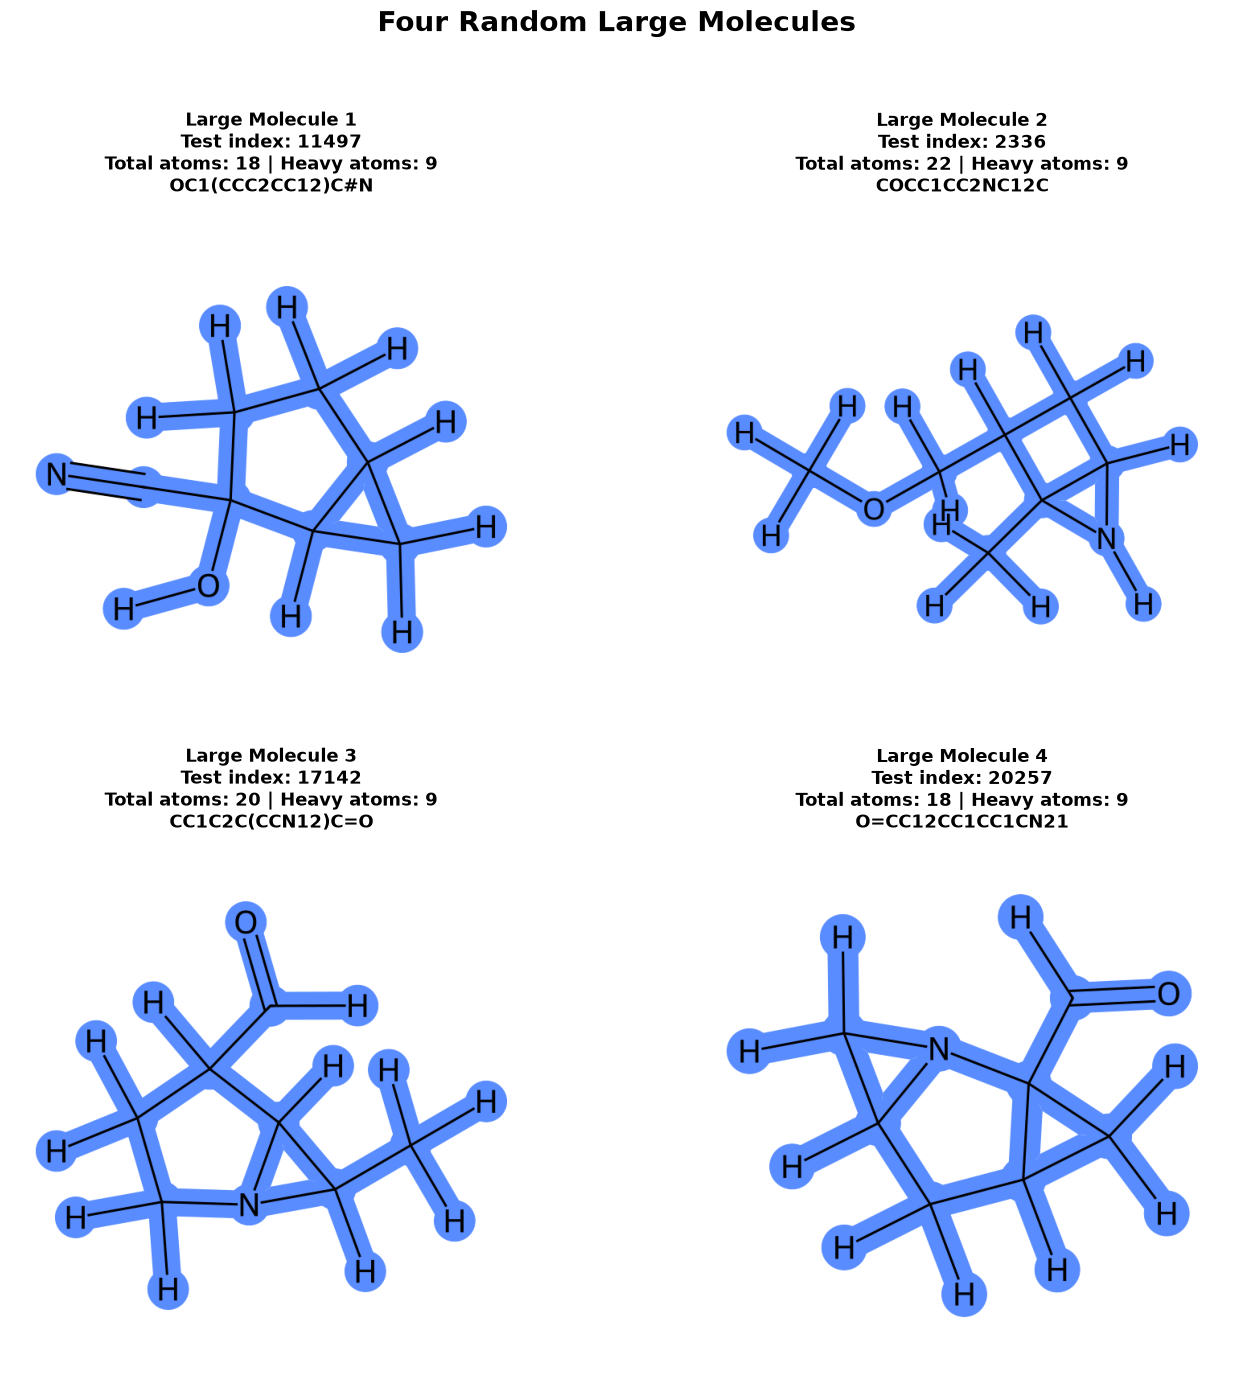

In [ ]:
# =============================================================================
# PLOT FOUR MOLECULES
# =============================================================================

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 14),
    squeeze=False,
)

axes = axes.reshape(-1)


for ax, record, molecule_number in zip(
    axes,
    random_large_molecules,
    range(1, N_RANDOM_LARGE_MOLECULES + 1),
):
    mol = record["Molecule"]
    smiles = record["SMILES"]

    image = mol_to_highlighted_image(
        mol=mol,
        img_size=MOLECULE_IMAGE_SIZE,
    )

    title = (
        f"Large Molecule {molecule_number}\n"
        f"Test index: {record['Test Index']}\n"
        f"Total atoms: {record['Total Atoms']} | "
        f"Heavy atoms: {record['Heavy Atoms']}\n"
        f"{smiles}"
    )

    ax.imshow(image)
    ax.axis("off")

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=12,
    )


fig.suptitle(
    "Four Random Large Molecules",
    fontsize=20,
    fontweight="bold",
    y=0.99,
)

plt.tight_layout(
    rect=[
        0,
        0.01,
        1,
        0.96,
    ]
)

In [ ]:
# =============================================================================
# SAVE FIGURE
# =============================================================================

output_filename = (
    "four_random_large_molecules_rdkit_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved molecule figure to "
    f"'{output_filename}'"
)

plt.show()


Saved molecule figure to 'four_random_large_molecules_rdkit_e_homo.png'


<Figure size 640x480 with 0 Axes>

In [ ]:
# =============================================================================
# SAVE SELECTED MOLECULES FOR LATER USE
# =============================================================================

four_random_large_mols = [
    record["Molecule"]
    for record in random_large_molecules
]

four_random_large_smiles = [
    record["SMILES"]
    for record in random_large_molecules
]

four_random_large_test_indices = [
    record["Test Index"]
    for record in random_large_molecules
]
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)

In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

K_TO_COMPARE = 4
CONNECTIVITY_WEIGHT = 0.10

N_INITIALIZATIONS = 100
BASE_SEED = 42

GREEDY_ITERATIONS = 100

MH_ITERATIONS = 5000
MH_BETA = 20.0

DISCONNECTED_SINGLETON_WEIGHT = 2.0

In [ ]:
# =============================================================================
# SELECT A SPECIFIC TEST MOLECULE
# =============================================================================

TARGET_TEST_INDEX = 17142

test_reset = test.reset_index(drop=True)

row = test_reset.iloc[TARGET_TEST_INDEX]

large_mol = row["mol"]
large_smiles = row["smiles"]
large_size_label = "Selected"

print("=" * 80)
print("SELECTED TEST MOLECULE")
print("=" * 80)
print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {large_smiles}")
print(f"Total atoms: {large_mol.GetNumAtoms()}")
print(f"Heavy atoms: {large_mol.GetNumHeavyAtoms()}")

assert large_smiles == "CC1C2C(CCN12)C=O"
assert large_mol.GetNumAtoms() == 20
assert large_mol.GetNumHeavyAtoms() == 9

SELECTED TEST MOLECULE
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9


In [ ]:
# =============================================================================
# CREATE OPTIMIZER
# =============================================================================

optimizer = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=K_TO_COMPARE,
    max_partitions=K_TO_COMPARE,
    connectivity_weight=CONNECTIVITY_WEIGHT,
    disconnected_singleton_weight=(
        DISCONNECTED_SINGLETON_WEIGHT
    ),
)

In [ ]:
# =============================================================================
# RUN PAIRED INITIALIZATIONS
# =============================================================================

comparison_results = []

best_results = {
    "Greedy-Distance": None,
    "Metropolis-Hastings": None,
}

best_scores = {
    "Greedy-Distance": -np.inf,
    "Metropolis-Hastings": -np.inf,
}


for initialization_index in range(N_INITIALIZATIONS):

    run_seed = BASE_SEED + initialization_index

    # -------------------------------------------------------------------------
    # Construct one common distance-based initial partition.
    # Both methods begin from this exact partition.
    # -------------------------------------------------------------------------

    initial_partition = ChemicalPartitioner.distance_partition(
        mol=large_mol,
        n_clusters=K_TO_COMPARE,
        seed=run_seed,
    )

    initial_k = len(set(initial_partition.values()))

    if initial_k != K_TO_COMPARE:
        raise RuntimeError(
            f"Initialization {initialization_index + 1} returned "
            f"k={initial_k} instead of k={K_TO_COMPARE}."
        )

    initial_interpretation = (
        interpreter.compute_partition_contributions(
            mol=large_mol,
            partition=initial_partition,
        )
    )

    initial_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=initial_interpretation,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )


    # -------------------------------------------------------------------------
    # Greedy-Distance
    #
    # Use the internal best-neighbor optimizer directly so that the supplied
    # starting partition is exactly the same as the MH starting partition.
    # -------------------------------------------------------------------------

    greedy_interpretation = (
        optimizer._greedy_helper.optimize_with_best_neighbor(
            mol=large_mol,
            initial_partition=initial_partition.copy(),
            n_iterations=GREEDY_ITERATIONS,
            seed=run_seed,
            verbose=False,
        )
    )

    greedy_partition = greedy_interpretation.partition

    greedy_actual_k = len(
        set(greedy_partition.values())
    )

    if greedy_actual_k != K_TO_COMPARE:
        raise RuntimeError(
            f"Greedy-Distance initialization "
            f"{initialization_index + 1} returned "
            f"k={greedy_actual_k}."
        )

    greedy_penalty = partition_connectivity_penalty(
        mol=large_mol,
        partition=greedy_partition,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    greedy_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=greedy_interpretation,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )


    # -------------------------------------------------------------------------
    # Metropolis-Hastings
    #
    # initial_partition is supplied explicitly, so initialization="distance"
    # is ignored. This guarantees that MH starts from the same partition.
    # -------------------------------------------------------------------------

    mh_interpretation = (
        optimizer.optimize_partition_metropolis_hastings(
            mol=large_mol,
            n_clusters=K_TO_COMPARE,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initial_partition=initial_partition.copy(),
            seed=run_seed,
            verbose=False,
        )
    )

    mh_partition = mh_interpretation.partition

    mh_actual_k = len(
        set(mh_partition.values())
    )

    if mh_actual_k != K_TO_COMPARE:
        raise RuntimeError(
            f"Metropolis-Hastings initialization "
            f"{initialization_index + 1} returned "
            f"k={mh_actual_k}."
        )

    mh_penalty = partition_connectivity_penalty(
        mol=large_mol,
        partition=mh_partition,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    mh_adjusted_score = connectivity_adjusted_score(
        mol=large_mol,
        interpretation=mh_interpretation,
        connectivity_weight=CONNECTIVITY_WEIGHT,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )


    # -------------------------------------------------------------------------
    # Save paired results
    # -------------------------------------------------------------------------

    score_difference = (
        mh_adjusted_score
        - greedy_adjusted_score
    )

    comparison_results.append({
        "Initialization": initialization_index + 1,
        "Seed": run_seed,
        "Initial Raw Score": initial_interpretation.score,
        "Initial Adjusted Score": initial_adjusted_score,
        "Greedy Raw Score": greedy_interpretation.score,
        "Greedy Connectivity Penalty": greedy_penalty,
        "Greedy Adjusted Score": greedy_adjusted_score,
        "MH Raw Score": mh_interpretation.score,
        "MH Connectivity Penalty": mh_penalty,
        "MH Adjusted Score": mh_adjusted_score,
        "MH Minus Greedy": score_difference,
        "Greedy Partition": greedy_partition.copy(),
        "MH Partition": mh_partition.copy(),
        "Greedy Interpretation": greedy_interpretation,
        "MH Interpretation": mh_interpretation,
    })


    # -------------------------------------------------------------------------
    # Track the best partition from each method
    # -------------------------------------------------------------------------

    if greedy_adjusted_score > best_scores["Greedy-Distance"]:
        best_scores["Greedy-Distance"] = greedy_adjusted_score

        best_results["Greedy-Distance"] = {
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Interpretation": greedy_interpretation,
            "Partition": greedy_partition.copy(),
            "Raw Score": greedy_interpretation.score,
            "Connectivity Penalty": greedy_penalty,
            "Adjusted Score": greedy_adjusted_score,
        }

    if mh_adjusted_score > best_scores["Metropolis-Hastings"]:
        best_scores["Metropolis-Hastings"] = mh_adjusted_score

        best_results["Metropolis-Hastings"] = {
            "Initialization": initialization_index + 1,
            "Seed": run_seed,
            "Interpretation": mh_interpretation,
            "Partition": mh_partition.copy(),
            "Raw Score": mh_interpretation.score,
            "Connectivity Penalty": mh_penalty,
            "Adjusted Score": mh_adjusted_score,
        }


    if (
        initialization_index == 0
        or (initialization_index + 1) % 10 == 0
    ):
        print(
            f"Completed {initialization_index + 1:3d}/"
            f"{N_INITIALIZATIONS}: "
            f"Greedy={greedy_adjusted_score:.4f}, "
            f"MH={mh_adjusted_score:.4f}, "
            f"MH-Greedy={score_difference:+.4f}"
        )

Completed   1/100: Greedy=0.9139, MH=0.9812, MH-Greedy=+0.0673
Completed  10/100: Greedy=0.9251, MH=0.9800, MH-Greedy=+0.0550
Completed  20/100: Greedy=0.9158, MH=0.9708, MH-Greedy=+0.0550
Completed  30/100: Greedy=0.9665, MH=0.9800, MH-Greedy=+0.0136
Completed  40/100: Greedy=0.9714, MH=0.9708, MH-Greedy=-0.0005
Completed  50/100: Greedy=0.9180, MH=0.9714, MH-Greedy=+0.0534
Completed  60/100: Greedy=0.9251, MH=0.9667, MH-Greedy=+0.0416
Completed  70/100: Greedy=0.9546, MH=0.9800, MH-Greedy=+0.0254
Completed  80/100: Greedy=0.9330, MH=0.9807, MH-Greedy=+0.0477
Completed  90/100: Greedy=0.9469, MH=0.9812, MH-Greedy=+0.0344
Completed 100/100: Greedy=0.9294, MH=0.9800, MH-Greedy=+0.0506


In [ ]:
# =============================================================================
# CREATE DATAFRAME
# =============================================================================

comparison_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in {
            "Greedy Partition",
            "MH Partition",
            "Greedy Interpretation",
            "MH Interpretation",
        }
    }
    for result in comparison_results
])

print("\nFirst comparison rows:")
display(comparison_df.head())


First comparison rows:


,Initialization,Seed,Initial Raw Score,Initial Adjusted Score,Greedy Raw Score,Greedy Connectivity Penalty,Greedy Adjusted Score,MH Raw Score,MH Connectivity Penalty,MH Adjusted Score,MH Minus Greedy
0,1,42,0.886779,0.886779,0.913882,0.0,0.913882,0.981208,0.0,0.981208,0.067326
1,2,43,0.942957,0.942957,0.942957,0.0,0.942957,0.982082,0.0,0.982082,0.039125
2,3,44,0.945801,0.945801,0.953916,0.0,0.953916,0.980046,0.0,0.980046,0.026130
3,4,45,0.896308,0.896308,0.916981,0.0,0.916981,0.979168,0.1,0.969168,0.052187
4,5,46,0.908421,0.908421,0.964402,0.0,0.964402,0.970359,0.0,0.970359,0.005957


In [ ]:
# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

greedy_scores = comparison_df[
    "Greedy Adjusted Score"
].to_numpy()

mh_scores = comparison_df[
    "MH Adjusted Score"
].to_numpy()

score_differences = comparison_df[
    "MH Minus Greedy"
].to_numpy()


summary_df = pd.DataFrame([
    {
        "Method": "Greedy-Distance",
        "N": len(greedy_scores),
        "Mean Adjusted Score": np.mean(greedy_scores),
        "Std Adjusted Score": np.std(
            greedy_scores,
            ddof=1
        ),
        "Median Adjusted Score": np.median(greedy_scores),
        "Minimum Adjusted Score": np.min(greedy_scores),
        "Maximum Adjusted Score": np.max(greedy_scores),
    },
    {
        "Method": "Metropolis-Hastings",
        "N": len(mh_scores),
        "Mean Adjusted Score": np.mean(mh_scores),
        "Std Adjusted Score": np.std(
            mh_scores,
            ddof=1
        ),
        "Median Adjusted Score": np.median(mh_scores),
        "Minimum Adjusted Score": np.min(mh_scores),
        "Maximum Adjusted Score": np.max(mh_scores),
    },
])

print("\n" + "=" * 80)
print("CONNECTIVITY-ADJUSTED SCORE COMPARISON")
print("=" * 80)

display(summary_df.round(6))


mh_wins = int(
    np.sum(score_differences > 1e-12)
)

greedy_wins = int(
    np.sum(score_differences < -1e-12)
)

ties = int(
    np.sum(np.abs(score_differences) <= 1e-12)
)

print(
    f"\nMetropolis-Hastings higher: "
    f"{mh_wins}/{N_INITIALIZATIONS}"
)

print(
    f"Greedy-Distance higher: "
    f"{greedy_wins}/{N_INITIALIZATIONS}"
)

print(
    f"Ties: "
    f"{ties}/{N_INITIALIZATIONS}"
)

print(
    f"Mean paired difference (MH - Greedy): "
    f"{np.mean(score_differences):+.6f}"
)

print(
    f"Median paired difference (MH - Greedy): "
    f"{np.median(score_differences):+.6f}"
)


CONNECTIVITY-ADJUSTED SCORE COMPARISON


,Method,N,Mean Adjusted Score,Std Adjusted Score,Median Adjusted Score,Minimum Adjusted Score,Maximum Adjusted Score
0,Greedy-Distance,100,0.944085,0.016685,0.946129,0.907287,0.973003
1,Metropolis-Hastings,100,0.976489,0.004896,0.978370,0.964402,0.982082



Metropolis-Hastings higher: 99/100
Greedy-Distance higher: 1/100
Ties: 0/100
Mean paired difference (MH - Greedy): +0.032404
Median paired difference (MH - Greedy): +0.031811


In [ ]:
# =============================================================================
# CALCULATE SHARED Y-AXIS LIMITS FOR PANELS 1 AND 2
# =============================================================================

all_method_scores = np.concatenate([
    greedy_scores,
    mh_scores,
])

score_min = np.min(all_method_scores)
score_max = np.max(all_method_scores)
score_range = score_max - score_min

# Add padding so points and boxplot whiskers do not touch the boundaries.
if score_range < 1e-10:
    score_padding = 0.01
else:
    score_padding = 0.08 * score_range

comparison_score_ylim = (
    max(0.0, score_min - score_padding),
    min(1.0, score_max + score_padding),
)

print(
    "Shared Greedy-Distance/MH score limits:",
    comparison_score_ylim,
)

Shared Greedy-Distance/MH score limits: (np.float64(0.9013033632167825), np.float64(0.9880655394456853))


In [ ]:
# =============================================================================
# PLOT COMPARISON
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(20, 6),
)


# -----------------------------------------------------------------------------
# Panel 1: boxplots and individual scores
# -----------------------------------------------------------------------------

score_groups = [
    greedy_scores,
    mh_scores,
]

method_labels = [
    "Greedy-Distance",
    "Metropolis-Hastings",
]

axes[0].boxplot(
    score_groups,
    tick_labels=method_labels,
    showmeans=True,
    patch_artist=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 7,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
)

jitter_rng = np.random.default_rng(BASE_SEED)

for position, scores in enumerate(
    score_groups,
    start=1,
):
    jittered_x = jitter_rng.normal(
        loc=position,
        scale=0.035,
        size=len(scores),
    )

    axes[0].scatter(
        jittered_x,
        scores,
        alpha=0.30,
        s=20,
    )

axes[0].set_title(
    ("Adjusted Score Distributions") + "\n" + ADJUSTED_SCORE_SUBTITLE,
    fontsize=15,
    fontweight="bold",
)

axes[0].set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=12,
)

axes[0].tick_params(
    axis="x",
    labelrotation=15,
)

axes[0].set_ylim(comparison_score_ylim)
axes[0].grid(axis="y", alpha=0.3)


# -----------------------------------------------------------------------------
# Panel 2: paired scores
# -----------------------------------------------------------------------------

for initialization_index in range(N_INITIALIZATIONS):
    axes[1].plot(
        [0, 1],
        [
            greedy_scores[initialization_index],
            mh_scores[initialization_index],
        ],
        marker="o",
        linewidth=0.8,
        alpha=0.25,
    )

axes[1].plot(
    [0, 1],
    [
        np.mean(greedy_scores),
        np.mean(mh_scores),
    ],
    marker="D",
    linewidth=3,
    markersize=9,
    label="Mean",
)

axes[1].set_xticks(
    [0, 1],
    method_labels,
    rotation=15,
)

axes[1].set_title(
    ("Paired Initializations") + "\n" + "Per-run adjusted scores",
    fontsize=15,
    fontweight="bold",
)

axes[1].set_ylabel(
    "Connectivity-Adjusted Score",
    fontsize=12,
)

axes[1].set_ylim(comparison_score_ylim)
axes[1].grid(axis="y", alpha=0.3)
axes[1].legend()


# -----------------------------------------------------------------------------
# Panel 3: paired score differences
# -----------------------------------------------------------------------------

initialization_numbers = np.arange(
    1,
    N_INITIALIZATIONS + 1,
)

axes[2].scatter(
    initialization_numbers,
    score_differences,
    alpha=0.70,
    s=30,
)

axes[2].axhline(
    0.0,
    linestyle="--",
    linewidth=1.5,
)

axes[2].axhline(
    np.mean(score_differences),
    linestyle="-",
    linewidth=2,
    label=(
        "Mean difference = "
        f"{np.mean(score_differences):+.4f}"
    ),
)

axes[2].set_title(
    ("Paired Score Difference") + "\n" + "MH adjusted score − Greedy-Distance adjusted score",
    fontsize=15,
    fontweight="bold",
)

axes[2].set_xlabel(
    "Initialization",
    fontsize=12,
)

axes[2].set_ylabel(
    "MH Adjusted Score − Greedy Adjusted Score",
    fontsize=12,
)

axes[2].grid(alpha=0.3)
axes[2].legend()


fig.suptitle(
    f"Greedy-Distance vs. Metropolis-Hastings for {large_smiles}\n"
    f"k={K_TO_COMPARE}, "
    f"$\\lambda$={CONNECTIVITY_WEIGHT:g}, "
    f"{N_INITIALIZATIONS} Paired Distance Initializations",
    fontsize=17,
    fontweight="bold",
    y=1.03,
)

plt.tight_layout()

comparison_filename = (
    "large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_e_homo.png"
)

plt.savefig(images_dir /
    comparison_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved comparison plot to "
    f"'{comparison_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PRINT BEST RESULT FROM EACH METHOD
# =============================================================================

print("\n" + "=" * 80)
print("BEST RESULT FROM EACH METHOD")
print("=" * 80)

for method_name in [
    "Greedy-Distance",
    "Metropolis-Hastings",
]:
    result = best_results[method_name]

    print(f"\n{method_name}")

    print(
        f"  Initialization: "
        f"{result['Initialization']}"
    )

    print(
        f"  Seed: "
        f"{result['Seed']}"
    )

    print(
        f"  Raw score: "
        f"{result['Raw Score']:.6f}"
    )

    print(
        f"  Connectivity penalty: "
        f"{result['Connectivity Penalty']:.6f}"
    )

    print(
        f"  Adjusted score: "
        f"{result['Adjusted Score']:.6f}"
    )

    print(
        f"  Partition: "
        f"{result['Partition']}"
    )


BEST RESULT FROM EACH METHOD

Greedy-Distance
  Initialization: 24
  Seed: 65
  Raw score: 0.973003
  Connectivity penalty: 0.000000
  Adjusted score: 0.973003
  Partition: {0: 3, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 3, 10: 2, 11: 1, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0}

Metropolis-Hastings
  Initialization: 84
  Seed: 125
  Raw score: 0.982082
  Connectivity penalty: 0.000000
  Adjusted score: 0.982082
  Partition: {0: 1, 1: 1, 2: 0, 3: 0, 4: 1, 5: 1, 6: 1, 7: 0, 8: 0, 9: 2, 10: 1, 11: 1, 12: 1, 13: 0, 14: 0, 15: 1, 16: 1, 17: 3, 18: 1, 19: 0}


In [ ]:
# =============================================================================
# SAVE RESULTS
# =============================================================================

comparison_df.to_csv(csv_dir /
    "large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_detailed_e_homo.csv",
    index=False,
)

summary_df.to_csv(csv_dir /
    "large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_summary_e_homo.csv",
    index=False,
)

print("\nSaved numerical results to:")

print(
    "  large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_detailed_e_homo.csv"
)

print(
    "  large_molecule_greedy_distance_vs_"
    "metropolis_hastings_100_initializations_summary_e_homo.csv"
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved numerical results to:
  large_molecule_greedy_distance_vs_metropolis_hastings_100_initializations_detailed_e_homo.csv
  large_molecule_greedy_distance_vs_metropolis_hastings_100_initializations_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

TARGET_TEST_INDEX = 17142
EXPECTED_SMILES = "CC1C2C(CCN12)C=O"

K_TO_COMPARE = 4

SCORE_LAMBDAS = (
    0.01,
    0.10,
    0.50,
    1.00,
    1.50,
)

N_INITIALIZATIONS = 100
BASE_SEED = 42

GREEDY_ITERATIONS = 100

MH_ITERATIONS = 5000
MH_BETA = 20.0

DISCONNECTED_SINGLETON_WEIGHT = 2.0

METHOD_NAMES = (
    "Greedy-Distance",
    "Metropolis-Hastings",
)

In [ ]:
# =============================================================================
# SELECT THE TARGET MOLECULE
# =============================================================================

test_reset = test.reset_index(drop=True)

if TARGET_TEST_INDEX < 0 or TARGET_TEST_INDEX >= len(test_reset):
    raise IndexError(
        f"TARGET_TEST_INDEX={TARGET_TEST_INDEX} is outside the valid range "
        f"0 to {len(test_reset) - 1}."
    )

target_row = test_reset.iloc[
    TARGET_TEST_INDEX
]

target_mol = target_row["mol"]
target_smiles = target_row["smiles"]

if target_mol is None:
    raise ValueError(
        f"The molecule at test index {TARGET_TEST_INDEX} is None."
    )

if target_smiles != EXPECTED_SMILES:
    raise ValueError(
        "The selected test row does not contain the expected molecule.\n"
        f"Expected: {EXPECTED_SMILES}\n"
        f"Found:    {target_smiles}"
    )

if target_mol.GetNumAtoms() < K_TO_COMPARE:
    raise ValueError(
        f"The molecule has only {target_mol.GetNumAtoms()} atoms, "
        f"so it cannot contain {K_TO_COMPARE} nonempty partitions."
    )


print("=" * 100)
print("GREEDY-DISTANCE VS METROPOLIS-HASTINGS ACROSS LAMBDA")
print("=" * 100)
print(f"Test index: {TARGET_TEST_INDEX}")
print(f"SMILES: {target_smiles}")
print(f"Total atoms: {target_mol.GetNumAtoms()}")
print(f"Heavy atoms: {target_mol.GetNumHeavyAtoms()}")
print(f"Partitions: k={K_TO_COMPARE}")
print(f"Lambda values: {list(SCORE_LAMBDAS)}")
print(f"Paired initializations per lambda: {N_INITIALIZATIONS}")
print(f"Greedy iterations: {GREEDY_ITERATIONS}")
print(f"MH iterations: {MH_ITERATIONS}")
print(f"MH beta: {MH_BETA}")
print("=" * 100)

GREEDY-DISTANCE VS METROPOLIS-HASTINGS ACROSS LAMBDA
Test index: 17142
SMILES: CC1C2C(CCN12)C=O
Total atoms: 20
Heavy atoms: 9
Partitions: k=4
Lambda values: [0.01, 0.1, 0.5, 1.0, 1.5]
Paired initializations per lambda: 100
Greedy iterations: 100
MH iterations: 5000
MH beta: 20.0


In [ ]:
# =============================================================================
# STORAGE
# =============================================================================

comparison_results = []

best_results = {
    score_lambda: {
        "Greedy-Distance": None,
        "Metropolis-Hastings": None,
    }
    for score_lambda in SCORE_LAMBDAS
}

best_scores = {
    score_lambda: {
        "Greedy-Distance": -np.inf,
        "Metropolis-Hastings": -np.inf,
    }
    for score_lambda in SCORE_LAMBDAS
}

In [ ]:
# =============================================================================
# RUN BOTH METHODS FOR EVERY LAMBDA AND INITIALIZATION
# =============================================================================

for lambda_index, score_lambda in enumerate(
    SCORE_LAMBDAS,
    start=1,
):
    print("\n" + "=" * 100)
    print(
        f"LAMBDA {lambda_index}/{len(SCORE_LAMBDAS)}: "
        f"{score_lambda:g}"
    )
    print("=" * 100)

    # Lambda is part of the optimization objective, so each lambda receives
    # its own optimizer.
    optimizer_lambda = PartitionOptimizer(
        interpreter=interpreter,
        min_partitions=K_TO_COMPARE,
        max_partitions=K_TO_COMPARE,
        connectivity_weight=score_lambda,
        disconnected_singleton_weight=(
            DISCONNECTED_SINGLETON_WEIGHT
        ),
    )

    for initialization_index in range(
        N_INITIALIZATIONS
    ):
        run_seed = (
            BASE_SEED
            + initialization_index
        )

        # ---------------------------------------------------------------------
        # COMMON INITIAL PARTITION
        #
        # Both methods receive the same starting partition for this seed.
        # The same seed is also reused at each lambda, so lambda comparisons
        # are paired as well.
        # ---------------------------------------------------------------------

        initial_partition = (
            ChemicalPartitioner.distance_partition(
                mol=target_mol,
                n_clusters=K_TO_COMPARE,
                seed=run_seed,
            )
        )

        initial_actual_k = len(
            set(initial_partition.values())
        )

        if initial_actual_k != K_TO_COMPARE:
            raise RuntimeError(
                f"Lambda={score_lambda:g}, initialization "
                f"{initialization_index + 1}: distance initialization "
                f"returned k={initial_actual_k}, not k={K_TO_COMPARE}."
            )

        initial_interpretation = (
            interpreter.compute_partition_contributions(
                mol=target_mol,
                partition=initial_partition,
            )
        )

        initial_penalty = (
            partition_connectivity_penalty(
                mol=target_mol,
                partition=initial_partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                ),
            )
        )

        initial_adjusted_score = (
            connectivity_adjusted_score(
                mol=target_mol,
                interpretation=initial_interpretation,
                connectivity_weight=score_lambda,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                ),
            )
        )


        # ---------------------------------------------------------------------
        # GREEDY-DISTANCE
        #
        # Call the best-neighbor helper directly so the exact common initial
        # partition is used.
        # ---------------------------------------------------------------------

        greedy_interpretation = (
            optimizer_lambda
            ._greedy_helper
            .optimize_with_best_neighbor(
                mol=target_mol,
                initial_partition=initial_partition.copy(),
                n_iterations=GREEDY_ITERATIONS,
                seed=run_seed,
                verbose=False,
            )
        )

        greedy_partition = (
            greedy_interpretation.partition
        )

        greedy_actual_k = len(
            set(greedy_partition.values())
        )

        if greedy_actual_k != K_TO_COMPARE:
            raise RuntimeError(
                f"Lambda={score_lambda:g}, initialization "
                f"{initialization_index + 1}: Greedy-Distance returned "
                f"k={greedy_actual_k}, not k={K_TO_COMPARE}."
            )

        greedy_penalty = (
            partition_connectivity_penalty(
                mol=target_mol,
                partition=greedy_partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                ),
            )
        )

        greedy_adjusted_score = (
            connectivity_adjusted_score(
                mol=target_mol,
                interpretation=greedy_interpretation,
                connectivity_weight=score_lambda,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                ),
            )
        )


        # ---------------------------------------------------------------------
        # METROPOLIS-HASTINGS
        #
        # Supplying initial_partition guarantees the same starting point as
        # Greedy-Distance.
        # ---------------------------------------------------------------------

        mh_interpretation = (
            optimizer_lambda
            .optimize_partition_metropolis_hastings(
                mol=target_mol,
                n_clusters=K_TO_COMPARE,
                n_iterations=MH_ITERATIONS,
                beta=MH_BETA,
                initial_partition=initial_partition.copy(),
                seed=run_seed,
                verbose=False,
            )
        )

        mh_partition = (
            mh_interpretation.partition
        )

        mh_actual_k = len(
            set(mh_partition.values())
        )

        if mh_actual_k != K_TO_COMPARE:
            raise RuntimeError(
                f"Lambda={score_lambda:g}, initialization "
                f"{initialization_index + 1}: Metropolis-Hastings returned "
                f"k={mh_actual_k}, not k={K_TO_COMPARE}."
            )

        mh_penalty = (
            partition_connectivity_penalty(
                mol=target_mol,
                partition=mh_partition,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                ),
            )
        )

        mh_adjusted_score = (
            connectivity_adjusted_score(
                mol=target_mol,
                interpretation=mh_interpretation,
                connectivity_weight=score_lambda,
                disconnected_singleton_weight=(
                    DISCONNECTED_SINGLETON_WEIGHT
                ),
            )
        )


        # ---------------------------------------------------------------------
        # STORE RESULTS
        # ---------------------------------------------------------------------

        adjusted_difference = (
            mh_adjusted_score
            - greedy_adjusted_score
        )

        raw_difference = (
            mh_interpretation.score
            - greedy_interpretation.score
        )

        comparison_results.append({
            "Lambda": score_lambda,
            "Initialization": initialization_index + 1,
            "Seed": run_seed,

            "Initial Raw Score": (
                initial_interpretation.score
            ),
            "Initial Connectivity Penalty": (
                initial_penalty
            ),
            "Initial Adjusted Score": (
                initial_adjusted_score
            ),

            "Greedy Raw Score": (
                greedy_interpretation.score
            ),
            "Greedy Connectivity Penalty": (
                greedy_penalty
            ),
            "Greedy Adjusted Score": (
                greedy_adjusted_score
            ),

            "MH Raw Score": (
                mh_interpretation.score
            ),
            "MH Connectivity Penalty": (
                mh_penalty
            ),
            "MH Adjusted Score": (
                mh_adjusted_score
            ),

            "MH Minus Greedy Raw": (
                raw_difference
            ),
            "MH Minus Greedy Adjusted": (
                adjusted_difference
            ),

            "Greedy Partition": (
                greedy_partition.copy()
            ),
            "MH Partition": (
                mh_partition.copy()
            ),

            "Greedy Interpretation": (
                greedy_interpretation
            ),
            "MH Interpretation": (
                mh_interpretation
            ),
        })


        # ---------------------------------------------------------------------
        # TRACK BEST RESULTS AT EACH LAMBDA
        # ---------------------------------------------------------------------

        if (
            greedy_adjusted_score
            > best_scores[score_lambda]["Greedy-Distance"]
        ):
            best_scores[
                score_lambda
            ]["Greedy-Distance"] = (
                greedy_adjusted_score
            )

            best_results[
                score_lambda
            ]["Greedy-Distance"] = {
                "Initialization": initialization_index + 1,
                "Seed": run_seed,
                "Raw Score": greedy_interpretation.score,
                "Connectivity Penalty": greedy_penalty,
                "Adjusted Score": greedy_adjusted_score,
                "Partition": greedy_partition.copy(),
                "Interpretation": greedy_interpretation,
            }

        if (
            mh_adjusted_score
            > best_scores[
                score_lambda
            ]["Metropolis-Hastings"]
        ):
            best_scores[
                score_lambda
            ]["Metropolis-Hastings"] = (
                mh_adjusted_score
            )

            best_results[
                score_lambda
            ]["Metropolis-Hastings"] = {
                "Initialization": initialization_index + 1,
                "Seed": run_seed,
                "Raw Score": mh_interpretation.score,
                "Connectivity Penalty": mh_penalty,
                "Adjusted Score": mh_adjusted_score,
                "Partition": mh_partition.copy(),
                "Interpretation": mh_interpretation,
            }


        if (
            initialization_index == 0
            or (initialization_index + 1) % 10 == 0
        ):
            print(
                f"Completed "
                f"{initialization_index + 1:3d}/"
                f"{N_INITIALIZATIONS}: "
                f"Greedy={greedy_adjusted_score:.4f}, "
                f"MH={mh_adjusted_score:.4f}, "
                f"MH-Greedy={adjusted_difference:+.4f}"
            )


LAMBDA 1/5: 0.01
Completed   1/100: Greedy=0.9139, MH=0.9809, MH-Greedy=+0.0670
Completed  10/100: Greedy=0.9351, MH=0.9828, MH-Greedy=+0.0476
Completed  20/100: Greedy=0.9158, MH=0.9727, MH-Greedy=+0.0569
Completed  30/100: Greedy=0.9733, MH=0.9822, MH-Greedy=+0.0089
Completed  40/100: Greedy=0.9477, MH=0.9707, MH-Greedy=+0.0230
Completed  50/100: Greedy=0.9408, MH=0.9821, MH-Greedy=+0.0413
Completed  60/100: Greedy=0.9351, MH=0.9800, MH-Greedy=+0.0449
Completed  70/100: Greedy=0.9209, MH=0.9719, MH-Greedy=+0.0509
Completed  80/100: Greedy=0.9804, MH=0.9800, MH-Greedy=-0.0004
Completed  90/100: Greedy=0.9559, MH=0.9812, MH-Greedy=+0.0254
Completed 100/100: Greedy=0.9254, MH=0.9784, MH-Greedy=+0.0530

LAMBDA 2/5: 0.1
Completed   1/100: Greedy=0.9139, MH=0.9812, MH-Greedy=+0.0673
Completed  10/100: Greedy=0.9251, MH=0.9800, MH-Greedy=+0.0550
Completed  20/100: Greedy=0.9158, MH=0.9708, MH-Greedy=+0.0550
Completed  30/100: Greedy=0.9665, MH=0.9800, MH-Greedy=+0.0136
Completed  40/100: G

In [ ]:
# =============================================================================
# CREATE NUMERIC DATAFRAME
# =============================================================================

excluded_keys = {
    "Greedy Partition",
    "MH Partition",
    "Greedy Interpretation",
    "MH Interpretation",
}

comparison_df = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key not in excluded_keys
    }
    for result in comparison_results
])

print("\nFirst result rows:")
display(
    comparison_df.head()
)


First result rows:


,Lambda,Initialization,Seed,Initial Raw Score,Initial Connectivity Penalty,Initial Adjusted Score,Greedy Raw Score,Greedy Connectivity Penalty,Greedy Adjusted Score,MH Raw Score,MH Connectivity Penalty,MH Adjusted Score,MH Minus Greedy Raw,MH Minus Greedy Adjusted
0,0.01,1,42,0.886779,0.0,0.886779,0.913882,0.0,0.913882,0.982899,0.20,0.980899,0.069017,0.067017
1,0.01,2,43,0.942957,0.0,0.942957,0.946070,0.1,0.945070,0.981979,0.20,0.979979,0.035909,0.034909
2,0.01,3,44,0.945801,0.0,0.945801,0.969403,0.3,0.966403,0.986255,0.35,0.982755,0.016852,0.016352
3,0.01,4,45,0.896308,0.0,0.896308,0.928571,0.1,0.927571,0.983540,0.20,0.981540,0.054969,0.053969
4,0.01,5,46,0.908421,0.0,0.908421,0.965104,0.1,0.964104,0.973264,0.10,0.972264,0.008160,0.008160


In [ ]:
# =============================================================================
# SUMMARY STATISTICS BY LAMBDA AND METHOD
# =============================================================================

summary_rows = []

for score_lambda in SCORE_LAMBDAS:
    lambda_df = comparison_df[
        comparison_df["Lambda"]
        == score_lambda
    ]

    for method_name, score_column, raw_column, penalty_column in (
        (
            "Greedy-Distance",
            "Greedy Adjusted Score",
            "Greedy Raw Score",
            "Greedy Connectivity Penalty",
        ),
        (
            "Metropolis-Hastings",
            "MH Adjusted Score",
            "MH Raw Score",
            "MH Connectivity Penalty",
        ),
    ):
        scores = lambda_df[
            score_column
        ].to_numpy()

        raw_scores = lambda_df[
            raw_column
        ].to_numpy()

        penalties = lambda_df[
            penalty_column
        ].to_numpy()

        summary_rows.append({
            "Lambda": score_lambda,
            "Method": method_name,
            "N": len(scores),

            "Mean Adjusted Score": (
                np.mean(scores)
            ),
            "Std Adjusted Score": (
                np.std(scores, ddof=1)
            ),
            "Median Adjusted Score": (
                np.median(scores)
            ),
            "Minimum Adjusted Score": (
                np.min(scores)
            ),
            "Maximum Adjusted Score": (
                np.max(scores)
            ),

            "Mean Raw Score": (
                np.mean(raw_scores)
            ),
            "Std Raw Score": (
                np.std(raw_scores, ddof=1)
            ),

            "Mean Connectivity Penalty": (
                np.mean(penalties)
            ),
            "Std Connectivity Penalty": (
                np.std(penalties, ddof=1)
            ),
        })


summary_df = pd.DataFrame(
    summary_rows
)

In [ ]:
# =============================================================================
# PAIRED METHOD COMPARISON BY LAMBDA
# =============================================================================

paired_summary_rows = []

for score_lambda in SCORE_LAMBDAS:
    lambda_df = comparison_df[
        comparison_df["Lambda"]
        == score_lambda
    ]

    differences = lambda_df[
        "MH Minus Greedy Adjusted"
    ].to_numpy()

    mh_wins = int(
        np.sum(
            differences > 1e-12
        )
    )

    greedy_wins = int(
        np.sum(
            differences < -1e-12
        )
    )

    ties = int(
        np.sum(
            np.abs(differences)
            <= 1e-12
        )
    )

    paired_summary_rows.append({
        "Lambda": score_lambda,
        "N": len(differences),
        "Mean MH Minus Greedy": (
            np.mean(differences)
        ),
        "Std MH Minus Greedy": (
            np.std(differences, ddof=1)
        ),
        "Median MH Minus Greedy": (
            np.median(differences)
        ),
        "MH Wins": mh_wins,
        "Greedy Wins": greedy_wins,
        "Ties": ties,
    })


paired_summary_df = pd.DataFrame(
    paired_summary_rows
)


print("\n" + "=" * 100)
print("SUMMARY BY LAMBDA AND METHOD")
print("=" * 100)

display(
    summary_df.round(6)
)

print("\n" + "=" * 100)
print("PAIRED METHOD DIFFERENCES BY LAMBDA")
print("=" * 100)

display(
    paired_summary_df.round(6)
)


SUMMARY BY LAMBDA AND METHOD


,Lambda,Method,N,Mean Adjusted Score,Std Adjusted Score,Median Adjusted Score,Minimum Adjusted Score,Maximum Adjusted Score,Mean Raw Score,Std Raw Score,Mean Connectivity Penalty,Std Connectivity Penalty
0,0.01,Greedy-Distance,100,0.953541,0.016477,0.955129,0.913882,0.981222,0.954991,0.016641,0.145,0.117314
1,0.01,Metropolis-Hastings,100,0.979911,0.003050,0.980760,0.967967,0.984672,0.981341,0.003333,0.143,0.116779
2,0.10,Greedy-Distance,100,0.944085,0.016685,0.946129,0.907287,0.973003,0.945685,0.017392,0.016,0.036845
3,0.10,Metropolis-Hastings,100,0.976489,0.004896,0.978370,0.964402,0.982082,0.977089,0.004764,0.006,0.023868
4,0.50,Greedy-Distance,100,0.925846,0.023455,0.925573,0.872890,0.973003,0.925846,0.023455,0.000,0.000000
5,0.50,Metropolis-Hastings,100,0.970557,0.008879,0.971372,0.929007,0.982082,0.970557,0.008879,0.000,0.000000
6,1.00,Greedy-Distance,100,0.925846,0.023455,0.925573,0.872890,0.973003,0.925846,0.023455,0.000,0.000000
7,1.00,Metropolis-Hastings,100,0.964197,0.010241,0.966327,0.929300,0.981208,0.964197,0.010241,0.000,0.000000
8,1.50,Greedy-Distance,100,0.925846,0.023455,0.925573,0.872890,0.973003,0.925846,0.023455,0.000,0.000000
9,1.50,Metropolis-Hastings,100,0.953860,0.015583,0.957409,0.901344,0.981208,0.953860,0.015583,0.000,0.000000



PAIRED METHOD DIFFERENCES BY LAMBDA


,Lambda,N,Mean MH Minus Greedy,Std MH Minus Greedy,Median MH Minus Greedy,MH Wins,Greedy Wins,Ties
0,0.01,100,0.026370,0.016146,0.025748,96,4,0
1,0.10,100,0.032404,0.017302,0.031811,99,1,0
2,0.50,100,0.044711,0.022499,0.041916,99,0,1
3,1.00,100,0.038351,0.021426,0.037319,97,0,3
4,1.50,100,0.028014,0.021389,0.024494,87,0,13


In [ ]:
# =============================================================================
# PREPARE PLOTTING ARRAYS
# =============================================================================

greedy_summary = (
    summary_df[
        summary_df["Method"]
        == "Greedy-Distance"
    ]
    .sort_values("Lambda")
)

mh_summary = (
    summary_df[
        summary_df["Method"]
        == "Metropolis-Hastings"
    ]
    .sort_values("Lambda")
)

lambda_values = np.asarray(
    SCORE_LAMBDAS,
    dtype=float
)

greedy_mean_adjusted = (
    greedy_summary[
        "Mean Adjusted Score"
    ].to_numpy()
)

greedy_std_adjusted = (
    greedy_summary[
        "Std Adjusted Score"
    ].to_numpy()
)

mh_mean_adjusted = (
    mh_summary[
        "Mean Adjusted Score"
    ].to_numpy()
)

mh_std_adjusted = (
    mh_summary[
        "Std Adjusted Score"
    ].to_numpy()
)

greedy_mean_raw = (
    greedy_summary[
        "Mean Raw Score"
    ].to_numpy()
)

greedy_std_raw = (
    greedy_summary[
        "Std Raw Score"
    ].to_numpy()
)

mh_mean_raw = (
    mh_summary[
        "Mean Raw Score"
    ].to_numpy()
)

mh_std_raw = (
    mh_summary[
        "Std Raw Score"
    ].to_numpy()
)

mean_differences = (
    paired_summary_df[
        "Mean MH Minus Greedy"
    ].to_numpy()
)

std_differences = (
    paired_summary_df[
        "Std MH Minus Greedy"
    ].to_numpy()
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y LIMITS
# =============================================================================

all_adjusted_scores = np.concatenate([
    comparison_df[
        "Greedy Adjusted Score"
    ].to_numpy(),
    comparison_df[
        "MH Adjusted Score"
    ].to_numpy(),
])

adjusted_min = np.min(
    all_adjusted_scores
)

adjusted_max = np.max(
    all_adjusted_scores
)

adjusted_range = (
    adjusted_max
    - adjusted_min
)

adjusted_padding = (
    0.01
    if adjusted_range < 1e-10
    else 0.08 * adjusted_range
)

adjusted_ylim = (
    max(
        0.0,
        adjusted_min
        - adjusted_padding
    ),
    min(
        1.0,
        adjusted_max
        + adjusted_padding
    ),
)


all_raw_scores = np.concatenate([
    comparison_df[
        "Greedy Raw Score"
    ].to_numpy(),
    comparison_df[
        "MH Raw Score"
    ].to_numpy(),
])

raw_min = np.min(
    all_raw_scores
)

raw_max = np.max(
    all_raw_scores
)

raw_range = (
    raw_max
    - raw_min
)

raw_padding = (
    0.01
    if raw_range < 1e-10
    else 0.08 * raw_range
)

raw_ylim = (
    max(
        0.0,
        raw_min
        - raw_padding
    ),
    min(
        1.0,
        raw_max
        + raw_padding
    ),
)

In [ ]:
# =============================================================================
# PLOT 1: MEAN SCORES AND PAIRED DIFFERENCES ACROSS LAMBDA
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(21, 6.5),
)


# -----------------------------------------------------------------------------
# Panel 1: adjusted scores versus lambda
# -----------------------------------------------------------------------------

axes[0].errorbar(
    lambda_values,
    greedy_mean_adjusted,
    yerr=greedy_std_adjusted,
    marker="s",
    linewidth=2.5,
    markersize=8,
    capsize=4,
    label="Greedy-Distance",
)

axes[0].errorbar(
    lambda_values,
    mh_mean_adjusted,
    yerr=mh_std_adjusted,
    marker="^",
    linewidth=2.5,
    markersize=9,
    capsize=4,
    label="Metropolis-Hastings",
)

axes[0].set_title(
    ("Adjusted Score vs. Lambda") + "\n" + "Mean adjusted score; error bars = ±1 SD across paired runs",
    fontsize=16,
    fontweight="bold",
)

axes[0].set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=13,
)

axes[0].set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=13,
)

axes[0].set_xticks(
    lambda_values
)

axes[0].set_ylim(
    adjusted_ylim
)

axes[0].legend()
axes[0].grid(alpha=0.3)


# -----------------------------------------------------------------------------
# Panel 2: raw score versus lambda
# -----------------------------------------------------------------------------

axes[1].errorbar(
    lambda_values,
    greedy_mean_raw,
    yerr=greedy_std_raw,
    marker="s",
    linewidth=2.5,
    markersize=8,
    capsize=4,
    label="Greedy-Distance",
)

axes[1].errorbar(
    lambda_values,
    mh_mean_raw,
    yerr=mh_std_raw,
    marker="^",
    linewidth=2.5,
    markersize=9,
    capsize=4,
    label="Metropolis-Hastings",
)

axes[1].set_title(
    ("Raw Interpretability Score vs. Lambda") + "\n" + "Mean raw score; error bars = ±1 SD across paired runs",
    fontsize=16,
    fontweight="bold",
)

axes[1].set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=13,
)

axes[1].set_ylabel(
    "Mean Raw Interpretability Score",
    fontsize=13,
)

axes[1].set_xticks(
    lambda_values
)

axes[1].set_ylim(
    raw_ylim
)

axes[1].legend()
axes[1].grid(alpha=0.3)


# -----------------------------------------------------------------------------
# Panel 3: paired adjusted-score difference
# -----------------------------------------------------------------------------

axes[2].errorbar(
    lambda_values,
    mean_differences,
    yerr=std_differences,
    marker="D",
    linewidth=2.5,
    markersize=8,
    capsize=4,
)

axes[2].axhline(
    0.0,
    linestyle="--",
    linewidth=1.5,
)

axes[2].set_title(
    ("Paired Adjusted-Score Difference") + "\n" + "Mean paired adjusted difference (MH − Greedy); error bars = ±1 SD",
    fontsize=16,
    fontweight="bold",
)

axes[2].set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=13,
)

axes[2].set_ylabel(
    "MH Score − Greedy-Distance Score",
    fontsize=13,
)

axes[2].set_xticks(
    lambda_values
)

axes[2].grid(alpha=0.3)


fig.suptitle(
    f"Greedy-Distance vs. Metropolis-Hastings Across Connectivity Weights\n"
    f"Test Index {TARGET_TEST_INDEX}: {target_smiles}, "
    f"k={K_TO_COMPARE}, "
    f"{N_INITIALIZATIONS} Paired Initializations",
    fontsize=18,
    fontweight="bold",
    y=1.04,
)

plt.tight_layout()

score_plot_filename = (
    f"test_index_{TARGET_TEST_INDEX}_"
    "greedy_distance_vs_metropolis_hastings_"
    "scores_across_lambda_e_homo.png"
)

plt.savefig(images_dir /
    score_plot_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved score comparison plot to "
    f"'{score_plot_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PLOT 2: ADJUSTED-SCORE DISTRIBUTIONS AT EACH LAMBDA
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(SCORE_LAMBDAS),
    figsize=(24, 6),
    sharey=True,
)

for ax, score_lambda in zip(
    axes,
    SCORE_LAMBDAS,
):
    lambda_df = comparison_df[
        comparison_df["Lambda"]
        == score_lambda
    ]

    greedy_scores = lambda_df[
        "Greedy Adjusted Score"
    ].to_numpy()

    mh_scores = lambda_df[
        "MH Adjusted Score"
    ].to_numpy()

    score_groups = [
        greedy_scores,
        mh_scores,
    ]

    boxplot = ax.boxplot(
        score_groups,
        tick_labels=[
            "Greedy",
            "MH",
        ],
        showmeans=True,
        patch_artist=True,
        meanprops={
            "marker": "o",
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markersize": 6,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
    )

    jitter_rng = np.random.default_rng(
        BASE_SEED
    )

    for position, scores in enumerate(
        score_groups,
        start=1,
    ):
        jittered_x = jitter_rng.normal(
            loc=position,
            scale=0.035,
            size=len(scores),
        )

        ax.scatter(
            jittered_x,
            scores,
            alpha=0.25,
            s=16,
        )

    ax.set_title(
        (rf"$\lambda={score_lambda:g}$") + "\n" + "Per-run adjusted scores",
        fontsize=15,
        fontweight="bold",
    )

    ax.set_ylim(
        adjusted_ylim
    )

    ax.grid(
        axis="y",
        alpha=0.3,
    )

    if ax is axes[0]:
        ax.set_ylabel(
            "Connectivity-Adjusted Score",
            fontsize=13,
        )


fig.suptitle(
    "Adjusted-Score Distributions Across Lambda Values",
    fontsize=18,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

distribution_plot_filename = (
    f"test_index_{TARGET_TEST_INDEX}_"
    "greedy_distance_vs_metropolis_hastings_"
    "distributions_across_lambda_e_homo.png"
)

plt.savefig(images_dir /
    distribution_plot_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved distribution plot to "
    f"'{distribution_plot_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PRINT BEST RESULT FOR EACH METHOD AND LAMBDA
# =============================================================================

print("\n" + "=" * 100)
print("BEST RESULT FROM EACH METHOD AT EACH LAMBDA")
print("=" * 100)

for score_lambda in SCORE_LAMBDAS:
    print(
        f"\nLambda={score_lambda:g}"
    )

    for method_name in METHOD_NAMES:
        result = best_results[
            score_lambda
        ][method_name]

        print(
            f"\n  {method_name}"
        )

        print(
            f"    Initialization: "
            f"{result['Initialization']}"
        )

        print(
            f"    Seed: "
            f"{result['Seed']}"
        )

        print(
            f"    Raw score: "
            f"{result['Raw Score']:.6f}"
        )

        print(
            f"    Connectivity penalty: "
            f"{result['Connectivity Penalty']:.6f}"
        )

        print(
            f"    Adjusted score: "
            f"{result['Adjusted Score']:.6f}"
        )

        print(
            f"    Partition: "
            f"{result['Partition']}"
        )


BEST RESULT FROM EACH METHOD AT EACH LAMBDA

Lambda=0.01

  Greedy-Distance
    Initialization: 68
    Seed: 109
    Raw score: 0.983222
    Connectivity penalty: 0.200000
    Adjusted score: 0.981222
    Partition: {0: 2, 1: 2, 2: 0, 3: 0, 4: 2, 5: 2, 6: 2, 7: 0, 8: 0, 9: 2, 10: 1, 11: 2, 12: 2, 13: 2, 14: 0, 15: 2, 16: 0, 17: 3, 18: 2, 19: 0}

  Metropolis-Hastings
    Initialization: 46
    Seed: 87
    Raw score: 0.986672
    Connectivity penalty: 0.200000
    Adjusted score: 0.984672
    Partition: {0: 0, 1: 0, 2: 0, 3: 0, 4: 3, 5: 0, 6: 0, 7: 0, 8: 0, 9: 1, 10: 0, 11: 2, 12: 0, 13: 0, 14: 3, 15: 3, 16: 3, 17: 0, 18: 0, 19: 3}

Lambda=0.1

  Greedy-Distance
    Initialization: 24
    Seed: 65
    Raw score: 0.973003
    Connectivity penalty: 0.000000
    Adjusted score: 0.973003
    Partition: {0: 3, 1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 9: 3, 10: 2, 11: 1, 12: 0, 13: 0, 14: 0, 15: 0, 16: 0, 17: 0, 18: 0, 19: 0}

  Metropolis-Hastings
    Initialization: 84
    Seed: 12

In [ ]:
# =============================================================================
# SAVE RESULTS
# =============================================================================

detailed_filename = (
    f"test_index_{TARGET_TEST_INDEX}_"
    "greedy_distance_vs_metropolis_hastings_"
    "across_lambda_detailed_e_homo.csv"
)

summary_filename = (
    f"test_index_{TARGET_TEST_INDEX}_"
    "greedy_distance_vs_metropolis_hastings_"
    "across_lambda_summary_e_homo.csv"
)

paired_summary_filename = (
    f"test_index_{TARGET_TEST_INDEX}_"
    "greedy_distance_vs_metropolis_hastings_"
    "across_lambda_paired_summary_e_homo.csv"
)

comparison_df.to_csv(csv_dir /
    detailed_filename,
    index=False,
)

summary_df.to_csv(csv_dir /
    summary_filename,
    index=False,
)

paired_summary_df.to_csv(csv_dir /
    paired_summary_filename,
    index=False,
)

print("\nSaved numerical results to:")

print(
    f"  {detailed_filename}"
)

print(
    f"  {summary_filename}"
)

print(
    f"  {paired_summary_filename}"
)
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


Saved numerical results to:
  test_index_17142_greedy_distance_vs_metropolis_hastings_across_lambda_detailed_e_homo.csv
  test_index_17142_greedy_distance_vs_metropolis_hastings_across_lambda_summary_e_homo.csv
  test_index_17142_greedy_distance_vs_metropolis_hastings_across_lambda_paired_summary_e_homo.csv


In [ ]:
# =============================================================================
# SETTINGS
# =============================================================================

N_SAMPLE = min(20, len(test))
MOLECULE_SAMPLE_SEED = 42

K_TO_COMPARE = 4

SCORE_LAMBDAS = (
    0.01,
    0.10,
    0.50,
    1.00,
    1.50,
)

N_INITIALIZATIONS = 100
BASE_INITIALIZATION_SEED = 42

GREEDY_ITERATIONS = 100

MH_ITERATIONS = 5000
MH_BETA = 20.0

DISCONNECTED_SINGLETON_WEIGHT = 2.0

METHOD_NAMES = (
    "Greedy-Distance",
    "Metropolis-Hastings",
)

In [ ]:
# =============================================================================
# SELECT THE SAME 20 REPRODUCIBLE TEST MOLECULES
# =============================================================================

test_reset = test.reset_index(drop=True)

sample_indices = np.random.RandomState(
    MOLECULE_SAMPLE_SEED
).choice(
    len(test_reset),
    size=N_SAMPLE,
    replace=False,
)

sample_records = []

for sample_position, test_index in enumerate(
    sample_indices,
    start=1,
):
    row = test_reset.iloc[
        int(test_index)
    ]

    mol = row["mol"]
    smiles = row["smiles"]

    if mol is None:
        print(
            f"Skipping test index {test_index}: "
            "molecule is None."
        )
        continue

    n_atoms = mol.GetNumAtoms()

    if n_atoms < K_TO_COMPARE:
        print(
            f"Skipping test index {test_index}: "
            f"{n_atoms} atoms cannot form "
            f"k={K_TO_COMPARE} nonempty partitions."
        )
        continue

    sample_records.append({
        "Sample Position": sample_position,
        "Test Index": int(test_index),
        "Molecule": mol,
        "SMILES": smiles,
        "Total Atoms": n_atoms,
        "Heavy Atoms": mol.GetNumHeavyAtoms(),
    })


if not sample_records:
    raise ValueError(
        "None of the sampled molecules can support "
        f"k={K_TO_COMPARE} partitions."
    )


sample_molecules_df = pd.DataFrame([
    {
        key: value
        for key, value in record.items()
        if key != "Molecule"
    }
    for record in sample_records
])

print("=" * 100)
print("SAMPLED MOLECULES")
print("=" * 100)
print(
    f"Requested molecules: {N_SAMPLE}"
)
print(
    f"Usable molecules: {len(sample_records)}"
)
print(
    f"Partitions: k={K_TO_COMPARE}"
)
print(
    f"Lambda values: {list(SCORE_LAMBDAS)}"
)
print(
    f"Initializations per molecule and lambda: "
    f"{N_INITIALIZATIONS}"
)
print(
    f"Greedy iterations: {GREEDY_ITERATIONS}"
)
print(
    f"MH iterations: {MH_ITERATIONS}"
)
print(
    f"MH beta: {MH_BETA}"
)
print("=" * 100)

display(
    sample_molecules_df
)

SAMPLED MOLECULES
Requested molecules: 20
Usable molecules: 20
Partitions: k=4
Lambda values: [0.01, 0.1, 0.5, 1.0, 1.5]
Initializations per molecule and lambda: 100
Greedy iterations: 100
MH iterations: 5000
MH beta: 20.0


,Sample Position,Test Index,SMILES,Total Atoms,Heavy Atoms
0,1,674,CC1=C(N)C=NO1,13,7
1,2,16045,CC#CC1CC(C)C1O,21,9
2,3,8023,C1OC11C2C3CN2C13,15,8
3,4,25709,C1NC2C3COCC12O3,18,9
4,5,13606,O=C1CC2(CC1O2)C#C,15,9
5,6,16208,CC1N2CC2(C#C)C1=O,16,9
6,7,8482,O=CC1OCC11CCO1,17,9
7,8,19388,CC12COCC1(C)C2O,21,9
8,9,3142,CNC(=O)CC1CN1,18,8
9,10,7256,CC12C3C(CN13)OC2=O,16,9


In [ ]:
# =============================================================================
# STORAGE
# =============================================================================

comparison_results = []

best_results = {
    (
        record["Test Index"],
        score_lambda,
        method_name,
    ): None
    for record in sample_records
    for score_lambda in SCORE_LAMBDAS
    for method_name in METHOD_NAMES
}

best_scores = {
    key: -np.inf
    for key in best_results
}

failed_runs = []

In [ ]:
# =============================================================================
# RUN ANALYSIS
# =============================================================================

total_run_groups = (
    len(sample_records)
    * len(SCORE_LAMBDAS)
)

completed_run_groups = 0


for molecule_number, record in enumerate(
    sample_records,
    start=1,
):
    mol = record["Molecule"]
    smiles = record["SMILES"]
    test_index = record["Test Index"]

    print("\n" + "=" * 100)
    print(
        f"MOLECULE {molecule_number}/"
        f"{len(sample_records)}"
    )
    print(
        f"Test index: {test_index}"
    )
    print(
        f"SMILES: {smiles}"
    )
    print(
        f"Atoms: {record['Total Atoms']} total, "
        f"{record['Heavy Atoms']} heavy"
    )
    print("=" * 100)

    for lambda_number, score_lambda in enumerate(
        SCORE_LAMBDAS,
        start=1,
    ):
        print(
            f"\n  Lambda {lambda_number}/"
            f"{len(SCORE_LAMBDAS)}: "
            f"{score_lambda:g}"
        )

        # Lambda changes the optimization objective, so construct a separate
        # optimizer for every lambda.
        optimizer_lambda = PartitionOptimizer(
            interpreter=interpreter,
            min_partitions=K_TO_COMPARE,
            max_partitions=K_TO_COMPARE,
            connectivity_weight=score_lambda,
            disconnected_singleton_weight=(
                DISCONNECTED_SINGLETON_WEIGHT
            ),
        )

        successful_initializations = 0

        for initialization_index in range(
            N_INITIALIZATIONS
        ):
            run_seed = (
                BASE_INITIALIZATION_SEED
                + initialization_index
            )

            try:
                # =============================================================
                # COMMON DISTANCE INITIALIZATION
                # =============================================================

                initial_partition = (
                    ChemicalPartitioner.distance_partition(
                        mol=mol,
                        n_clusters=K_TO_COMPARE,
                        seed=run_seed,
                    )
                )

                initial_actual_k = len(
                    set(initial_partition.values())
                )

                if initial_actual_k != K_TO_COMPARE:
                    raise RuntimeError(
                        "Distance initialization returned "
                        f"k={initial_actual_k}, not "
                        f"k={K_TO_COMPARE}."
                    )

                initial_interpretation = (
                    interpreter
                    .compute_partition_contributions(
                        mol=mol,
                        partition=initial_partition,
                    )
                )

                initial_penalty = (
                    partition_connectivity_penalty(
                        mol=mol,
                        partition=initial_partition,
                        disconnected_singleton_weight=(
                            DISCONNECTED_SINGLETON_WEIGHT
                        ),
                    )
                )

                initial_adjusted_score = (
                    connectivity_adjusted_score(
                        mol=mol,
                        interpretation=initial_interpretation,
                        connectivity_weight=score_lambda,
                        disconnected_singleton_weight=(
                            DISCONNECTED_SINGLETON_WEIGHT
                        ),
                    )
                )


                # =============================================================
                # GREEDY-DISTANCE
                #
                # The helper is used directly so Greedy-Distance and MH receive
                # exactly the same initial partition.
                # =============================================================

                greedy_interpretation = (
                    optimizer_lambda
                    ._greedy_helper
                    .optimize_with_best_neighbor(
                        mol=mol,
                        initial_partition=(
                            initial_partition.copy()
                        ),
                        n_iterations=GREEDY_ITERATIONS,
                        seed=run_seed,
                        verbose=False,
                    )
                )

                greedy_partition = (
                    greedy_interpretation.partition
                )

                greedy_actual_k = len(
                    set(greedy_partition.values())
                )

                if greedy_actual_k != K_TO_COMPARE:
                    raise RuntimeError(
                        "Greedy-Distance returned "
                        f"k={greedy_actual_k}, not "
                        f"k={K_TO_COMPARE}."
                    )

                greedy_penalty = (
                    partition_connectivity_penalty(
                        mol=mol,
                        partition=greedy_partition,
                        disconnected_singleton_weight=(
                            DISCONNECTED_SINGLETON_WEIGHT
                        ),
                    )
                )

                greedy_adjusted_score = (
                    connectivity_adjusted_score(
                        mol=mol,
                        interpretation=greedy_interpretation,
                        connectivity_weight=score_lambda,
                        disconnected_singleton_weight=(
                            DISCONNECTED_SINGLETON_WEIGHT
                        ),
                    )
                )


                # =============================================================
                # METROPOLIS-HASTINGS
                # =============================================================

                mh_interpretation = (
                    optimizer_lambda
                    .optimize_partition_metropolis_hastings(
                        mol=mol,
                        n_clusters=K_TO_COMPARE,
                        n_iterations=MH_ITERATIONS,
                        beta=MH_BETA,
                        initial_partition=(
                            initial_partition.copy()
                        ),
                        seed=run_seed,
                        verbose=False,
                    )
                )

                mh_partition = (
                    mh_interpretation.partition
                )

                mh_actual_k = len(
                    set(mh_partition.values())
                )

                if mh_actual_k != K_TO_COMPARE:
                    raise RuntimeError(
                        "Metropolis-Hastings returned "
                        f"k={mh_actual_k}, not "
                        f"k={K_TO_COMPARE}."
                    )

                mh_penalty = (
                    partition_connectivity_penalty(
                        mol=mol,
                        partition=mh_partition,
                        disconnected_singleton_weight=(
                            DISCONNECTED_SINGLETON_WEIGHT
                        ),
                    )
                )

                mh_adjusted_score = (
                    connectivity_adjusted_score(
                        mol=mol,
                        interpretation=mh_interpretation,
                        connectivity_weight=score_lambda,
                        disconnected_singleton_weight=(
                            DISCONNECTED_SINGLETON_WEIGHT
                        ),
                    )
                )


                # =============================================================
                # STORE PAIRED RESULT
                # =============================================================

                adjusted_difference = (
                    mh_adjusted_score
                    - greedy_adjusted_score
                )

                raw_difference = (
                    mh_interpretation.score
                    - greedy_interpretation.score
                )

                comparison_results.append({
                    "Sample Position": (
                        record["Sample Position"]
                    ),
                    "Test Index": test_index,
                    "SMILES": smiles,
                    "Total Atoms": (
                        record["Total Atoms"]
                    ),
                    "Heavy Atoms": (
                        record["Heavy Atoms"]
                    ),

                    "Lambda": score_lambda,
                    "Initialization": (
                        initialization_index + 1
                    ),
                    "Seed": run_seed,

                    "Initial Raw Score": (
                        initial_interpretation.score
                    ),
                    "Initial Connectivity Penalty": (
                        initial_penalty
                    ),
                    "Initial Adjusted Score": (
                        initial_adjusted_score
                    ),

                    "Greedy Raw Score": (
                        greedy_interpretation.score
                    ),
                    "Greedy Connectivity Penalty": (
                        greedy_penalty
                    ),
                    "Greedy Adjusted Score": (
                        greedy_adjusted_score
                    ),

                    "MH Raw Score": (
                        mh_interpretation.score
                    ),
                    "MH Connectivity Penalty": (
                        mh_penalty
                    ),
                    "MH Adjusted Score": (
                        mh_adjusted_score
                    ),

                    "MH Minus Greedy Raw": (
                        raw_difference
                    ),
                    "MH Minus Greedy Adjusted": (
                        adjusted_difference
                    ),
                })

                successful_initializations += 1


                # =============================================================
                # TRACK BEST PARTITION FOR THIS MOLECULE AND LAMBDA
                # =============================================================

                greedy_key = (
                    test_index,
                    score_lambda,
                    "Greedy-Distance",
                )

                if (
                    greedy_adjusted_score
                    > best_scores[greedy_key]
                ):
                    best_scores[greedy_key] = (
                        greedy_adjusted_score
                    )

                    best_results[greedy_key] = {
                        "Test Index": test_index,
                        "SMILES": smiles,
                        "Lambda": score_lambda,
                        "Method": "Greedy-Distance",
                        "Initialization": (
                            initialization_index + 1
                        ),
                        "Seed": run_seed,
                        "Raw Score": (
                            greedy_interpretation.score
                        ),
                        "Connectivity Penalty": (
                            greedy_penalty
                        ),
                        "Adjusted Score": (
                            greedy_adjusted_score
                        ),
                        "Partition": (
                            greedy_partition.copy()
                        ),
                        "Interpretation": (
                            greedy_interpretation
                        ),
                    }


                mh_key = (
                    test_index,
                    score_lambda,
                    "Metropolis-Hastings",
                )

                if (
                    mh_adjusted_score
                    > best_scores[mh_key]
                ):
                    best_scores[mh_key] = (
                        mh_adjusted_score
                    )

                    best_results[mh_key] = {
                        "Test Index": test_index,
                        "SMILES": smiles,
                        "Lambda": score_lambda,
                        "Method": (
                            "Metropolis-Hastings"
                        ),
                        "Initialization": (
                            initialization_index + 1
                        ),
                        "Seed": run_seed,
                        "Raw Score": (
                            mh_interpretation.score
                        ),
                        "Connectivity Penalty": (
                            mh_penalty
                        ),
                        "Adjusted Score": (
                            mh_adjusted_score
                        ),
                        "Partition": (
                            mh_partition.copy()
                        ),
                        "Interpretation": (
                            mh_interpretation
                        ),
                    }


            except Exception as error:
                failed_runs.append({
                    "Test Index": test_index,
                    "SMILES": smiles,
                    "Lambda": score_lambda,
                    "Initialization": (
                        initialization_index + 1
                    ),
                    "Seed": run_seed,
                    "Error": str(error),
                })

        completed_run_groups += 1

        print(
            f"    Successful paired runs: "
            f"{successful_initializations}/"
            f"{N_INITIALIZATIONS}"
        )

        print(
            f"    Completed molecule/lambda groups: "
            f"{completed_run_groups}/"
            f"{total_run_groups}"
        )


MOLECULE 1/20
Test index: 674
SMILES: CC1=C(N)C=NO1
Atoms: 13 total, 7 heavy

  Lambda 1/5: 0.01
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 1/100

  Lambda 2/5: 0.1
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 2/100

  Lambda 3/5: 0.5
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 3/100

  Lambda 4/5: 1
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 4/100

  Lambda 5/5: 1.5
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 5/100

MOLECULE 2/20
Test index: 16045
SMILES: CC#CC1CC(C)C1O
Atoms: 21 total, 9 heavy

  Lambda 1/5: 0.01
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 6/100

  Lambda 2/5: 0.1
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 7/100

  Lambda 3/5: 0.5
    Successful paired runs: 100/100
    Completed molecule/lambda groups: 8/100

  Lambda 4/5: 1
    Successful paired runs: 100/

In [ ]:
# =============================================================================
# CREATE DETAILED DATAFRAME
# =============================================================================

comparison_df = pd.DataFrame(
    comparison_results
)

if comparison_df.empty:
    raise ValueError(
        "No paired comparison results were produced."
    )

failed_runs_df = pd.DataFrame(
    failed_runs
)

print("\nFirst detailed comparison rows:")

display(
    comparison_df.head()
)

print(
    f"\nSuccessful paired runs: "
    f"{len(comparison_df)}"
)

print(
    f"Failed paired runs: "
    f"{len(failed_runs_df)}"
)


First detailed comparison rows:


,Sample Position,Test Index,SMILES,Total Atoms,Heavy Atoms,Lambda,Initialization,Seed,Initial Raw Score,Initial Connectivity Penalty,Initial Adjusted Score,Greedy Raw Score,Greedy Connectivity Penalty,Greedy Adjusted Score,MH Raw Score,MH Connectivity Penalty,MH Adjusted Score,MH Minus Greedy Raw,MH Minus Greedy Adjusted
0,1,674,CC1=C(N)C=NO1,13,7,0.01,1,42,0.832852,0.0,0.832852,0.926174,0.000000,0.926174,0.946910,0.000000,0.946910,0.020736,0.020736
1,1,674,CC1=C(N)C=NO1,13,7,0.01,2,43,0.905593,0.0,0.905593,0.926174,0.000000,0.926174,0.959871,0.153846,0.958333,0.033698,0.032159
2,1,674,CC1=C(N)C=NO1,13,7,0.01,3,44,0.905593,0.0,0.905593,0.926174,0.000000,0.926174,0.945220,0.000000,0.945220,0.019047,0.019047
3,1,674,CC1=C(N)C=NO1,13,7,0.01,4,45,0.849419,0.0,0.849419,0.891341,0.153846,0.889803,0.959871,0.153846,0.958333,0.068530,0.068530
4,1,674,CC1=C(N)C=NO1,13,7,0.01,5,46,0.898351,0.0,0.898351,0.936042,0.000000,0.936042,0.959871,0.153846,0.958333,0.023829,0.022290



Successful paired runs: 10000
Failed paired runs: 0


In [ ]:
# =============================================================================
# PER-MOLECULE MEANS
#
# Average the 100 initializations within each molecule first. The 20 molecules
# are then treated as the independent observations in plots and summaries.
# =============================================================================

molecule_mean_df = (
    comparison_df
    .groupby(
        [
            "Test Index",
            "SMILES",
            "Total Atoms",
            "Heavy Atoms",
            "Lambda",
        ],
        as_index=False,
    )
    .agg({
        "Initial Raw Score": "mean",
        "Initial Connectivity Penalty": "mean",
        "Initial Adjusted Score": "mean",

        "Greedy Raw Score": "mean",
        "Greedy Connectivity Penalty": "mean",
        "Greedy Adjusted Score": "mean",

        "MH Raw Score": "mean",
        "MH Connectivity Penalty": "mean",
        "MH Adjusted Score": "mean",

        "MH Minus Greedy Raw": "mean",
        "MH Minus Greedy Adjusted": "mean",

        "Initialization": "count",
    })
    .rename(
        columns={
            "Initialization": (
                "Successful Initializations"
            )
        }
    )
)

In [ ]:
# =============================================================================
# METHOD SUMMARY ACROSS THE 20 MOLECULES
# =============================================================================

summary_rows = []

for score_lambda in SCORE_LAMBDAS:
    lambda_df = molecule_mean_df[
        molecule_mean_df["Lambda"]
        == score_lambda
    ]

    for (
        method_name,
        adjusted_column,
        raw_column,
        penalty_column,
    ) in (
        (
            "Greedy-Distance",
            "Greedy Adjusted Score",
            "Greedy Raw Score",
            "Greedy Connectivity Penalty",
        ),
        (
            "Metropolis-Hastings",
            "MH Adjusted Score",
            "MH Raw Score",
            "MH Connectivity Penalty",
        ),
    ):
        adjusted_scores = lambda_df[
            adjusted_column
        ].to_numpy()

        raw_scores = lambda_df[
            raw_column
        ].to_numpy()

        penalties = lambda_df[
            penalty_column
        ].to_numpy()

        if len(adjusted_scores) == 0:
            continue

        summary_rows.append({
            "Lambda": score_lambda,
            "Method": method_name,
            "N Molecules": (
                len(adjusted_scores)
            ),

            "Mean Adjusted Score": (
                np.mean(adjusted_scores)
            ),
            "Std Adjusted Score": (
                np.std(
                    adjusted_scores,
                    ddof=1,
                )
                if len(adjusted_scores) > 1
                else 0.0
            ),
            "SEM Adjusted Score": (
                np.std(
                    adjusted_scores,
                    ddof=1,
                )
                / np.sqrt(
                    len(adjusted_scores)
                )
                if len(adjusted_scores) > 1
                else 0.0
            ),
            "Median Adjusted Score": (
                np.median(adjusted_scores)
            ),
            "Minimum Adjusted Score": (
                np.min(adjusted_scores)
            ),
            "Maximum Adjusted Score": (
                np.max(adjusted_scores)
            ),

            "Mean Raw Score": (
                np.mean(raw_scores)
            ),
            "Std Raw Score": (
                np.std(
                    raw_scores,
                    ddof=1,
                )
                if len(raw_scores) > 1
                else 0.0
            ),
            "SEM Raw Score": (
                np.std(
                    raw_scores,
                    ddof=1,
                )
                / np.sqrt(
                    len(raw_scores)
                )
                if len(raw_scores) > 1
                else 0.0
            ),

            "Mean Connectivity Penalty": (
                np.mean(penalties)
            ),
            "Std Connectivity Penalty": (
                np.std(
                    penalties,
                    ddof=1,
                )
                if len(penalties) > 1
                else 0.0
            ),
        })


summary_df = pd.DataFrame(
    summary_rows
)

In [ ]:
# =============================================================================
# PAIRED METHOD SUMMARY ACROSS MOLECULES
# =============================================================================

paired_summary_rows = []

for score_lambda in SCORE_LAMBDAS:
    lambda_df = molecule_mean_df[
        molecule_mean_df["Lambda"]
        == score_lambda
    ]

    differences = lambda_df[
        "MH Minus Greedy Adjusted"
    ].to_numpy()

    if len(differences) == 0:
        continue

    mh_wins = int(
        np.sum(
            differences > 1e-12
        )
    )

    greedy_wins = int(
        np.sum(
            differences < -1e-12
        )
    )

    ties = int(
        np.sum(
            np.abs(differences)
            <= 1e-12
        )
    )

    paired_summary_rows.append({
        "Lambda": score_lambda,
        "N Molecules": (
            len(differences)
        ),
        "Mean MH Minus Greedy": (
            np.mean(differences)
        ),
        "Std MH Minus Greedy": (
            np.std(
                differences,
                ddof=1,
            )
            if len(differences) > 1
            else 0.0
        ),
        "SEM MH Minus Greedy": (
            np.std(
                differences,
                ddof=1,
            )
            / np.sqrt(
                len(differences)
            )
            if len(differences) > 1
            else 0.0
        ),
        "Median MH Minus Greedy": (
            np.median(differences)
        ),
        "MH Wins": mh_wins,
        "Greedy Wins": greedy_wins,
        "Ties": ties,
    })


paired_summary_df = pd.DataFrame(
    paired_summary_rows
)


print("\n" + "=" * 100)
print("SUMMARY ACROSS MOLECULES")
print("=" * 100)

display(
    summary_df.round(6)
)

print("\n" + "=" * 100)
print("PAIRED DIFFERENCES ACROSS MOLECULES")
print("=" * 100)

display(
    paired_summary_df.round(6)
)


SUMMARY ACROSS MOLECULES


,Lambda,Method,N Molecules,Mean Adjusted Score,Std Adjusted Score,SEM Adjusted Score,Median Adjusted Score,Minimum Adjusted Score,Maximum Adjusted Score,Mean Raw Score,Std Raw Score,SEM Raw Score,Mean Connectivity Penalty,Std Connectivity Penalty
0,0.01,Greedy-Distance,20,0.955001,0.013578,0.003036,0.958632,0.918774,0.974004,0.956128,0.013668,0.003056,0.112652,0.028321
1,0.01,Metropolis-Hastings,20,0.981302,0.009932,0.002221,0.983272,0.950863,0.991296,0.982593,0.009836,0.002199,0.129096,0.054057
2,0.10,Greedy-Distance,20,0.944790,0.012446,0.002783,0.946012,0.913054,0.959915,0.946164,0.012475,0.002790,0.013738,0.009814
3,0.10,Metropolis-Hastings,20,0.977701,0.011235,0.002512,0.980053,0.944041,0.988390,0.978217,0.010722,0.002398,0.005161,0.007972
4,0.50,Greedy-Distance,20,0.930848,0.014739,0.003296,0.930268,0.896259,0.955273,0.930848,0.014739,0.003296,0.000000,0.000000
5,0.50,Metropolis-Hastings,20,0.972492,0.010663,0.002384,0.975301,0.939568,0.983873,0.972492,0.010663,0.002384,0.000000,0.000000
6,1.00,Greedy-Distance,20,0.929555,0.016233,0.003630,0.929713,0.891457,0.955273,0.929555,0.016233,0.003630,0.000000,0.000000
7,1.00,Metropolis-Hastings,20,0.963055,0.010311,0.002306,0.964198,0.932880,0.978998,0.963055,0.010311,0.002306,0.000000,0.000000
8,1.50,Greedy-Distance,20,0.929555,0.016233,0.003630,0.929713,0.891457,0.955273,0.929555,0.016233,0.003630,0.000000,0.000000
9,1.50,Metropolis-Hastings,20,0.954280,0.010895,0.002436,0.953761,0.924302,0.972089,0.954280,0.010895,0.002436,0.000000,0.000000



PAIRED DIFFERENCES ACROSS MOLECULES


,Lambda,N Molecules,Mean MH Minus Greedy,Std MH Minus Greedy,SEM MH Minus Greedy,Median MH Minus Greedy,MH Wins,Greedy Wins,Ties
0,0.01,20,0.026300,0.006465,0.001446,0.026271,20,0,0
1,0.10,20,0.032911,0.004763,0.001065,0.033769,20,0,0
2,0.50,20,0.041643,0.010236,0.002289,0.041845,20,0,0
3,1.00,20,0.033500,0.010758,0.002405,0.030373,20,0,0
4,1.50,20,0.024725,0.009669,0.002162,0.022110,20,0,0


In [ ]:
# =============================================================================
# PREPARE PLOTTING ARRAYS
# =============================================================================

greedy_summary = (
    summary_df[
        summary_df["Method"]
        == "Greedy-Distance"
    ]
    .sort_values("Lambda")
)

mh_summary = (
    summary_df[
        summary_df["Method"]
        == "Metropolis-Hastings"
    ]
    .sort_values("Lambda")
)

lambda_values = (
    greedy_summary["Lambda"]
    .to_numpy()
)

greedy_mean_adjusted = (
    greedy_summary[
        "Mean Adjusted Score"
    ].to_numpy()
)

greedy_sem_adjusted = (
    greedy_summary[
        "SEM Adjusted Score"
    ].to_numpy()
)

mh_mean_adjusted = (
    mh_summary[
        "Mean Adjusted Score"
    ].to_numpy()
)

mh_sem_adjusted = (
    mh_summary[
        "SEM Adjusted Score"
    ].to_numpy()
)

greedy_mean_raw = (
    greedy_summary[
        "Mean Raw Score"
    ].to_numpy()
)

greedy_sem_raw = (
    greedy_summary[
        "SEM Raw Score"
    ].to_numpy()
)

mh_mean_raw = (
    mh_summary[
        "Mean Raw Score"
    ].to_numpy()
)

mh_sem_raw = (
    mh_summary[
        "SEM Raw Score"
    ].to_numpy()
)

mean_differences = (
    paired_summary_df[
        "Mean MH Minus Greedy"
    ].to_numpy()
)

sem_differences = (
    paired_summary_df[
        "SEM MH Minus Greedy"
    ].to_numpy()
)

In [ ]:
# =============================================================================
# DATA-DRIVEN Y LIMITS
# =============================================================================

all_adjusted_molecule_means = np.concatenate([
    molecule_mean_df[
        "Greedy Adjusted Score"
    ].to_numpy(),
    molecule_mean_df[
        "MH Adjusted Score"
    ].to_numpy(),
])

adjusted_min = np.min(
    all_adjusted_molecule_means
)

adjusted_max = np.max(
    all_adjusted_molecule_means
)

adjusted_range = (
    adjusted_max
    - adjusted_min
)

adjusted_padding = (
    0.01
    if adjusted_range < 1e-10
    else 0.08 * adjusted_range
)

adjusted_ylim = (
    max(
        0.0,
        adjusted_min
        - adjusted_padding,
    ),
    min(
        1.0,
        adjusted_max
        + adjusted_padding,
    ),
)


all_raw_molecule_means = np.concatenate([
    molecule_mean_df[
        "Greedy Raw Score"
    ].to_numpy(),
    molecule_mean_df[
        "MH Raw Score"
    ].to_numpy(),
])

raw_min = np.min(
    all_raw_molecule_means
)

raw_max = np.max(
    all_raw_molecule_means
)

raw_range = (
    raw_max
    - raw_min
)

raw_padding = (
    0.01
    if raw_range < 1e-10
    else 0.08 * raw_range
)

raw_ylim = (
    max(
        0.0,
        raw_min
        - raw_padding,
    ),
    min(
        1.0,
        raw_max
        + raw_padding,
    ),
)

In [ ]:
# =============================================================================
# PLOT 1: MEAN SCORES ACROSS THE 20 MOLECULES
#
# Error bars represent the standard error across molecules, not across all
# initialization runs.
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(21, 6.5),
)


# -----------------------------------------------------------------------------
# Panel 1: adjusted score
# -----------------------------------------------------------------------------

axes[0].errorbar(
    lambda_values,
    greedy_mean_adjusted,
    yerr=greedy_sem_adjusted,
    marker="s",
    linewidth=2.5,
    markersize=8,
    capsize=4,
    label="Greedy-Distance",
)

axes[0].errorbar(
    lambda_values,
    mh_mean_adjusted,
    yerr=mh_sem_adjusted,
    marker="^",
    linewidth=2.5,
    markersize=9,
    capsize=4,
    label="Metropolis-Hastings",
)

axes[0].set_title(
    ("Adjusted Score vs. Lambda") + "\n" + "Mean of molecule-level mean adjusted scores; error bars = ±1 SEM",
    fontsize=16,
    fontweight="bold",
)

axes[0].set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=13,
)

axes[0].set_ylabel(
    "Mean Connectivity-Adjusted Score",
    fontsize=13,
)

axes[0].set_xticks(
    lambda_values
)

axes[0].set_ylim(
    adjusted_ylim
)

axes[0].legend()
axes[0].grid(alpha=0.3)


# -----------------------------------------------------------------------------
# Panel 2: raw score
# -----------------------------------------------------------------------------

axes[1].errorbar(
    lambda_values,
    greedy_mean_raw,
    yerr=greedy_sem_raw,
    marker="s",
    linewidth=2.5,
    markersize=8,
    capsize=4,
    label="Greedy-Distance",
)

axes[1].errorbar(
    lambda_values,
    mh_mean_raw,
    yerr=mh_sem_raw,
    marker="^",
    linewidth=2.5,
    markersize=9,
    capsize=4,
    label="Metropolis-Hastings",
)

axes[1].set_title(
    ("Raw Interpretability Score vs. Lambda") + "\n" + "Mean of molecule-level mean raw scores; error bars = ±1 SEM",
    fontsize=16,
    fontweight="bold",
)

axes[1].set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=13,
)

axes[1].set_ylabel(
    "Mean Raw Interpretability Score",
    fontsize=13,
)

axes[1].set_xticks(
    lambda_values
)

axes[1].set_ylim(
    raw_ylim
)

axes[1].legend()
axes[1].grid(alpha=0.3)


# -----------------------------------------------------------------------------
# Panel 3: paired difference
# -----------------------------------------------------------------------------

axes[2].errorbar(
    lambda_values,
    mean_differences,
    yerr=sem_differences,
    marker="D",
    linewidth=2.5,
    markersize=8,
    capsize=4,
)

axes[2].axhline(
    0.0,
    linestyle="--",
    linewidth=1.5,
)

axes[2].set_title(
    ("Paired Adjusted-Score Difference") + "\n" + "Mean paired adjusted difference (MH − Greedy); error bars = ±1 SEM",
    fontsize=16,
    fontweight="bold",
)

axes[2].set_xlabel(
    r"Connectivity Weight, $\lambda$",
    fontsize=13,
)

axes[2].set_ylabel(
    "MH Score − Greedy-Distance Score",
    fontsize=13,
)

axes[2].set_xticks(
    lambda_values
)

axes[2].grid(alpha=0.3)


fig.suptitle(
    "Greedy-Distance vs. Metropolis-Hastings "
    "Across Connectivity Weights\n"
    f"{len(sample_records)} Test Molecules, "
    f"k={K_TO_COMPARE}, "
    f"{N_INITIALIZATIONS} Paired Initializations per Molecule",
    fontsize=18,
    fontweight="bold",
    y=1.04,
)

plt.tight_layout()

score_plot_filename = (
    "20_molecules_greedy_distance_vs_"
    "metropolis_hastings_scores_across_lambda_e_homo.png"
)

plt.savefig(images_dir /
    score_plot_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved score comparison plot to "
    f"'{score_plot_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PLOT 2: PER-MOLECULE SCORE DISTRIBUTIONS AT EACH LAMBDA
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(SCORE_LAMBDAS),
    figsize=(24, 6),
    sharey=True,
)

axes = np.atleast_1d(
    axes
)

jitter_rng = np.random.default_rng(
    MOLECULE_SAMPLE_SEED
)

for ax, score_lambda in zip(
    axes,
    SCORE_LAMBDAS,
):
    lambda_df = molecule_mean_df[
        molecule_mean_df["Lambda"]
        == score_lambda
    ]

    greedy_scores = lambda_df[
        "Greedy Adjusted Score"
    ].to_numpy()

    mh_scores = lambda_df[
        "MH Adjusted Score"
    ].to_numpy()

    score_groups = [
        greedy_scores,
        mh_scores,
    ]

    ax.boxplot(
        score_groups,
        tick_labels=[
            "Greedy",
            "MH",
        ],
        showmeans=True,
        patch_artist=True,
        meanprops={
            "marker": "o",
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markersize": 6,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
    )

    for position, scores in enumerate(
        score_groups,
        start=1,
    ):
        jittered_x = jitter_rng.normal(
            loc=position,
            scale=0.035,
            size=len(scores),
        )

        ax.scatter(
            jittered_x,
            scores,
            alpha=0.55,
            s=28,
        )

    ax.set_title(
        (rf"$\lambda={score_lambda:g}$") + "\n" + "Each value = mean adjusted score over initializations for one molecule",
        fontsize=15,
        fontweight="bold",
    )

    ax.set_ylim(
        adjusted_ylim
    )

    ax.grid(
        axis="y",
        alpha=0.3,
    )

axes[0].set_ylabel(
    "Mean Adjusted Score per Molecule",
    fontsize=13,
)

fig.suptitle(
    "Per-Molecule Adjusted-Score Distributions "
    "Across Lambda Values",
    fontsize=18,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

distribution_plot_filename = (
    "20_molecules_greedy_distance_vs_"
    "metropolis_hastings_distributions_"
    "across_lambda_e_homo.png"
)

plt.savefig(images_dir /
    distribution_plot_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved distribution plot to "
    f"'{distribution_plot_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# PLOT 3: PAIRED MOLECULE MEANS AT EACH LAMBDA
# =============================================================================

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(SCORE_LAMBDAS),
    figsize=(24, 6),
    sharey=True,
)

axes = np.atleast_1d(
    axes
)

for ax, score_lambda in zip(
    axes,
    SCORE_LAMBDAS,
):
    lambda_df = (
        molecule_mean_df[
            molecule_mean_df["Lambda"]
            == score_lambda
        ]
        .sort_values("Test Index")
    )

    greedy_scores = lambda_df[
        "Greedy Adjusted Score"
    ].to_numpy()

    mh_scores = lambda_df[
        "MH Adjusted Score"
    ].to_numpy()

    for greedy_score, mh_score in zip(
        greedy_scores,
        mh_scores,
    ):
        ax.plot(
            [0, 1],
            [
                greedy_score,
                mh_score,
            ],
            marker="o",
            linewidth=0.9,
            alpha=0.45,
        )

    ax.plot(
        [0, 1],
        [
            np.mean(greedy_scores),
            np.mean(mh_scores),
        ],
        marker="D",
        linewidth=3,
        markersize=8,
        label="Mean",
    )

    ax.set_xticks(
        [0, 1],
        [
            "Greedy",
            "MH",
        ],
    )

    ax.set_title(
        (rf"$\lambda={score_lambda:g}$") + "\n" + "Each value = mean adjusted score over initializations for one molecule",
        fontsize=15,
        fontweight="bold",
    )

    ax.set_ylim(
        adjusted_ylim
    )

    ax.grid(
        axis="y",
        alpha=0.3,
    )

    ax.legend()

axes[0].set_ylabel(
    "Mean Adjusted Score per Molecule",
    fontsize=13,
)

fig.suptitle(
    "Paired Per-Molecule Scores Across Lambda Values",
    fontsize=18,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

paired_plot_filename = (
    "20_molecules_greedy_distance_vs_"
    "metropolis_hastings_paired_"
    "scores_across_lambda_e_homo.png"
)

plt.savefig(images_dir /
    paired_plot_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"Saved paired plot to "
    f"'{paired_plot_filename}'"
)

plt.show()

In [ ]:
# =============================================================================
# CREATE BEST-RESULT TABLE
# =============================================================================

best_result_rows = []

for key, result in best_results.items():
    if result is None:
        continue

    best_result_rows.append({
        "Test Index": (
            result["Test Index"]
        ),
        "SMILES": (
            result["SMILES"]
        ),
        "Lambda": (
            result["Lambda"]
        ),
        "Method": (
            result["Method"]
        ),
        "Initialization": (
            result["Initialization"]
        ),
        "Seed": (
            result["Seed"]
        ),
        "Raw Score": (
            result["Raw Score"]
        ),
        "Connectivity Penalty": (
            result["Connectivity Penalty"]
        ),
        "Adjusted Score": (
            result["Adjusted Score"]
        ),
        "Partition": (
            result["Partition"]
        ),
    })


best_results_df = pd.DataFrame(
    best_result_rows
)

if not best_results_df.empty:
    best_results_df = (
        best_results_df
        .sort_values(
            [
                "Test Index",
                "Lambda",
                "Method",
            ]
        )
        .reset_index(drop=True)
    )


print("\n" + "=" * 100)
print("BEST RESULTS BY MOLECULE, LAMBDA, AND METHOD")
print("=" * 100)

display(
    best_results_df.head(20)
)


BEST RESULTS BY MOLECULE, LAMBDA, AND METHOD


,Test Index,SMILES,Lambda,Method,Initialization,Seed,Raw Score,Connectivity Penalty,Adjusted Score,Partition
0,674,CC1=C(N)C=NO1,0.01,Greedy-Distance,66,107,0.945220,0.000000,0.945220,"{0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 3, 7: ..."
1,674,CC1=C(N)C=NO1,0.01,Metropolis-Hastings,41,82,0.964545,0.384615,0.960699,"{0: 2, 1: 2, 2: 3, 3: 3, 4: 2, 5: 2, 6: 1, 7: ..."
2,674,CC1=C(N)C=NO1,0.10,Greedy-Distance,48,89,0.941165,0.000000,0.941165,"{0: 3, 1: 0, 2: 2, 3: 1, 4: 0, 5: 0, 6: 0, 7: ..."
3,674,CC1=C(N)C=NO1,0.10,Metropolis-Hastings,1,42,0.946910,0.000000,0.946910,"{0: 3, 1: 3, 2: 3, 3: 2, 4: 3, 5: 3, 6: 1, 7: ..."
4,674,CC1=C(N)C=NO1,0.50,Greedy-Distance,22,63,0.941165,0.000000,0.941165,"{0: 1, 1: 3, 2: 2, 3: 0, 4: 3, 5: 3, 6: 3, 7: ..."
5,674,CC1=C(N)C=NO1,0.50,Metropolis-Hastings,25,66,0.946910,0.000000,0.946910,"{0: 2, 1: 2, 2: 2, 3: 1, 4: 2, 5: 2, 6: 0, 7: ..."
6,674,CC1=C(N)C=NO1,1.00,Greedy-Distance,22,63,0.941165,0.000000,0.941165,"{0: 1, 1: 3, 2: 2, 3: 0, 4: 3, 5: 3, 6: 3, 7: ..."
7,674,CC1=C(N)C=NO1,1.00,Metropolis-Hastings,25,66,0.946910,0.000000,0.946910,"{0: 2, 1: 2, 2: 2, 3: 1, 4: 2, 5: 2, 6: 0, 7: ..."
8,674,CC1=C(N)C=NO1,1.50,Greedy-Distance,22,63,0.941165,0.000000,0.941165,"{0: 1, 1: 3, 2: 2, 3: 0, 4: 3, 5: 3, 6: 3, 7: ..."
9,674,CC1=C(N)C=NO1,1.50,Metropolis-Hastings,31,72,0.945220,0.000000,0.945220,"{0: 1, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 0, 7: ..."


All graphlet instances: 19


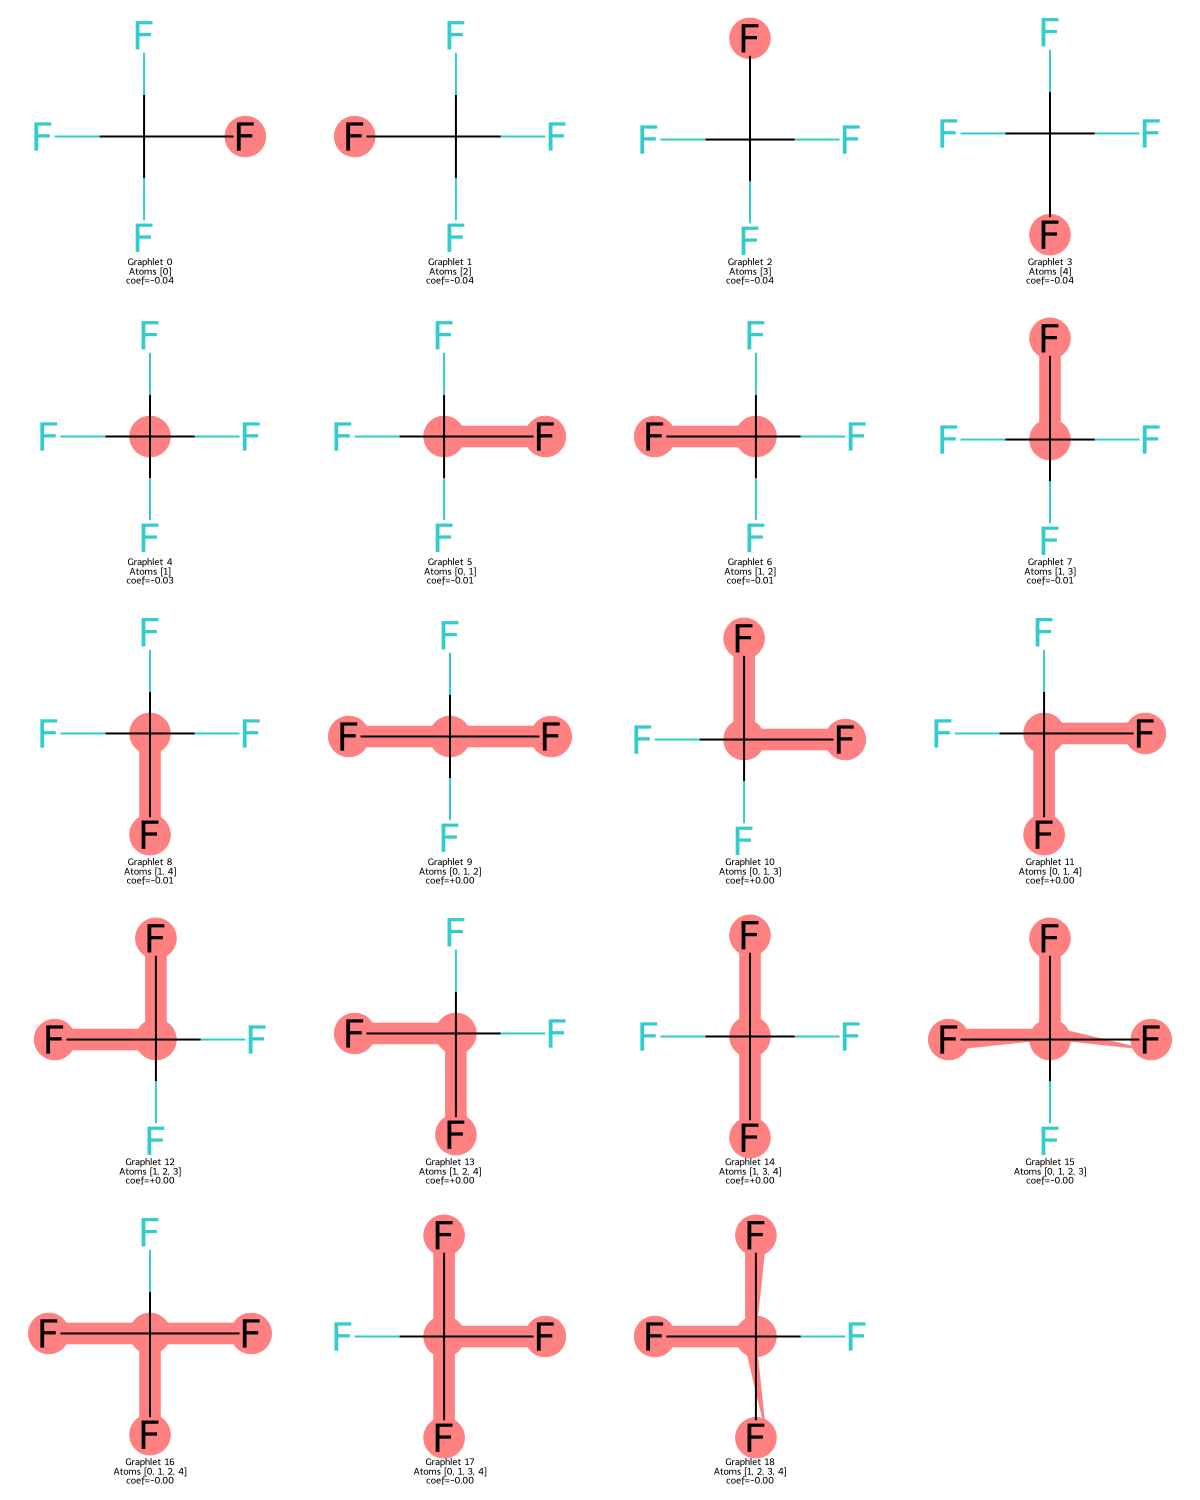

In [ ]:
from rdkit.Chem import Draw

cf4 = Chem.MolFromSmiles("FC(F)(F)F")

cf4_graph = smiles_to_buhito_graph(
    "FC(F)(F)F",
    add_hs=False,
    output_2d_pos=False,
)

interpreter_full.register_graph(
    cf4,
    cf4_graph,
)

# Enumerate all graphlet instances, including those whose coefficients are zero.
instances = interpreter_full.enumerate_graphlet_instances(
    cf4,
    include_zero_coefficients=True,
)

print("All graphlet instances:", len(instances))

if not instances:
    print("No graphlet instances found.")

else:
    mols = []
    legends = []
    highlight_atoms = []

    for i, inst in enumerate(instances):
        atoms = sorted(inst["atoms"])

        mols.append(cf4)
        highlight_atoms.append(atoms)

        legends.append(
            f"Graphlet {i}\n"
            f"Atoms {atoms}\n"
            f"coef={inst['coefficient']:+.2f}"
        )

    image = Draw.MolsToGridImage(
        mols,
        molsPerRow=4,
        subImgSize=(300, 300),
        legends=legends,
        highlightAtomLists=highlight_atoms,
    )

    display(image)

In [ ]:
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    validate_partition_decomposition,
)


# =============================================================================
# CONFIGURATION
# =============================================================================

RANDOM_SEED = 42
N_SAMPLE = min(20, len(test))
GREEDY_ITERATIONS = 100

MH_ITERATIONS = 1000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

MAX_PARTITIONS = 5


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False):
    result = smiles_to_nx(smiles, add_hs=add_hs, output_2d_pos=output_2d_pos)
    return result[0] if isinstance(result, (tuple, list)) else result


def register_buhito_graph(interpreter, mol, smiles):
    graph = smiles_to_buhito_graph(smiles, add_hs=True)

    expected = set(range(mol.GetNumAtoms()))
    actual = set(map(int, graph.nodes))

    if actual != expected:
        raise ValueError(
            f"Buhito/RDKit atom mismatch for {smiles}: "
            f"missing={sorted(expected - actual)}, "
            f"extra={sorted(actual - expected)}"
        )

    interpreter.register_graph(mol, graph)
    return graph


# =============================================================================
# SAMPLE MOLECULES
# =============================================================================

sample_indices = np.random.RandomState(RANDOM_SEED).choice(
    len(test),
    size=N_SAMPLE,
    replace=False,
)

sample_mols = [test.iloc[i]["mol"] for i in sample_indices]
sample_smiles = [test.iloc[i]["smiles"] for i in sample_indices]


# =============================================================================
# OPTIMIZER
# =============================================================================

greedy_optimizer = PartitionOptimizer(
    interpreter=interpreter,
    max_partitions=MAX_PARTITIONS,
)


# =============================================================================
# LOCAL OPTIMIZER HELPERS
# =============================================================================

def create_local_optimizer(optimizer, k):
    kwargs = {
        "interpreter": optimizer.interpreter,
        "min_partitions": k,
        "max_partitions": k,
    }

    if hasattr(optimizer, "connectivity_weight"):
        kwargs["connectivity_weight"] = optimizer.connectivity_weight

    if hasattr(optimizer, "disconnected_singleton_weight"):
        kwargs["disconnected_singleton_weight"] = optimizer.disconnected_singleton_weight

    return PartitionOptimizer(**kwargs)


def run_greedy_random(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_random(
        mol=mol,
        n_iterations=GREEDY_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_greedy_distance(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_distance(
        mol=mol,
        n_clusters=k,
        n_iterations=GREEDY_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_metropolis_hastings(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_metropolis_hastings(
        mol=mol,
        n_clusters=k,
        n_iterations=MH_ITERATIONS,
        beta=MH_BETA,
        initialization=MH_INITIALIZATION,
        seed=MH_SEED,
        verbose=False,
    ).partition


# =============================================================================
# STRATEGIES
# =============================================================================

strategies = {
    "Distance (k=2)": lambda mol: ChemicalPartitioner.distance_partition(
        mol,
        n_clusters=2,
        seed=RANDOM_SEED,
    ),

    "Distance (k=3)": lambda mol: ChemicalPartitioner.distance_partition(
        mol,
        n_clusters=3,
        seed=RANDOM_SEED,
    ),

    "Random (k=2)": lambda mol: ChemicalPartitioner.random_partition(
        mol,
        n_clusters=2,
        seed=RANDOM_SEED,
    ),

    "Random (k=3)": lambda mol: ChemicalPartitioner.random_partition(
        mol,
        n_clusters=3,
        seed=RANDOM_SEED,
    ),

    "Greedy-Random (k=2)": lambda mol: run_greedy_random(
        greedy_optimizer,
        mol,
        2,
    ),

    "Greedy-Random (k=3)": lambda mol: run_greedy_random(
        greedy_optimizer,
        mol,
        3,
    ),

    "Greedy-Random (k=4)": lambda mol: run_greedy_random(
        greedy_optimizer,
        mol,
        4,
    ),

    "Greedy-Distance (k=2)": lambda mol: run_greedy_distance(
        greedy_optimizer,
        mol,
        2,
    ),

    "Greedy-Distance (k=3)": lambda mol: run_greedy_distance(
        greedy_optimizer,
        mol,
        3,
    ),

    "Greedy-Distance (k=4)": lambda mol: run_greedy_distance(
        greedy_optimizer,
        mol,
        4,
    ),

    "Metropolis-Hastings (k=2)": lambda mol: run_metropolis_hastings(
        greedy_optimizer,
        mol,
        2,
    ),

    "Metropolis-Hastings (k=3)": lambda mol: run_metropolis_hastings(
        greedy_optimizer,
        mol,
        3,
    ),

    "Metropolis-Hastings (k=4)": lambda mol: run_metropolis_hastings(
        greedy_optimizer,
        mol,
        4,
    ),
}


# =============================================================================
# RUN ANALYSIS
# =============================================================================

all_results = defaultdict(list)

print("=" * 80)
print(f"PARTITION STRATEGY ANALYSIS ({N_SAMPLE} molecules)")
print("=" * 80)

for mol_idx, (mol, smiles) in enumerate(zip(sample_mols, sample_smiles)):

    # Critical Buhito step:
    # register the atom-level graph before any optimizer or contribution call.
    register_buhito_graph(interpreter, mol, smiles)

    if (mol_idx + 1) % 10 == 0:
        print(f"Processed {mol_idx + 1}/{N_SAMPLE} molecules")

    for strategy_name, partition_fn in strategies.items():

        try:
            requested_k = int(strategy_name.split("k=")[1].rstrip(")"))

            if requested_k > mol.GetNumAtoms():
                continue

            partition = partition_fn(mol)
            actual_k = len(set(partition.values()))

            if actual_k != requested_k:
                print(
                    f"Skipping {strategy_name} for molecule {mol_idx}: "
                    f"requested k={requested_k}, actual k={actual_k}"
                )
                continue

            interp = interpreter.compute_partition_contributions(
                mol,
                partition,
            )

            breakdown = interp.get_contribution_breakdown()

            validation = validate_partition_decomposition(
                mol,
                interpreter,
                partition,
                tolerance=1e-2,
            )

            all_results[strategy_name].append({
                "mol_idx": mol_idx,
                "smiles": smiles,
                "n_atoms": mol.GetNumAtoms(),
                "k_requested": requested_k,
                "n_partitions": actual_k,
                "score": interp.score,
                "within_frac": breakdown["within_frac"],
                "between_frac": breakdown["between_frac"],
                "higher_frac": breakdown["higher_frac"],
                "prediction": interp.total_prediction,
                "validation_passed": validation["passed"],
                "validation_error": validation["relative_error"],
            })

        except Exception as error:
            print(
                f"Warning: {strategy_name}; molecule {mol_idx} "
                f"({smiles}): {error}"
            )


# =============================================================================
# SUMMARY TABLE
# =============================================================================

summary_rows = []

for strategy_name in strategies:

    results = all_results[strategy_name]

    if not results:
        continue

    df = pd.DataFrame(results)

    summary_rows.append({
        "Strategy": strategy_name,
        "N molecules": len(df),
        "Mean Score": df["score"].mean(),
        "Std Score": df["score"].std(),
        "Min Score": df["score"].min(),
        "Max Score": df["score"].max(),
        "Median Score": df["score"].median(),
        "Mean Within %": 100 * df["within_frac"].mean(),
        "Mean Between %": 100 * df["between_frac"].mean(),
        "Mean Higher %": 100 * df["higher_frac"].mean(),
        "Validation Pass %": 100 * df["validation_passed"].mean(),
        "Mean Val Error": df["validation_error"].mean(),
    })

summary_df = pd.DataFrame(summary_rows)

if summary_df.empty:
    raise ValueError("No valid strategy results were produced.")

summary_df = summary_df.sort_values(
    "Mean Score",
    ascending=False,
).reset_index(drop=True)

print("\n" + "=" * 80)
print("SUMMARY BY STRATEGY")
print("=" * 80)
print(summary_df.to_string(index=False))


# =============================================================================
# MOLECULE SIZE ANALYSIS
# =============================================================================

all_mol_rows = []

for strategy_name, results in all_results.items():
    for result in results:
        all_mol_rows.append({
            "strategy": strategy_name,
            "n_atoms": result["n_atoms"],
            "score": result["score"],
        })

df_all = pd.DataFrame(all_mol_rows)

size_bins = [0, 10, 20, 30, 100]
size_labels = [
    "Small (≤10)",
    "Medium (11-20)",
    "Large (21-30)",
    "Very Large (>30)",
]

if not df_all.empty:

    df_all["size_bin"] = pd.cut(
        df_all["n_atoms"],
        bins=size_bins,
        labels=size_labels,
        include_lowest=True,
    )

    size_breakdown = (
        df_all
        .groupby(
            ["size_bin", "strategy"],
            observed=False,
        )["score"]
        .agg(["mean", "std", "count"])
        .reset_index()
        .sort_values(
            ["size_bin", "mean"],
            ascending=[True, False],
        )
    )

    print("\n" + "=" * 80)
    print("SCORE BY MOLECULE SIZE")
    print("=" * 80)
    print(size_breakdown.to_string(index=False))


# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def get_strategy_color(name):
    if "Metropolis-Hastings" in name:
        return "#1abc9c"

    if "Greedy-Random" in name:
        return "#e74c3c"

    if "Greedy-Distance" in name:
        return "#9b59b6"

    if name.startswith("Random"):
        return "#95a5a6"

    if name.startswith("Distance"):
        return "#3498db"

    return "#bdc3c7"


# =============================================================================
# VALID STRATEGIES
# =============================================================================

strategy_names = [
    name
    for name in strategies
    if all_results[name]
]

if not strategy_names:
    raise ValueError(
        "No valid strategy results are available for plotting."
    )


# =============================================================================
# FIGURE
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 7),
)


# -----------------------------------------------------------------------------
# SCORE DISTRIBUTION
# -----------------------------------------------------------------------------

ax = axes[0]

strategy_scores = [
    [
        result["score"]
        for result in all_results[name]
    ]
    for name in strategy_names
]

boxplot = ax.boxplot(
    strategy_scores,
    tick_labels=strategy_names,
    patch_artist=True,
    showmeans=True,
    meanprops={
        "marker": "o",
        "markerfacecolor": "black",
        "markeredgecolor": "black",
        "markersize": 6,
    },
    medianprops={
        "color": "black",
        "linewidth": 1.5,
    },
)

for name, box in zip(
    strategy_names,
    boxplot["boxes"],
):
    box.set_facecolor(
        get_strategy_color(name)
    )
    box.set_alpha(0.75)

ax.set_ylabel(
    'Raw Interpretability Score',
    fontsize=20,
)

ax.set_title(
    ("Score Distribution by Strategy") + "\n" + RAW_SCORE_SUBTITLE,
    fontsize=24,
    fontweight="bold",
)

ax.tick_params(
    axis="x",
    labelrotation=45,
    labelsize=18,
)

for label in ax.get_xticklabels():
    label.set_horizontalalignment("right")

ax.grid(
    axis="y",
    alpha=0.3,
)


# -----------------------------------------------------------------------------
# CONTRIBUTION BREAKDOWN
# -----------------------------------------------------------------------------

ax = axes[1]

within_means = [
    np.mean([
        result["within_frac"]
        for result in all_results[name]
    ])
    for name in strategy_names
]

between_means = [
    np.mean([
        result["between_frac"]
        for result in all_results[name]
    ])
    for name in strategy_names
]

higher_means = [
    np.mean([
        result["higher_frac"]
        for result in all_results[name]
    ])
    for name in strategy_names
]

x = np.arange(
    len(strategy_names)
)

bar_width = 0.25

ax.bar(
    x - bar_width,
    within_means,
    bar_width,
    label="Within",
    alpha=0.85,
)

ax.bar(
    x,
    between_means,
    bar_width,
    label="Between",
    alpha=0.85,
)

ax.bar(
    x + bar_width,
    higher_means,
    bar_width,
    label="Higher-order",
    alpha=0.85,
)

ax.set_ylabel(
    'Mean Absolute-Contribution Fraction',
    fontsize=18,
)

ax.set_title(
    ("Mean Contribution Breakdown") + "\n" + MAGNITUDE_SUBTITLE,
    fontsize=24,
    fontweight="bold",
)

ax.set_xticks(x)

ax.set_xticklabels(
    strategy_names,
    rotation=45,
    ha="right",
    fontsize=18,
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3,
)


# =============================================================================
# FINAL FIGURE FORMATTING
# =============================================================================

fig.suptitle(
    "Partition Strategy Performance",
    fontsize=24,
    fontweight="bold",
    y=1.02,
)

plt.tight_layout()

output_filename = (
    "partition_interpretability_"
    "score_and_contributions_both_greedy_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)

plt.show()


# =============================================================================
# EXPORT DETAILED RESULTS
# =============================================================================

all_results_flat = []

for strategy_name, results in all_results.items():

    for result in results:

        row = result.copy()

        row["strategy"] = strategy_name
        row["method"] = strategy_name.split(" (")[0]

        row["is_greedy_random"] = (
            "Greedy-Random"
            in strategy_name
        )

        row["is_greedy_distance"] = (
            "Greedy-Distance"
            in strategy_name
        )

        row["is_metropolis_hastings"] = (
            "Metropolis-Hastings"
            in strategy_name
        )

        row["is_greedy"] = (
            row["is_greedy_random"]
            or row["is_greedy_distance"]
        )

        all_results_flat.append(row)


df_export = pd.DataFrame(
    all_results_flat
)

df_export.to_csv(csv_dir /
    "partition_interpretability_"
    "detailed_results_both_greedy_e_homo.csv",
    index=False,
)

summary_df.to_csv(csv_dir /
    "partition_interpretability_"
    "summary_both_greedy_e_homo.csv",
    index=False,
)

print(
    "\nSaved detailed and summary CSV files."
)

In [ ]:
from collections import defaultdict
from scipy import stats

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    ChemicalPartitioner,
    validate_partition_decomposition,
)


# =============================================================================
# CONFIGURATION
# =============================================================================

RANDOM_SEED = 42
N_SAMPLE = min(20, len(test))
K_VALUES = tuple(range(2, 8))

GREEDY_ITERATIONS = 100

MH_ITERATIONS = 500
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

METHODS = (
    "Distance",
    "Random",
    "Greedy-Random",
    "Greedy-Distance",
    "Metropolis-Hastings",
)


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False):
    result = smiles_to_nx(smiles, add_hs=add_hs, output_2d_pos=output_2d_pos)
    return result[0] if isinstance(result, (tuple, list)) else result


def register_buhito_graph(interpreter, mol, smiles):
    graph = smiles_to_buhito_graph(smiles, add_hs=True)

    expected = set(range(mol.GetNumAtoms()))
    actual = set(map(int, graph.nodes))

    if actual != expected:
        raise ValueError(
            f"Buhito/RDKit atom mismatch for {smiles}: "
            f"missing={sorted(expected - actual)}, "
            f"extra={sorted(actual - expected)}"
        )

    interpreter.register_graph(mol, graph)
    return graph


# =============================================================================
# OPTIONAL K HEURISTIC
# =============================================================================

def determine_max_k_for_molecule(mol):
    n_atoms = mol.GetNumAtoms()
    return min(max(2, n_atoms // 2), 10)


# =============================================================================
# SAMPLE MOLECULES
# =============================================================================

sample_indices = np.random.RandomState(RANDOM_SEED).choice(
    len(test),
    size=N_SAMPLE,
    replace=False,
)

sample_mols = [test.iloc[i]["mol"] for i in sample_indices]
sample_smiles = [test.iloc[i]["smiles"] for i in sample_indices]

print("=" * 80)
print(f"COMPREHENSIVE K-VALUE ANALYSIS ({N_SAMPLE} molecules)")
print("=" * 80)
print(f"\nTesting k values: {list(K_VALUES)}")


# =============================================================================
# INTERPRETER + OPTIMIZER
# =============================================================================

# Reuse your existing interpreter if already defined.
# Otherwise create it here.
if "interpreter" not in globals():
    interpreter = PartitionInterpreter(
        featurizer=featurizer,
        model=hmodel,
        remove_single_atom_contributions=False,
    )

greedy_optimizer = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=min(K_VALUES),
    max_partitions=max(K_VALUES),
)


# =============================================================================
# LOCAL OPTIMIZER HELPERS
# =============================================================================

def create_local_optimizer(optimizer, k):
    kwargs = {
        "interpreter": optimizer.interpreter,
        "min_partitions": k,
        "max_partitions": k,
    }

    if hasattr(optimizer, "connectivity_weight"):
        kwargs["connectivity_weight"] = optimizer.connectivity_weight

    if hasattr(optimizer, "disconnected_singleton_weight"):
        kwargs["disconnected_singleton_weight"] = optimizer.disconnected_singleton_weight

    return PartitionOptimizer(**kwargs)


def run_greedy_random(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_random(
        mol=mol,
        n_iterations=GREEDY_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_greedy_distance(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_distance(
        mol=mol,
        n_clusters=k,
        n_iterations=GREEDY_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_metropolis_hastings(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_metropolis_hastings(
        mol=mol,
        n_clusters=k,
        n_iterations=MH_ITERATIONS,
        beta=MH_BETA,
        initialization=MH_INITIALIZATION,
        seed=MH_SEED,
        verbose=False,
    ).partition

# =============================================================================
# STRATEGIES
# =============================================================================

strategies = {}

for k in K_VALUES:
    strategies[f"Distance (k={k})"] = lambda mol, k=k: (
        ChemicalPartitioner.distance_partition(
            mol,
            n_clusters=k,
            seed=RANDOM_SEED,
        )
    )

    strategies[f"Random (k={k})"] = lambda mol, k=k: (
        ChemicalPartitioner.random_partition(
            mol,
            n_clusters=k,
            seed=RANDOM_SEED,
        )
    )

    strategies[f"Greedy-Random (k={k})"] = lambda mol, k=k: (
        run_greedy_random(greedy_optimizer, mol, k)
    )

    strategies[f"Greedy-Distance (k={k})"] = lambda mol, k=k: (
        run_greedy_distance(greedy_optimizer, mol, k)
    )

    strategies[f"Metropolis-Hastings (k={k})"] = lambda mol, k=k: (
        run_metropolis_hastings(greedy_optimizer, mol, k)
    )


print(f"\nTotal strategies: {len(strategies)}")

for method in METHODS:
    print(f"  {method:22s}: {len(K_VALUES)}")

print(
    f"  MH settings: iterations={MH_ITERATIONS}, "
    f"beta={MH_BETA}, "
    f"initialization={MH_INITIALIZATION}"
)

# =============================================================================
# COLLECT RESULTS
# =============================================================================

all_results = defaultdict(list)

print("\nComputing interpretability scores...")

for mol_idx, (mol, smiles) in enumerate(zip(sample_mols, sample_smiles)):

    # Critical Buhito step
    register_buhito_graph(interpreter, mol, smiles)

    if (mol_idx + 1) % 10 == 0:
        print(f"  Processed {mol_idx + 1}/{N_SAMPLE} molecules")

    for strategy_name, partition_fn in strategies.items():

        try:
            requested_k = int(strategy_name.split("k=")[1].rstrip(")"))

            if requested_k > mol.GetNumAtoms():
                continue

            partition = partition_fn(mol)
            actual_k = len(set(partition.values()))

            if actual_k != requested_k:
                print(
                    f"  Skipping {strategy_name} for molecule {mol_idx}: "
                    f"requested k={requested_k}, actual k={actual_k}"
                )
                continue

            interpretation = interpreter.compute_partition_contributions(
                mol,
                partition,
            )

            breakdown = interpretation.get_contribution_breakdown()

            validation = validate_partition_decomposition(
                mol,
                interpreter,
                partition,
                tolerance=1e-2,
            )

            all_results[strategy_name].append({
                "mol_idx": mol_idx,
                "smiles": smiles,
                "n_atoms": mol.GetNumAtoms(),
                "n_partitions": actual_k,
                "k_requested": requested_k,
                "score": interpretation.score,
                "within_frac": breakdown["within_frac"],
                "between_frac": breakdown["between_frac"],
                "higher_frac": breakdown["higher_frac"],
                "prediction": interpretation.total_prediction,
                "validation_passed": validation["passed"],
                "validation_error": validation["relative_error"],
            })

        except Exception as error:
            print(
                f"  Warning: Failed {strategy_name} "
                f"for molecule {mol_idx} ({smiles}): {error}"
            )

# =============================================================================
# SUMMARY BY STRATEGY
# =============================================================================

summary_rows = []

for strategy_name in strategies:
    results = all_results[strategy_name]

    if not results:
        continue

    df = pd.DataFrame(results)

    summary_rows.append({
        "Strategy": strategy_name,
        "N_molecules": len(df),
        "Mean Score": df["score"].mean(),
        "Std Score": df["score"].std(),
        "Min Score": df["score"].min(),
        "Max Score": df["score"].max(),
        "Median Score": df["score"].median(),
        "Mean Within %": 100 * df["within_frac"].mean(),
        "Mean Between %": 100 * df["between_frac"].mean(),
        "Mean Higher %": 100 * df["higher_frac"].mean(),
        "Validation Pass %": 100 * df["validation_passed"].mean(),
    })

summary_df = pd.DataFrame(summary_rows)

if summary_df.empty:
    raise ValueError("No valid strategy results were produced.")

summary_df = summary_df.sort_values(
    "Mean Score",
    ascending=False,
).reset_index(drop=True)

print("\n" + "=" * 80)
print("SUMMARY BY STRATEGY")
print("=" * 80)
print(summary_df.to_string(index=False))

# =============================================================================
# OPTIMAL K ANALYSIS
# =============================================================================

k_analysis = defaultdict(lambda: defaultdict(list))

for strategy_name, results in all_results.items():
    method = strategy_name.split(" (")[0]
    k = int(strategy_name.split("k=")[1].rstrip(")"))

    for result in results:
        k_analysis[method][k].append(result["score"])


k_summary_rows = []

print("\n" + "=" * 80)
print("OPTIMAL K ANALYSIS")
print("=" * 80)

print("\n1. MEAN SCORE BY K VALUE:\n")

for method in METHODS:
    if method not in k_analysis:
        continue

    print(f"{method}:")

    for k in sorted(k_analysis[method]):
        scores = k_analysis[method][k]
        mean_score = np.mean(scores)
        std_score = np.std(scores)

        k_summary_rows.append({
            "Method": method,
            "k": k,
            "Mean Score": mean_score,
            "Std Score": std_score,
            "N": len(scores),
        })

        print(f"  k={k}: {mean_score:.4f} ± {std_score:.4f}")

    print()


k_summary_df = pd.DataFrame(k_summary_rows)

if k_summary_df.empty:
    raise ValueError("No valid k-dependent results were produced.")

# =============================================================================
# BEST K + SIGNIFICANCE
# =============================================================================

print("2. OPTIMAL K BY METHOD:\n")

for method in METHODS:

    method_data = k_summary_df[
        k_summary_df["Method"] == method
    ]

    if method_data.empty:
        continue

    best_row = method_data.loc[
        method_data["Mean Score"].idxmax()
    ]

    best_k = int(best_row["k"])
    best_score = best_row["Mean Score"]
    best_scores = k_analysis[method][best_k]

    print(f"{method}:")
    print(f"  Best k: {best_k}")
    print(f"  Score: {best_score:.4f}")
    print("  Comparisons to other k values:")

    for k in sorted(k_analysis[method]):

        if k == best_k:
            continue

        other_scores = k_analysis[method][k]

        _, p_value = stats.ttest_ind(
            best_scores,
            other_scores,
            equal_var=False,
        )

        difference = np.mean(best_scores) - np.mean(other_scores)

        significance = (
            "***" if p_value < 0.001
            else "**" if p_value < 0.01
            else "*" if p_value < 0.05
            else ""
        )

        print(
            f"    vs k={k}: "
            f"Δ={difference:+.4f}, "
            f"p={p_value:.4f} {significance}"
        )

    print()
# =============================================================================
# PLOTTING
# =============================================================================

def get_plot_style(method):
    if method == "Greedy-Random":
        return {"linestyle": "-", "marker": "D", "linewidth": 3, "markersize": 8}

    if method == "Greedy-Distance":
        return {"linestyle": "--", "marker": "s", "linewidth": 3, "markersize": 8}

    if method == "Metropolis-Hastings":
        return {"linestyle": "-.", "marker": "^", "linewidth": 3, "markersize": 9}

    if method == "Distance":
        return {"linestyle": ":", "marker": "o", "linewidth": 2, "markersize": 8}

    return {"linestyle": ":", "marker": "v", "linewidth": 2, "markersize": 8}


def collect_metric_by_k(results, method, metric):
    values = defaultdict(list)
    prefix = f"{method} (k="

    for name, rows in results.items():
        if not name.startswith(prefix):
            continue

        k = int(name.split("k=")[1].rstrip(")"))

        for row in rows:
            values[k].append(row[metric])

    return values

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 6),
)


# -----------------------------------------------------------------------------
# SCORE VS K
# -----------------------------------------------------------------------------

ax = axes[0]

for method in METHODS:
    if method not in k_analysis:
        continue

    ks = sorted(k_analysis[method])

    if not ks:
        continue

    means = np.array([
        np.mean(k_analysis[method][k])
        for k in ks
    ])

    stds = np.array([
        np.std(k_analysis[method][k])
        for k in ks
    ])

    ax.plot(
        ks,
        means,
        label=method,
        **get_plot_style(method),
    )

    ax.fill_between(
        ks,
        means - stds,
        means + stds,
        alpha=0.2,
    )

ax.set_xlabel("Number of Partitions (k)")
ax.set_ylabel('Mean Raw Interpretability Score')
ax.set_title(("Interpretability Score vs k") + "\n" + RAW_SCORE_SUBTITLE, fontweight="bold")
ax.set_xticks(K_VALUES)
ax.legend()
ax.grid(alpha=0.3)


# -----------------------------------------------------------------------------
# WITHIN FRACTION VS K
# -----------------------------------------------------------------------------

ax = axes[1]

for method in METHODS:
    values = collect_metric_by_k(
        all_results,
        method,
        "within_frac",
    )

    if not values:
        continue

    ks = sorted(values)

    means = np.array([
        np.mean(values[k])
        for k in ks
    ])

    stds = np.array([
        np.std(values[k])
        for k in ks
    ])

    ax.plot(
        ks,
        means,
        label=method,
        **get_plot_style(method),
    )

    ax.fill_between(
        ks,
        means - stds,
        means + stds,
        alpha=0.2,
    )

ax.set_xlabel("Number of Partitions (k)")
ax.set_ylabel('Mean Within Magnitude Fraction (w)')
ax.set_title(("Within-Partition Contribution vs k") + "\n" + MAGNITUDE_SUBTITLE, fontweight="bold")
ax.set_xticks(K_VALUES)
ax.legend()
ax.grid(alpha=0.3)


# -----------------------------------------------------------------------------
# HIGHER-ORDER FRACTION VS K
# -----------------------------------------------------------------------------

ax = axes[2]

for method in METHODS:
    values = collect_metric_by_k(
        all_results,
        method,
        "higher_frac",
    )

    if not values:
        continue

    ks = sorted(values)

    means = np.array([
        np.mean(values[k])
        for k in ks
    ])

    stds = np.array([
        np.std(values[k])
        for k in ks
    ])

    ax.plot(
        ks,
        means,
        label=method,
        **get_plot_style(method),
    )

    ax.fill_between(
        ks,
        means - stds,
        means + stds,
        alpha=0.2,
    )

ax.set_xlabel("Number of Partitions (k)")
ax.set_ylabel('Mean Higher Magnitude Fraction (h)')
ax.set_title(("Higher-Order Contribution vs k") + "\n" + MAGNITUDE_SUBTITLE, fontweight="bold")
ax.set_xticks(K_VALUES)
ax.legend()
ax.grid(alpha=0.3)


fig.suptitle(
    "Effect of Partition Count on Interpretability",
    fontsize=17,
    fontweight="bold",
)

plt.tight_layout()

output_filename = "k_value_analysis_e_homo.png"

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(f"\nSaved visualization to '{output_filename}'")

plt.show()

# =============================================================================
# RECOMMENDATIONS
# =============================================================================

best_k_overall = k_summary_df.loc[
    k_summary_df["Mean Score"].idxmax()
]

print("\n" + "=" * 80)
print("RECOMMENDATIONS FOR K SELECTION")
print("=" * 80)

print("\n1. OVERALL BEST K")
print(
    f"   k={int(best_k_overall['k'])} "
    f"using {best_k_overall['Method']}"
)
print(
    f"   Mean Score: "
    f"{best_k_overall['Mean Score']:.4f}"
)


print("\n2. GREEDY STRATEGY COMPARISON")

for k in sorted(k_summary_df["k"].unique()):

    gr = k_summary_df[
        (k_summary_df["Method"] == "Greedy-Random")
        & (k_summary_df["k"] == k)
    ]

    gd = k_summary_df[
        (k_summary_df["Method"] == "Greedy-Distance")
        & (k_summary_df["k"] == k)
    ]

    if gr.empty or gd.empty:
        continue

    gr_score = gr["Mean Score"].iloc[0]
    gd_score = gd["Mean Score"].iloc[0]

    gr_scores = k_analysis["Greedy-Random"].get(k, [])
    gd_scores = k_analysis["Greedy-Distance"].get(k, [])

    if not gr_scores or not gd_scores:
        continue

    _, p_value = stats.ttest_ind(
        gr_scores,
        gd_scores,
        equal_var=False,
    )

    winner = (
        "Greedy-Random"
        if gr_score > gd_score
        else "Greedy-Distance"
    )

    print(
        f"   k={k}: {winner} wins by "
        f"{abs(gr_score - gd_score):.4f} "
        f"(p={p_value:.4f})"
    )

print("\n3. METHOD-SPECIFIC RECOMMENDATIONS")

for method in METHODS:

    method_data = k_summary_df[
        k_summary_df["Method"] == method
    ]

    if method_data.empty:
        continue

    best_row = method_data.loc[
        method_data["Mean Score"].idxmax()
    ]

    best_k = int(best_row["k"])
    best_score = best_row["Mean Score"]

    threshold = 0.95 * best_score

    good_ks = (
        method_data.loc[
            method_data["Mean Score"] >= threshold,
            "k",
        ]
        .astype(int)
        .tolist()
    )

    print(f"\n   {method}:")
    print(f"     Best k: {best_k}")
    print(f"     Mean score: {best_score:.4f}")

    if len(good_ks) > 1:
        print(f"     Reasonable k values: {good_ks}")

# =============================================================================
# EXPORT
# =============================================================================

detailed_rows = []

for strategy_name, results in all_results.items():

    for result in results:
        row = result.copy()

        row["strategy"] = strategy_name
        row["method"] = strategy_name.split(" (")[0]

        row["is_greedy_random"] = (
            "Greedy-Random" in strategy_name
        )

        row["is_greedy_distance"] = (
            "Greedy-Distance" in strategy_name
        )

        row["is_metropolis_hastings"] = (
            "Metropolis-Hastings" in strategy_name
        )

        row["is_greedy"] = (
            row["is_greedy_random"]
            or row["is_greedy_distance"]
        )

        detailed_rows.append(row)


df_export = pd.DataFrame(detailed_rows)

df_export.to_csv(csv_dir /
    "partition_interpretability_all_k_detailed_both_greedy_e_homo.csv",
    index=False,
)

summary_df.to_csv(csv_dir /
    "partition_interpretability_all_k_summary_both_greedy_e_homo.csv",
    index=False,
)

k_summary_df.to_csv(csv_dir /
    "partition_interpretability_k_analysis_both_greedy_e_homo.csv",
    index=False,
)

# =============================================================================
# PER-MOLECULE OPTIMAL K
# =============================================================================

optimal_k_rows = []

for mol_idx in range(N_SAMPLE):

    random_results = [
        result
        for strategy_name, results in all_results.items()
        if "Greedy-Random" in strategy_name
        for result in results
        if result["mol_idx"] == mol_idx
    ]

    distance_results = [
        result
        for strategy_name, results in all_results.items()
        if "Greedy-Distance" in strategy_name
        for result in results
        if result["mol_idx"] == mol_idx
    ]

    if not random_results or not distance_results:
        continue

    best_random = max(
        random_results,
        key=lambda x: x["score"],
    )

    best_distance = max(
        distance_results,
        key=lambda x: x["score"],
    )

    best_method = (
        "Greedy-Random"
        if best_random["score"] > best_distance["score"]
        else "Greedy-Distance"
    )

    optimal_k_rows.append({
        "mol_idx": mol_idx,
        "smiles": best_random["smiles"],
        "n_atoms": best_random["n_atoms"],

        "optimal_k_random": best_random["k_requested"],
        "optimal_score_random": best_random["score"],
        "within_frac_random": best_random["within_frac"],

        "optimal_k_distance": best_distance["k_requested"],
        "optimal_score_distance": best_distance["score"],
        "within_frac_distance": best_distance["within_frac"],

        "best_method": best_method,

        "score_difference": abs(
            best_random["score"]
            - best_distance["score"]
        ),
    })


df_optimal_k = pd.DataFrame(optimal_k_rows)

df_optimal_k.to_csv(csv_dir /
    "partition_interpretability_optimal_k_per_molecule_both_greedy_e_homo.csv",
    index=False,
)

if len(df_optimal_k) > 5:

    correlation_random = (
        df_optimal_k[
            ["n_atoms", "optimal_k_random"]
        ]
        .corr()
        .iloc[0, 1]
    )

    correlation_distance = (
        df_optimal_k[
            ["n_atoms", "optimal_k_distance"]
        ]
        .corr()
        .iloc[0, 1]
    )

    print("\n" + "=" * 80)
    print("K VS MOLECULE SIZE")
    print("=" * 80)

    print(
        f"Greedy-Random correlation: "
        f"{correlation_random:.3f}"
    )

    print(
        f"Greedy-Distance correlation: "
        f"{correlation_distance:.3f}"
    )

else:
    print(
        "\nSkipping k-vs-molecule-size analysis: "
        "fewer than six molecules have valid optimal-k results."
    )

# =============================================================================
# GREEDY COMPARISON
# =============================================================================

greedy_comparison_rows = []

for k in sorted(k_summary_df["k"].unique()):

    gr = k_summary_df[
        (k_summary_df["Method"] == "Greedy-Random")
        & (k_summary_df["k"] == k)
    ]

    gd = k_summary_df[
        (k_summary_df["Method"] == "Greedy-Distance")
        & (k_summary_df["k"] == k)
    ]

    if gr.empty or gd.empty:
        continue

    gr_score = gr["Mean Score"].iloc[0]
    gd_score = gd["Mean Score"].iloc[0]

    greedy_comparison_rows.append({
        "k": int(k),
        "Greedy-Random Score": gr_score,
        "Greedy-Distance Score": gd_score,
        "Difference": gr_score - gd_score,
        "Winner": (
            "Greedy-Random"
            if gr_score > gd_score
            else "Greedy-Distance"
        ),
    })


df_greedy_comparison = pd.DataFrame(
    greedy_comparison_rows
)

df_greedy_comparison.to_csv(csv_dir /
    "partition_interpretability_greedy_comparison_e_homo.csv",
    index=False,
)

# =============================================================================
# FINAL SUMMARY
# =============================================================================

print("\n" + "=" * 80)
print("COMPREHENSIVE ANALYSIS COMPLETE")
print("=" * 80)

best_overall = summary_df.iloc[0]

print("\n1. BEST OVERALL STRATEGY")
print(f"   Strategy: {best_overall['Strategy']}")
print(
    f"   Mean Score: "
    f"{best_overall['Mean Score']:.4f} ± "
    f"{best_overall['Std Score']:.4f}"
)
print(
    f"   Within-partition: "
    f"{best_overall['Mean Within %']:.1f}%"
)
print(
    f"   Between-partition: "
    f"{best_overall['Mean Between %']:.1f}%"
)
print(
    f"   Higher-order: "
    f"{best_overall['Mean Higher %']:.1f}%"
)


print("\n2. OPTIMAL K BY METHOD")

for method in METHODS:

    method_data = k_summary_df[
        k_summary_df["Method"] == method
    ]

    if method_data.empty:
        continue

    best_row = method_data.loc[
        method_data["Mean Score"].idxmax()
    ]

    print(
        f"   {method:22s}: "
        f"k={int(best_row['k'])}, "
        f"score={best_row['Mean Score']:.4f}"
    )


print("\n3. GREEDY-RANDOM VS GREEDY-DISTANCE")

if not df_optimal_k.empty:

    wins = df_optimal_k[
        "best_method"
    ].value_counts()

    random_wins = int(
        wins.get(
            "Greedy-Random",
            0,
        )
    )

    distance_wins = int(
        wins.get(
            "Greedy-Distance",
            0,
        )
    )

    total = len(df_optimal_k)

    print(
        f"   Greedy-Random wins: "
        f"{random_wins}/{total} "
        f"({100 * random_wins / total:.1f}%)"
    )

    print(
        f"   Greedy-Distance wins: "
        f"{distance_wins}/{total} "
        f"({100 * distance_wins / total:.1f}%)"
    )

    print(
        f"   Mean score difference: "
        f"{df_optimal_k['score_difference'].mean():.4f}"
    )


print("\n4. VALIDATION")

if not df_export.empty:

    validation_rate = (
        df_export[
            "validation_passed"
        ].mean()
    )

    mean_validation_error = (
        df_export[
            "validation_error"
        ].mean()
    )

    print(
        f"   Validation pass rate: "
        f"{100 * validation_rate:.1f}%"
    )

    print(
        f"   Mean validation error: "
        f"{mean_validation_error:.2e}"
    )





In [ ]:
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    ChemicalPartitioner,
    validate_partition_decomposition,
)


# =============================================================================
# CONFIGURATION
# =============================================================================

RANDOM_SEED = 42
N_ITERATIONS = 100
MAX_PARTITIONS = 5
N_SAMPLE = min(20, len(test))


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(
    smiles,
    add_hs=False,
    output_2d_pos=False,
):
    """
    Convert a SMILES string to the atom-level Buhito/NetworkX graph.

    smiles_to_nx() may return either:
        graph

    or:
        (graph, ...)
    """
    result = smiles_to_nx(
        smiles,
        add_hs=add_hs,
        output_2d_pos=output_2d_pos,
    )

    return (
        result[0]
        if isinstance(result, (tuple, list))
        else result
    )


def register_buhito_graph(
    interpreter,
    mol,
    smiles,
):
    """
    Build and register the atom-level Buhito graph corresponding
    exactly to the supplied RDKit molecule.

    The QM9 molecules used here contain explicit hydrogens, so
    add_hs=True is required when reconstructing the Buhito graph.
    """

    graph = smiles_to_buhito_graph(
        smiles,
        add_hs=True,
        output_2d_pos=False,
    )

    # ---------------------------------------------------------
    # Verify that Buhito node IDs exactly match RDKit atom IDs
    # ---------------------------------------------------------

    expected_nodes = set(
        range(mol.GetNumAtoms())
    )

    actual_nodes = set(
        map(int, graph.nodes)
    )

    if actual_nodes != expected_nodes:

        missing_nodes = (
            expected_nodes - actual_nodes
        )

        extra_nodes = (
            actual_nodes - expected_nodes
        )

        raise ValueError(
            f"Buhito/RDKit atom mismatch for {smiles}. "
            f"RDKit has {mol.GetNumAtoms()} atoms; "
            f"Buhito graph has {len(actual_nodes)} nodes. "
            f"Missing={sorted(missing_nodes)}; "
            f"extra={sorted(extra_nodes)}."
        )

    # ---------------------------------------------------------
    # Register graph with PartitionInterpreter
    # ---------------------------------------------------------

    interpreter.register_graph(
        mol,
        graph,
    )

    return graph


# =============================================================================
# CREATE INTERPRETERS
# =============================================================================

# Full interpretation:
# includes single-atom graphlet coefficients.

interpreter_full = PartitionInterpreter(
    featurizer=featurizer,
    model=hmodel,
    remove_single_atom_contributions=False,
)


# Structure-only interpretation:
# size-1 graphlet coefficients are internally set to zero.

interpreter_no_atoms = PartitionInterpreter(
    featurizer=featurizer,
    model=hmodel,
    remove_single_atom_contributions=True,
)


print(
    "Full interpreter single-atom features:",
    len(interpreter_full.atom_level_indices),
)


print(
    "No-atom interpreter zeroed coefficients:",
    np.count_nonzero(
        interpreter_no_atoms.original_coefficients
        != interpreter_no_atoms.coefficients
    ),
)


# =============================================================================
# CREATE GREEDY OPTIMIZERS
# =============================================================================

# Each interpreter gets its own optimizer because the optimization
# objective depends on that interpreter's active coefficients.

greedy_optimizer_full = PartitionOptimizer(
    interpreter=interpreter_full,
    max_partitions=MAX_PARTITIONS,
)


greedy_optimizer_no_atoms = PartitionOptimizer(
    interpreter=interpreter_no_atoms,
    max_partitions=MAX_PARTITIONS,
)


# =============================================================================
# SAMPLE MOLECULES
# =============================================================================

sample_indices = np.random.RandomState(
    RANDOM_SEED
).choice(
    len(test),
    size=N_SAMPLE,
    replace=False,
)


sample_mols = [
    test.iloc[i]["mol"]
    for i in sample_indices
]


sample_smiles = [
    test.iloc[i]["smiles"]
    for i in sample_indices
]


print(
    f"Selected {len(sample_mols)} molecules."
)


# =============================================================================
# GREEDY WRAPPERS
# =============================================================================

def run_greedy_random(
    optimizer,
    mol,
    n_clusters,
    n_iterations=N_ITERATIONS,
    seed=RANDOM_SEED,
    verbose=False,
):
    """
    Run random-initialized greedy optimization while forcing
    exactly n_clusters partitions.
    """

    local_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
    )

    interpretation = (
        local_optimizer.optimize_partition_random(
            mol=mol,
            n_iterations=n_iterations,
            seed=seed,
            verbose=verbose,
        )
    )

    return interpretation.partition


def run_greedy_distance(
    optimizer,
    mol,
    n_clusters,
    n_iterations=N_ITERATIONS,
    seed=RANDOM_SEED,
    verbose=False,
):
    """
    Run distance-initialized greedy optimization while forcing
    exactly n_clusters partitions.
    """

    local_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
    )

    interpretation = (
        local_optimizer.optimize_partition_distance(
            mol=mol,
            n_clusters=n_clusters,
            n_iterations=n_iterations,
            seed=seed,
            verbose=verbose,
        )
    )

    return interpretation.partition


# =============================================================================
# PARTITION STRATEGIES
# =============================================================================

def create_strategies(
    optimizer,
):
    """
    Create the partitioning strategies used in the comparison.
    """

    return {

        # ---------------------------------------------------------------------
        # DISTANCE
        # ---------------------------------------------------------------------

        "Distance (k=2)": (
            lambda mol:
            ChemicalPartitioner.distance_partition(
                mol,
                n_clusters=2,
                seed=RANDOM_SEED,
            )
        ),

        "Distance (k=3)": (
            lambda mol:
            ChemicalPartitioner.distance_partition(
                mol,
                n_clusters=3,
                seed=RANDOM_SEED,
            )
        ),


        # ---------------------------------------------------------------------
        # RANDOM
        # ---------------------------------------------------------------------

        "Random (k=2)": (
            lambda mol:
            ChemicalPartitioner.random_partition(
                mol,
                n_clusters=2,
                seed=RANDOM_SEED,
            )
        ),

        "Random (k=3)": (
            lambda mol:
            ChemicalPartitioner.random_partition(
                mol,
                n_clusters=3,
                seed=RANDOM_SEED,
            )
        ),


        # ---------------------------------------------------------------------
        # GREEDY — RANDOM INITIALIZATION
        # ---------------------------------------------------------------------

        "Greedy-Random (k=2)": (
            lambda mol:
            run_greedy_random(
                optimizer,
                mol,
                n_clusters=2,
            )
        ),

        "Greedy-Random (k=3)": (
            lambda mol:
            run_greedy_random(
                optimizer,
                mol,
                n_clusters=3,
            )
        ),

        "Greedy-Random (k=4)": (
            lambda mol:
            run_greedy_random(
                optimizer,
                mol,
                n_clusters=4,
            )
        ),


        # ---------------------------------------------------------------------
        # GREEDY — DISTANCE INITIALIZATION
        # ---------------------------------------------------------------------

        "Greedy-Distance (k=2)": (
            lambda mol:
            run_greedy_distance(
                optimizer,
                mol,
                n_clusters=2,
            )
        ),

        "Greedy-Distance (k=3)": (
            lambda mol:
            run_greedy_distance(
                optimizer,
                mol,
                n_clusters=3,
            )
        ),

        "Greedy-Distance (k=4)": (
            lambda mol:
            run_greedy_distance(
                optimizer,
                mol,
                n_clusters=4,
            )
        ),
    }


strategies_full = create_strategies(
    greedy_optimizer_full
)


strategies_no_atoms = create_strategies(
    greedy_optimizer_no_atoms
)


# =============================================================================
# RUN ANALYSIS
# =============================================================================

def run_partition_analysis(
    molecules,
    smiles_list,
    strategies,
    analysis_interpreter,
    analysis_name,
):
    """
    Evaluate all partition strategies using a single
    PartitionInterpreter.
    """

    results_by_strategy = defaultdict(list)

    print(
        "\n" + "=" * 80
    )

    print(
        analysis_name
    )

    print(
        "=" * 80
    )


    # =========================================================================
    # LOOP OVER MOLECULES
    # =========================================================================

    for mol_idx, (mol, smiles) in enumerate(
        zip(
            molecules,
            smiles_list,
        )
    ):

        # ---------------------------------------------------------------------
        # IMPORTANT:
        # Register the atom-level Buhito graph ONCE for this molecule.
        # ---------------------------------------------------------------------

        register_buhito_graph(
            analysis_interpreter,
            mol,
            smiles,
        )


        if (mol_idx + 1) % 10 == 0:

            print(
                f"Processed "
                f"{mol_idx + 1}/{len(molecules)} "
                f"molecules"
            )


        # =====================================================================
        # LOOP OVER PARTITION STRATEGIES
        # =====================================================================

        for (
            strategy_name,
            partition_fn,
        ) in strategies.items():

            try:

                # -------------------------------------------------------------
                # Generate partition
                # -------------------------------------------------------------

                partition = (
                    partition_fn(mol)
                )


                # -------------------------------------------------------------
                # Compute Buhito partition decomposition
                # -------------------------------------------------------------

                interpretation = (
                    analysis_interpreter
                    .compute_partition_contributions(
                        mol,
                        partition,
                    )
                )


                # -------------------------------------------------------------
                # Contribution fractions
                # -------------------------------------------------------------

                breakdown = (
                    interpretation
                    .get_contribution_breakdown()
                )


                # -------------------------------------------------------------
                # Validate reconstruction
                # -------------------------------------------------------------

                validation = (
                    validate_partition_decomposition(
                        mol=mol,
                        interpreter=analysis_interpreter,
                        partition=partition,
                        tolerance=1e-2,
                    )
                )


                # -------------------------------------------------------------
                # Requested number of partitions
                # -------------------------------------------------------------

                requested_k = int(
                    strategy_name
                    .split("k=")[1]
                    .rstrip(")")
                )


                # -------------------------------------------------------------
                # Actual number of partitions
                # -------------------------------------------------------------

                actual_k = len(
                    set(
                        partition.values()
                    )
                )


                # -------------------------------------------------------------
                # Store results
                # -------------------------------------------------------------

                results_by_strategy[
                    strategy_name
                ].append({

                    "mol_idx":
                        mol_idx,

                    "smiles":
                        smiles,

                    "n_atoms":
                        mol.GetNumAtoms(),

                    "k_requested":
                        requested_k,

                    "n_partitions":
                        actual_k,

                    "score":
                        interpretation.score,

                    "within_frac":
                        breakdown[
                            "within_frac"
                        ],

                    "between_frac":
                        breakdown[
                            "between_frac"
                        ],

                    "higher_frac":
                        breakdown[
                            "higher_frac"
                        ],

                    "prediction":
                        interpretation.total_prediction,

                    "atom_baseline":
                        interpretation.atom_baseline,

                    "validation_passed":
                        validation[
                            "passed"
                        ],

                    "validation_error":
                        validation[
                            "relative_error"
                        ],
                })


            except Exception as error:

                print(
                    f"Warning: "
                    f"{analysis_name}; "
                    f"{strategy_name}; "
                    f"molecule {mol_idx} "
                    f"({smiles}): "
                    f"{error}"
                )


    return results_by_strategy


# =============================================================================
# ANALYSIS WITH SINGLE-ATOM CONTRIBUTIONS
# =============================================================================

all_results_full = run_partition_analysis(

    molecules=sample_mols,

    smiles_list=sample_smiles,

    strategies=strategies_full,

    analysis_interpreter=interpreter_full,

    analysis_name=(
        "WITH SINGLE-ATOM CONTRIBUTIONS"
    ),
)


# =============================================================================
# ANALYSIS WITHOUT SINGLE-ATOM CONTRIBUTIONS
# =============================================================================

all_results_no_atoms = run_partition_analysis(

    molecules=sample_mols,

    smiles_list=sample_smiles,

    strategies=strategies_no_atoms,

    analysis_interpreter=interpreter_no_atoms,

    analysis_name=(
        "WITHOUT SINGLE-ATOM CONTRIBUTIONS"
    ),
)


# =============================================================================
# COMMON STRATEGY ORDER
# =============================================================================

strategy_names = [

    strategy_name

    for strategy_name in strategies_full

    if (
        len(
            all_results_full[
                strategy_name
            ]
        ) > 0

        and

        len(
            all_results_no_atoms[
                strategy_name
            ]
        ) > 0
    )
]


if not strategy_names:

    raise ValueError(
        "No strategies produced valid results "
        "in both analyses."
    )


# =============================================================================
# SUMMARY TABLES
# =============================================================================

def create_summary_dataframe(
    results_by_strategy,
    strategy_order,
):
    """
    Create one aggregate summary row for each partition strategy.
    """

    rows = []


    for strategy_name in strategy_order:

        results = (
            results_by_strategy[
                strategy_name
            ]
        )


        if not results:
            continue


        strategy_df = (
            pd.DataFrame(results)
        )


        rows.append({

            "Strategy":
                strategy_name,

            "N molecules":
                len(strategy_df),

            "Mean score":
                strategy_df[
                    "score"
                ].mean(),

            "Score std":
                strategy_df[
                    "score"
                ].std(),

            "Median score":
                strategy_df[
                    "score"
                ].median(),

            "Mean within %":
                100
                * strategy_df[
                    "within_frac"
                ].mean(),

            "Mean between %":
                100
                * strategy_df[
                    "between_frac"
                ].mean(),

            "Mean higher-order %":
                100
                * strategy_df[
                    "higher_frac"
                ].mean(),

            "Mean requested k":
                strategy_df[
                    "k_requested"
                ].mean(),

            "Mean actual k":
                strategy_df[
                    "n_partitions"
                ].mean(),

            "Validation pass %":
                100
                * strategy_df[
                    "validation_passed"
                ].mean(),

            "Mean validation error":
                strategy_df[
                    "validation_error"
                ].mean(),
        })


    summary_df = (
        pd.DataFrame(rows)
    )


    if not summary_df.empty:

        summary_df = (
            summary_df.sort_values(
                "Mean score",
                ascending=False,
            )
        )


    return summary_df


# =============================================================================
# CREATE SUMMARY DATAFRAMES
# =============================================================================

summary_df_full = (
    create_summary_dataframe(
        all_results_full,
        strategy_names,
    )
)


summary_df_no_atoms = (
    create_summary_dataframe(
        all_results_no_atoms,
        strategy_names,
    )
)


print(
    "\nSUMMARY WITH SINGLE-ATOM CONTRIBUTIONS"
)

print(
    summary_df_full.to_string(
        index=False
    )
)


print(
    "\nSUMMARY WITHOUT SINGLE-ATOM CONTRIBUTIONS"
)

print(
    summary_df_no_atoms.to_string(
        index=False
    )
)


# =============================================================================
# DETERMINE COMMON SCORE RANGE
# =============================================================================

all_scores = []


for strategy_name in strategy_names:

    all_scores.extend(

        result["score"]

        for result
        in all_results_full[
            strategy_name
        ]
    )


    all_scores.extend(

        result["score"]

        for result
        in all_results_no_atoms[
            strategy_name
        ]
    )


score_min = min(
    all_scores
)

score_max = max(
    all_scores
)


score_range = (
    score_max
    - score_min
)


if score_range < 1e-10:

    score_padding = 0.02

else:

    score_padding = (
        0.05
        * score_range
    )


score_ylim = (

    max(
        0.0,
        score_min
        - score_padding,
    ),

    min(
        1.0,
        score_max
        + score_padding,
    ),
)


print(
    "Shared top-row score limits:",
    score_ylim,
)


# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def get_strategy_color(
    strategy_name,
):

    if "Greedy-Random" in strategy_name:

        return "#e74c3c"


    if "Greedy-Distance" in strategy_name:

        return "#9b59b6"


    if strategy_name.startswith(
        "Random"
    ):

        return "#95a5a6"


    if strategy_name.startswith(
        "Distance"
    ):

        return "#3498db"


    return "#bdc3c7"


# =============================================================================
# SCORE DISTRIBUTION PLOT
# =============================================================================

def plot_score_distribution(
    ax,
    results_by_strategy,
    strategy_names,
    title,
    show_x_labels=False,
    ylim=None,
):

    x = np.arange(
        len(strategy_names)
    )


    strategy_scores = [

        [
            result["score"]

            for result
            in results_by_strategy[
                strategy_name
            ]
        ]

        for strategy_name
        in strategy_names
    ]


    boxplot = ax.boxplot(

        strategy_scores,

        positions=x,

        widths=0.65,

        patch_artist=True,

        showmeans=True,

        meanprops={
            "marker": "o",
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markersize": 6,
        },

        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
    )


    for (
        strategy_name,
        box,
    ) in zip(
        strategy_names,
        boxplot["boxes"],
    ):

        box.set_facecolor(
            get_strategy_color(
                strategy_name
            )
        )

        box.set_alpha(
            0.75
        )


    ax.set_title(
        (title) + "\n" + RAW_SCORE_SUBTITLE,
        fontsize=20,
        fontweight="bold",
    )


    ax.set_ylabel(
        'Raw Interpretability Score',
        fontsize=20,
    )


    ax.set_xlim(
        -0.6,
        len(strategy_names)
        - 0.4,
    )


    ax.set_xticks(
        x
    )


    if show_x_labels:

        ax.set_xticklabels(
            strategy_names,
            rotation=45,
            ha="right",
            fontsize=18,
        )

    else:

        ax.set_xticklabels(
            []
        )


    if ylim is not None:

        ax.set_ylim(
            ylim
        )


    ax.tick_params(
        axis="y",
        labelsize=13,
    )


    ax.grid(
        axis="y",
        alpha=0.3,
    )


# =============================================================================
# CONTRIBUTION BREAKDOWN PLOT
# =============================================================================

def plot_contribution_breakdown(
    ax,
    results_by_strategy,
    strategy_names,
    title,
    show_x_labels=True,
):

    x = np.arange(
        len(strategy_names)
    )

    bar_width = 0.25


    within_means = [

        np.mean([

            result[
                "within_frac"
            ]

            for result
            in results_by_strategy[
                strategy_name
            ]

        ])

        for strategy_name
        in strategy_names
    ]


    between_means = [

        np.mean([

            result[
                "between_frac"
            ]

            for result
            in results_by_strategy[
                strategy_name
            ]

        ])

        for strategy_name
        in strategy_names
    ]


    higher_means = [

        np.mean([

            result[
                "higher_frac"
            ]

            for result
            in results_by_strategy[
                strategy_name
            ]

        ])

        for strategy_name
        in strategy_names
    ]


    ax.bar(

        x - bar_width,

        within_means,

        bar_width,

        label="Within",

        color="#2ecc71",

        alpha=0.85,
    )


    ax.bar(

        x,

        between_means,

        bar_width,

        label="Between",

        color="#f39c12",

        alpha=0.85,
    )


    ax.bar(

        x + bar_width,

        higher_means,

        bar_width,

        label="Higher-order",

        color="#e74c3c",

        alpha=0.85,
    )


    ax.set_title(
        (title) + "\n" + MAGNITUDE_SUBTITLE,
        fontsize=20,
        fontweight="bold",
    )


    ax.set_ylabel(
        'Mean Absolute-Contribution Fraction',
        fontsize=20,
    )


    ax.set_xlim(
        -0.6,
        len(strategy_names)
        - 0.4,
    )


    ax.set_xticks(
        x
    )


    if show_x_labels:

        ax.set_xticklabels(
            strategy_names,
            rotation=45,
            ha="right",
            fontsize=18,
        )

    else:

        ax.set_xticklabels(
            []
        )


    ax.tick_params(
        axis="y",
        labelsize=13,
    )


    ax.set_ylim(
        bottom=0
    )


    ax.legend(
        fontsize=16
    )


    ax.grid(
        axis="y",
        alpha=0.3,
    )


# =============================================================================
# CREATE 2 x 2 FIGURE
# =============================================================================

fig, axes = plt.subplots(

    nrows=2,

    ncols=2,

    figsize=(22, 15),

    sharex="col",
)


# -----------------------------------------------------------------------------
# TOP LEFT
# -----------------------------------------------------------------------------

plot_score_distribution(

    ax=axes[0, 0],

    results_by_strategy=(
        all_results_full
    ),

    strategy_names=(
        strategy_names
    ),

    title=(
        "Score Distribution "
        "With Single-Atom Contributions"
    ),

    show_x_labels=False,

    ylim=score_ylim,
)


# -----------------------------------------------------------------------------
# TOP RIGHT
# -----------------------------------------------------------------------------

plot_score_distribution(

    ax=axes[0, 1],

    results_by_strategy=(
        all_results_no_atoms
    ),

    strategy_names=(
        strategy_names
    ),

    title=(
        "Score Distribution "
        "Without Single-Atom Contributions"
    ),

    show_x_labels=False,

    ylim=score_ylim,
)


# -----------------------------------------------------------------------------
# BOTTOM LEFT
# -----------------------------------------------------------------------------

plot_contribution_breakdown(

    ax=axes[1, 0],

    results_by_strategy=(
        all_results_full
    ),

    strategy_names=(
        strategy_names
    ),

    title=(
        "Mean Contribution Breakdown "
        "With Single-Atom Contributions"
    ),

    show_x_labels=True,
)


# -----------------------------------------------------------------------------
# BOTTOM RIGHT
# -----------------------------------------------------------------------------

plot_contribution_breakdown(

    ax=axes[1, 1],

    results_by_strategy=(
        all_results_no_atoms
    ),

    strategy_names=(
        strategy_names
    ),

    title=(
        "Mean Contribution Breakdown "
        "Without Single-Atom Contributions"
    ),

    show_x_labels=True,
)


# =============================================================================
# FIGURE FORMATTING
# =============================================================================

fig.suptitle(

    "Partition Strategy Performance",

    fontsize=26,

    fontweight="bold",

    y=0.995,
)


fig.subplots_adjust(

    left=0.07,

    right=0.98,

    top=0.92,

    bottom=0.24,

    hspace=0.22,

    wspace=0.16,
)


# =============================================================================
# SAVE FIGURE
# =============================================================================

output_filename = (

    "partition_strategy_performance_"

    "with_and_without_"

    "single_atom_contributions_e_homo.png"
)


plt.savefig(images_dir /

    output_filename,

    dpi=300,

    bbox_inches="tight",
)


print(
    f"\nSaved visualization to "
    f"'{output_filename}'"
)


plt.show()


# =============================================================================
# EXPORT RESULTS
# =============================================================================

def flatten_results(
    results_by_strategy,
    contribution_setting,
):

    rows = []


    for (
        strategy_name,
        results,
    ) in results_by_strategy.items():


        for result in results:

            row = (
                result.copy()
            )


            row[
                "strategy"
            ] = strategy_name


            row[
                "contribution_setting"
            ] = contribution_setting


            rows.append(
                row
            )


    return pd.DataFrame(
        rows
    )


# =============================================================================
# DETAILED EXPORT
# =============================================================================

df_export_full = (
    flatten_results(
        all_results_full,
        "with_single_atom_contributions",
    )
)


df_export_no_atoms = (
    flatten_results(
        all_results_no_atoms,
        "without_single_atom_contributions",
    )
)


df_export_combined = (
    pd.concat(
        [
            df_export_full,
            df_export_no_atoms,
        ],
        ignore_index=True,
    )
)


df_export_combined.to_csv(csv_dir /

    "partition_strategy_"
    "with_and_without_"
    "single_atom_contributions_"
    "detailed_e_homo.csv",

    index=False,
)


# =============================================================================
# SUMMARY EXPORT
# =============================================================================

summary_full_export = (
    summary_df_full.copy()
)


summary_full_export[
    "Contribution setting"
] = (
    "With single-atom contributions"
)


summary_no_atoms_export = (
    summary_df_no_atoms.copy()
)


summary_no_atoms_export[
    "Contribution setting"
] = (
    "Without single-atom contributions"
)


summary_combined = (
    pd.concat(
        [
            summary_full_export,
            summary_no_atoms_export,
        ],
        ignore_index=True,
    )
)


summary_combined.to_csv(csv_dir /

    "partition_strategy_"
    "with_and_without_"
    "single_atom_contributions_"
    "summary_e_homo.csv",

    index=False,
)


print(
    "Saved detailed and summary CSV files."
)

In [ ]:
from collections import defaultdict
from typing import Dict

from scipy import stats
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from partition_interpretability import (
    PartitionOptimizer,
    ChemicalPartitioner,
    validate_partition_decomposition,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


# =============================================================================
# CONFIGURATION
# =============================================================================

RANDOM_SEED = 42

N_SAMPLE = min(
    20,
    len(test),
)

K_VALUES = tuple(
    range(2, 8)
)

GREEDY_ITERATIONS = 100

CONNECTIVITY_WEIGHT = 0.10

MH_ITERATIONS = 500
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

METHODS = (
    "Distance",
    "Random",
    "Greedy-Random",
    "Greedy-Distance",
    "Metropolis-Hastings",
)


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(
    smiles,
    add_hs=False,
    output_2d_pos=False,
):
    """
    Convert SMILES to the atom-level Buhito / NetworkX graph.

    smiles_to_nx() may return either:

        graph

    or:

        (graph, ...)
    """

    result = smiles_to_nx(
        smiles,
        add_hs=add_hs,
        output_2d_pos=output_2d_pos,
    )

    return (
        result[0]
        if isinstance(
            result,
            (tuple, list),
        )
        else result
    )


def register_buhito_graph(
    interpreter,
    mol,
    smiles,
):
    """
    Register the atom-level Buhito graph associated with an RDKit molecule.

    The QM9 RDKit molecules in this notebook contain explicit hydrogens,
    so the graph must also be generated with add_hs=True.
    """

    graph = smiles_to_buhito_graph(
        smiles,
        add_hs=True,
        output_2d_pos=False,
    )

    expected_nodes = set(
        range(
            mol.GetNumAtoms()
        )
    )

    actual_nodes = set(
        map(
            int,
            graph.nodes,
        )
    )

    if actual_nodes != expected_nodes:

        missing_nodes = (
            expected_nodes
            - actual_nodes
        )

        extra_nodes = (
            actual_nodes
            - expected_nodes
        )

        raise ValueError(
            f"Buhito/RDKit atom mismatch for {smiles}. "
            f"RDKit atoms={mol.GetNumAtoms()}, "
            f"Buhito nodes={len(actual_nodes)}. "
            f"Missing={sorted(missing_nodes)}; "
            f"extra={sorted(extra_nodes)}."
        )

    interpreter.register_graph(
        mol,
        graph,
    )

    return graph


# =============================================================================
# OPTIONAL K HEURISTIC
# =============================================================================

def determine_max_k_for_molecule(
    mol,
) -> int:
    """
    Use approximately two atoms per partition,
    with a maximum of k=10.
    """

    n_atoms = mol.GetNumAtoms()

    max_k = max(
        2,
        n_atoms // 2,
    )

    return min(
        max_k,
        10,
    )


# =============================================================================
# SAMPLE MOLECULES
# =============================================================================

sample_indices = np.random.RandomState(
    RANDOM_SEED
).choice(
    len(test),
    size=N_SAMPLE,
    replace=False,
)


sample_mols = [
    test.iloc[index]["mol"]
    for index in sample_indices
]


sample_smiles = [
    test.iloc[index]["smiles"]
    for index in sample_indices
]


print("=" * 80)

print(
    f"COMPREHENSIVE K-VALUE ANALYSIS "
    f"({N_SAMPLE} molecules)"
)

print("=" * 80)

print(
    f"\nTesting k values: "
    f"{list(K_VALUES)}"
)

print(
    f"Connectivity weight: "
    f"{CONNECTIVITY_WEIGHT}"
)

print(
    "Adjusted score = raw score "
    "- connectivity weight × connectivity penalty"
)


# =============================================================================
# BASE OPTIMIZER
# =============================================================================

# Assumes `interpreter` has already been defined earlier in
# 6_interpretability.ipynb.

base_optimizer = PartitionOptimizer(
    interpreter=interpreter,
    min_partitions=min(K_VALUES),
    max_partitions=max(K_VALUES),
    connectivity_weight=CONNECTIVITY_WEIGHT,
)


# =============================================================================
# OPTIMIZATION WRAPPERS
# =============================================================================

def run_greedy_random(
    optimizer,
    mol,
    n_clusters: int,
    n_iterations: int = GREEDY_ITERATIONS,
    seed: int = RANDOM_SEED,
    verbose: bool = False,
) -> Dict[int, int]:
    """
    Random-start greedy optimization while preserving
    exactly k nonempty partitions.
    """

    local_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
        connectivity_weight=(
            optimizer.connectivity_weight
        ),
    )

    interpretation = (
        local_optimizer
        .optimize_partition_random(
            mol=mol,
            n_iterations=n_iterations,
            seed=seed,
            verbose=verbose,
        )
    )

    return interpretation.partition


def run_greedy_distance(
    optimizer,
    mol,
    n_clusters: int,
    n_iterations: int = GREEDY_ITERATIONS,
    seed: int = RANDOM_SEED,
    verbose: bool = False,
) -> Dict[int, int]:
    """
    Distance-start greedy optimization while preserving
    exactly k nonempty partitions.
    """

    local_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
        connectivity_weight=(
            optimizer.connectivity_weight
        ),
    )

    interpretation = (
        local_optimizer
        .optimize_partition_distance(
            mol=mol,
            n_clusters=n_clusters,
            n_iterations=n_iterations,
            seed=seed,
            verbose=verbose,
        )
    )

    return interpretation.partition


def run_metropolis_hastings(
    optimizer,
    mol,
    n_clusters: int,
    n_iterations: int = MH_ITERATIONS,
    beta: float = MH_BETA,
    initialization: str = MH_INITIALIZATION,
    seed: int = MH_SEED,
    verbose: bool = False,
) -> Dict[int, int]:
    """
    Metropolis-Hastings partition optimization while
    preserving exactly k nonempty partitions.
    """

    local_optimizer = PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=n_clusters,
        max_partitions=n_clusters,
        connectivity_weight=(
            optimizer.connectivity_weight
        ),
    )

    interpretation = (
        local_optimizer
        .optimize_partition_metropolis_hastings(
            mol=mol,
            n_clusters=n_clusters,
            n_iterations=n_iterations,
            beta=beta,
            initialization=initialization,
            seed=seed,
            verbose=verbose,
        )
    )

    return interpretation.partition

# =============================================================================
# PARTITION STRATEGIES
# =============================================================================

strategies = {}


for k in K_VALUES:

    # -------------------------------------------------------------------------
    # DISTANCE
    # -------------------------------------------------------------------------

    strategies[
        f"Distance (k={k})"
    ] = (
        lambda mol, k=k:
        ChemicalPartitioner.distance_partition(
            mol,
            n_clusters=k,
            seed=RANDOM_SEED,
        )
    )


    # -------------------------------------------------------------------------
    # RANDOM
    # -------------------------------------------------------------------------

    strategies[
        f"Random (k={k})"
    ] = (
        lambda mol, k=k:
        ChemicalPartitioner.random_partition(
            mol,
            n_clusters=k,
            seed=RANDOM_SEED,
        )
    )


    # -------------------------------------------------------------------------
    # GREEDY-RANDOM
    # -------------------------------------------------------------------------

    strategies[
        f"Greedy-Random (k={k})"
    ] = (
        lambda mol, k=k:
        run_greedy_random(
            optimizer=base_optimizer,
            mol=mol,
            n_clusters=k,
            n_iterations=GREEDY_ITERATIONS,
            seed=RANDOM_SEED,
            verbose=False,
        )
    )


    # -------------------------------------------------------------------------
    # GREEDY-DISTANCE
    # -------------------------------------------------------------------------

    strategies[
        f"Greedy-Distance (k={k})"
    ] = (
        lambda mol, k=k:
        run_greedy_distance(
            optimizer=base_optimizer,
            mol=mol,
            n_clusters=k,
            n_iterations=GREEDY_ITERATIONS,
            seed=RANDOM_SEED,
            verbose=False,
        )
    )


    # -------------------------------------------------------------------------
    # METROPOLIS-HASTINGS
    # -------------------------------------------------------------------------

    strategies[
        f"Metropolis-Hastings (k={k})"
    ] = (
        lambda mol, k=k:
        run_metropolis_hastings(
            optimizer=base_optimizer,
            mol=mol,
            n_clusters=k,
            n_iterations=MH_ITERATIONS,
            beta=MH_BETA,
            initialization=MH_INITIALIZATION,
            seed=MH_SEED,
            verbose=False,
        )
    )


print(
    f"\nTotal strategies: "
    f"{len(strategies)}"
)


for method in METHODS:

    print(
        f"  {method:22s}: "
        f"{len(K_VALUES)}"
    )


print(
    f"\nMetropolis-Hastings settings: "
    f"iterations={MH_ITERATIONS}, "
    f"beta={MH_BETA}, "
    f"initialization={MH_INITIALIZATION}"
)

# =============================================================================
# COLLECT RAW AND ADJUSTED SCORES
# =============================================================================

all_results = defaultdict(list)


print(
    "\nComputing raw and "
    "connectivity-adjusted scores..."
)


for mol_idx, (mol, smiles) in enumerate(
    zip(
        sample_mols,
        sample_smiles,
    )
):

    # =========================================================================
    # BUHITO REGISTRATION
    # =========================================================================
    #
    # Critical:
    # register the atom-level graph BEFORE any optimizer or
    # compute_partition_contributions() call.
    #

    register_buhito_graph(
        interpreter=interpreter,
        mol=mol,
        smiles=smiles,
    )


    if (mol_idx + 1) % 10 == 0:

        print(
            f"  Processed "
            f"{mol_idx + 1}/"
            f"{N_SAMPLE} molecules"
        )


    # =========================================================================
    # LOOP OVER PARTITION STRATEGIES
    # =========================================================================

    for (
        strategy_name,
        partition_function,
    ) in strategies.items():

        try:

            # -----------------------------------------------------------------
            # Extract requested k
            # -----------------------------------------------------------------

            requested_k = int(
                strategy_name
                .split("k=")[1]
                .rstrip(")")
            )


            # -----------------------------------------------------------------
            # Skip impossible k
            # -----------------------------------------------------------------

            if requested_k > mol.GetNumAtoms():
                continue


            # Optional additional restriction:
            #
            # max_reasonable_k = determine_max_k_for_molecule(mol)
            #
            # if requested_k > max_reasonable_k:
            #     continue


            # -----------------------------------------------------------------
            # Generate / optimize partition
            # -----------------------------------------------------------------

            partition = (
                partition_function(
                    mol
                )
            )


            # -----------------------------------------------------------------
            # Compute Buhito graphlet contribution decomposition
            # -----------------------------------------------------------------

            interpretation = (
                interpreter
                .compute_partition_contributions(
                    mol,
                    partition,
                )
            )


            # -----------------------------------------------------------------
            # Within / between / higher-order fractions
            # -----------------------------------------------------------------

            breakdown = (
                interpretation
                .get_contribution_breakdown()
            )


            # -----------------------------------------------------------------
            # Connectivity penalty
            # -----------------------------------------------------------------

            connectivity_penalty = (
                partition_connectivity_penalty(
                    mol,
                    partition,
                )
            )


            # -----------------------------------------------------------------
            # Connectivity-adjusted score
            # -----------------------------------------------------------------

            adjusted_score = (
                connectivity_adjusted_score(
                    mol=mol,
                    interpretation=interpretation,
                    connectivity_weight=(
                        CONNECTIVITY_WEIGHT
                    ),
                )
            )


            # -----------------------------------------------------------------
            # Validate decomposition
            # -----------------------------------------------------------------

            validation = (
                validate_partition_decomposition(
                    mol=mol,
                    interpreter=interpreter,
                    partition=partition,
                    tolerance=1e-2,
                )
            )


            actual_k = len(
                set(
                    partition.values()
                )
            )


            # -----------------------------------------------------------------
            # Store result
            # -----------------------------------------------------------------

            all_results[
                strategy_name
            ].append({

                "mol_idx":
                    mol_idx,

                "smiles":
                    smiles,

                "n_atoms":
                    mol.GetNumAtoms(),

                "k_requested":
                    requested_k,

                "n_partitions":
                    actual_k,

                # Graphlet interpretability score
                "raw_score":
                    interpretation.score,

                # Connectivity-aware objective
                "connectivity_penalty":
                    connectivity_penalty,

                "adjusted_score":
                    adjusted_score,

                "within_frac":
                    breakdown[
                        "within_frac"
                    ],

                "between_frac":
                    breakdown[
                        "between_frac"
                    ],

                "higher_frac":
                    breakdown[
                        "higher_frac"
                    ],

                "prediction":
                    interpretation
                    .total_prediction,

                "validation_passed":
                    validation[
                        "passed"
                    ],

                "validation_error":
                    validation[
                        "relative_error"
                    ],
            })


        except Exception as error:

            print(
                f"  Warning: Failed "
                f"{strategy_name} "
                f"for molecule {mol_idx} "
                f"({smiles}): "
                f"{error}"
            )

# =============================================================================
# SUMMARY BY STRATEGY
# =============================================================================

print("\n" + "=" * 80)
print("SUMMARY BY STRATEGY")
print("=" * 80)

summary_rows = []


for strategy_name in strategies:

    strategy_results = all_results[
        strategy_name
    ]

    if not strategy_results:
        continue

    strategy_df = pd.DataFrame(
        strategy_results
    )

    summary_rows.append({

        "Strategy":
            strategy_name,

        "N Molecules":
            len(strategy_df),

        "Mean Adjusted Score":
            strategy_df[
                "adjusted_score"
            ].mean(),

        "Std Adjusted Score":
            strategy_df[
                "adjusted_score"
            ].std(),

        "Min Adjusted Score":
            strategy_df[
                "adjusted_score"
            ].min(),

        "Max Adjusted Score":
            strategy_df[
                "adjusted_score"
            ].max(),

        "Median Adjusted Score":
            strategy_df[
                "adjusted_score"
            ].median(),

        "Mean Raw Score":
            strategy_df[
                "raw_score"
            ].mean(),

        "Std Raw Score":
            strategy_df[
                "raw_score"
            ].std(),

        "Mean Connectivity Penalty":
            strategy_df[
                "connectivity_penalty"
            ].mean(),

        "Mean Within %":
            100
            * strategy_df[
                "within_frac"
            ].mean(),

        "Mean Between %":
            100
            * strategy_df[
                "between_frac"
            ].mean(),

        "Mean Higher %":
            100
            * strategy_df[
                "higher_frac"
            ].mean(),

        "Mean Actual k":
            strategy_df[
                "n_partitions"
            ].mean(),

        "Validation Pass %":
            100
            * strategy_df[
                "validation_passed"
            ].mean(),

        "Mean Validation Error":
            strategy_df[
                "validation_error"
            ].mean(),
    })


summary_df = pd.DataFrame(
    summary_rows
)


if summary_df.empty:

    raise ValueError(
        "No valid strategy results were produced."
    )


summary_df = (
    summary_df
    .sort_values(
        "Mean Adjusted Score",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


print(
    summary_df.to_string(
        index=False
    )
)


# Sanity check
print(
    "\nsummary_df columns:"
)

print(
    summary_df.columns.tolist()
)

# =============================================================================
# ADJUSTED-SCORE ANALYSIS BY K
# =============================================================================

print(
    "\n"
    + "=" * 80
)

print(
    "OPTIMAL K ANALYSIS USING ADJUSTED SCORE"
)

print(
    "=" * 80
)


k_analysis = defaultdict(
    lambda:
    defaultdict(list)
)


for (
    strategy_name,
    strategy_results,
) in all_results.items():

    if "k=" not in strategy_name:
        continue


    method = (
        strategy_name
        .split(" (")[0]
    )


    k = int(
        strategy_name
        .split("k=")[1]
        .rstrip(")")
    )


    for result in strategy_results:

        k_analysis[
            method
        ][
            k
        ].append(
            result[
                "adjusted_score"
            ]
        )


k_summary_rows = []


print(
    "\n1. MEAN ADJUSTED SCORE BY K\n"
)


for method in METHODS:

    if method not in k_analysis:
        continue


    print(
        f"{method}:"
    )


    for k in sorted(
        k_analysis[
            method
        ]
    ):

        scores = (
            k_analysis[
                method
            ][
                k
            ]
        )


        mean_score = float(
            np.mean(
                scores
            )
        )


        std_score = float(
            np.std(
                scores
            )
        )


        k_summary_rows.append({

            "Method":
                method,

            "k":
                k,

            "Mean Adjusted Score":
                mean_score,

            "Std Adjusted Score":
                std_score,

            "N":
                len(scores),
        })


        print(
            f"  k={k}: "
            f"{mean_score:.4f} "
            f"± {std_score:.4f}"
        )


    print()


k_summary_df = pd.DataFrame(
    k_summary_rows
)


if k_summary_df.empty:

    raise ValueError(
        "No valid k-dependent "
        "results were produced."
    )
print(
    "2. OPTIMAL K BY METHOD\n"
)


for method in METHODS:

    method_data = (
        k_summary_df[
            k_summary_df[
                "Method"
            ] == method
        ]
    )


    if method_data.empty:
        continue


    best_row = method_data.loc[

        method_data[
            "Mean Adjusted Score"
        ].idxmax()

    ]


    best_k = int(
        best_row[
            "k"
        ]
    )


    best_score = float(
        best_row[
            "Mean Adjusted Score"
        ]
    )


    print(
        f"{method}:"
    )

    print(
        f"  Best k: "
        f"{best_k}"
    )

    print(
        f"  Mean adjusted score: "
        f"{best_score:.4f}"
    )


    best_k_scores = (
        k_analysis[
            method
        ][
            best_k
        ]
    )


    print(
        "  Comparisons to "
        "other k values:"
    )


    for k in sorted(
        k_analysis[
            method
        ]
    ):

        if k == best_k:
            continue


        other_scores = (
            k_analysis[
                method
            ][
                k
            ]
        )


        _, p_value = (
            stats.ttest_ind(
                best_k_scores,
                other_scores,
                equal_var=False,
            )
        )


        difference = (
            np.mean(
                best_k_scores
            )
            - np.mean(
                other_scores
            )
        )


        significance = (

            "***"
            if p_value < 0.001

            else "**"
            if p_value < 0.01

            else "*"
            if p_value < 0.05

            else ""
        )


        print(
            f"    vs k={k}: "
            f"difference="
            f"{difference:+.4f}, "
            f"p={p_value:.4f} "
            f"{significance}"
        )


    print()

# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def get_plot_style(
    method,
):

    if method == "Greedy-Random":

        return {
            "linestyle": "-",
            "marker": "D",
            "linewidth": 3,
            "markersize": 8,
        }


    if method == "Greedy-Distance":

        return {
            "linestyle": "--",
            "marker": "s",
            "linewidth": 3,
            "markersize": 8,
        }


    if method == "Metropolis-Hastings":

        return {
            "linestyle": "-.",
            "marker": "^",
            "linewidth": 3,
            "markersize": 9,
        }


    if method == "Distance":

        return {
            "linestyle": ":",
            "marker": "o",
            "linewidth": 2,
            "markersize": 8,
        }


    return {
        "linestyle": ":",
        "marker": "v",
        "linewidth": 2,
        "markersize": 8,
    }


def collect_fraction_by_k(
    results_by_strategy,
    method,
    value_key,
):

    values_by_k = defaultdict(
        list
    )


    method_prefix = (
        f"{method} (k="
    )


    for (
        strategy_name,
        strategy_results,
    ) in results_by_strategy.items():


        if not strategy_name.startswith(
            method_prefix
        ):
            continue


        k = int(
            strategy_name
            .split("k=")[1]
            .rstrip(")")
        )


        for result in strategy_results:

            values_by_k[
                k
            ].append(
                result[
                    value_key
                ]
            )


    return values_by_k

# =============================================================================
# VISUALIZATION
# =============================================================================

print(
    "=" * 80
)

print(
    "K-DEPENDENCE VISUALIZATION"
)

print(
    "=" * 80
)


fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 6),
)


# =============================================================================
# 1. ADJUSTED SCORE VS K
# =============================================================================

ax = axes[0]


for method in METHODS:

    if method not in k_analysis:
        continue


    ks = sorted(
        k_analysis[
            method
        ]
    )


    if not ks:
        continue


    means = np.asarray([

        np.mean(
            k_analysis[
                method
            ][
                k
            ]
        )

        for k in ks
    ])


    stds = np.asarray([

        np.std(
            k_analysis[
                method
            ][
                k
            ]
        )

        for k in ks
    ])


    ax.plot(
        ks,
        means,
        label=method,
        **get_plot_style(
            method
        ),
    )


    ax.fill_between(
        ks,
        means - stds,
        means + stds,
        alpha=0.2,
    )


ax.set_xlabel(
    "Number of Partitions (k)"
)

ax.set_ylabel(
    "Mean Connectivity-Adjusted Score"
)

ax.set_title(
    ("Adjusted Score vs k") + "\n" + "Mean of per-run adjusted scores",
    fontweight="bold",
)

ax.set_xticks(
    K_VALUES
)

ax.legend()

ax.grid(
    alpha=0.3
)


# =============================================================================
# 2. WITHIN-PARTITION FRACTION VS K
# =============================================================================

ax = axes[1]


for method in METHODS:

    within_by_k = (
        collect_fraction_by_k(
            results_by_strategy=all_results,
            method=method,
            value_key="within_frac",
        )
    )


    if not within_by_k:
        continue


    ks = sorted(
        within_by_k
    )


    means = np.asarray([

        np.mean(
            within_by_k[
                k
            ]
        )

        for k in ks
    ])


    stds = np.asarray([

        np.std(
            within_by_k[
                k
            ]
        )

        for k in ks
    ])


    ax.plot(
        ks,
        means,
        label=method,
        **get_plot_style(
            method
        ),
    )


    ax.fill_between(
        ks,
        means - stds,
        means + stds,
        alpha=0.2,
    )


ax.set_xlabel(
    "Number of Partitions (k)"
)

ax.set_ylabel(
    'Mean Within Magnitude Fraction (w)'
)

ax.set_title(
    ("Within-Partition Contribution vs k") + "\n" + MAGNITUDE_SUBTITLE,
    fontweight="bold",
)

ax.set_xticks(
    K_VALUES
)

ax.legend()

ax.grid(
    alpha=0.3
)


# =============================================================================
# 3. HIGHER-ORDER FRACTION VS K
# =============================================================================

ax = axes[2]


for method in METHODS:

    higher_by_k = (
        collect_fraction_by_k(
            results_by_strategy=all_results,
            method=method,
            value_key="higher_frac",
        )
    )


    if not higher_by_k:
        continue


    ks = sorted(
        higher_by_k
    )


    means = np.asarray([

        np.mean(
            higher_by_k[
                k
            ]
        )

        for k in ks
    ])


    stds = np.asarray([

        np.std(
            higher_by_k[
                k
            ]
        )

        for k in ks
    ])


    ax.plot(
        ks,
        means,
        label=method,
        **get_plot_style(
            method
        ),
    )


    ax.fill_between(
        ks,
        means - stds,
        means + stds,
        alpha=0.2,
    )


ax.set_xlabel(
    "Number of Partitions (k)"
)

ax.set_ylabel(
    'Mean Higher Magnitude Fraction (h)'
)

ax.set_title(
    ("Higher-Order Contribution vs k") + "\n" + MAGNITUDE_SUBTITLE,
    fontweight="bold",
)

ax.set_xticks(
    K_VALUES
)

ax.legend()

ax.grid(
    alpha=0.3
)


fig.suptitle(
    "Effect of Partition Count on "
    "Connectivity-Adjusted Interpretability",
    fontsize=17,
    fontweight="bold",
)


plt.tight_layout()


plot_filename = (
    "k_value_analysis_"
    "adjusted_score_e_homo.png"
)


plt.savefig(images_dir /
    plot_filename,
    dpi=300,
    bbox_inches="tight",
)


print(
    f"\nSaved visualization to "
    f"'{plot_filename}'"
)


plt.show()

# =============================================================================
# PER-MOLECULE GREEDY OPTIMAL K
# =============================================================================

optimal_k_rows = []


for mol_idx in range(
    N_SAMPLE
):

    random_results = [

        result

        for (
            strategy_name,
            strategy_results,
        ) in all_results.items()

        if (
            "Greedy-Random"
            in strategy_name
        )

        for result in strategy_results

        if (
            result[
                "mol_idx"
            ]
            == mol_idx
        )
    ]


    distance_results = [

        result

        for (
            strategy_name,
            strategy_results,
        ) in all_results.items()

        if (
            "Greedy-Distance"
            in strategy_name
        )

        for result in strategy_results

        if (
            result[
                "mol_idx"
            ]
            == mol_idx
        )
    ]


    if (
        not random_results
        or not distance_results
    ):
        continue


    best_random = max(
        random_results,
        key=lambda result:
        result[
            "adjusted_score"
        ],
    )


    best_distance = max(
        distance_results,
        key=lambda result:
        result[
            "adjusted_score"
        ],
    )


    if (
        best_random[
            "adjusted_score"
        ]
        >
        best_distance[
            "adjusted_score"
        ]
    ):

        best_method = (
            "Greedy-Random"
        )

    else:

        best_method = (
            "Greedy-Distance"
        )


    optimal_k_rows.append({

        "mol_idx":
            mol_idx,

        "smiles":
            best_random[
                "smiles"
            ],

        "n_atoms":
            best_random[
                "n_atoms"
            ],

        "optimal_k_random":
            best_random[
                "k_requested"
            ],

        "optimal_adjusted_score_random":
            best_random[
                "adjusted_score"
            ],

        "raw_score_random":
            best_random[
                "raw_score"
            ],

        "connectivity_penalty_random":
            best_random[
                "connectivity_penalty"
            ],

        "within_frac_random":
            best_random[
                "within_frac"
            ],

        "optimal_k_distance":
            best_distance[
                "k_requested"
            ],

        "optimal_adjusted_score_distance":
            best_distance[
                "adjusted_score"
            ],

        "raw_score_distance":
            best_distance[
                "raw_score"
            ],

        "connectivity_penalty_distance":
            best_distance[
                "connectivity_penalty"
            ],

        "within_frac_distance":
            best_distance[
                "within_frac"
            ],

        "best_method":
            best_method,

        "adjusted_score_difference":
            abs(
                best_random[
                    "adjusted_score"
                ]
                -
                best_distance[
                    "adjusted_score"
                ]
            ),
    })


df_optimal_k = pd.DataFrame(
    optimal_k_rows
)

# =============================================================================
# GREEDY COMPARISON BY K
# =============================================================================

common_k_values = sorted(
    set(
        k_summary_df[
            "k"
        ]
    )
)


greedy_comparison_rows = []


for k in common_k_values:

    random_row = k_summary_df[

        (
            k_summary_df[
                "Method"
            ]
            == "Greedy-Random"
        )

        &

        (
            k_summary_df[
                "k"
            ]
            == k
        )

    ]


    distance_row = k_summary_df[

        (
            k_summary_df[
                "Method"
            ]
            == "Greedy-Distance"
        )

        &

        (
            k_summary_df[
                "k"
            ]
            == k
        )

    ]


    if (
        random_row.empty
        or distance_row.empty
    ):
        continue


    random_score = float(
        random_row[
            "Mean Adjusted Score"
        ].iloc[0]
    )


    distance_score = float(
        distance_row[
            "Mean Adjusted Score"
        ].iloc[0]
    )


    greedy_comparison_rows.append({

        "k":
            int(k),

        "Greedy-Random Adjusted Score":
            random_score,

        "Greedy-Distance Adjusted Score":
            distance_score,

        "Difference":
            random_score
            - distance_score,

        "Winner":
            (
                "Greedy-Random"
                if random_score
                > distance_score
                else "Greedy-Distance"
            ),
    })


df_greedy_comparison = pd.DataFrame(
    greedy_comparison_rows
)

# =============================================================================
# MOLECULE SIZE VS OPTIMAL K
# =============================================================================

if len(
    df_optimal_k
) > 5:

    correlation_random = (

        df_optimal_k[
            [
                "n_atoms",
                "optimal_k_random",
            ]
        ]

        .corr()

        .iloc[
            0,
            1,
        ]
    )


    correlation_distance = (

        df_optimal_k[
            [
                "n_atoms",
                "optimal_k_distance",
            ]
        ]

        .corr()

        .iloc[
            0,
            1,
        ]
    )



    print(
        "\n"
        + "=" * 80
    )

    print(
        "K VS MOLECULE SIZE"
    )

    print(
        "=" * 80
    )


    print(
        f"Greedy-Random correlation: "
        f"{correlation_random:.3f}"
    )


    print(
        f"Greedy-Distance correlation: "
        f"{correlation_distance:.3f}"
    )


else:

    print(
        "\nSkipping k-vs-molecule-size "
        "analysis: fewer than six "
        "molecules have valid results."
    )

# =============================================================================
# EXPORT RESULTS
# =============================================================================

print(
    "\n"
    + "=" * 80
)

print(
    "EXPORTING RESULTS"
)

print(
    "=" * 80
)


detailed_rows = []


for strategy_name in strategies:

    for result in (
        all_results[
            strategy_name
        ]
    ):

        result_copy = (
            result.copy()
        )


        result_copy[
            "strategy"
        ] = strategy_name


        result_copy[
            "method"
        ] = (
            strategy_name
            .split(" (")[0]
        )


        result_copy[
            "is_greedy_random"
        ] = (
            "Greedy-Random"
            in strategy_name
        )


        result_copy[
            "is_greedy_distance"
        ] = (
            "Greedy-Distance"
            in strategy_name
        )


        result_copy[
            "is_greedy"
        ] = (
            result_copy[
                "is_greedy_random"
            ]

            or

            result_copy[
                "is_greedy_distance"
            ]
        )


        result_copy[
            "is_metropolis_hastings"
        ] = (
            "Metropolis-Hastings"
            in strategy_name
        )


        result_copy[
            "connectivity_weight"
        ] = CONNECTIVITY_WEIGHT


        detailed_rows.append(
            result_copy
        )


df_export = pd.DataFrame(
    detailed_rows
)


df_export.to_csv(csv_dir /
    "partition_interpretability_"
    "all_k_adjusted_detailed_e_homo.csv",
    index=False,
)


summary_df.to_csv(csv_dir /
    "partition_interpretability_"
    "all_k_adjusted_summary_e_homo.csv",
    index=False,
)


k_summary_df.to_csv(csv_dir /
    "partition_interpretability_"
    "k_adjusted_analysis_e_homo.csv",
    index=False,
)


df_optimal_k.to_csv(csv_dir /
    "partition_interpretability_"
    "optimal_k_per_molecule_adjusted_e_homo.csv",
    index=False,
)


df_greedy_comparison.to_csv(csv_dir /
    "partition_interpretability_"
    "greedy_adjusted_comparison_e_homo.csv",
    index=False,
)


print(
    "Saved detailed results, "
    "strategy summary, k summary, "
    "optimal-k results, and "
    "greedy comparison CSV files."
)

# =============================================================================
# FINAL SUMMARY
# =============================================================================

print(
    "\n"
    + "=" * 80
)

print(
    "COMPREHENSIVE ANALYSIS COMPLETE"
)

print(
    "=" * 80
)


best_overall = (
    summary_df.iloc[0]
)


print(
    "\n1. BEST OVERALL STRATEGY"
)


print(
    f"   Strategy: "
    f"{best_overall['Strategy']}"
)


print(
    f"   Mean adjusted score: "
    f"{best_overall['Mean Adjusted Score']:.4f} "
    f"± "
    f"{best_overall['Std Adjusted Score']:.4f}"
)


print(
    f"   Mean raw score: "
    f"{best_overall['Mean Raw Score']:.4f}"
)


print(
    f"   Mean connectivity penalty: "
    f"{best_overall['Mean Connectivity Penalty']:.4f}"
)


print(
    f"   Within-partition: "
    f"{best_overall['Mean Within %']:.1f}%"
)


print(
    f"   Between-partition: "
    f"{best_overall['Mean Between %']:.1f}%"
)


print(
    f"   Higher-order: "
    f"{best_overall['Mean Higher %']:.1f}%"
)


print(
    "\n2. OPTIMAL K BY METHOD"
)


for method in METHODS:

    method_data = (
        k_summary_df[
            k_summary_df[
                "Method"
            ]
            == method
        ]
    )


    if method_data.empty:
        continue


    best_row = method_data.loc[

        method_data[
            "Mean Adjusted Score"
        ].idxmax()

    ]


    print(
        f"   {method:22s}: "
        f"k={int(best_row['k'])}, "
        f"adjusted score="
        f"{best_row['Mean Adjusted Score']:.4f}"
    )


print(
    "\n3. GREEDY-RANDOM VS GREEDY-DISTANCE"
)


if not df_optimal_k.empty:

    win_counts = (
        df_optimal_k[
            "best_method"
        ]
        .value_counts()
    )


    random_wins = int(
        win_counts.get(
            "Greedy-Random",
            0,
        )
    )


    distance_wins = int(
        win_counts.get(
            "Greedy-Distance",
            0,
        )
    )


    total_comparisons = (
        len(
            df_optimal_k
        )
    )


    print(
        f"   Greedy-Random wins: "
        f"{random_wins}/"
        f"{total_comparisons} "
        f"("
        f"{100 * random_wins / total_comparisons:.1f}%"
        f")"
    )


    print(
        f"   Greedy-Distance wins: "
        f"{distance_wins}/"
        f"{total_comparisons} "
        f"("
        f"{100 * distance_wins / total_comparisons:.1f}%"
        f")"
    )


    print(
        f"   Mean adjusted-score difference: "
        f"{df_optimal_k['adjusted_score_difference'].mean():.4f}"
    )


print(
    "\n4. VALIDATION"
)


if not df_export.empty:

    validation_rate = (
        df_export[
            "validation_passed"
        ].mean()
    )


    mean_validation_error = (
        df_export[
            "validation_error"
        ].mean()
    )


    print(
        f"   Validation pass rate: "
        f"{100 * validation_rate:.1f}%"
    )


    print(
        f"   Mean validation error: "
        f"{mean_validation_error:.2e}"
    )

In [ ]:
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    ChemicalPartitioner,
    validate_partition_decomposition,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


# =============================================================================
# CONFIGURATION
# =============================================================================

RANDOM_SEED = 42
GREEDY_ITERATIONS = 100

MH_ITERATIONS = 500
MH_BETA = 20.0
MH_INITIALIZATION = "distance"
MH_SEED = 42

CONNECTIVITY_WEIGHT = 0.10

MAX_PARTITIONS = 5
N_SAMPLE = min(20, len(test))
K_VALUES = (2, 3, 4)


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False):
    result = smiles_to_nx(smiles, add_hs=add_hs, output_2d_pos=output_2d_pos)
    return result[0] if isinstance(result, (tuple, list)) else result


def register_buhito_graph(interpreter, mol, smiles):
    graph = smiles_to_buhito_graph(smiles, add_hs=True)

    expected = set(range(mol.GetNumAtoms()))
    actual = set(map(int, graph.nodes))

    if actual != expected:
        raise ValueError(
            f"Graph/RDKit atom mismatch for {smiles}: "
            f"missing={sorted(expected - actual)}, "
            f"extra={sorted(actual - expected)}"
        )

    interpreter.register_graph(mol, graph)
    return graph


# =============================================================================
# CREATE INTERPRETERS
# =============================================================================

interpreter_full = PartitionInterpreter(
    featurizer=featurizer,
    model=hmodel,
    remove_single_atom_contributions=False,
)

interpreter_no_atoms = PartitionInterpreter(
    featurizer=featurizer,
    model=hmodel,
    remove_single_atom_contributions=True,
)

print(
    "Full interpreter single-atom features:",
    len(interpreter_full.atom_level_indices),
)

print(
    "No-atom interpreter zeroed coefficients:",
    np.count_nonzero(
        interpreter_no_atoms.original_coefficients
        != interpreter_no_atoms.coefficients
    ),
)


# =============================================================================
# CREATE OPTIMIZERS
# =============================================================================

optimizer_full = PartitionOptimizer(
    interpreter=interpreter_full,
    min_partitions=min(K_VALUES),
    max_partitions=MAX_PARTITIONS,
    connectivity_weight=CONNECTIVITY_WEIGHT,
)

optimizer_no_atoms = PartitionOptimizer(
    interpreter=interpreter_no_atoms,
    min_partitions=min(K_VALUES),
    max_partitions=MAX_PARTITIONS,
    connectivity_weight=CONNECTIVITY_WEIGHT,
)


# =============================================================================
# SAMPLE MOLECULES
# =============================================================================

sample_indices = np.random.RandomState(RANDOM_SEED).choice(
    len(test),
    size=N_SAMPLE,
    replace=False,
)

sample_mols = [test.iloc[i]["mol"] for i in sample_indices]
sample_smiles = [test.iloc[i]["smiles"] for i in sample_indices]


# =============================================================================
# OPTIMIZATION WRAPPERS
# =============================================================================

def create_local_optimizer(optimizer, k):
    return PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=k,
        max_partitions=k,
        connectivity_weight=optimizer.connectivity_weight,
    )


def run_greedy_random(optimizer, mol, k):
    return create_local_optimizer(
        optimizer,
        k,
    ).optimize_partition_random(
        mol=mol,
        n_iterations=GREEDY_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_greedy_distance(optimizer, mol, k):
    return create_local_optimizer(
        optimizer,
        k,
    ).optimize_partition_distance(
        mol=mol,
        n_clusters=k,
        n_iterations=GREEDY_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_metropolis_hastings(optimizer, mol, k):
    return create_local_optimizer(
        optimizer,
        k,
    ).optimize_partition_metropolis_hastings(
        mol=mol,
        n_clusters=k,
        n_iterations=MH_ITERATIONS,
        beta=MH_BETA,
        initialization=MH_INITIALIZATION,
        seed=MH_SEED,
        verbose=False,
    ).partition


# =============================================================================
# STRATEGIES
# =============================================================================

def create_strategies(optimizer):
    strategies = {}

    for k in K_VALUES:
        strategies[f"Distance (k={k})"] = lambda mol, k=k: (
            ChemicalPartitioner.distance_partition(
                mol,
                n_clusters=k,
                seed=RANDOM_SEED,
            )
        )

        strategies[f"Random (k={k})"] = lambda mol, k=k: (
            ChemicalPartitioner.random_partition(
                mol,
                n_clusters=k,
                seed=RANDOM_SEED,
            )
        )

        strategies[f"Greedy-Random (k={k})"] = lambda mol, k=k: (
            run_greedy_random(optimizer, mol, k)
        )

        strategies[f"Greedy-Distance (k={k})"] = lambda mol, k=k: (
            run_greedy_distance(optimizer, mol, k)
        )

        strategies[f"Metropolis-Hastings (k={k})"] = lambda mol, k=k: (
            run_metropolis_hastings(optimizer, mol, k)
        )

    return strategies


strategies_full = create_strategies(optimizer_full)
strategies_no_atoms = create_strategies(optimizer_no_atoms)

print(f"\nCreated {len(strategies_full)} strategies per interpretation setting.")
print(
    f"MH: iterations={MH_ITERATIONS}, "
    f"beta={MH_BETA}, "
    f"initialization={MH_INITIALIZATION}"
)
print(f"Connectivity weight: {CONNECTIVITY_WEIGHT}")

# =============================================================================
# ANALYSIS
# =============================================================================

def run_partition_analysis(molecules, smiles_list, strategies, interpreter, name):
    results = defaultdict(list)

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    for mol_idx, (mol, smiles) in enumerate(zip(molecules, smiles_list)):

        # Critical Buhito step
        register_buhito_graph(interpreter, mol, smiles)

        if (mol_idx + 1) % 10 == 0:
            print(f"Processed {mol_idx + 1}/{len(molecules)} molecules")

        for strategy_name, partition_fn in strategies.items():

            try:
                requested_k = int(strategy_name.split("k=")[1].rstrip(")"))

                if requested_k > mol.GetNumAtoms():
                    continue

                partition = partition_fn(mol)
                actual_k = len(set(partition.values()))

                if actual_k != requested_k:
                    print(
                        f"Skipping {name}; {strategy_name}; "
                        f"molecule {mol_idx}: "
                        f"requested k={requested_k}, actual k={actual_k}"
                    )
                    continue

                interpretation = interpreter.compute_partition_contributions(
                    mol,
                    partition,
                )

                breakdown = interpretation.get_contribution_breakdown()

                penalty = partition_connectivity_penalty(
                    mol,
                    partition,
                )

                adjusted = connectivity_adjusted_score(
                    mol=mol,
                    interpretation=interpretation,
                    connectivity_weight=CONNECTIVITY_WEIGHT,
                )

                validation = validate_partition_decomposition(
                    mol=mol,
                    interpreter=interpreter,
                    partition=partition,
                    tolerance=1e-2,
                )

                results[strategy_name].append({
                    "mol_idx": mol_idx,
                    "smiles": smiles,
                    "n_atoms": mol.GetNumAtoms(),
                    "k_requested": requested_k,
                    "n_partitions": actual_k,
                    "raw_score": interpretation.score,
                    "connectivity_penalty": penalty,
                    "adjusted_score": adjusted,
                    "within_frac": breakdown["within_frac"],
                    "between_frac": breakdown["between_frac"],
                    "higher_frac": breakdown["higher_frac"],
                    "prediction": interpretation.total_prediction,
                    "atom_baseline": interpretation.atom_baseline,
                    "validation_passed": validation["passed"],
                    "validation_error": validation["relative_error"],
                })

            except Exception as error:
                print(
                    f"Warning: {name}; {strategy_name}; "
                    f"molecule {mol_idx} ({smiles}): {error}"
                )

    return results


all_results_full = run_partition_analysis(
    sample_mols,
    sample_smiles,
    strategies_full,
    interpreter_full,
    "WITH SINGLE-ATOM CONTRIBUTIONS",
)

all_results_no_atoms = run_partition_analysis(
    sample_mols,
    sample_smiles,
    strategies_no_atoms,
    interpreter_no_atoms,
    "WITHOUT SINGLE-ATOM CONTRIBUTIONS",
)

# =============================================================================
# SUMMARY TABLES
# =============================================================================

def create_summary_dataframe(results_by_strategy, strategy_order):
    rows = []

    for name in strategy_order:
        if not results_by_strategy[name]:
            continue

        df = pd.DataFrame(results_by_strategy[name])

        rows.append({
            "Strategy": name,
            "N molecules": len(df),
            "Mean adjusted score": df["adjusted_score"].mean(),
            "Adjusted score std": df["adjusted_score"].std(),
            "Median adjusted score": df["adjusted_score"].median(),
            "Mean raw score": df["raw_score"].mean(),
            "Raw score std": df["raw_score"].std(),
            "Mean connectivity penalty": df["connectivity_penalty"].mean(),
            "Mean within %": 100 * df["within_frac"].mean(),
            "Mean between %": 100 * df["between_frac"].mean(),
            "Mean higher %": 100 * df["higher_frac"].mean(),
            "Mean requested k": df["k_requested"].mean(),
            "Mean actual k": df["n_partitions"].mean(),
            "Validation pass %": 100 * df["validation_passed"].mean(),
            "Mean validation error": df["validation_error"].mean(),
        })

    summary = pd.DataFrame(rows)

    if not summary.empty:
        summary = summary.sort_values(
            "Mean adjusted score",
            ascending=False,
        ).reset_index(drop=True)

    return summary


summary_df_full = create_summary_dataframe(
    all_results_full,
    list(strategies_full),
)

summary_df_no_atoms = create_summary_dataframe(
    all_results_no_atoms,
    list(strategies_no_atoms),
)

print("\nSUMMARY WITH SINGLE-ATOM CONTRIBUTIONS")
print(summary_df_full.to_string(index=False))

print("\nSUMMARY WITHOUT SINGLE-ATOM CONTRIBUTIONS")
print(summary_df_no_atoms.to_string(index=False))

# =============================================================================
# COMMON STRATEGY ORDER + SCORE LIMITS
# =============================================================================

strategy_names = [
    name
    for name in strategies_full
    if all_results_full[name] and all_results_no_atoms[name]
]

if not strategy_names:
    raise ValueError("No strategies produced valid results in both analyses.")


all_adjusted_scores = [
    result["adjusted_score"]
    for name in strategy_names
    for result in (
        all_results_full[name]
        + all_results_no_atoms[name]
    )
]

if not all_adjusted_scores:
    raise ValueError("No adjusted scores are available.")


score_min = min(all_adjusted_scores)
score_max = max(all_adjusted_scores)
score_range = score_max - score_min
score_padding = 0.02 if score_range < 1e-10 else 0.05 * score_range

adjusted_score_ylim = (
    score_min - score_padding,
    score_max + score_padding,
)

print("\nShared adjusted-score limits:", adjusted_score_ylim)

# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def get_strategy_color(name):
    if "Metropolis-Hastings" in name: return "#1abc9c"
    if "Greedy-Random" in name: return "#e74c3c"
    if "Greedy-Distance" in name: return "#9b59b6"
    if name.startswith("Random"): return "#95a5a6"
    if name.startswith("Distance"): return "#3498db"
    return "#bdc3c7"


def plot_score_distribution(ax, results, names, title, show_x_labels=False, ylim=None):
    x = np.arange(len(names))
    scores = [[r["adjusted_score"] for r in results[name]] for name in names]

    bp = ax.boxplot(
        scores,
        positions=x,
        widths=0.65,
        patch_artist=True,
        showmeans=True,
        meanprops={
            "marker": "o",
            "markerfacecolor": "black",
            "markeredgecolor": "black",
            "markersize": 6,
        },
        medianprops={
            "color": "black",
            "linewidth": 1.5,
        },
    )

    for name, box in zip(names, bp["boxes"]):
        box.set_facecolor(get_strategy_color(name))
        box.set_alpha(0.75)

    ax.set_title((title) + "\n" + ADJUSTED_SCORE_SUBTITLE, fontsize=20, fontweight="bold")
    ax.set_ylabel("Connectivity-Adjusted Score", fontsize=20)
    ax.set_xlim(-0.6, len(names) - 0.4)
    ax.set_xticks(x)

    if show_x_labels:
        ax.set_xticklabels(names, rotation=45, ha="right", fontsize=16)
    else:
        ax.set_xticklabels([])

    if ylim is not None:
        ax.set_ylim(ylim)

    ax.grid(axis="y", alpha=0.3)


def plot_contribution_breakdown(ax, results, names, title):
    x = np.arange(len(names))
    width = 0.25

    within = [np.mean([r["within_frac"] for r in results[name]]) for name in names]
    between = [np.mean([r["between_frac"] for r in results[name]]) for name in names]
    higher = [np.mean([r["higher_frac"] for r in results[name]]) for name in names]

    ax.bar(x - width, within, width, label="Within", alpha=0.85)
    ax.bar(x, between, width, label="Between", alpha=0.85)
    ax.bar(x + width, higher, width, label="Higher-order", alpha=0.85)

    ax.set_title((title) + "\n" + MAGNITUDE_SUBTITLE, fontsize=20, fontweight="bold")
    ax.set_ylabel('Mean Absolute-Contribution Fraction', fontsize=20)
    ax.set_xticks(x)
    ax.set_xticklabels(names, rotation=45, ha="right", fontsize=16)
    ax.set_ylim(bottom=0)
    ax.legend(fontsize=16)
    ax.grid(axis="y", alpha=0.3)

# =============================================================================
# CREATE FIGURE
# =============================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(24, 16),
    sharex="col",
)

plot_score_distribution(
    axes[0, 0],
    all_results_full,
    strategy_names,
    "Adjusted Score Distribution With Single-Atom Contributions",
    ylim=adjusted_score_ylim,
)

plot_score_distribution(
    axes[0, 1],
    all_results_no_atoms,
    strategy_names,
    "Adjusted Score Distribution Without Single-Atom Contributions",
    ylim=adjusted_score_ylim,
)

plot_contribution_breakdown(
    axes[1, 0],
    all_results_full,
    strategy_names,
    "Mean Contribution Breakdown With Single-Atom Contributions",
)

plot_contribution_breakdown(
    axes[1, 1],
    all_results_no_atoms,
    strategy_names,
    "Mean Contribution Breakdown Without Single-Atom Contributions",
)

fig.suptitle(
    "Partition Strategy Performance",
    fontsize=26,
    fontweight="bold",
    y=0.995,
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.92,
    bottom=0.27,
    hspace=0.22,
    wspace=0.16,
)

output_filename = (
    "partition_strategy_performance_"
    "adjusted_score_with_and_without_single_atom_contributions_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(f"\nSaved visualization to '{output_filename}'")

plt.show()

# =============================================================================
# EXPORT RESULTS
# =============================================================================

def flatten_results(results_by_strategy, contribution_setting):
    rows = []

    for strategy_name, results in results_by_strategy.items():
        for result in results:
            row = result.copy()
            row["strategy"] = strategy_name
            row["method"] = strategy_name.split(" (")[0]
            row["contribution_setting"] = contribution_setting
            row["connectivity_weight"] = CONNECTIVITY_WEIGHT
            row["is_metropolis_hastings"] = "Metropolis-Hastings" in strategy_name
            rows.append(row)

    return pd.DataFrame(rows)


df_export_full = flatten_results(
    all_results_full,
    "with_single_atom_contributions",
)

df_export_no_atoms = flatten_results(
    all_results_no_atoms,
    "without_single_atom_contributions",
)

df_export_combined = pd.concat(
    [df_export_full, df_export_no_atoms],
    ignore_index=True,
)

df_export_combined.to_csv(csv_dir /
    "partition_strategy_adjusted_score_"
    "with_and_without_single_atom_contributions_detailed_e_homo.csv",
    index=False,
)


summary_full_export = summary_df_full.copy()
summary_full_export["Contribution setting"] = "With single-atom contributions"

summary_no_atoms_export = summary_df_no_atoms.copy()
summary_no_atoms_export["Contribution setting"] = "Without single-atom contributions"

summary_combined = pd.concat(
    [summary_full_export, summary_no_atoms_export],
    ignore_index=True,
)

summary_combined["Connectivity weight"] = CONNECTIVITY_WEIGHT

summary_combined.to_csv(csv_dir /
    "partition_strategy_adjusted_score_"
    "with_and_without_single_atom_contributions_summary_e_homo.csv",
    index=False,
)

print("Saved detailed and summary CSV files.")

In [ ]:
from collections import defaultdict
from scipy import stats

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from partition_interpretability import (
    PartitionInterpreter,
    PartitionOptimizer,
    ChemicalPartitioner,
    validate_partition_decomposition,
    partition_connectivity_penalty,
    connectivity_adjusted_score,
)


# =============================================================================
# CONFIGURATION
# =============================================================================

RANDOM_SEED = 42
N_ITERATIONS = 100
N_SAMPLE = min(20, len(test))
K_VALUES = tuple(range(2, 8))

MH_ITERATIONS = 1000
MH_BETA = 20.0
MH_INITIALIZATION = "distance"

CONNECTIVITY_WEIGHT = 0.10
DISCONNECTED_SINGLETON_WEIGHT = 2.0

METHODS = (
    "Distance",
    "Random",
    "Greedy-Random",
    "Greedy-Distance",
    "Metropolis-Hastings",
)


# =============================================================================
# BUHITO GRAPH HELPERS
# =============================================================================

def smiles_to_buhito_graph(smiles, add_hs=True, output_2d_pos=False):
    result = smiles_to_nx(smiles, add_hs=add_hs, output_2d_pos=output_2d_pos)
    return result[0] if isinstance(result, (tuple, list)) else result


def register_buhito_graph(interpreter, mol, smiles):
    graph = smiles_to_buhito_graph(smiles, add_hs=True)

    expected = set(range(mol.GetNumAtoms()))
    actual = set(map(int, graph.nodes))

    if actual != expected:
        raise ValueError(
            f"Buhito/RDKit atom mismatch for {smiles}: "
            f"missing={sorted(expected - actual)}, "
            f"extra={sorted(actual - expected)}"
        )

    interpreter.register_graph(mol, graph)
    return graph


# =============================================================================
# SAMPLE MOLECULES
# =============================================================================

sample_indices = np.random.RandomState(RANDOM_SEED).choice(
    len(test),
    size=N_SAMPLE,
    replace=False,
)

sample_mols = [test.iloc[i]["mol"] for i in sample_indices]
sample_smiles = [test.iloc[i]["smiles"] for i in sample_indices]

print("=" * 80)
print(f"COMPREHENSIVE K-VALUE ANALYSIS ({N_SAMPLE} molecules)")
print("=" * 80)
print(f"\nTesting k values: {list(K_VALUES)}")


# =============================================================================
# INTERPRETERS
# =============================================================================

interpreter_full = PartitionInterpreter(
    featurizer=featurizer,
    model=hmodel,
    remove_single_atom_contributions=False,
)

interpreter_no_atoms = PartitionInterpreter(
    featurizer=featurizer,
    model=hmodel,
    remove_single_atom_contributions=True,
)

print(
    "Single-atom coefficients zeroed in no-atom interpreter:",
    np.count_nonzero(
        interpreter_no_atoms.original_coefficients
        != interpreter_no_atoms.coefficients
    ),
)


# =============================================================================
# OPTIMIZERS
# =============================================================================

greedy_optimizer_full = PartitionOptimizer(
    interpreter=interpreter_full,
    min_partitions=min(K_VALUES),
    max_partitions=max(K_VALUES),
    connectivity_weight=CONNECTIVITY_WEIGHT,
    disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
)

greedy_optimizer_no_atoms = PartitionOptimizer(
    interpreter=interpreter_no_atoms,
    min_partitions=min(K_VALUES),
    max_partitions=max(K_VALUES),
    connectivity_weight=CONNECTIVITY_WEIGHT,
    disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
)


# =============================================================================
# OPTIMIZATION HELPERS
# =============================================================================

def create_local_optimizer(optimizer, k):
    return PartitionOptimizer(
        interpreter=optimizer.interpreter,
        min_partitions=k,
        max_partitions=k,
        connectivity_weight=optimizer.connectivity_weight,
        disconnected_singleton_weight=optimizer.disconnected_singleton_weight,
    )


def run_greedy_random(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_random(
        mol=mol,
        n_iterations=N_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_greedy_distance(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_distance(
        mol=mol,
        n_clusters=k,
        n_iterations=N_ITERATIONS,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition


def run_metropolis_hastings(optimizer, mol, k):
    return create_local_optimizer(optimizer, k).optimize_partition_metropolis_hastings(
        mol=mol,
        n_clusters=k,
        n_iterations=MH_ITERATIONS,
        beta=MH_BETA,
        initialization=MH_INITIALIZATION,
        seed=RANDOM_SEED,
        verbose=False,
    ).partition

# =============================================================================
# STRATEGIES
# =============================================================================

def create_k_strategies(optimizer, k_values):
    strategies = {}

    for k in k_values:
        strategies[f"Distance (k={k})"] = lambda mol, k=k: (
            ChemicalPartitioner.distance_partition(
                mol,
                n_clusters=k,
                seed=RANDOM_SEED,
            )
        )

        strategies[f"Random (k={k})"] = lambda mol, k=k: (
            ChemicalPartitioner.random_partition(
                mol,
                n_clusters=k,
                seed=RANDOM_SEED,
            )
        )

        strategies[f"Greedy-Random (k={k})"] = lambda mol, k=k: (
            run_greedy_random(optimizer, mol, k)
        )

        strategies[f"Greedy-Distance (k={k})"] = lambda mol, k=k: (
            run_greedy_distance(optimizer, mol, k)
        )

        strategies[f"Metropolis-Hastings (k={k})"] = lambda mol, k=k: (
            run_metropolis_hastings(optimizer, mol, k)
        )

    return strategies


strategies_full = create_k_strategies(greedy_optimizer_full, K_VALUES)
strategies_no_atoms = create_k_strategies(greedy_optimizer_no_atoms, K_VALUES)

print(f"\nStrategies per analysis: {len(strategies_full)}")

for method in METHODS:
    print(f"  {method:22s}: {len(K_VALUES)}")

# =============================================================================
# RESULT COLLECTION
# =============================================================================

def collect_k_results(molecules, smiles_list, strategies, interpreter, name):
    results = defaultdict(list)

    print("\n" + "=" * 80)
    print(name)
    print("=" * 80)

    for mol_idx, (mol, smiles) in enumerate(zip(molecules, smiles_list)):

        # Critical Buhito step
        register_buhito_graph(interpreter, mol, smiles)

        if (mol_idx + 1) % 10 == 0:
            print(f"Processed {mol_idx + 1}/{len(molecules)} molecules")

        for strategy_name, partition_fn in strategies.items():

            try:
                requested_k = int(strategy_name.split("k=")[1].rstrip(")"))

                if requested_k > mol.GetNumAtoms():
                    continue

                partition = partition_fn(mol)
                actual_k = len(set(partition.values()))

                if actual_k != requested_k:
                    print(
                        f"Skipping {name}; {strategy_name}; molecule {mol_idx}: "
                        f"requested k={requested_k}, actual k={actual_k}"
                    )
                    continue

                interpretation = interpreter.compute_partition_contributions(
                    mol,
                    partition,
                )

                breakdown = interpretation.get_contribution_breakdown()

                connectivity_penalty = partition_connectivity_penalty(
                    mol=mol,
                    partition=partition,
                    disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
                )

                adjusted_score = connectivity_adjusted_score(
                    mol=mol,
                    interpretation=interpretation,
                    connectivity_weight=CONNECTIVITY_WEIGHT,
                    disconnected_singleton_weight=DISCONNECTED_SINGLETON_WEIGHT,
                )

                validation = validate_partition_decomposition(
                    mol,
                    interpreter,
                    partition,
                    tolerance=1e-2,
                )

                results[strategy_name].append({
                    "mol_idx": mol_idx,
                    "smiles": smiles,
                    "n_atoms": mol.GetNumAtoms(),
                    "k_requested": requested_k,
                    "n_partitions": actual_k,
                    "score": interpretation.score,
                    "adjusted_score": adjusted_score,
                    "connectivity_penalty": connectivity_penalty,
                    "within_frac": breakdown["within_frac"],
                    "between_frac": breakdown["between_frac"],
                    "higher_frac": breakdown["higher_frac"],
                    "prediction": interpretation.total_prediction,
                    "atom_baseline": interpretation.atom_baseline,
                    "validation_passed": validation["passed"],
                    "validation_error": validation["relative_error"],
                })

            except Exception as error:
                print(
                    f"Warning: {name}; {strategy_name}; "
                    f"molecule {mol_idx} ({smiles}): {error}"
                )

    return results


all_results_full = collect_k_results(
    sample_mols,
    sample_smiles,
    strategies_full,
    interpreter_full,
    "WITH SINGLE-ATOM CONTRIBUTIONS",
)

all_results_no_atoms = collect_k_results(
    sample_mols,
    sample_smiles,
    strategies_no_atoms,
    interpreter_no_atoms,
    "WITHOUT SINGLE-ATOM CONTRIBUTIONS",
)

# =============================================================================
# SUMMARY TABLES
# =============================================================================

def create_summary_dataframe(results_by_strategy, strategy_order):
    rows = []

    for strategy_name in strategy_order:
        if not results_by_strategy[strategy_name]:
            continue

        df = pd.DataFrame(results_by_strategy[strategy_name])

        rows.append({
            "Strategy": strategy_name,
            "N molecules": len(df),

            "Mean adjusted score": df["adjusted_score"].mean(),
            "Adjusted score std": df["adjusted_score"].std(),

            "Mean raw score": df["score"].mean(),
            "Raw score std": df["score"].std(),

            "Mean connectivity penalty": df["connectivity_penalty"].mean(),

            "Mean within %": 100 * df["within_frac"].mean(),
            "Mean between %": 100 * df["between_frac"].mean(),
            "Mean higher %": 100 * df["higher_frac"].mean(),

            "Mean requested k": df["k_requested"].mean(),
            "Mean actual k": df["n_partitions"].mean(),

            "Validation pass %": 100 * df["validation_passed"].mean(),
            "Mean validation error": df["validation_error"].mean(),
        })

    summary = pd.DataFrame(rows)

    if not summary.empty:
        summary = summary.sort_values(
            "Mean adjusted score",
            ascending=False,
        ).reset_index(drop=True)

    return summary


summary_df_full = create_summary_dataframe(
    all_results_full,
    list(strategies_full),
)

summary_df_no_atoms = create_summary_dataframe(
    all_results_no_atoms,
    list(strategies_no_atoms),
)

print("\n" + "=" * 80)
print("SUMMARY WITH SINGLE-ATOM CONTRIBUTIONS")
print("=" * 80)
print(summary_df_full.to_string(index=False))

print("\n" + "=" * 80)
print("SUMMARY WITHOUT SINGLE-ATOM CONTRIBUTIONS")
print("=" * 80)
print(summary_df_no_atoms.to_string(index=False))

# =============================================================================
# K ANALYSIS
# =============================================================================

def create_k_analysis(results_by_strategy, score_key="adjusted_score"):
    analysis = defaultdict(lambda: defaultdict(list))

    for strategy_name, results in results_by_strategy.items():
        method = strategy_name.split(" (")[0]
        k = int(strategy_name.split("k=")[1].rstrip(")"))

        for result in results:
            analysis[method][k].append(result[score_key])

    return analysis


k_analysis_full = create_k_analysis(all_results_full)
k_analysis_no_atoms = create_k_analysis(all_results_no_atoms)


def create_k_summary(k_analysis, contribution_setting):
    rows = []

    for method in METHODS:
        for k in sorted(k_analysis.get(method, {})):
            scores = k_analysis[method][k]

            rows.append({
                "Contribution Setting": contribution_setting,
                "Method": method,
                "k": k,
                "Mean Adjusted Score": np.mean(scores),
                "Std Adjusted Score": np.std(scores),
                "N": len(scores),
            })

    return pd.DataFrame(rows)


k_summary_df_full = create_k_summary(
    k_analysis_full,
    "With single-atom contributions",
)

k_summary_df_no_atoms = create_k_summary(
    k_analysis_no_atoms,
    "Without single-atom contributions",
)

k_summary_df = pd.concat(
    [k_summary_df_full, k_summary_df_no_atoms],
    ignore_index=True,
)

# =============================================================================
# OPTIMAL K
# =============================================================================

print("\n" + "=" * 80)
print("OPTIMAL K BY METHOD")
print("=" * 80)

for contribution_setting, analysis in (
    ("With single-atom contributions", k_analysis_full),
    ("Without single-atom contributions", k_analysis_no_atoms),
):
    print(f"\n{contribution_setting}:")

    for method in METHODS:
        if method not in analysis or not analysis[method]:
            continue

        mean_by_k = {
            k: np.mean(scores)
            for k, scores in analysis[method].items()
        }

        best_k = max(mean_by_k, key=mean_by_k.get)

        print(
            f"  {method:22s}: "
            f"k={best_k}, "
            f"mean adjusted score={mean_by_k[best_k]:.4f}"
        )
# =============================================================================
# PLOTTING HELPERS
# =============================================================================

def get_plot_style(method):
    if method == "Greedy-Random":
        return {"linestyle": "-", "marker": "D", "linewidth": 3, "markersize": 8}

    if method == "Greedy-Distance":
        return {"linestyle": "--", "marker": "s", "linewidth": 3, "markersize": 8}

    if method == "Metropolis-Hastings":
        return {"linestyle": "-.", "marker": "^", "linewidth": 3, "markersize": 8}

    if method == "Distance":
        return {"linestyle": ":", "marker": "o", "linewidth": 2, "markersize": 8}

    return {"linestyle": ":", "marker": "v", "linewidth": 2, "markersize": 8}


def plot_interpretability_vs_k(ax, k_analysis, title):
    for method in METHODS:
        if method not in k_analysis:
            continue

        ks = sorted(k_analysis[method])

        if not ks:
            continue

        means = np.asarray([np.mean(k_analysis[method][k]) for k in ks])
        stds = np.asarray([np.std(k_analysis[method][k]) for k in ks])

        ax.plot(
            ks,
            means,
            label=method,
            **get_plot_style(method),
        )

        ax.fill_between(
            ks,
            means - stds,
            means + stds,
            alpha=0.2,
        )

    ax.set_xlabel("Number of Partitions (k)", fontsize=18)
    ax.set_ylabel("Mean Connectivity-Adjusted Score", fontsize=18)
    ax.set_title((title) + "\n" + "Mean of per-molecule adjusted scores; shading = ±1 SD", fontsize=18, fontweight="bold")
    ax.set_xticks(K_VALUES)
    ax.tick_params(axis="both", labelsize=14)
    ax.legend(fontsize=12)
    ax.grid(alpha=0.3)


def get_score_ylim(k_analysis, methods, padding_fraction=0.05):
    values = [
        score
        for method in methods
        for scores in k_analysis.get(method, {}).values()
        for score in scores
    ]

    if not values:
        return None

    low, high = min(values), max(values)
    span = high - low
    padding = 0.02 if span < 1e-12 else padding_fraction * span

    return low - padding, high + padding

# =============================================================================
# SCORE VS K FIGURE
# =============================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(17, 6),
)

plot_interpretability_vs_k(
    axes[0],
    k_analysis_full,
    "Adjusted Score vs k\nWith Single-Atom Contributions",
)

plot_interpretability_vs_k(
    axes[1],
    k_analysis_no_atoms,
    "Adjusted Score vs k\nWithout Single-Atom Contributions",
)

full_ylim = get_score_ylim(k_analysis_full, METHODS)
no_atom_ylim = get_score_ylim(k_analysis_no_atoms, METHODS)

if full_ylim is not None:
    axes[0].set_ylim(*full_ylim)

if no_atom_ylim is not None:
    axes[1].set_ylim(*no_atom_ylim)

fig.suptitle(
    "Effect of Partition Count on Interpretability",
    fontsize=20,
    fontweight="bold",
    y=1.03,
)

plt.tight_layout()

output_filename = (
    "adjusted_interpretability_score_vs_k_"
    "with_and_without_single_atom_contributions_e_homo.png"
)

plt.savefig(images_dir /
    output_filename,
    dpi=300,
    bbox_inches="tight",
)

print(f"\nSaved visualization to '{output_filename}'")

plt.show()

# =============================================================================
# STATISTICAL COMPARISON OF K VALUES
# =============================================================================

def print_k_significance_tests(k_analysis, label):
    print("\n" + "=" * 80)
    print(f"K SIGNIFICANCE TESTS: {label.upper()}")
    print("=" * 80)

    for method in METHODS:
        if method not in k_analysis or not k_analysis[method]:
            continue

        mean_by_k = {
            k: np.mean(scores)
            for k, scores in k_analysis[method].items()
        }

        best_k = max(mean_by_k, key=mean_by_k.get)
        best_scores = k_analysis[method][best_k]

        print(f"\n{method}: best k={best_k}")

        for k in sorted(k_analysis[method]):
            if k == best_k:
                continue

            other_scores = k_analysis[method][k]

            _, p_value = stats.ttest_ind(
                best_scores,
                other_scores,
                equal_var=False,
            )

            difference = np.mean(best_scores) - np.mean(other_scores)

            significance = (
                "***" if p_value < 0.001
                else "**" if p_value < 0.01
                else "*" if p_value < 0.05
                else ""
            )

            print(
                f"  vs k={k}: "
                f"difference={difference:+.4f}, "
                f"p={p_value:.4f} {significance}"
            )


print_k_significance_tests(
    k_analysis_full,
    "with single-atom contributions",
)

print_k_significance_tests(
    k_analysis_no_atoms,
    "without single-atom contributions",
)

# =============================================================================
# EXPORT RESULTS
# =============================================================================

def flatten_results(results_by_strategy, contribution_setting):
    rows = []

    for strategy_name, results in results_by_strategy.items():
        for result in results:
            row = result.copy()

            row["strategy"] = strategy_name
            row["method"] = strategy_name.split(" (")[0]
            row["contribution_setting"] = contribution_setting

            row["is_greedy_random"] = "Greedy-Random" in strategy_name
            row["is_greedy_distance"] = "Greedy-Distance" in strategy_name
            row["is_metropolis_hastings"] = "Metropolis-Hastings" in strategy_name

            row["is_greedy"] = (
                row["is_greedy_random"]
                or row["is_greedy_distance"]
            )

            row["is_optimized"] = (
                row["is_greedy"]
                or row["is_metropolis_hastings"]
            )

            rows.append(row)

    return pd.DataFrame(rows)


df_export_full = flatten_results(
    all_results_full,
    "with_single_atom_contributions",
)

df_export_no_atoms = flatten_results(
    all_results_no_atoms,
    "without_single_atom_contributions",
)

df_export = pd.concat(
    [df_export_full, df_export_no_atoms],
    ignore_index=True,
)

df_export.to_csv(csv_dir /
    "partition_interpretability_all_k_detailed_"
    "with_and_without_atom_contributions_e_homo.csv",
    index=False,
)


summary_full_export = summary_df_full.copy()
summary_full_export["Contribution Setting"] = "With single-atom contributions"

summary_no_atoms_export = summary_df_no_atoms.copy()
summary_no_atoms_export["Contribution Setting"] = "Without single-atom contributions"

summary_combined = pd.concat(
    [summary_full_export, summary_no_atoms_export],
    ignore_index=True,
)

summary_combined.to_csv(csv_dir /
    "partition_interpretability_all_k_summary_"
    "with_and_without_atom_contributions_e_homo.csv",
    index=False,
)

k_summary_df.to_csv(csv_dir /
    "partition_interpretability_k_analysis_"
    "with_and_without_atom_contributions_e_homo.csv",
    index=False,
)

print("\nSaved detailed, summary, and k-analysis CSV files.")
